Pada tahap sebelumnya, telah dilakukan eksperimen klasifikasi kondisi cuaca aktual pada titik waktu pengamatan yang sama ($t$) di Stasiun Meteorologi Kelas I Sultan Thaha Jambi menggunakan pendekatan *machine learning* berbasis pohon keputusan (*tree-based models*).

Sebagai **eksperimen pengembangan**, *notebook* ini memfokuskan pemodelan pada **prediksi (*forecasting*) fenomena cuaca 1 jam ke depan ($t+1$)** menggunakan **dataset observasi resmi BMKG**. Model memanfaatkan parameter meteorologi pada titik waktu pengamatan saat ini ($t$) yang diperkaya dengan **fitur riwayat waktu (*lag features* $t-1, t-2,$ dan $t-3$)** beserta dinamika perubahannya ($\Delta$). Penambahan informasi kondisi atmosfer saat ini hingga 3 jam sebelumnya bertujuan agar model mampu menangkap pola pembentukan cuaca secara bertahap untuk memprediksi kondisi atmosfer pada 1 jam berikutnya.

### Data Source & Acquisition

The dataset used in this notebook is sourced directly from the official surface weather observation records of **BMKG (Stasiun Meteorologi Kelas I Sultan Thaha Jambi)**, serving as an experimental continuation for **1-hour-ahead weather phenomenon prediction ($t+1$)** incorporating current observations ($t$) and temporal lag features ($t-1, t-2, t-3$) to capture short-term atmospheric dynamics. The records are organized into tabular meteorological variables following BMKG's standard hourly observation format.

- **Station:** Sultan Thaha Meteorological Station, Jambi (WMO ID: 96195 | ICAO: WIJJ)
- **Period:** January 1 – December 31, 2025
- **Resolution:** Hourly surface observations (serving as the sequential grid for $t-1$ to $t-3$ lag construction and $t+1$ target shifting)
- **Raw Format:** Official BMKG observation dataset stored as `CSV`

# 1. Data Loading and Inspection

Tahap ini diawali dengan memuat data observasi resmi Stasiun Meteorologi Sultan Thaha Jambi periode Januari–Desember 2025 sebagai sumber utama eksperimen prediksi fenomena cuaca 1 jam ke depan ($t+1$) berbasis informasi kondisi saat ini ($t$) dan riwayat waktu (*lag features*). Pemeriksaan awal dilakukan untuk memverifikasi struktur dimensi, tipe data variabel, keberadaan *missing value*, keutuhan interval waktu per jam sebagai syarat mutlak pembentukan fitur lag ($t-1, t-2, t-3$) maupun pergeseran target masa depan ($t+1$), serta rentang kewajaran nilai tiap parameter meteorologi.

## 1.1 Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from scipy.stats import kruskal, randint, uniform, loguniform
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_val_predict
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, make_scorer, ConfusionMatrixDisplay, precision_recall_fscore_support, balanced_accuracy_score, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.inspection import permutation_importance

## 1.2 Load Dataset

Dataset observasi permukaan per jam Stasiun Meteorologi Sultan Thaha Jambi tahun 2025 dimuat dari file CSV untuk diperiksa struktur dan kelengkapan datanya sebelum proses pembentukan fitur lag.

In [2]:
data_df = pd.read_csv('../bmkg-dataset/bmkg-jambi-25.csv', sep=None, engine='python')

In [3]:
with pd.option_context('display.max_columns', None, 'display.max_colwidth', None):
    display(data_df.head())

,station_name,data_timestamp,wind_indicator_iw,wind_dir_deg_dd,wind_speed_ff,visibility_vv,weather_indicator_ix,present_weather_ww,past_weather_w1,past_weather_w2,pressure_temp_c,pressure_reading_mb,pressure_qfe_mb_derived,pressure_qff_mb_derived,pressure_3h_diff_mb_ppp,pressure_24h_diff_mb_p24,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,temp_max_c_txtxtx,temp_min_c_tntntn,relative_humidity_pc,rainfall_last_mm,rainfall_24h_rrrr,rainfall_6h_rrr,rainfall_indicator_ir,cloud_low_type_cl,cloud_low_cover_oktas,cloud_low_type_1,cloud_low_type_2,cloud_low_type_3,cloud_low_cover_1,cloud_low_cover_2,cloud_low_cover_3,cloud_low_base_1,cloud_low_base_2,cloud_low_base_3,cloud_low_peak_1,cloud_low_peak_2,cloud_low_dir_1,cloud_low_dir_2,cloud_low_dir_3,cloud_elevation_angle_ec_1,cloud_elevation_angle_ec_2,cloud_low_dir_true_da_1,cloud_low_dir_true_da_2,cloud_layer_1_type_c,cloud_layer_2_type_c,cloud_layer_1_height_m_hshs,cloud_layer_2_height_m_hshs,cloud_layer_1_amt_oktas_ns,cloud_layer_2_amt_oktas_ns,cloud_layer_3_type_c,cloud_layer_3_height_m_hshs,cloud_layer_3_amt_oktas_ns,cloud_layer_4_type_c,cloud_layer_4_height_m_hshs,cloud_layer_4_amt_oktas_ns,cloud_med_type_cm,cloud_med_cover_oktas,cloud_med_type_1,cloud_med_type_2,cloud_med_cover_1,cloud_med_cover_2,cloud_med_base_1,cloud_med_base_2,cloud_med_dir_1,cloud_med_dir_2,cloud_high_type_ch,cloud_high_cover_oktas,cloud_high_type_1,cloud_high_type_2,cloud_high_cover_1,cloud_high_cover_2,cloud_high_base_1,cloud_high_base_2,cloud_high_dir_1,cloud_high_dir_2,created_at,updated_at,qc_flag,qc_histories
0,Stasiun Meteorologi Sultan Thaha,01/01/2025 00:00,4,300,5,7.0,1,5,2,2,NaN,NaN,1006.8,1009.8,1.4,-1.1,25.8,24.8,25.1,NaN,24.7,95,0.0,0.0,0.0,3,5,3,6,NaN,NaN,3,NaN,NaN,480.0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,6.0,4.0,480.0,3000.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,2,3,4,3.0,2,1.0,3000.0,3000.0,0,0.0,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
1,Stasiun Meteorologi Sultan Thaha,01/01/2025 01:00,4,310,9,10.0,2,2,2,2,NaN,NaN,1007.6,1010.6,NaN,NaN,26.7,24.8,25.3,NaN,NaN,89,NaN,NaN,NaN,4,5,4,6,NaN,NaN,4,NaN,NaN,450.0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,6.0,4.0,450.0,3000.0,4.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,2,4,4,NaN,4,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
2,Stasiun Meteorologi Sultan Thaha,01/01/2025 02:00,4,310,8,10.0,2,1,2,2,NaN,NaN,1008.0,1011.0,NaN,NaN,28.0,24.8,25.6,NaN,NaN,83,NaN,NaN,NaN,4,2,3,8,NaN,NaN,3,NaN,NaN,450.0,NaN,NaN,1500.0,NaN,0,NaN,NaN,2.0,NaN,0.0,NaN,8.0,3.0,450.0,3000.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,NaN,3,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
3,Stasiun Meteorologi Sultan Thaha,01/01/2025 03:00,4,350,10,10.0,2,2,2,2,NaN,NaN,1007.9,1010.9,1.1,NaN,29.5,24.5,25.8,NaN,NaN,75,0.0,NaN,NaN,3,2,4,8,NaN,NaN,4,NaN,NaN,450.0,NaN,NaN,1500.0,NaN,0,NaN,NaN,2.0,NaN,0.0,NaN,8.0,NaN,450.0,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,2,3,NaN,2,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
4,Stasiun Meteorologi Sultan Thaha,01/01/2025 04:00,4,330,10,10.0,2,2,2,2,NaN,NaN,1007.3,1010.3,NaN,NaN,30.6,24.4,26.0,NaN,NaN,69,NaN,NaN,NaN,4,2,4,8,NaN,NaN,4,NaN,NaN,510.0,NaN,NaN,1500.0,NaN,0,NaN,NaN,2.0,NaN,0.0,NaN,8.0,NaN,510.0,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,2,3,NaN,2,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN


## 1.3 Check Data Structure

Pemeriksaan awal dilakukan untuk mengetahui dimensi dataset (jumlah baris dan kolom) serta tipe data pada masing-masing variabel. Informasi ini digunakan untuk mengidentifikasi variabel yang memerlukan konversi tipe data—terutama kolom waktu sebagai acuan urutan kronologis pembentukan fitur lag ($t-1, t-2, t-3$) dan pergeseran label target ($t+1$)—sebelum masuk ke tahap pengolahan lebih lanjut.

In [4]:
data_df.shape

(8760, 82)

In [5]:
print(data_df.dtypes.to_string())

station_name                       str
data_timestamp                     str
wind_indicator_iw                int64
wind_dir_deg_dd                  int64
wind_speed_ff                    int64
visibility_vv                  float64
weather_indicator_ix             int64
present_weather_ww               int64
past_weather_w1                  int64
past_weather_w2                  int64
pressure_temp_c                float64
pressure_reading_mb            float64
pressure_qfe_mb_derived        float64
pressure_qff_mb_derived        float64
pressure_3h_diff_mb_ppp        float64
pressure_24h_diff_mb_p24       float64
temp_drybulb_c_tttttt          float64
temp_dewpoint_c_tdtdtd         float64
temp_wetbulb_c                 float64
temp_max_c_txtxtx              float64
temp_min_c_tntntn              float64
relative_humidity_pc             int64
rainfall_last_mm               float64
rainfall_24h_rrrr              float64
rainfall_6h_rrr                float64
rainfall_indicator_ir    

In [6]:
data_df['present_weather_ww'].isna().sum()

np.int64(0)

**Notes:**

- Dataset terdiri dari **8.760 baris dan 82 kolom**, merepresentasikan deret observasi per jam selama satu tahun penuh pada tahun 2025 ($365 \text{ hari} \times 24 \text{ jam}$).
- Kolom `data_timestamp` masih terbaca sebagai tipe `str` (string), sehingga wajib dikonversi ke format `datetime64` agar pengurutan kronologis, pergeseran fitur riwayat waktu ($t-1, t-2, t-3$), serta penarikan label target 1 jam ke depan ($t+1$) berjalan akurat.
- Parameter meteorologi permukaan utama (suhu, tekanan, kelembapan, angin, dan jarak pandang) sudah bertipe numerik (`int64` dan `float64`), sehingga siap digunakan untuk fitur kondisi saat ini ($t$), nilai lag, maupun selisih perubahannya ($\Delta$). Sementara itu, beberapa variabel jenis dan tutupan awan (`cloud_low_*`, `cloud_med_*`, `cloud_high_*`) masih terbaca sebagai `str` sehingga perlu diperiksa sebelum konversi numerik.
- Variabel `present_weather_ww` terisi lengkap (0 *missing value*) dengan nilai `weather_indicator_ix` yang hanya terdiri dari kode `1` (4.777 baris) dan `2` (3.983 baris), menandakan rekaman kondisi cuaca tersedia di seluruh titik waktu pengamatan sebagai dasar pembentukan target prediksi ($t+1$).

## 1.4 Check Missing Values

Pemeriksaan *missing values* dilakukan untuk mengevaluasi kelengkapan data pada setiap variabel. Dalam eksperimen prediksi 1 jam ke depan ($t+1$) berbasis fitur riwayat waktu (*lag features*), kelengkapan parameter meteorologi permukaan utama maupun sandi cuaca menjadi sangat krusial. Satu nilai kosong pada waktu $t$ akan merambat (*propagate*) menjadi nilai kosong pada baris $t+1, t+2,$ dan $t+3$ saat proses pergeseran fitur dilakukan, atau menyebabkan hilangnya label target pada baris $t-1$. Pemeriksaan ini juga menjadi dasar untuk memisahkan parameter per jam yang utuh dari variabel pelaporan berkala (per 3, 6, atau 24 jam).

In [7]:
missing_count = data_df.isna().sum()
missing_df = pd.DataFrame({
    'Missing Count': missing_count[missing_count > 0],
    'Missing (%)': (missing_count[missing_count > 0] / len(data_df) * 100).round(2)
}).sort_values(by='Missing Count', ascending=False)

print(f"Total kolom dengan missing value: {len(missing_df)} dari {data_df.shape[1]} kolom")
with pd.option_context('display.max_rows', None):
    display(missing_df)

Total kolom dengan missing value: 49 dari 82 kolom


,Missing Count,Missing (%)
pressure_temp_c,8760,100.00
pressure_reading_mb,8760,100.00
cloud_layer_4_type_c,8760,100.00
cloud_layer_4_amt_oktas_ns,8760,100.00
cloud_layer_4_height_m_hshs,8760,100.00
cloud_high_base_2,8760,100.00
cloud_high_dir_2,8760,100.00
cloud_high_type_2,8760,100.00
cloud_high_cover_2,8760,100.00
qc_histories,8756,99.95


**Notes:**

- **Variabel Sumber Target & Fitur Utama Lengkap (0 *missing value*):** Kolom `present_weather_ww` dan `weather_indicator_ix` terisi penuh (`0` kosong), begitu pula seluruh parameter permukaan utama per jam (`visibility_vv`, `temp_drybulb_c_tttttt`, `temp_dewpoint_c_tdtdtd`, `temp_wetbulb_c`, `relative_humidity_pc`, `pressure_qfe_mb_derived`, `pressure_qff_mb_derived`, `wind_dir_deg_dd`, dan `wind_speed_ff`). Kondisi 100% lengkap ini menjamin pergeseran label target ke $t+1$ maupun pembentukan fitur lag ($t-1, t-2, t-3$) beserta selisih perubahannya ($\Delta$) dapat dilakukan tanpa memicu propagasi `NaN` di tengah deret waktu.
- **Kolom Kosong Total (100% / 8.760 `NaN`):** Terdapat 9 kolom yang seluruh barisnya kosong (`pressure_temp_c`, `pressure_reading_mb`, `cloud_layer_4_type_c`, `cloud_layer_4_height_m_hshs`, `cloud_layer_4_amt_oktas_ns`, `cloud_high_type_2`, `cloud_high_cover_2`, `cloud_high_base_2`, dan `cloud_high_dir_2`), sehingga dapat langsung dihapus (*drop*).
- **Missing Value Sistematis (Interval Pelaporan Sinoptik):** Variabel yang hanya dicatat pada jam sinoptik tertentu (per 3, 6, 12, atau 24 jam)—seperti `temp_max_c_txtxtx` (8.395), `temp_min_c_tntntn` (8.395), `rainfall_24h_rrrr` (8.395), `pressure_24h_diff_mb_p24` (8.030), `rainfall_6h_rrr` (7.300), `pressure_3h_diff_mb_ppp` (5.840), dan `rainfall_last_mm` (5.840)—tidak memiliki resolusi per jam yang kontinu sehingga tidak sesuai untuk dijadikan fitur lag per jam secara langsung.
- **Detail Lapisan & Jenis Awan Tambahan:** Kolom rincian awan ke-2 dan ke-3 (`*_2`, `*_3`), lapisan awan ke-3 (`cloud_layer_3_*`), serta sudut elevasi/puncak awan (`cloud_low_peak_*`, `cloud_elevation_angle_*`) memiliki proporsi `NaN` tinggi karena hanya dicatat ketika lapisan awan tambahan tersebut teramati.

## 1.5 Check Time Range and Interval Consistency

Kolom `data_timestamp` dikonversi ke format `datetime` untuk memverifikasi rentang waktu pengamatan, mendeteksi potensi duplikasi *timestamp*, serta memastikan konsistensi selisih waktu antarbaris. Pemeriksaan ini merupakan **prasyarat mutlak** sebelum pembentukan fitur lag ($t-1, t-2, t-3$) maupun pergeseran label target ke masa depan ($t+1$), agar operasi pergeseran baris (*shifting*) benar-benar merepresentasikan kondisi tepat 1 hingga 3 jam sebelumnya serta target tepat 1 jam berikutnya tanpa terdistorsi oleh lompatan waktu (*time gap*).

In [8]:
temp_date = pd.to_datetime(data_df['data_timestamp'], format='%d/%m/%Y %H:%M', errors='coerce')

In [9]:
print(f"Jumlah gagal parsing (NaT) : {temp_date.isna().sum()}")
print(f"Jumlah duplikat timestamp  : {temp_date.duplicated().sum()}")
print(f"Rentang waktu observasi    : {temp_date.min()} s.d. {temp_date.max()}")

Jumlah gagal parsing (NaT) : 0
Jumlah duplikat timestamp  : 0
Rentang waktu observasi    : 2025-01-01 00:00:00 s.d. 2025-12-31 23:00:00


In [10]:
temp_date_sorted = temp_date.sort_values().reset_index(drop=True)
interval = temp_date_sorted.diff()

In [11]:
print("Distribusi interval waktu antarbaris:")
print(interval.value_counts())

Distribusi interval waktu antarbaris:
data_timestamp
0 days 01:00:00    8759
Name: count, dtype: int64


In [12]:
gaps = temp_date_sorted[interval.notna() & (interval != pd.Timedelta(hours=1))]
print(f"Jumlah lompatan waktu (bukan 1 jam): {len(gaps)}")

Jumlah lompatan waktu (bukan 1 jam): 0


**Notes:**

- Setelah dikonversi menggunakan format `%d/%m/%Y %H:%M`, seluruh **8.760 baris** berhasil terbaca tanpa nilai kosong (`0 NaT`) dan tanpa duplikasi *timestamp* (`0` duplikat).
- Rentang waktu pengamatan mencakup satu tahun penuh secara berurutan, dimulai dari **`2025-01-01 00:00:00`** hingga **`2025-12-31 23:00:00`** (waktu UTC).
- Seluruh selisih waktu antarbaris bernilai konsisten tepat **`0 days 01:00:00` (1 jam)** sebanyak 8.759 interval tanpa satu pun lompatan waktu (*0 time gaps*). Keutuhan grid waktu per jam ini memastikan bahwa fitur lag ($t-1, t-2, t-3$) dan target 1 jam ke depan ($t+1$) dapat dibentuk secara akurat di seluruh deret waktu, dengan konsekuensi alami berupa **pemangkasan 4 baris batas waktu** pada tahap *preprocessing*—yakni **3 baris awal tahun** (`2025-01-01 00:00` s.d. `02:00`) yang belum memiliki riwayat 3 jam lengkap, serta **1 baris akhir tahun** (`2025-12-31 23:00`) yang belum memiliki observasi target $t+1$.

## 1.6 Check Low Cloud Cover Consistency and Non-Numeric Values

Pemeriksaan dilakukan pada variabel tutupan awan rendah (`cloud_low_cover_oktas` dan `cloud_low_cover_1`) untuk mengidentifikasi keberadaan karakter non-numerik yang menyebabkan kolom tersebut terbaca sebagai tipe `str`. Selain itu, dilakukan verifikasi kesesuaian nilai antara `cloud_low_cover_oktas` dengan hasil penjumlahan lapisan awan rendah (`cloud_low_cover_1`, `cloud_low_cover_2`, dan `cloud_low_cover_3`) guna memastikan konsistensi variabel sebelum digunakan—baik sebagai fitur kondisi saat ini ($t$) maupun fitur riwayat waktu (*lag*) untuk prediksi $t+1$—pada tahap *preprocessing*.

In [13]:
for col in ['cloud_low_cover_oktas', 'cloud_low_cover_1']:
    print(f"=== {col} ===")
    print(data_df[col].value_counts(dropna=False).sort_index(), "\n")

=== cloud_low_cover_oktas ===
cloud_low_cover_oktas
/       1
0     193
1     612
2    1540
3    2526
4    1681
5    1498
6     499
7     105
8     102
9       3
Name: count, dtype: int64 

=== cloud_low_cover_1 ===
cloud_low_cover_1
/       1
0     194
1    1178
2    1647
3    2543
4    1533
5    1244
6     265
7      60
8      92
9       3
Name: count, dtype: int64 



In [14]:
low_total = pd.to_numeric(data_df['cloud_low_cover_oktas'], errors='coerce')
c1 = pd.to_numeric(data_df['cloud_low_cover_1'], errors='coerce').fillna(0)
c2 = data_df['cloud_low_cover_2'].fillna(0)
c3 = data_df['cloud_low_cover_3'].fillna(0)

In [15]:
sum_layers = c1 + c2 + c3

In [16]:
check_df = pd.DataFrame({
    'cloud_low_cover_oktas': data_df['cloud_low_cover_oktas'],
    'cover_1': data_df['cloud_low_cover_1'],
    'cover_2': data_df['cloud_low_cover_2'],
    'cover_3': data_df['cloud_low_cover_3'],
    'sum_1_2_3': sum_layers
})

In [17]:
diff_mask = low_total.notna() & (low_total != sum_layers)

In [18]:
print(f"Jumlah baris valid yang sama persis      : {(low_total == sum_layers).sum()}")
print(f"Jumlah baris valid yang berbeda         : {diff_mask.sum()}")
print(f"Jumlah baris non-numerik (simbol / NaN) : {low_total.isna().sum()}")

Jumlah baris valid yang sama persis      : 8631
Jumlah baris valid yang berbeda         : 128
Jumlah baris non-numerik (simbol / NaN) : 1


In [19]:
if diff_mask.sum() > 0:
    print("Contoh baris yang berbeda:")
    display(check_df[diff_mask].head(10))

Contoh baris yang berbeda:


,cloud_low_cover_oktas,cover_1,cover_2,cover_3,sum_1_2_3
10,3,5,NaN,NaN,5.0
112,1,1,4.0,NaN,5.0
298,5,8,NaN,NaN,8.0
375,3,5,NaN,NaN,5.0
405,7,6,NaN,NaN,6.0
624,3,2,NaN,NaN,2.0
642,4,8,NaN,NaN,8.0
671,8,6,NaN,NaN,6.0
854,5,4,NaN,NaN,4.0
1105,2,1,2.0,NaN,3.0


In [20]:
if low_total.isna().sum() > 0:
    print("Contoh baris non-numerik:")
    display(check_df[low_total.isna()].head(10))

Contoh baris non-numerik:


,cloud_low_cover_oktas,cover_1,cover_2,cover_3,sum_1_2_3
3768,/,/,NaN,NaN,0.0


**Notes:**

- **Penyebab Tipe Data `str`:** Ditemukan tepat **1 baris** dengan karakter non-numerik `'/'` pada indeks `3768` (`cloud_low_cover_oktas = '/'` dan `cloud_low_cover_1 = '/'`), yang dalam sandi meteorologi menandakan tutupan awan rendah tidak dapat diamati. Nilai ini wajib diubah menjadi `NaN` dan diimputasi (misalnya dengan nilai jam sebelumnya) **sebelum** pembuatan fitur lag pada tahap *preprocessing*, agar tidak memicu kekosongan berantai pada baris $t+1$ hingga $t+3$.
- **Perbandingan dengan Penjumlahan Lapisan (`cover_1 + cover_2 + cover_3`):** Dari total 8.759 baris numerik, sebanyak **8.631 baris (98,54%)** memiliki nilai yang sama persis, sementara **128 baris (1,46%)** berbeda. Perbedaan ini wajar secara pengamatan meteorologi karena `cloud_low_cover_oktas` ($N_h$) menyatakan tutupan langit gabungan dari seluruh awan rendah (memperhitungkan lapisan yang saling bertumpuk), bukan sekadar penjumlahan aritmetika tiap lapisan.
- **Keputusan Fitur:** Variabel `cloud_low_cover_oktas` dipilih sebagai representasi tunggal tutupan awan rendah karena sudah merangkum kondisi keseluruhan dan hanya memerlukan penanganan 1 nilai `'/'` sebelum digunakan sebagai fitur saat ini ($t$) dan digeser menjadi fitur lag.

## 1.7 Check Value Range (Min/Max) and Physical Consistency

Pemeriksaan nilai minimum, median, dan maksimum dilakukan pada seluruh variabel numerik yang memiliki data untuk mengevaluasi rentang nilai serta mendeteksi potensi anomali atau nilai sandi khusus. Pemeriksaan konsistensi fisik antarparameter meteorologi (hubungan suhu bola kering dengan titik embun, perbandingan tekanan QFE dan QFF, serta status `qc_flag`) juga dilakukan untuk memastikan bahwa fitur kondisi saat ini ($t$), nilai lag ($t-1, t-2, t-3$), dan laju perubahan antarjam ($\Delta$) pada tahap berikutnya mencerminkan dinamika atmosfer yang valid sebagai prediktor fenomena cuaca 1 jam ke depan ($t+1$), bukan distorsi akibat kode penyandian.

**Ringkasan rentang nilai variabel numerik (mengecualikan kolom yang 100% kosong)**

In [21]:
valid_numeric = data_df.select_dtypes(include='number').dropna(axis=1, how='all')

with pd.option_context('display.max_rows', None):
    display(valid_numeric.describe().T[['count', 'min', '50%', 'max']])

,count,min,50%,max
wind_indicator_iw,8760.0,3.0,4.0,4.0
wind_dir_deg_dd,8760.0,0.0,170.0,360.0
wind_speed_ff,8760.0,0.0,3.0,25.0
visibility_vv,8760.0,0.1,8.0,12.3
weather_indicator_ix,8760.0,1.0,1.0,2.0
present_weather_ww,8760.0,0.0,5.0,97.0
past_weather_w1,8760.0,0.0,2.0,9.0
past_weather_w2,8760.0,0.0,2.0,9.0
pressure_qfe_mb_derived,8760.0,999.2,1006.5,1012.2
pressure_qff_mb_derived,8760.0,1002.2,1009.5,1015.2


**Cek kewajaran fisik & kode khusus meteorologi**

In [22]:
print("Arah angin > 360° (kode variabel 990) :", (data_df['wind_dir_deg_dd'] > 360).sum())
print("Suhu titik embun > suhu bola kering  :", (data_df['temp_dewpoint_c_tdtdtd'] > data_df['temp_drybulb_c_tttttt']).sum())
print("Tekanan QFE >= Tekanan QFF           :", (data_df['pressure_qfe_mb_derived'] >= data_df['pressure_qff_mb_derived']).sum())

print("\nDistribusi qc_flag:")
print(data_df['qc_flag'].value_counts(dropna=False))

Arah angin > 360° (kode variabel 990) : 0
Suhu titik embun > suhu bola kering  : 0
Tekanan QFE >= Tekanan QFF           : 1

Distribusi qc_flag:
qc_flag
0    8756
1       4
Name: count, dtype: int64


**Notes:**

- **Sandi Khusus Curah Hujan (`8888.0`):** Variabel `rainfall_last_mm`, `rainfall_6h_rrr`, dan `rainfall_24h_rrrr` memiliki nilai maksimum **`8888.0`**. Dalam standar pencatatan BMKG, angka `8888` merupakan kode khusus untuk curah hujan sangat kecil (*trace* / tidak terukur, $< 0,1\text{ mm}$). Kode ini wajib dikonversi (misalnya menjadi `0.0` atau `0.05`) sebelum fitur turunan atau lag dibentuk agar tidak menimbulkan lonjakan nilai semu.
- **Konsistensi Satuan & Arah Angin:** Variabel `wind_indicator_iw` hanya bernilai `3` dan `4`, menandakan seluruh `wind_speed_ff` (`0`–`25` knot) tercatat dalam satuan **knot** secara konsisten. Arah angin (`wind_dir_deg_dd`) berada pada rentang wajar `0°`–`360°` tanpa kode angin variabel (`990`).
- **Kewajaran Suhu, Kelembapan, & Kesiapan *Dew Point Spread*:** Suhu bola kering (`21,6°C`–`35,2°C`), titik embun (`19,4°C`–`26,8°C`), suhu bola basah (`20,9°C`–`27,8°C`), dan kelembapan relatif (`42%`–`100%`) berada dalam rentang iklim tropis yang wajar, tanpa satu pun kondisi tidak valid di mana titik embun melebihi suhu bola kering (`0` baris). Hal ini menjamin fitur turunan *dew point depression* ($T - T_d$) dan perubahannya antarjam akan selalu bernilai valid secara fisik ($\ge 0$).
- **Anomali Minor Tekanan & Status QC:** Selisih median antara `pressure_qff_mb_derived` (`1009,5 mb`) dan `pressure_qfe_mb_derived` (`1006,5 mb`) konsisten sebesar `3,0 mb` sesuai elevasi Stasiun Sultan Thaha, namun ditemukan **1 baris** di mana `QFE >= QFF` serta **4 baris** dengan `qc_flag = 1` yang perlu ditinjau pada tahap *Data Cleaning*.
- **Jarak Pandang & Sandi Cuaca:** Variabel `visibility_vv` memiliki rentang `0,1 km` hingga `12,3 km` (median `8,0 km`), sedangkan `present_weather_ww` berada pada rentang sandi `0` hingga `97` yang menjadi dasar pembentukan label target prediksi 1 jam ke depan ($t+1$).

## 1.8 Check Unique Value Distribution and Anomaly Inspection

Pemeriksaan distribusi nilai unik dilakukan pada variabel tertentu—meliputi indikator dan curah hujan (`rainfall_*`), jarak pandang (`visibility_vv`), serta sandi cuaca (`present_weather_ww`)—untuk memahami pola pencatatan dan frekuensi kemunculan tiap nilai. Selain itu, dilakukan penelusuran langsung pada baris data yang terindikasi ekstrem atau anomali guna memastikan bahwa nilai yang masuk ke dalam fitur saat ini ($t$), perhitungan fitur lag ($t-1, t-2, t-3$), serta selisih antarjam ($\Delta$) pada tahap berikutnya terbebas dari lonjakan semu akibat kesalahan pencatatan.

**Distribusi indikator hujan dan frekuensi kode khusus 8888.0 (trace)**

In [23]:
print("=== Distribusi rainfall_indicator_ir ===")
print(data_df['rainfall_indicator_ir'].value_counts(dropna=False).sort_index(), "\n")

rain_cols = ['rainfall_last_mm', 'rainfall_6h_rrr', 'rainfall_24h_rrrr']
for col in rain_cols:
    trace_count = (data_df[col] == 8888.0).sum()
    zero_count = (data_df[col] == 0.0).sum()
    valid_rain = ((data_df[col] > 0.0) & (data_df[col] < 8888.0)).sum()
    print(f"{col:<20} -> 0 mm: {zero_count:4d} | Trace (8888): {trace_count:3d} | Hujan terukur (>0): {valid_rain:3d}")

=== Distribusi rainfall_indicator_ir ===
rainfall_indicator_ir
0     318
1     233
2     299
3    2070
4    5840
Name: count, dtype: int64 

rainfall_last_mm     -> 0 mm: 2303 | Trace (8888): 158 | Hujan terukur (>0): 459
rainfall_6h_rrr      -> 0 mm: 1021 | Trace (8888):  97 | Hujan terukur (>0): 342
rainfall_24h_rrrr    -> 0 mm:  129 | Trace (8888):  33 | Hujan terukur (>0): 203


**Distribusi nilai visibility_vv dan pemeriksaan nilai ekstrem**

In [24]:
print("=== Distribusi visibility_vv (km) ===")
with pd.option_context('display.max_rows', None):
    print(data_df['visibility_vv'].value_counts().sort_index())

=== Distribusi visibility_vv (km) ===
visibility_vv
0.1        1
0.2        9
0.3        7
0.4        4
0.5       11
0.6        4
0.7        7
0.8       10
0.9        4
1.0       34
1.1        5
1.2       14
1.3        7
1.4        3
1.5       50
1.6        7
1.7        8
1.8       11
1.9        7
2.0      103
2.1        4
2.2        7
2.3       10
2.4       13
2.5       72
2.6       11
2.7       11
2.8       12
2.9        9
3.0      250
3.1       10
3.2       11
3.3        9
3.4       14
3.5       61
3.6       12
3.7       10
3.8       11
3.9       12
4.0      294
4.1       12
4.2        7
4.3        8
4.4       10
4.5       36
4.6       10
4.7        8
4.8       14
4.9       11
5.0      987
6.0      583
7.0      949
8.0      615
9.0      319
10.0    4041
12.3       1
Name: count, dtype: int64


In [25]:
print("=== Observasi dengan visibility ekstrem (<= 0.3 km atau > 10 km) ===")
extreme_vis = data_df[(data_df['visibility_vv'] <= 0.3) | (data_df['visibility_vv'] > 10.0)]
display(extreme_vis[['data_timestamp', 'visibility_vv', 'present_weather_ww', 'relative_humidity_pc', 'wind_speed_ff']])

=== Observasi dengan visibility ekstrem (<= 0.3 km atau > 10 km) ===


,data_timestamp,visibility_vv,present_weather_ww,relative_humidity_pc,wind_speed_ff
1063,14/02/2025 07:00,0.3,95,94,6
1126,16/02/2025 22:00,0.1,44,98,0
1127,16/02/2025 23:00,0.2,44,98,2
2114,30/03/2025 02:00,0.3,95,96,4
2159,31/03/2025 23:00,0.2,46,98,1
2232,04/04/2025 00:00,0.3,40,98,0
2611,19/04/2025 19:00,0.3,40,98,0
2612,19/04/2025 20:00,0.2,46,98,0
2860,30/04/2025 04:00,0.2,97,97,15
2876,30/04/2025 20:00,0.2,47,98,3


**Distribusi kode cuaca present_weather_ww (dasar pembentukan target phenomenon)**

In [26]:
print("=== Distribusi present_weather_ww ===")
print(data_df['present_weather_ww'].value_counts().sort_index())

=== Distribusi present_weather_ww ===
present_weather_ww
0        1
1      420
2     3373
3      390
5     2726
6        2
10     448
13      54
15       3
16       4
17      63
21     378
28       6
29      38
40       6
41      13
42       9
44       8
45       2
46       5
47       1
50       1
51       1
60     255
61     354
62       8
63      20
64       3
65       1
91      53
95     113
97       1
Name: count, dtype: int64


**Pemeriksaan baris dengan qc_flag != 0 dan anomali QFE >= QFF**

In [27]:
print("=== Baris dengan qc_flag != 0 ===")
display(data_df.loc[data_df['qc_flag'] != 0, ['data_timestamp', 'qc_flag', 'qc_histories', 'visibility_vv', 'present_weather_ww', 'temp_drybulb_c_tttttt']])

print("\n=== Baris dengan pressure_qfe >= pressure_qff ===")
display(data_df.loc[data_df['pressure_qfe_mb_derived'] >= data_df['pressure_qff_mb_derived'],
                    ['data_timestamp', 'pressure_qfe_mb_derived', 'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt']])

=== Baris dengan qc_flag != 0 ===


,data_timestamp,qc_flag,qc_histories,visibility_vv,present_weather_ww,temp_drybulb_c_tttttt
3288,18/05/2025 00:00,1,"{""range_check"": {""solar_rad_24h_jcm2_f24"": {""d...",6.0,2,23.6
5376,13/08/2025 00:00,1,"{""range_check"": {""solar_rad_24h_jcm2_f24"": {""d...",1.5,61,22.6
5664,25/08/2025 00:00,1,"{""range_check"": {""cloud_low_base_1"": {""date"": ...",0.3,42,23.2
7416,06/11/2025 00:00,1,"{""range_check"": {""solar_rad_24h_jcm2_f24"": {""d...",2.0,10,22.4



=== Baris dengan pressure_qfe >= pressure_qff ===


,data_timestamp,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt
863,05/02/2025 23:00,1009.1,1009.1,24.3


**Notes:**

- **Pola Pencatatan Curah Hujan (`rainfall_*`):** Distribusi `rainfall_indicator_ir` menunjukkan kode `4` sebanyak **5.840 baris** (kelompok hujan tidak dilaporkan), selaras dengan jumlah *missing value* pada `rainfall_last_mm` (`2.920` baris terisi). Kode khusus *trace* (`8888.0`) muncul sebanyak **158 kali** pada `rainfall_last_mm`, **97 kali** pada `rainfall_6h_rrr`, dan **33 kali** pada `rainfall_24h_rrrr` yang wajib dikonversi menjadi nilai numerik kecil (misalnya `0.0` atau `0.05` mm) pada tahap *preprocessing*.
- **Distribusi dan Validasi Nilai Ekstrem *Visibility*:** Sebaran `visibility_vv` didominasi angka bulat kelipatan 1 km, terutama `10,0 km` (**4.041 baris / 46,13%**), `5,0 km` (987 baris), dan `7,0 km` (949 baris).
  - **Nilai sangat rendah (`0,1–0,3 km`, 17 baris):** Seluruhnya terbukti valid secara fisik karena bertepatan dengan sandi kabut tebal (`ww` 40–47) atau hujan lebat/badai guntur (`ww` 63, 95, 97) dengan kelembapan relatif tinggi (`80%–100%`), sehingga dipertahankan sebagai sinyal dinamika atmosfer yang penting bagi fitur saat ini ($t$) dan fitur lag dalam memprediksi cuaca berikutnya ($t+1$).
  - **Nilai di atas 10 km (`12,3 km`, 1 baris pada indeks `6408`):** Terjadi saat kondisi udara kabur/`haze` (`ww = 5`) dengan kelembapan `94%`. Dalam standar pelaporan sinoptik operasional, jarak pandang dibatasi hingga `10,0 km`. Nilai `12,3 km` ini wajib dikoreksi (misalnya di-*clip* ke `10,0 km`) **sebelum** pembentukan fitur lag, agar tidak menciptakan selisih penurunan jarak pandang semu pada 3 jam berikutnya ($t+1$ s.d. $t+3$).
- **Distribusi Sandi Cuaca (`present_weather_ww`):** Terdapat **32 kode sandi unik** (rentang `0`–`97`) dengan distribusi kelas yang sangat tidak seimbang (*imbalanced*), didominasi kondisi berawan (`ww = 2`: 3.373 baris) dan udara kabur/`haze` (`ww = 5`: 2.726 baris), sedangkan fenomena seperti kabut (`ww` 40–47) dan hujan lebat memiliki frekuensi jauh lebih sedikit. Ketidakseimbangan kelas dan kemiripan parameter sesaat antarfenomena inilah yang menjadi alasan utama penambahan fitur riwayat waktu ($t-1, t-2, t-3$) beserta dinamika perubahannya ($\Delta$) untuk menangkap prekursor pembentukan cuaca 1 jam ke depan ($t+1$).
- **Evaluasi Baris `qc_flag = 1` dan `QFE >= QFF`:** Keempat baris dengan `qc_flag = 1` hanya dipicu oleh pengecekan rentang pada variabel radiasi matahari dan tinggi dasar awan rendah, sementara parameter permukaan utama (`visibility_vv`, `present_weather_ww`, dan suhu) bernilai wajar sehingga **tidak perlu dihapus** (penghapusan baris di tengah deret waktu justru akan merusak kontinuitas interval 1 jam untuk fitur lag maupun pergeseran target $t+1$). Untuk 1 baris dengan `QFE = QFF = 1009,1 mb` (indeks `863`), penanganannya disesuaikan saat seleksi fitur tekanan.

## 1.9 Check Consistency Between `weather_indicator_ix` and `present_weather_ww`

Pemeriksaan tabulasi silang (*crosstab*) dilakukan antara `weather_indicator_ix` dan `present_weather_ww` (serta `past_weather_w1` dan `past_weather_w2`) untuk memverifikasi konsistensi aturan penyandian sinoptik BMKG. Pemeriksaan ini memastikan kesesuaian antara indikator pelaporan cuaca dan kode fenomena cuaca yang tercatat, sekaligus menegaskan pemisahan temporal antara kondisi pengamatan saat ini ($t$) dan riwayatnya ($t-1, t-2, t-3$) sebagai prediktor terhadap label target pada 1 jam ke depan ($t+1$).

**Tabulasi silang present_weather_ww terhadap weather_indicator_ix**

In [28]:
ct_ww_ix = pd.crosstab(data_df['present_weather_ww'], data_df['weather_indicator_ix'], margins=True)
print("=== Crosstab present_weather_ww vs weather_indicator_ix ===")
with pd.option_context('display.max_rows', None):
    display(ct_ww_ix)

=== Crosstab present_weather_ww vs weather_indicator_ix ===


weather_indicator_ix,1,2,All
present_weather_ww,,,
0,0,1,1
1,20,400,420
2,176,3197,3373
3,5,385,390
5,2726,0,2726
6,2,0,2
10,448,0,448
13,54,0,54
15,3,0,3


**Cek kondisi past_weather (w1, w2) apabila terdapat baris ix=1 dengan ww <= 3**

In [29]:
ix1_ww_low = data_df[(data_df['weather_indicator_ix'] == 1) & (data_df['present_weather_ww'] <= 3)]
print(f"\nJumlah baris ix=1 dengan present_weather_ww <= 3: {len(ix1_ww_low)}")
if len(ix1_ww_low) > 0:
    print("Kombinasi past_weather_w1 dan past_weather_w2 pada baris tersebut:")
    display(ix1_ww_low[['present_weather_ww', 'past_weather_w1', 'past_weather_w2']].value_counts().sort_index())


Jumlah baris ix=1 dengan present_weather_ww <= 3: 201
Kombinasi past_weather_w1 dan past_weather_w2 pada baris tersebut:


present_weather_ww  past_weather_w1  past_weather_w2
1                   6                2                   16
                                     6                    1
                    9                2                    1
                                     6                    2
2                   4                2                    1
                    6                2                  141
                    9                2                   11
                                     6                   23
3                   6                2                    4
                    9                6                    1
Name: count, dtype: int64

**Notes:**

- **Konsistensi Aturan Penyandian WMO/BMKG:** Seluruh **3.983 baris** dengan `weather_indicator_ix = 2` hanya memiliki nilai `present_weather_ww` pada kode `0` hingga `3` (tidak ada fenomena cuaca signifikan). Berbeda dengan arsip eksternal Ogimet yang menghasilkan `NaN` saat `ix = 2`, pencatatan internal BMKG tetap menyimpan kode `ww` (`0`–`3`) secara lengkap.
- **Penjelasan 201 Baris `ix = 1` dengan `ww <= 3`:** Dari total **4.777 baris** dengan `ix = 1`, sebanyak **4.576 baris** memiliki `present_weather_ww >= 5`, sedangkan **201 baris** lainnya memiliki `ww` bernilai `1`, `2`, atau `3` dengan `past_weather_w1` bernilai `4` (kabut), `6` (hujan), atau `9` (badai guntur). Sesuai aturan sinoptik, nilai `ix = 1` digunakan agar informasi cuaca lampau (`W1W2`) ikut terlapor meskipun pada jam pengamatan cuaca sudah kembali berawan (`ww` `1`–`3`).
- **Implikasi Pembentukan Label Target ($t+1$) & Fitur Prediktor:** Meskipun informasi cuaca lampau tersedia secara kategorikal kasar melalui `W1W2` (hanya saat `ix = 1`), pendekatan eksperimen ini membangun riwayat kuantitatif yang jauh lebih presisi melalui kondisi saat ini ($t$) beserta fitur lag parameter permukaan ($t-1, t-2, t-3$) di seluruh jam pengamatan. Sementara itu, label kelas target `phenomenon` dibentuk dengan menggeser rekaman kondisi cuaca aktual (`present_weather_ww`, dengan kode `0`–`3` dikategorikan sebagai `Normal`) maju **1 jam ke depan ($t+1$)** agar model murni memprediksi fenomena cuaca masa depan tanpa kebocoran data (*data leakage*).

## 1.10 Check Duplicate Rows

Pemeriksaan dilakukan untuk memastikan tidak ada baris data yang terduplikasi secara keseluruhan di seluruh kolom, sehingga setiap rekaman observasi merepresentasikan titik waktu yang unik sebelum dilakukan pergeseran deret waktu untuk fitur lag ($t-1, t-2, t-3$) maupun pergeseran label target ke masa depan ($t+1$) pada tahap *preprocessing*.

In [30]:
print(f"Jumlah baris duplikat keseluruhan: {data_df.duplicated().sum()}")

Jumlah baris duplikat keseluruhan: 0


**Notes:**

- Tidak ditemukan baris data yang terduplikasi secara keseluruhan (`0` duplikat dari 8.760 baris observasi). Bersama dengan hasil pemeriksaan interval 1 jam pada Sub-bab 1.5, hal ini memastikan bahwa setiap pergeseran indeks waktu—baik mundur untuk fitur lag ($t-1, t-2, t-3$) maupun maju untuk target prediksi ($t+1$)—akan mengacu pada observasi jam yang valid dan bebas dari artefak selisih nol ($\Delta = 0$) atau pergeseran target ganda akibat duplikasi baris.

# 2. Exploratory Data Analysis (EDA)

Tahap eksplorasi data dilakukan pada variabel meteorologi dasar sebelum pembentukan fitur riwayat waktu (*lag features* $t-1, t-2, t-3$) dan pergeseran label target ($t+1$) di tahap *preprocessing*. Seluruh analisis dilakukan pada salinan dataset (`eda_df`) agar data asli (`data_df`) tetap utuh. Eksplorasi ini difokuskan untuk mengevaluasi sebaran data, mengidentifikasi kelayakan variabel sebagai kandidat prediktor ($t$, *lag*, dan $\Delta$), mendeteksi multikolinearitas agar tidak terjadi duplikasi kolom saat pergeseran waktu, serta memetakan karakteristik dan tumpang tindih antarfenomena cuaca sebagai dasar prediksi 1 jam ke depan ($t+1$).

## 2.1 Prepare EDA Copy

Salinan dataset dibuat untuk keperluan eksplorasi dengan menambahkan kolom bantu waktu dalam WIB, jam, bulan, serta *dew point depression* ($T - T_d$). Penyesuaian sementara juga dilakukan pada simbol non-numerik tutupan awan dan kode curah hujan *trace* (`8888.0`). Variabel arah angin tidak disertakan dalam daftar numerik standar karena bersifat siklikal/sudut (`0°–360°`). Daftar 15 variabel numerik dasar inilah yang selanjutnya dievaluasi untuk menentukan variabel mana saja yang layak digunakan sebagai fitur kondisi saat ini ($t$), fitur lag ($t-1, t-2, t-3$), dan selisih perubahan ($\Delta$) dalam memprediksi cuaca 1 jam ke depan ($t+1$).

In [31]:
eda_df = data_df.copy()

**Konversi timestamp UTC ke WIB (UTC+7) dan ekstraksi komponen waktu**

In [32]:
eda_df['data_timestamp'] = pd.to_datetime(eda_df['data_timestamp'], format='%d/%m/%Y %H:%M')
eda_df['datetime_wib'] = eda_df['data_timestamp'] + pd.Timedelta(hours=7)

In [33]:
eda_df['hour_wib'] = eda_df['datetime_wib'].dt.hour
eda_df['month_wib'] = eda_df['datetime_wib'].dt.month

**Hitung dew point depression**

In [34]:
eda_df['dewpoint_depression'] = eda_df['temp_drybulb_c_tttttt'] - eda_df['temp_dewpoint_c_tdtdtd']

**Penyesuaian sementara pada eda_df untuk keperluan eksplorasi (mengubah '/' menjadi NaN dan 8888.0 menjadi 0.05)**

In [35]:
cloud_oktas_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas']
for col in cloud_oktas_cols:
    eda_df[col] = pd.to_numeric(eda_df[col], errors='coerce')

In [36]:
rain_cols = ['rainfall_last_mm', 'rainfall_6h_rrr', 'rainfall_24h_rrrr']
for col in rain_cols:
    eda_df[col] = eda_df[col].replace(8888.0, 0.05)

In [37]:
num_cols = [
    'wind_speed_ff',
    'pressure_qfe_mb_derived',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'temp_wetbulb_c',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'cloud_high_cover_oktas',
    'rainfall_last_mm',
    'rainfall_6h_rrr',
    'rainfall_24h_rrrr',
    'visibility_vv',
    'dewpoint_depression'
]

In [38]:
print(f"Shape eda_df             : {eda_df.shape}")
print(f"Jumlah variabel numerik  : {len(num_cols)}")

Shape eda_df             : (8760, 86)
Jumlah variabel numerik  : 15


## 2.2 Target Distribution

Sebelum menganalisis distribusi kelas target, kode sandi `present_weather_ww` dipetakan menjadi tujuh kategori fenomena cuaca (`phenomenon`) berdasarkan standar sinoptik WMO/BMKG untuk melihat komposisi kemunculan tiap fenomena sepanjang tahun 2025—yang pada tahap pemodelan akan digeser maju 1 jam sebagai label target prediksi ($t+1$). Pemeriksaan distribusi ini bertujuan mengidentifikasi tingkat ketidakseimbangan kelas (*class imbalance*) sekaligus menilai dampak pemangkasan 4 baris batas waktu (3 observasi awal tahun untuk pembentukan lag $t-3$ dan 1 observasi akhir tahun untuk pergeseran target $t+1$) pada tahap berikutnya.

In [39]:
def map_phenomenon(ww):
    if 0 <= ww <= 3:
        return "Normal"
    elif 4 <= ww <= 9 or 30 <= ww <= 35:
        return "Haze/Smoke/Dust"
    elif ww == 10:
        return "Mist"
    elif ww in {11, 12, 28} or 40 <= ww <= 49:
        return "Fog"
    elif 50 <= ww <= 99:
        return "Active Precipitation"
    elif 14 <= ww <= 17 or 20 <= ww <= 27 or ww == 29:
        return "Recent/Distant Precipitation"
    else:
        return "Other"

In [40]:
eda_df['phenomenon'] = eda_df['present_weather_ww'].apply(map_phenomenon)

In [41]:
target_summary = pd.DataFrame({
    'Count': eda_df['phenomenon'].value_counts(),
    'Proportion (%)': (eda_df['phenomenon'].value_counts(normalize=True) * 100).round(2)
})
display(target_summary)

,Count,Proportion (%)
phenomenon,,
Normal,4184,47.76
Haze/Smoke/Dust,2728,31.14
Active Precipitation,810,9.25
Recent/Distant Precipitation,486,5.55
Mist,448,5.11
Other,54,0.62
Fog,50,0.57


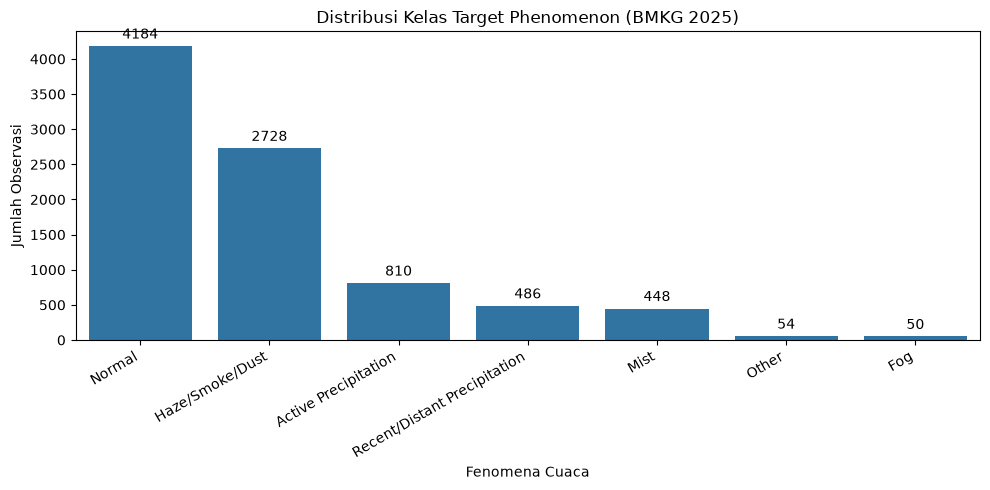

In [42]:
plt.figure(figsize=(10, 5))
order = eda_df['phenomenon'].value_counts().index
ax = sns.countplot(data=eda_df, x='phenomenon', order=order)
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.title('Distribusi Kelas Target Phenomenon (BMKG 2025)')
plt.xlabel('Fenomena Cuaca')
plt.ylabel('Jumlah Observasi')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

**Notes:**

- Dari total 8.760 data observasi, distribusi kelas `phenomenon` menunjukkan ketidakseimbangan (*class imbalance*) yang tajam. Kelas `Normal` mendominasi dengan **4.184 data (47,76%)**, diikuti oleh `Haze/Smoke/Dust` sebanyak **2.728 data (31,14%)**, `Active Precipitation` sebanyak **810 data (9,25%)**, `Recent/Distant Precipitation` sebanyak **486 data (5,55%)**, dan `Mist` sebanyak **448 data (5,11%)**.
- Dua kelas minoritas memiliki jumlah sampel sangat sedikit, yaitu `Other` (kode `ww = 13`) sebanyak **54 data (0,62%)** dan `Fog` sebanyak **50 data (0,57%)**.
- Pemangkasan **4 baris batas waktu** pada tahun 2025—yakni **3 baris pertama** (`2025-01-01 00:00–02:00`) akibat pembentukan fitur lag $t-3$ dan **1 baris terakhir** (`2025-12-31 23:00`) akibat pergeseran label target ke $t+1$—tidak mengubah komposisi proporsi kelas secara signifikan. Namun, rendahnya jumlah sampel pada kelas `Fog` dan `Other` serta kemiripan kondisi atmosfer menjelang terjadinya fenomena menegaskan perlunya penambahan dinamika riwayat waktu ($t$ hingga $t-3$) sebagai prekursor prediksi $t+1$, disertai evaluasi menggunakan metrik yang sensitif terhadap kelas minoritas (*Macro F1-Score* dan *Balanced Accuracy*).

## 2.3 Numeric Feature Distribution

Distribusi setiap variabel numerik dasar ditampilkan dalam bentuk histogram dan ringkasan statistik untuk mengetahui bentuk sebaran data, penumpukan nilai, serta keberadaan nilai ekstrem atau kode khusus. Evaluasi ini menjadi dasar untuk menyaring variabel mana saja yang cukup padat dan kontinu per jam untuk dijadikan fitur kondisi saat ini ($t$), fitur lag ($t-1, t-2, t-3$), serta selisih perubahan ($\Delta$) dalam memprediksi fenomena cuaca 1 jam ke depan ($t+1$), sekaligus mengidentifikasi variabel dengan proporsi `NaN` tinggi yang tidak layak digeser.

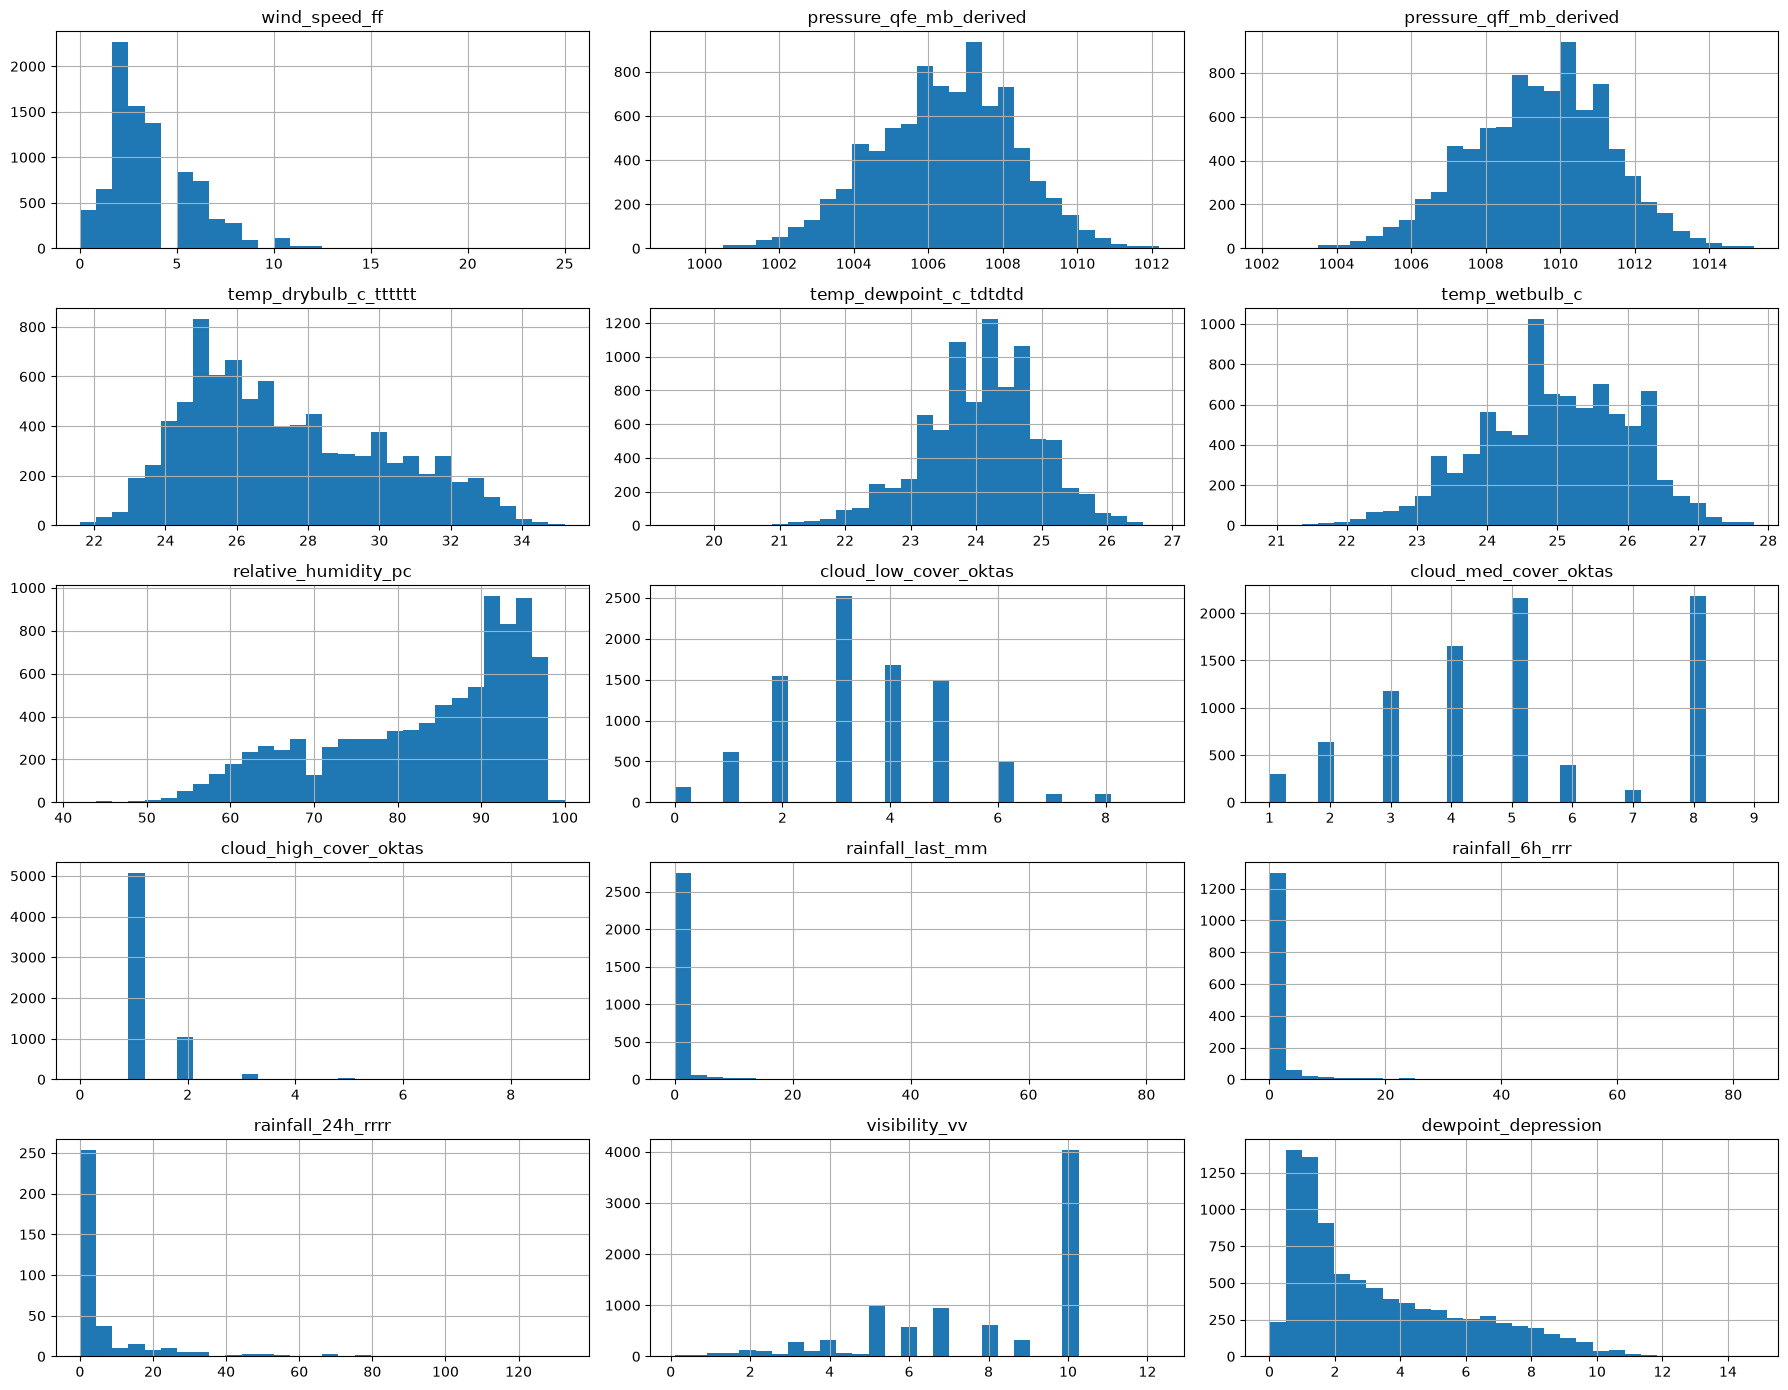

In [43]:
eda_df[num_cols].hist(bins=30, figsize=(18, 14), layout=(5, 3))
plt.tight_layout()
plt.show()

**Ringkasan statistik deskriptif dan distribusi interval (bin)**

In [44]:
def hist_text(s, bins=10):
    s = s.dropna()
    counts, edges = np.histogram(s, bins=bins)
    return ' | '.join(f'{edges[i]:.1f}-{edges[i+1]:.1f}: {counts[i]}' for i in range(len(counts)))

In [45]:
display(eda_df[num_cols].agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T.round(2))

,count,mean,median,std,min,max,skew
wind_speed_ff,8760.0,3.61,3.0,2.29,0.0,25.0,1.20
pressure_qfe_mb_derived,8760.0,1006.43,1006.5,1.86,999.2,1012.2,-0.19
pressure_qff_mb_derived,8760.0,1009.45,1009.5,1.86,1002.2,1015.2,-0.20
temp_drybulb_c_tttttt,8760.0,27.39,26.8,2.73,21.6,35.2,0.49
temp_dewpoint_c_tdtdtd,8760.0,24.08,24.1,0.88,19.4,26.8,-0.31
temp_wetbulb_c,8760.0,24.96,25.0,1.06,20.9,27.8,-0.30
relative_humidity_pc,8760.0,83.23,87.0,11.94,42.0,100.0,-0.73
cloud_low_cover_oktas,8759.0,3.43,3.0,1.53,0.0,9.0,0.26
cloud_med_cover_oktas,8660.0,5.01,5.0,2.08,1.0,9.0,0.15
cloud_high_cover_oktas,6310.0,1.25,1.0,0.62,0.0,9.0,4.93


In [46]:
for col in num_cols:
    print(f'\n{col}\n  {hist_text(eda_df[col])}')


wind_speed_ff
  0.0-2.5: 3340 | 2.5-5.0: 2946 | 5.0-7.5: 1906 | 7.5-10.0: 370 | 10.0-12.5: 171 | 12.5-15.0: 16 | 15.0-17.5: 8 | 17.5-20.0: 2 | 20.0-22.5: 0 | 22.5-25.0: 1

pressure_qfe_mb_derived
  999.2-1000.5: 6 | 1000.5-1001.8: 69 | 1001.8-1003.1: 279 | 1003.1-1004.4: 968 | 1004.4-1005.7: 1550 | 1005.7-1007.0: 2266 | 1007.0-1008.3: 2313 | 1008.3-1009.6: 988 | 1009.6-1010.9: 277 | 1010.9-1012.2: 44

pressure_qff_mb_derived
  1002.2-1003.5: 6 | 1003.5-1004.8: 68 | 1004.8-1006.1: 283 | 1006.1-1007.4: 947 | 1007.4-1008.7: 1554 | 1008.7-1010.0: 2249 | 1010.0-1011.3: 2319 | 1011.3-1012.6: 996 | 1012.6-1013.9: 292 | 1013.9-1015.2: 46

temp_drybulb_c_tttttt
  21.6-23.0: 97 | 23.0-24.3: 858 | 24.3-25.7: 1935 | 25.7-27.0: 1761 | 27.0-28.4: 1250 | 28.4-29.8: 858 | 29.8-31.1: 908 | 31.1-32.5: 664 | 32.5-33.8: 385 | 33.8-35.2: 44

temp_dewpoint_c_tdtdtd
  19.4-20.1: 2 | 20.1-20.9: 7 | 20.9-21.6: 52 | 21.6-22.4: 232 | 22.4-23.1: 740 | 23.1-23.8: 2307 | 23.8-24.6: 2776 | 24.6-25.3: 2085 | 25.3-26

In [47]:
print("=== Distribusi Tutupan Awan (Oktas) ===")
for col in ['cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas']:
    print(f'{col}:', eda_df[col].value_counts(dropna=False).sort_index().to_dict())

=== Distribusi Tutupan Awan (Oktas) ===
cloud_low_cover_oktas: {0.0: 193, 1.0: 612, 2.0: 1540, 3.0: 2526, 4.0: 1681, 5.0: 1498, 6.0: 499, 7.0: 105, 8.0: 102, 9.0: 3, nan: 1}
cloud_med_cover_oktas: {1.0: 304, 2.0: 638, 3.0: 1182, 4.0: 1657, 5.0: 2162, 6.0: 400, 7.0: 129, 8.0: 2185, 9.0: 3, nan: 100}
cloud_high_cover_oktas: {0.0: 2, 1.0: 5079, 2.0: 1036, 3.0: 140, 4.0: 18, 5.0: 25, 8.0: 1, 9.0: 9, nan: 2450}


In [48]:
print("=== Proporsi Kategori Curah Hujan (%) ===")
for col in ['rainfall_last_mm', 'rainfall_6h_rrr', 'rainfall_24h_rrrr']:
    nol_pct = round((eda_df[col] == 0).mean() * 100, 1)
    trace_pct = round((eda_df[col] == 0.05).mean() * 100, 1)
    rain_pct = round((eda_df[col] > 0.05).mean() * 100, 1)
    nan_pct = round(eda_df[col].isna().mean() * 100, 1)
    print(f'{col:<18} -> Nol: {nol_pct:4.1f}% | Trace (0.05): {trace_pct:3.1f}% | Hujan (>0.05): {rain_pct:3.1f}% | NaN: {nan_pct:4.1f}%')

=== Proporsi Kategori Curah Hujan (%) ===
rainfall_last_mm   -> Nol: 26.3% | Trace (0.05): 1.8% | Hujan (>0.05): 5.2% | NaN: 66.7%
rainfall_6h_rrr    -> Nol: 11.7% | Trace (0.05): 1.1% | Hujan (>0.05): 3.9% | NaN: 83.3%
rainfall_24h_rrrr  -> Nol:  1.5% | Trace (0.05): 0.4% | Hujan (>0.05): 2.3% | NaN: 95.8%


**Notes:**

- **Kecepatan Angin (`wind_speed_ff`):** Memiliki sebaran miring ke kanan (*positively skewed*, *skew* = 1,20) dengan rata-rata 3,61 knot dan median 3,0 knot. Sebagian besar observasi terkonsentrasi pada kecepatan angin rendah (0,0–5,0 knot mencakup 6.286 baris / 71,8%), dan semakin jarang pada kecepatan tinggi hingga maksimum 25,0 knot. Karena terisi 100%, variabel ini layak dijadikan fitur saat ini ($t$) dan fitur lag.
- **Tekanan Udara (`pressure_qfe_mb_derived` & `pressure_qff_mb_derived`):** Kedua variabel memiliki distribusi hampir simetris (*skew* = -0,19 dan -0,20) dengan rentang variasi sempit (*std* = 1,86 mb), khas wilayah ekuator. Keduanya menunjukkan pola identik dengan selisih konstan sekitar 3,02 mb. Pemilihan salah satu variabel tekanan saja menjadi krusial sebelum pembuatan lag agar kolom turunan dan $\Delta$ tidak terduplikasi.
- **Suhu Udara, Titik Embun, dan Bola Basah:** Suhu bola kering (`temp_drybulb_c_tttttt`) sedikit miring ke kanan (*skew* = 0,49, rentang 21,6°C–35,2°C) akibat pemanasan siang hari, sedangkan suhu titik embun (24,08 ± 0,88°C) dan suhu bola basah (24,96 ± 1,06°C) terpusat sangat sempit. Ketiganya terisi penuh sehingga siap digunakan untuk melacak tren pendinginan atau pemanasan antarjam menjelang $t+1$.
- **Kelembapan Relatif & *Dew Point Depression*:** Kelembapan relatif (`relative_humidity_pc`) miring ke kiri (*skew* = -0,73) dengan penumpukan pada kondisi lembap (88,4%–100% mencakup 3.972 baris / 45,3%). Sebaliknya, `dewpoint_depression` miring ke kanan (*skew* = 0,98) dan menumpuk pada selisih kecil (0,0°C–1,5°C sebanyak 2.999 baris / 34,2%), mencerminkan atmosfer dekat jenuh pada malam hingga pagi hari.
- **Tutupan Awan (`cloud_*_cover_oktas`):** Awan rendah terpusat pada 2–5 oktas (median 3,0), awan menengah mengelompok di 5 dan 8 oktas (median 5,0), sedangkan awan tinggi didominasi 1 okta (5.079 baris, *skew* = 4,93) dengan 2.450 nilai `NaN`. Selain itu, terdapat kode `9` pada beberapa baris (3 baris di awan rendah/menengah dan 9 baris di awan tinggi) yang berarti langit terhalang (*sky obscured*), bukan tutupan 9 oktas, sehingga wajib ditangani sebelum variabel awan rendah/menengah dipertimbangkan dalam konstruksi fitur.
- **Curah Hujan (`rainfall_last_mm`, `rainfall_6h_rrr`, `rainfall_24h_rrrr`):** Ketiganya sangat miring ke kanan (*skew* masing-masing 9,87, 6,65, dan 3,60) karena didominasi oleh nilai kosong (`NaN` sebesar 66,7%, 83,3%, dan 95,8%). Tingginya kekosongan data ini memastikan variabel curah hujan berkala tidak dapat digeser menjadi fitur lag per jam karena akan menghilangkan mayoritas baris dataset.
- **Jarak Pandang (`visibility_vv`):** Berdistribusi miring ke kiri (*skew* = -0,74, median 8,0 km) dengan konsentrasi tinggi pada batas atas 10,0 km (4.041 baris / 46,1%) serta ekor panjang ke arah nilai rendah (0,1–4,9 km), menjadikannya kandidat utama untuk fitur saat ini ($t$) dan fitur lag guna menangkap sinyal awal penurunan atau pemulihan visibilitas pada 1 jam berikutnya ($t+1$).

## 2.4 Numeric Features by Phenomenon

Perbandingan nilai setiap variabel numerik dasar pada masing-masing kelas fenomena dilakukan menggunakan *boxplot* dan uji statistik Kruskal-Wallis. Selain memetakan karakteristik fisik tiap fenomena, analisis ini mengidentifikasi area tumpang tindih (*overlap*) distribusi antarkelas untuk memahami prekursor atmosfer apa saja yang perlu dilacak melalui fitur kondisi saat ini ($t$), riwayat waktu ($t-1, t-2, t-3$), dan laju perubahannya ($\Delta$) guna memprediksi transisi cuaca pada 1 jam ke depan ($t+1$).

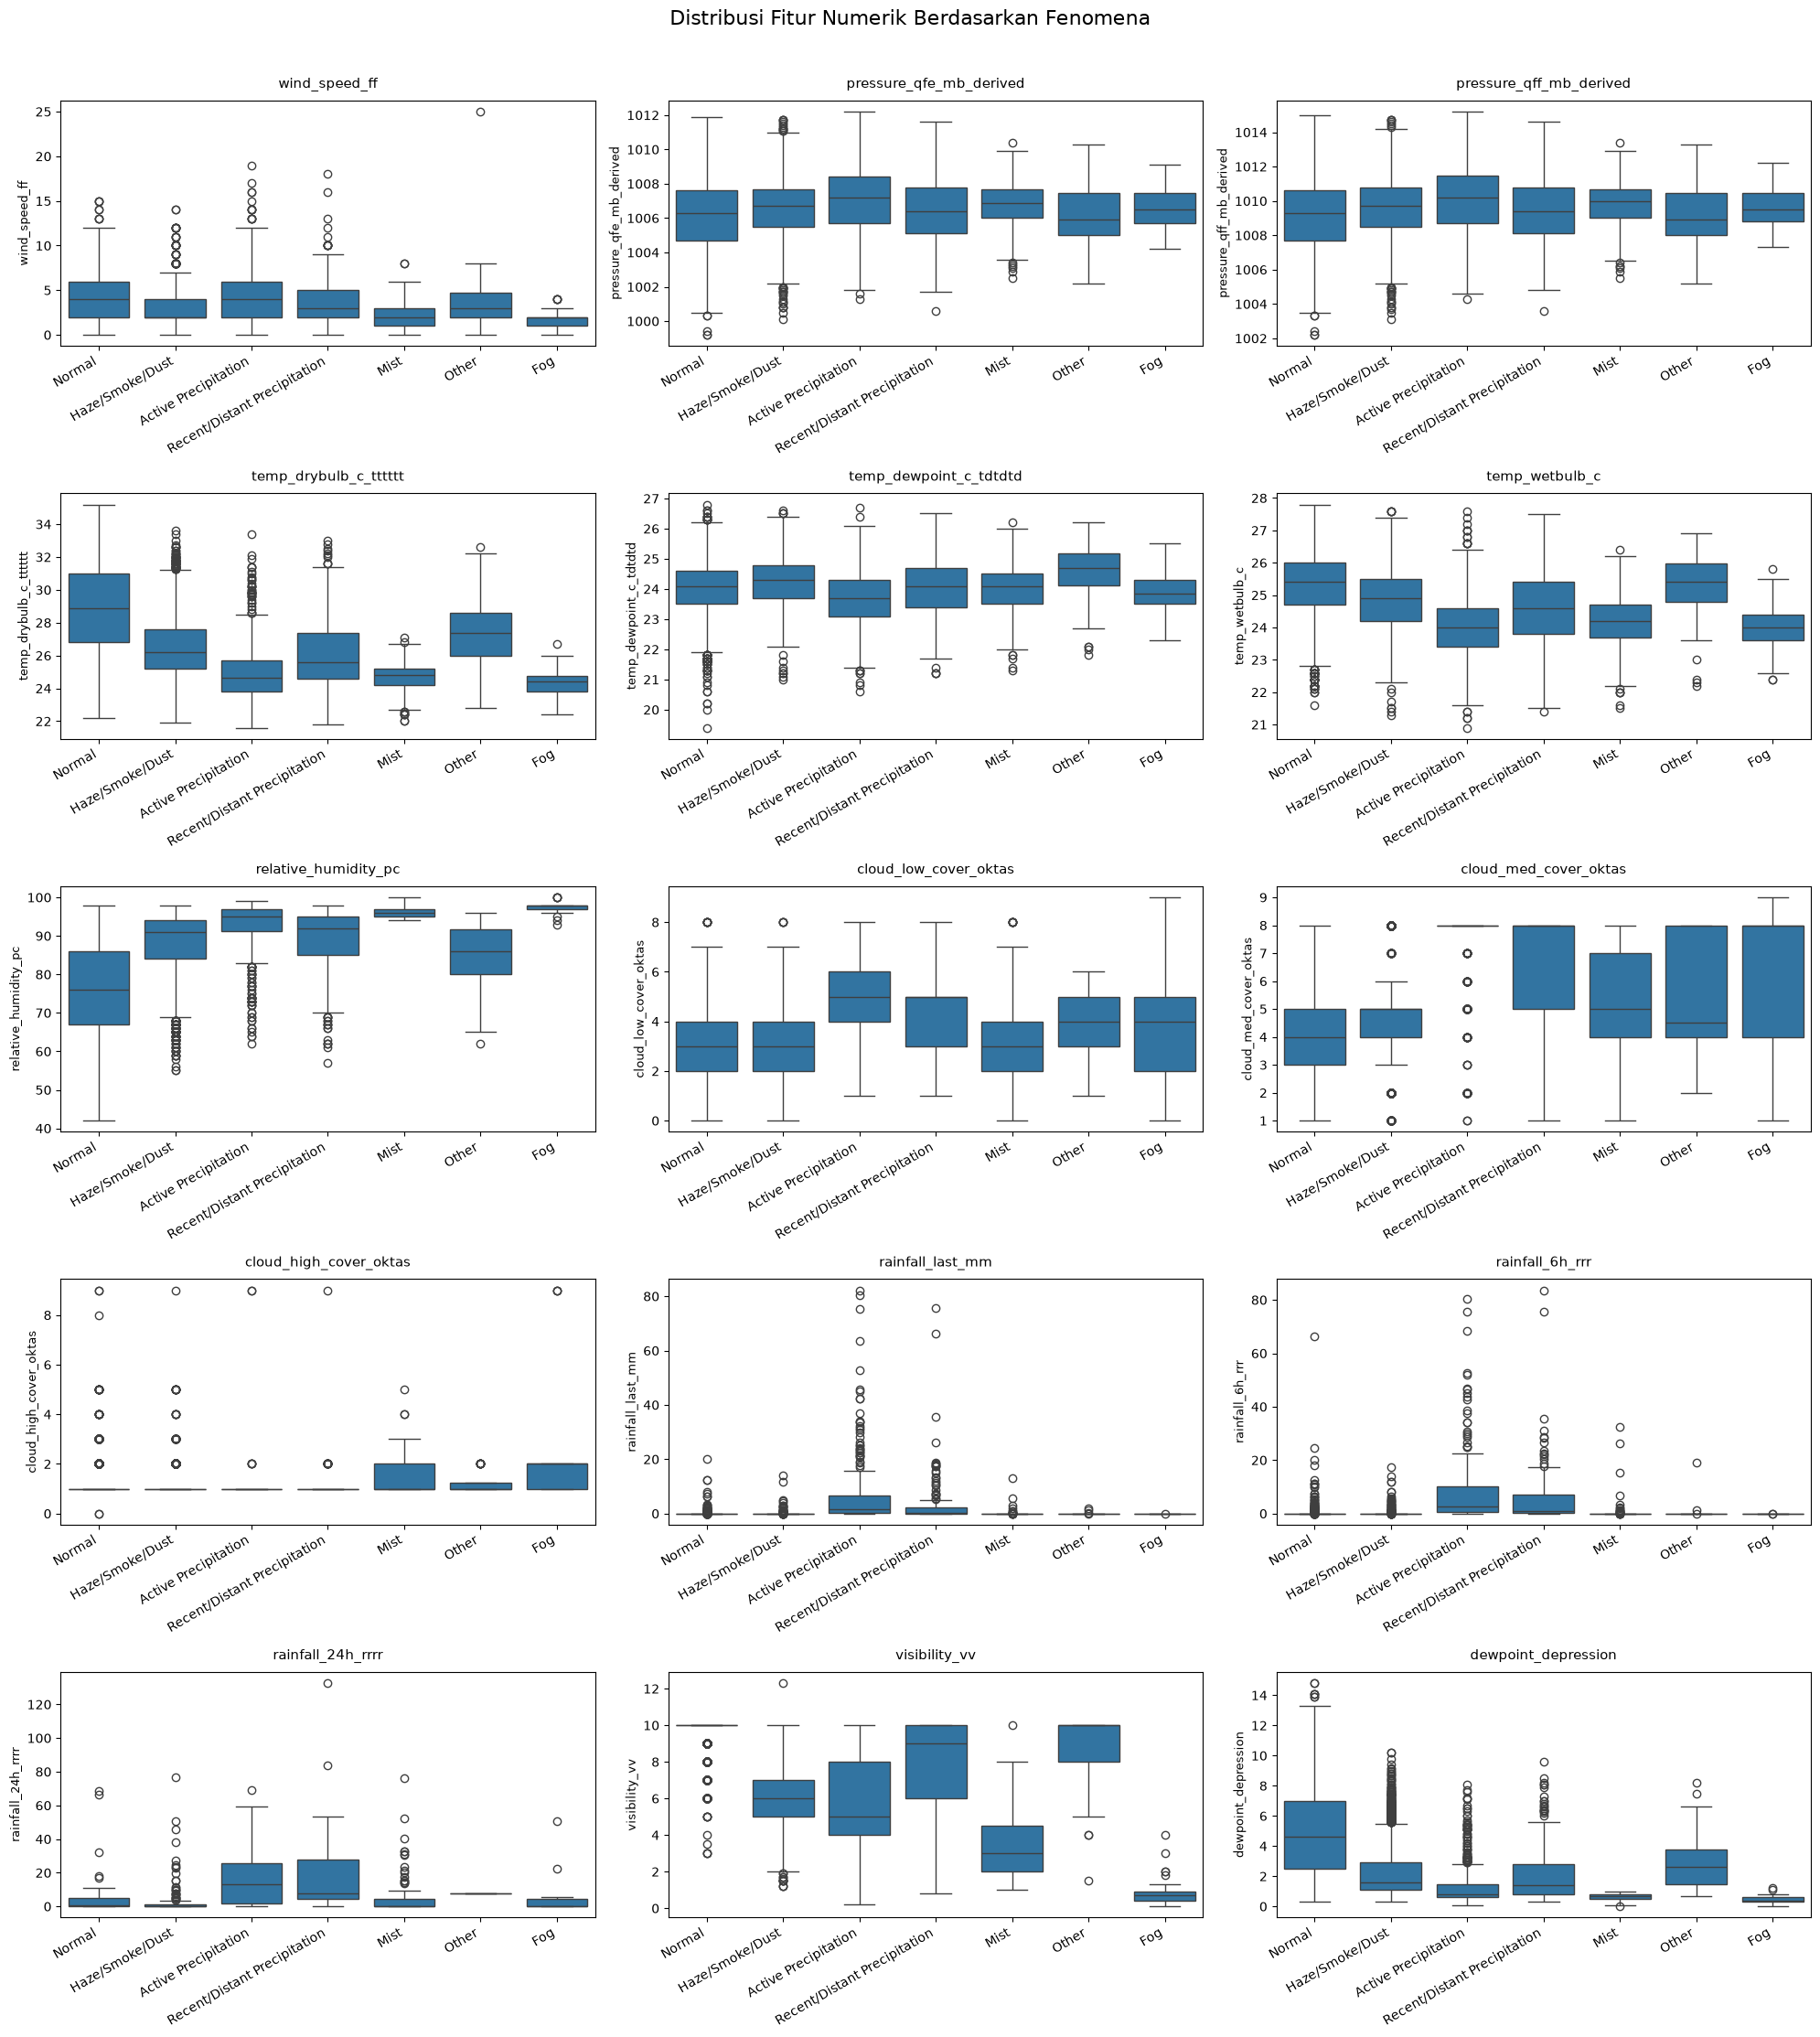

In [49]:
fig, axes = plt.subplots(5, 3, figsize=(20, 22))

for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(
        data=eda_df,
        x='phenomenon',
        y=col,
        order=eda_df['phenomenon'].value_counts().index,
        ax=ax
    )

    ax.set_title(col, fontsize=11, pad=10)
    ax.set_xlabel('')
    ax.set_ylabel(col, fontsize=9)
    
    ax.tick_params(axis='x', labelrotation=30)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

# Menghilangkan subplot yang tidak digunakan
for ax in axes.flatten()[len(num_cols):]:
    ax.remove()

plt.suptitle(
    'Distribusi Fitur Numerik Berdasarkan Fenomena',
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [50]:
results = []

for col in num_cols:
    groups = [
        group[col].dropna().values
        for _, group in eda_df.groupby('phenomenon')
        if len(group[col].dropna()) > 0
    ]

    stat, p = kruskal(*groups)

    results.append({
        'Feature': col,
        'H-Statistic': stat,
        'P-Value': p,
        'Significant': p < 0.05
    })

kruskal_results = pd.DataFrame(results).sort_values(by='H-Statistic', ascending=False).reset_index(drop=True)

display(
    kruskal_results.style.format({
        'H-Statistic': '{:.2f}',
        'P-Value': '{:.3e}'
    })
)

,Feature,H-Statistic,P-Value,Significant
0,visibility_vv,6208.07,0.000e+00,True
1,relative_humidity_pc,3580.24,0.000e+00,True
2,dewpoint_depression,3576.85,0.000e+00,True
3,temp_drybulb_c_tttttt,2835.29,0.000e+00,True
4,rainfall_last_mm,1767.49,0.000e+00,True
5,cloud_low_cover_oktas,1441.36,2.682e-308,True
6,temp_wetbulb_c,1433.07,1.675e-306,True
7,cloud_med_cover_oktas,1227.07,6.610e-262,True
8,wind_speed_ff,1167.01,6.607e-249,True
9,rainfall_6h_rrr,630.83,5.216e-133,True


In [51]:
for col in num_cols:
    t = eda_df.groupby('phenomenon')[col].agg(
        n='count', min='min',
        q1=lambda x: x.quantile(.25), median='median',
        q3=lambda x: x.quantile(.75), max='max'
    ).round(2)
    print(f'\n{col}')
    print(t.to_string())


wind_speed_ff
                                 n  min   q1  median    q3  max
phenomenon                                                     
Active Precipitation           810    0  2.0     4.0  6.00   19
Fog                             50    0  1.0     2.0  2.00    4
Haze/Smoke/Dust               2728    0  2.0     2.0  4.00   14
Mist                           448    0  1.0     2.0  3.00    8
Normal                        4184    0  2.0     4.0  6.00   15
Other                           54    0  2.0     3.0  4.75   25
Recent/Distant Precipitation   486    0  2.0     3.0  5.00   18

pressure_qfe_mb_derived
                                 n     min       q1  median       q3     max
phenomenon                                                                  
Active Precipitation           810  1001.3  1005.70  1007.2  1008.40  1012.2
Fog                             50  1004.2  1005.70  1006.5  1007.45  1009.1
Haze/Smoke/Dust               2728  1000.1  1005.50  1006.7  1007.70  1011.7

**Notes:**

- ***Visibility*, Kelembapan Relatif, dan *Dew Point Depression*:** Kelas `Fog` dan `Mist` memiliki nilai jarak pandang paling rendah (median `0,7 km` dan `3,0 km`) serta *dew point depression* paling sempit (`0,4°C` dan `0,7°C`) dengan kelembapan relatif mendekati jenuh (median `98%` dan `96%`). Sebaliknya, kelas `Normal` memiliki jarak pandang tertinggi (median `10,0 km`), kelembapan terendah (`76%`), dan *dew point depression* terlebar (`4,6°C`). Meski demikian, sebaran interkuartil antara `Fog` dengan `Mist`, maupun antara `Haze/Smoke/Dust` dengan `Mist`, masih menunjukkan irisan nilai sesaat yang berdekatan sehingga memerlukan lintasan perubahan 1–3 jam terakhir untuk membedakan proses kondensasi vs akumulasi partikel kering menjelang jam berikutnya ($t+1$).
- **Suhu Udara dan Suhu Bola Basah:** Kelas `Normal` (`28,90°C`) dan `Other` (`27,40°C`) memiliki median suhu bola kering lebih tinggi dibandingkan `Fog` (`24,40°C`), `Active Precipitation` (`24,65°C`), dan `Mist` (`24,80°C`). Laju penurunan suhu ($\Delta T$) dalam beberapa jam terakhir menjadi sinyal penting untuk mengantisipasi pembentukan kabut radiasi (`Fog`/`Mist`) maupun konveksi pemicu hujan (`Active Precipitation`) pada $t+1$.
- **Tutupan Awan dan Curah Hujan:** Kelas `Active Precipitation` dan `Recent/Distant Precipitation` sama-sama memiliki tutupan awan rendah dan menengah yang tebal (median `5,0` dan `8,0` oktas). Kemiripan tutupan awan antara kedua kelas hujan ini menegaskan perlunya informasi riwayat waktu ($t-1, t-2, t-3$) pada parameter kelembapan, suhu, dan jarak pandang untuk memprediksi apakah hujan akan mulai turun, berlanjut, atau justru mereda pada 1 jam ke depan ($t+1$). Sementara itu, `cloud_high_cover_oktas` tercatat sangat jarang pada `Active Precipitation` (`n = 91` dari 810 observasi) karena terhalang awan hujan tebal.
- **Kecepatan Angin, Tekanan Udara, dan Titik Embun:** Fenomena `Fog`, `Mist`, dan `Haze/Smoke/Dust` cenderung terjadi pada kondisi angin tenang (median `2,0` knot), sedangkan `Normal` dan `Active Precipitation` memiliki median lebih tinggi (`4,0` knot). Variabel tekanan udara (QFE dan QFF) serta suhu titik embun memiliki nilai median yang berdekatan antarkelas, sehingga laju perubahannya ($\Delta P$ dan $\Delta T_d$) lebih informatif dalam menangkap dinamika atmosfer sebelum fenomena terbentuk pada $t+1$.
- **Signifikansi Statistik:** Uji Kruskal-Wallis menunjukkan bahwa seluruh 15 variabel numerik dasar memiliki nilai *p-value* di bawah `0,05` (`Significant = True`), yang mengonfirmasi adanya perbedaan distribusi yang signifikan secara statistik antarkelas fenomena. Variabel `visibility_vv` mencatatkan nilai *H-statistic* tertinggi sebesar `6208,07`, diikuti oleh `relative_humidity_pc` (`3580,24`) dan `dewpoint_depression` (`3576,85`), sedangkan `rainfall_24h_rrrr` memiliki nilai terendah sebesar `87,76`.
- Secara keseluruhan, hasil analisis ini mengonfirmasi bahwa parameter permukaan utama memiliki sinyal fisik yang kuat, namun irisan distribusi antarkelas menegaskan perlunya mengombinasikan kondisi saat ini ($t$) dengan riwayat waktu ($t-1, t-2, t-3$) dan laju perubahannya ($\Delta$) untuk memprediksi fenomena cuaca 1 jam ke depan ($t+1$).

## 2.5 Correlation Between Numeric Feature

Korelasi antarvariabel numerik dasar dihitung menggunakan metode Spearman untuk mengidentifikasi kekuatan hubungan monotonik dan tingkat multikolinearitas antarfitur. Dalam eksperimen prediksi 1 jam ke depan ($t+1$) yang menggunakan fitur saat ini ($t$), fitur lag ($t-1, t-2, t-3$), dan selisih perubahan ($\Delta$), deteksi multikolinearitas pada variabel dasar menjadi sangat penting karena setiap variabel yang dipertahankan akan dikalikan menjadi beberapa kolom turunan. Menyeleksi variabel dasar yang sepenuhnya redundan sebelum pergeseran waktu akan mencegah ledakan dimensi sekaligus menjaga kejernihan interpretasi *feature importance*.

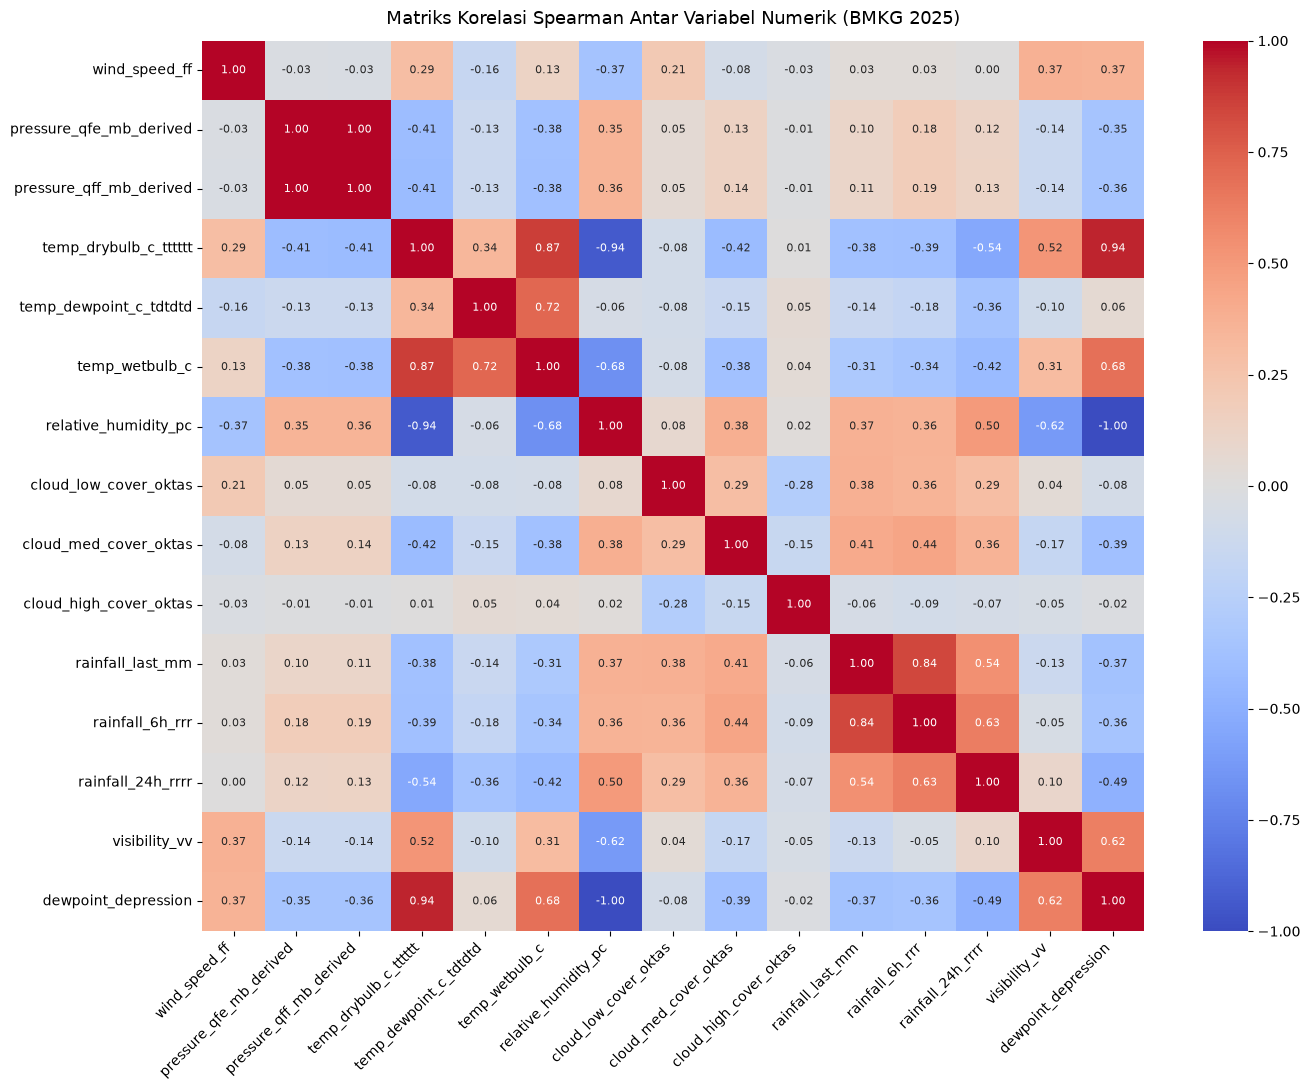

In [52]:
corr_matrix = eda_df[num_cols].corr(method='spearman')

plt.figure(figsize=(14, 11))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={'size': 8}
)
plt.title('Matriks Korelasi Spearman Antar Variabel Numerik (BMKG 2025)', fontsize=13, pad=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [53]:
display(corr_matrix.round(2))

,wind_speed_ff,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_oktas,cloud_med_cover_oktas,cloud_high_cover_oktas,rainfall_last_mm,rainfall_6h_rrr,rainfall_24h_rrrr,visibility_vv,dewpoint_depression
wind_speed_ff,1.00,-0.03,-0.03,0.29,-0.16,0.13,-0.37,0.21,-0.08,-0.03,0.03,0.03,0.00,0.37,0.37
pressure_qfe_mb_derived,-0.03,1.00,1.00,-0.41,-0.13,-0.38,0.35,0.05,0.13,-0.01,0.10,0.18,0.12,-0.14,-0.35
pressure_qff_mb_derived,-0.03,1.00,1.00,-0.41,-0.13,-0.38,0.36,0.05,0.14,-0.01,0.11,0.19,0.13,-0.14,-0.36
temp_drybulb_c_tttttt,0.29,-0.41,-0.41,1.00,0.34,0.87,-0.94,-0.08,-0.42,0.01,-0.38,-0.39,-0.54,0.52,0.94
temp_dewpoint_c_tdtdtd,-0.16,-0.13,-0.13,0.34,1.00,0.72,-0.06,-0.08,-0.15,0.05,-0.14,-0.18,-0.36,-0.10,0.06
temp_wetbulb_c,0.13,-0.38,-0.38,0.87,0.72,1.00,-0.68,-0.08,-0.38,0.04,-0.31,-0.34,-0.42,0.31,0.68
relative_humidity_pc,-0.37,0.35,0.36,-0.94,-0.06,-0.68,1.00,0.08,0.38,0.02,0.37,0.36,0.50,-0.62,-1.00
cloud_low_cover_oktas,0.21,0.05,0.05,-0.08,-0.08,-0.08,0.08,1.00,0.29,-0.28,0.38,0.36,0.29,0.04,-0.08
cloud_med_cover_oktas,-0.08,0.13,0.14,-0.42,-0.15,-0.38,0.38,0.29,1.00,-0.15,0.41,0.44,0.36,-0.17,-0.39
cloud_high_cover_oktas,-0.03,-0.01,-0.01,0.01,0.05,0.04,0.02,-0.28,-0.15,1.00,-0.06,-0.09,-0.07,-0.05,-0.02


**Notes:**

- **Tekanan Udara (QFE dan QFF):** `pressure_qfe_mb_derived` dan `pressure_qff_mb_derived` memiliki korelasi positif sempurna (`1,00`), karena keduanya diturunkan dari pengukuran tekanan yang sama dengan selisih konstan akibat koreksi elevasi stasiun. Oleh karena itu, cukup dipilih salah satu saja sebelum membentuk fitur lag dan kecenderungan tekanan ($\Delta P$) agar tidak terjadi duplikasi penuh.
- **Suhu, Kelembapan Relatif, dan *Dew Point Depression*:** Suhu bola kering (`temp_drybulb_c_tttttt`) berkorelasi positif sangat kuat dengan `dewpoint_depression` (`0,94`) dan suhu bola basah (`0,87`), serta berkorelasi negatif sangat kuat dengan `relative_humidity_pc` (`-0,94`). Selain itu, `relative_humidity_pc` dan `dewpoint_depression` menunjukkan korelasi negatif *rank* sempurna (`-1,00`). Meskipun demikian, pada konteks peramalan jangka pendek ($t+1$), laju perubahan masing-masing parameter tetap dapat memberikan sinyal fisik yang saling melengkapi selama variabel yang benar-benar identik (seperti salah satu variabel tekanan) sudah dipangkas.
- **Kelompok Curah Hujan (`rainfall_*`):** Variabel `rainfall_last_mm` berkorelasi positif sangat kuat dengan `rainfall_6h_rrr` (`0,84`) dan berkorelasi sedang dengan `rainfall_24h_rrrr` (`0,54`), sedangkan `rainfall_6h_rrr` dan `rainfall_24h_rrrr` memiliki korelasi positif kuat (`0,63`). Perhitungan berpasangan ini hanya mengevaluasi baris yang sama-sama terisi (`n = 1.460` untuk 6 jam dan `n = 365` untuk 24 jam).
- **Jarak Pandang (`visibility_vv`):** Memiliki korelasi negatif kuat dengan `relative_humidity_pc` (`-0,62`), korelasi positif kuat dengan `dewpoint_depression` (`0,62`), serta korelasi positif sedang dengan `temp_drybulb_c_tttttt` (`0,52`), menegaskan bahwa perubahan jarak pandang berkaitan erat dengan dinamika kejenuhan uap air di atmosfer.
- **Kelompok Tutupan Awan (`cloud_*_cover_oktas`):** Awan rendah dan awan menengah memiliki korelasi positif lemah (`0,29`), sedangkan awan rendah dan awan tinggi berkorelasi negatif lemah (`-0,28`) karena lapisan awan bawah yang tebal sering menghalangi pengamatan awan tinggi. Awan menengah juga menunjukkan korelasi positif sedang dengan curah hujan (`0,41` terhadap `rainfall_last_mm` dan `0,44` terhadap `rainfall_6h_rrr`).
- Berdasarkan matriks korelasi Spearman, fitur yang sepenuhnya redundan seperti salah satu variabel tekanan (QFE atau QFF) wajib dieliminasi pada tahap *preprocessing* sebelum pembentukan fitur saat ini ($t$), fitur lag ($t-1, t-2, t-3$), dan selisih perubahan ($\Delta$) dilakukan.

## 2.6 Temporal Pattern

Pola temporal fenomena dianalisis berdasarkan jam pengamatan (WIB) dan bulan untuk memetakan siklus kemunculan tiap fenomena cuaca. Pemahaman terhadap ritme transisi diurnal (per jam) ini menjadi landasan penting dalam eksperimen prediksi 1 jam ke depan ($t+1$) berbasis fitur kondisi saat ini ($t$) dan fitur lag ($t-1, t-2, t-3$), karena kecenderungan perubahan atmosfer menuju jam berikutnya ($t+1$) sangat bergantung pada fase pemanasan siang hari maupun pendinginan malam hingga dini hari.

In [54]:
phenom_order = eda_df['phenomenon'].value_counts().index

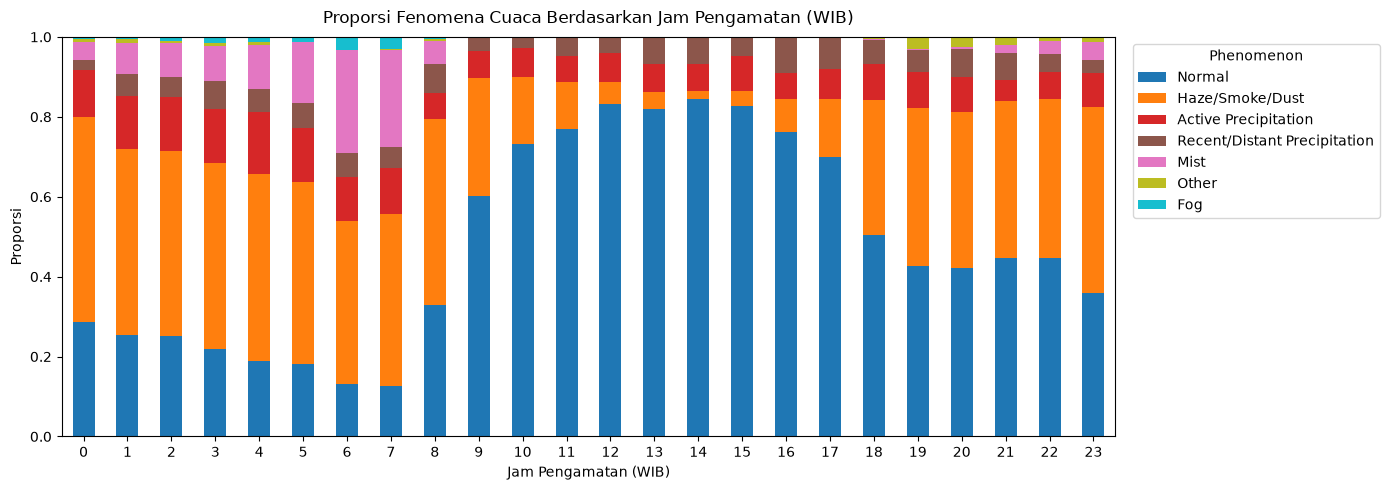

In [55]:
ct_hour = pd.crosstab(eda_df['hour_wib'], eda_df['phenomenon'], normalize='index')[phenom_order]
ax = ct_hour.plot(kind='bar', stacked=True, figsize=(14, 5), colormap='tab10')

plt.title('Proporsi Fenomena Cuaca Berdasarkan Jam Pengamatan (WIB)', fontsize=12, pad=10)
plt.xlabel('Jam Pengamatan (WIB)')
plt.ylabel('Proporsi')
plt.xticks(rotation=0)
plt.legend(title='Phenomenon', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

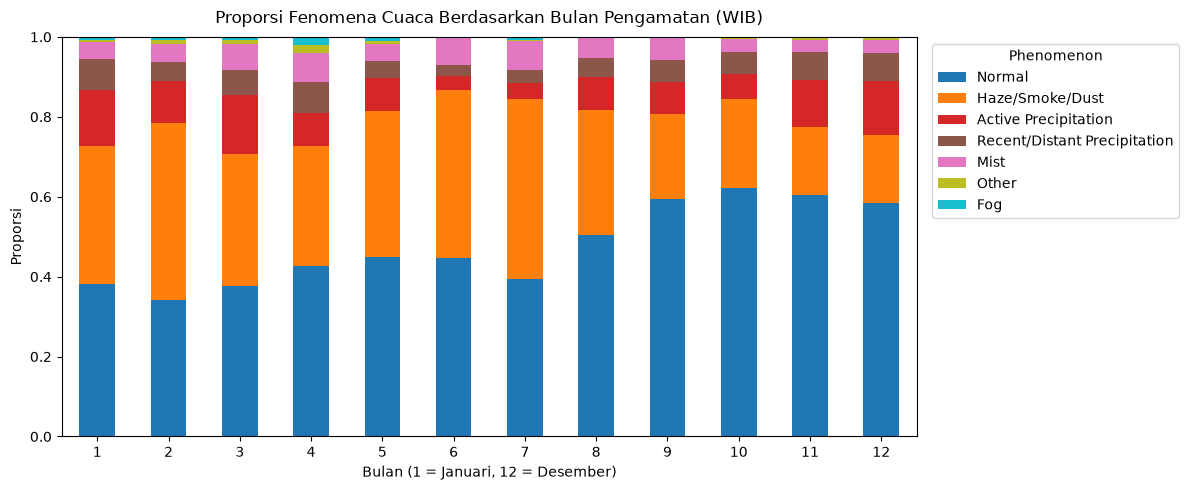

In [56]:
ct_month = pd.crosstab(eda_df['month_wib'], eda_df['phenomenon'], normalize='index')[phenom_order]
ax = ct_month.plot(kind='bar', stacked=True, figsize=(12, 5), colormap='tab10')

plt.title('Proporsi Fenomena Cuaca Berdasarkan Bulan Pengamatan (WIB)', fontsize=12, pad=10)
plt.xlabel('Bulan (1 = Januari, 12 = Desember)')
plt.ylabel('Proporsi')
plt.xticks(rotation=0)
plt.legend(title='Phenomenon', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [57]:
ct_hour_n = pd.crosstab(eda_df['hour_wib'], eda_df['phenomenon'])[phenom_order]
print("=== Proporsi Fenomena per Jam WIB (%) ===")
display((ct_hour_n.div(ct_hour_n.sum(axis=1), axis=0) * 100).round(1))

=== Proporsi Fenomena per Jam WIB (%) ===


phenomenon,Normal,Haze/Smoke/Dust,Active Precipitation,Recent/Distant Precipitation,Mist,Other,Fog
hour_wib,,,,,,,
0,28.8,51.2,11.8,2.5,4.4,0.8,0.5
1,25.5,46.6,13.2,5.5,7.7,1.1,0.5
2,25.2,46.3,13.4,4.9,8.5,0.5,1.1
3,21.9,46.6,13.4,7.1,8.8,0.5,1.6
4,18.9,46.8,15.3,5.8,11.2,0.5,1.4
5,18.1,45.5,13.7,6.3,15.1,0.0,1.4
6,13.2,40.8,11.0,6.0,25.8,0.0,3.3
7,12.6,43.0,11.5,5.2,24.4,0.3,3.0
8,32.9,46.6,6.6,7.1,5.8,0.5,0.5


In [58]:
ct_month_n = pd.crosstab(eda_df['month_wib'], eda_df['phenomenon'])[phenom_order]
print("=== Proporsi Fenomena per Bulan WIB (%) ===")
display((ct_month_n.div(ct_month_n.sum(axis=1), axis=0) * 100).round(1))

=== Proporsi Fenomena per Bulan WIB (%) ===


phenomenon,Normal,Haze/Smoke/Dust,Active Precipitation,Recent/Distant Precipitation,Mist,Other,Fog
month_wib,,,,,,,
1,38.0,34.5,14.2,7.5,4.4,0.4,0.8
2,34.1,44.3,10.4,4.9,4.5,1.0,0.7
3,37.8,32.9,14.8,6.2,6.6,0.9,0.8
4,42.6,30.0,8.3,7.6,7.4,1.9,2.1
5,44.9,36.6,8.2,4.3,4.3,0.7,1.1
6,44.7,42.1,3.5,2.6,6.8,0.1,0.1
7,39.4,45.0,4.0,3.2,7.3,0.3,0.8
8,50.4,31.2,8.3,4.8,5.0,0.1,0.1
9,59.4,21.2,7.9,5.7,5.4,0.3,0.0


In [59]:
print("Jumlah observasi per jam (min - max):", ct_hour_n.sum(axis=1).min(), "-", ct_hour_n.sum(axis=1).max())
print("Jumlah observasi per bulan:\n", ct_month_n.sum(axis=1).to_dict())

Jumlah observasi per jam (min - max): 365 - 365
Jumlah observasi per bulan:
 {1: 744, 2: 672, 3: 744, 4: 720, 5: 744, 6: 720, 7: 744, 8: 744, 9: 720, 10: 744, 11: 720, 12: 744}


**Notes:**

- **Berdasarkan Jam Pengamatan (`hour_wib`):**
  - **`Fog` dan `Mist`:** Terkonsentrasi pada dini hari hingga pagi (`23.00–08.00 WIB`) akibat pendinginan radiasi permukaan, dengan puncak kemunculan pada pukul `06.00–07.00 WIB` (`Mist` mencapai `25,8%` dan `24,4%`; `Fog` mencapai `3,3%` dan `3,0%`), serta tidak pernah muncul pada siang hingga sore hari (`10.00–17.00 WIB`). Fase pendinginan bertahap menjelang pukul `06.00 WIB` inilah yang ditangkap oleh kombinasi fitur saat ini ($t$) dan lag suhu serta *dew point depression* ($t-1, t-2, t-3$) untuk mengantisipasi munculnya `Fog` atau `Mist` pada 1 jam berikutnya ($t+1$).
  - **`Haze/Smoke/Dust`:** Memiliki proporsi tinggi pada malam hingga pagi hari (`19.00–08.00 WIB` sekitar `38,9%–51,2%`, puncaknya pukul `00.00 WIB` sebesar `51,2%`), kemudian menurun tajam saat pemanasan dan pencampuran konvektif siang hari hingga titik terendah pada pukul `14.00 WIB` (`2,2%`).
  - **`Normal`:** Mendominasi pada siang hingga sore hari (`09.00–18.00 WIB`), terutama pada rentang pukul `12.00–15.00 WIB` dengan proporsi `81,9%–84,4%` (puncak pukul `14.00 WIB`).
  - **`Active Precipitation` dan `Recent/Distant Precipitation`:** `Active Precipitation` memiliki proporsi tertinggi pada dini hari (`01.00–05.00 WIB`, puncaknya pukul `04.00 WIB` sebesar `15,3%`) serta sedikit meningkat pada sore hingga awal malam (`15.00–20.00 WIB` sekitar `8,8%–9,0%`). Sementara itu, `Recent/Distant Precipitation` tersebar relatif merata sepanjang hari (`2,5%–8,8%`) dengan puncak pada pukul `16.00 WIB` (`8,8%`). Kemampuan memprediksi transisi pasca-hujan menuju `Recent/Distant Precipitation` pada $t+1$ sangat bergantung pada kondisi saat ini ($t$) dan riwayat 1–3 jam sebelumnya ($t-1, t-2, t-3$) ketika hujan masih berlangsung.
  - **`Other` (`ww = 13`):** Hanya muncul pada malam hingga dini hari (`19.00–04.00 WIB`, terutama pukul `19.00–20.00 WIB` sebesar `3,0%` dan `2,5%`) karena kilat jauh secara visual lebih mudah teramati saat kondisi gelap.
- **Berdasarkan Bulan Pengamatan (`month_wib`):**
  - **`Haze/Smoke/Dust`:** Memiliki proporsi lebih tinggi pada awal hingga pertengahan tahun, khususnya pada Juli (`45,0%`), Februari (`44,3%`), dan Juni (`42,1%`), lalu menurun pada September–Desember (`17,1%–22,4%`).
  - **`Normal`:** Mendominasi pada paruh akhir tahun sejak Agustus hingga Desember (`50,4%–62,1%`), dengan puncak pada Oktober (`62,1%`).
  - **`Active Precipitation` dan `Recent/Distant Precipitation`:** Keduanya memiliki proporsi tertinggi pada bulan-bulan basah seperti Januari (`14,2%` dan `7,5%`), Maret (`14,8%` dan `6,2%`), November (`11,7%` dan `6,9%`), dan Desember (`13,3%` dan `7,1%`), lalu turun ke titik terendah pada Juni (`3,5%` dan `2,6%`) dan Juli (`4,0%` dan `3,2%`).
  - **`Mist` dan `Fog`:** `Mist` relatif stabil sepanjang tahun (`3,2%–7,4%`, tertinggi pada April `7,4%` dan Juli `7,3%`), sedangkan `Fog` paling sering muncul pada April (`2,1%`) dan hampir tidak ditemukan pada Agustus–Desember (`0,0%–0,1%`).
- Secara keseluruhan, pola diurnal (per jam) menunjukkan ritme transisi atmosfer yang sangat terstruktur. Mengombinasikan fitur waktu pada saat pengamatan (seperti jam dan bulan pada waktu $t$) dengan parameter fisik saat ini dan riwayatnya ($t, t-1, t-2, t-3$) membantu model membedakan apakah kondisi atmosfer sedang bergerak menuju kejenuhan (pendinginan malam–pagi) atau pemulihan (pemanasan siang hari) pada 1 jam ke depan ($t+1$).

## 2.7 Label Origin and Data Leakage Check

Pemeriksaan dilakukan untuk memverifikasi keterkaitan langsung antara pembentukan label target `phenomenon` dengan variabel penyandian cuaca (`present_weather_ww`, `weather_indicator_ix`, `past_weather_w1`, dan `past_weather_w2`). Analisis ini menetapkan batasan ketat mengenai variabel mana saja yang wajib dikeluarkan dari daftar fitur prediktor—baik pada waktu pengamatan saat ini ($t$) maupun saat menyusun fitur lag ($t-1, t-2, t-3$)—agar prediksi fenomena cuaca 1 jam ke depan ($t+1$) murni dipelajari dari dinamika parameter meteorologi fisik tanpa ketergantungan pada sandi cuaca kategorikal maupun kebocoran informasi (*data leakage*).

In [60]:
print("=== Crosstab phenomenon vs weather_indicator_ix ===")
display(pd.crosstab(eda_df['phenomenon'], eda_df['weather_indicator_ix'], margins=True))

=== Crosstab phenomenon vs weather_indicator_ix ===


weather_indicator_ix,1,2,All
phenomenon,,,
Active Precipitation,810,0,810
Fog,50,0,50
Haze/Smoke/Dust,2728,0,2728
Mist,448,0,448
Normal,201,3983,4184
Other,54,0,54
Recent/Distant Precipitation,486,0,486
All,4777,3983,8760


In [61]:
print("=== Jumlah kode unik present_weather_ww per kelas phenomenon ===")
ww_mapping_check = eda_df.groupby('phenomenon')['present_weather_ww'].agg(
    jumlah_data='count',
    kode_ww_unik=lambda x: sorted(x.unique().tolist())
)
display(ww_mapping_check)

=== Jumlah kode unik present_weather_ww per kelas phenomenon ===


,jumlah_data,kode_ww_unik
phenomenon,,
Active Precipitation,810,"[50, 51, 60, 61, 62, 63, 64, 65, 91, 95, 97]"
Fog,50,"[28, 40, 41, 42, 44, 45, 46, 47]"
Haze/Smoke/Dust,2728,"[5, 6]"
Mist,448,[10]
Normal,4184,"[0, 1, 2, 3]"
Other,54,[13]
Recent/Distant Precipitation,486,"[15, 16, 17, 21, 29]"


**Notes:**

- **`present_weather_ww`:** Seluruh 32 kode sandi unik terpetakan secara deterministik (`100%` tanpa tumpang tindih kode antarkelas) ke dalam 7 kelas target `phenomenon`. Pada eksperimen prediksi 1 jam ke depan ($t+1$), pemetaan kode ini diterapkan pada observasi **1 jam berikutnya ($t+1$)** untuk membentuk label target.
- **`weather_indicator_ix`:** Seluruh observasi pada enam kelas fenomena non-normal (`4.576` baris) seluruhnya memiliki nilai `weather_indicator_ix = 1`, sedangkan nilai `weather_indicator_ix = 2` (`3.983` baris) hanya muncul pada kelas `Normal` (bersama `201` baris dengan `ix = 1` yang dipicu oleh cuaca lampau).
- **Keputusan *Preprocessing* & Batasan Fitur Prediktor:** Karena `present_weather_ww` merupakan sumber langsung pembentukan label target ($t+1$) dan `weather_indicator_ix`, `past_weather_w1`, serta `past_weather_w2` merupakan ringkasan sandi cuaca sinoptik, keempat variabel tersebut wajib dihapus dari himpunan fitur prediktor (baik pada waktu $t$ maupun sebagai fitur lag $t-1, t-2, t-3$). Dengan demikian, model tidak sekadar menyalin status sandi cuaca jam berjalan (*autoregressive persistence*), melainkan benar-benar memprediksi fenomena cuaca 1 jam ke depan ($t+1$) secara objektif berdasarkan prekursor dan dinamika pengukuran fisik atmosfer.

# 3. Preprocessing

Tahap ini melakukan pembersihan dan transformasi data dasar berdasarkan seluruh temuan dari tahap *Inspection* dan *EDA* sebelumnya, agar dataset siap digunakan untuk pembentukan fitur kondisi saat ini ($t$), fitur riwayat waktu (*lag features* $t-1, t-2, t-3$), selisih perubahan ($\Delta$), serta pergeseran label target ke masa depan ($t+1$) pada tahap *Feature Engineering*. Seluruh proses dilakukan pada salinan data (`clean_df`), sehingga `data_df` asli tetap terjaga sebagai referensi mentah, serta mempertahankan seluruh `8.760` baris observasi secara utuh agar kontinuitas deret waktu per jam tidak terputus.

## 3.1 Create Working Copy

Salinan dataset dibuat untuk diproses sehingga data mentah (`data_df`) tetap tersimpan utuh sebagai referensi.

In [62]:
clean_df = data_df.copy()

In [63]:
print(f"Shape clean_df: {clean_df.shape}")

Shape clean_df: (8760, 82)


## 3.2 Fix Data Structure

Perbaikan tipe data dan pengurutan kronologis dilakukan pada dataset kerja, meliputi konversi `data_timestamp` ke tipe `datetime64` (format `%d/%m/%Y %H:%M`) yang diurutkan secara menaik (*ascending*), serta konversi kolom tutupan awan utama ke tipe numerik dengan mengubah simbol `'/'` menjadi `NaN`. Pengurutan kronologis secara eksplisit ini menjadi fondasi utama agar operasi pergeseran waktu—baik mundur untuk fitur lag ($t-1, t-2, t-3$) maupun maju untuk label target ($t+1$)—pada tahap *Feature Engineering* mengacu pada jam observasi yang presisi.

**Konversi data_timestamp ke datetime dengan format eksplisit dan urutkan secara kronologis**

In [64]:
clean_df['data_timestamp'] = pd.to_datetime(
    clean_df['data_timestamp'],
    format='%d/%m/%Y %H:%M',
    errors='coerce'
)
clean_df = clean_df.sort_values('data_timestamp').reset_index(drop=True)

In [65]:
print(f"Tipe data data_timestamp : {clean_df['data_timestamp'].dtypes}")
print(f"Jumlah NaT setelah parse : {clean_df['data_timestamp'].isna().sum()}\n")

Tipe data data_timestamp : datetime64[us]
Jumlah NaT setelah parse : 0



**Konversi kolom tutupan awan utama dari string ('/') ke numerik**

In [66]:
cloud_cover_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas']
for col in cloud_cover_cols:
    clean_df[col] = pd.to_numeric(clean_df[col].replace('/', np.nan), errors='coerce')

In [67]:
print(clean_df[cloud_cover_cols].dtypes)

cloud_low_cover_oktas     float64
cloud_med_cover_oktas     float64
cloud_high_cover_oktas    float64
dtype: object


## 3.3 Current Phenomenon Label

Kolom `phenomenon` dibentuk dari variabel `present_weather_ww` menggunakan fungsi pemetaan 7 kelas fenomena cuaca yang telah didefinisikan pada tahap *EDA*. Kolom ini merepresentasikan kondisi cuaca aktual pada jam pengamatan ($t$) dan disimpan sebelum kolom sandi cuaca mentah dihapus pada sub-bab berikutnya. Pada tahap *Feature Engineering* dan *Label Definition*, kolom ini menjadi dasar untuk membentuk label target prediksi 1 jam ke depan ($t+1$).

In [68]:
clean_df['phenomenon'] = clean_df['present_weather_ww'].apply(map_phenomenon)

In [69]:
print(f"Jumlah NaN pada phenomenon : {clean_df['phenomenon'].isna().sum()}")
print(f"Shape clean_df sekarang    : {clean_df.shape}")

Jumlah NaN pada phenomenon : 0
Shape clean_df sekarang    : (8760, 83)


In [70]:
display(clean_df['phenomenon'].value_counts().to_frame('Count'))

,Count
phenomenon,
Normal,4184
Haze/Smoke/Dust,2728
Active Precipitation,810
Recent/Distant Precipitation,486
Mist,448
Other,54
Fog,50


**Pemetaan eksplisit 7 kelas target (0 - 6)**

In [71]:
label_map = {
    'Active Precipitation': 0,
    'Fog': 1,
    'Haze/Smoke/Dust': 2,
    'Mist': 3,
    'Normal': 4,
    'Other': 5,
    'Recent/Distant Precipitation': 6
}

**Pemetaan balik (angka -> nama kelas) untuk keperluan evaluasi prediksi**

In [72]:
inv_label_map = {v: k for k, v in label_map.items()}

In [73]:
assert set(clean_df['phenomenon'].unique()) <= set(label_map), "Ada kelas yang belum ada di label_map!"

## 3.4 Drop Unused Columns

Setelah kolom `phenomenon` terbentuk, variabel-variabel yang tidak digunakan sebagai dasar fitur maupun target dihapus. Dari total `83` kolom pada `clean_df`, dipertahankan `14` kolom utama (*timestamp* pengamatan, `12` parameter cuaca dasar per jam, dan `1` kolom `phenomenon`) dan dihapus `69` kolom lainnya dengan pertimbangan berikut:
- **Potensi *Data Leakage*:** `present_weather_ww`, `weather_indicator_ix`, `past_weather_w1`, dan `past_weather_w2` dihapus karena berkaitan langsung dengan penyandian sandi cuaca sinoptik, sekaligus memastikan konstruksi fitur prediktor ($t$ maupun *lag* $t-1, t-2, t-3$) untuk memprediksi fenomena 1 jam ke depan ($t+1$) murni berasal dari pengukuran fisik atmosfer.
- **Multikolinearitas Sempurna:** `pressure_qfe_mb_derived` dihapus karena berkorelasi `1,00` dengan `pressure_qff_mb_derived`, sehingga mencegah duplikasi kolom lag tekanan dan kecenderungan tekanan ($\Delta P$) pada tahap *Feature Engineering*.
- **Tingkat Kekosongan Tinggi & Ketidaksesuaian Resolusi Lag Per Jam:** `rainfall_6h_rrr` (`83,3% NaN`), `rainfall_24h_rrrr` (`95,8% NaN`), `pressure_3h_diff_mb_ppp` (`66,7% NaN`), suhu ekstrem harian (`txtxtx`/`tntntn`, `95,8% NaN`), serta rincian lapisan awan tambahan (`*_2`, `*_3`, `cloud_layer_*`, tinggi/jenis awan) dihapus karena hanya dicatat pada jam sinoptik tertentu atau memiliki kekosongan tinggi sehingga tidak kompatibel dengan grid pergeseran waktu per 1 jam ($t-1, t-2, t-3$). Dinamika perubahan antarjam (seperti selisih tekanan 3 jam $\Delta P_{3\text{h}}$) nantinya akan dihitung langsung secara kontinu dari data observasi per jam.
- **Kolom Kosong Total & Metadata Sistem:** `9` kolom yang `100% NaN` (`pressure_temp_c`, `cloud_layer_4_*`, dll.), indikator pelaporan (`wind_indicator_iw`, `rainfall_indicator_ir`), serta metadata sistem (`station_name`, `created_at`, `updated_at`, `qc_flag`, `qc_histories`) dihapus karena tidak relevan sebagai fitur prediksi.

In [74]:
keep_cols = [
    'data_timestamp',
    'wind_dir_deg_dd',
    'wind_speed_ff',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'temp_wetbulb_c',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'cloud_high_cover_oktas',
    'rainfall_last_mm',
    'visibility_vv',
    'phenomenon'
]

In [75]:
drop_cols = [col for col in clean_df.columns if col not in keep_cols]
clean_df.drop(columns=drop_cols, inplace=True)

In [76]:
print(f"Jumlah kolom dihapus    : {len(drop_cols)}")
print(f"Shape clean_df sekarang : {clean_df.shape}")
print(f"Daftar kolom tersisa    :\n{list(clean_df.columns)}")

Jumlah kolom dihapus    : 69
Shape clean_df sekarang : (8760, 14)
Daftar kolom tersisa    :
['data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff', 'visibility_vv', 'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c', 'relative_humidity_pc', 'rainfall_last_mm', 'cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas', 'phenomenon']


**Notes:**

- Dengan metode pemilihan `keep_cols`, penyaringan variabel dasar berjalan ringkas tanpa perlu menuliskan puluhan nama kolom yang dihapus secara manual.
- Dataset `clean_df` kini menyisakan `8.760` baris dan `14` kolom yang terfokus pada parameter permukaan utama per jam serta rekaman `phenomenon`, siap masuk ke tahap pembersihan nilai khusus dan penanganan *missing value* sebelum diperluas menjadi fitur kondisi saat ini ($t$), fitur lag ($t-1, t-2, t-3$), dan target masa depan ($t+1$).

## 3.5 Check Outlier Candidates and Special Codes

Pemeriksaan dilakukan terhadap nilai-nilai ekstrem maupun kode sandi khusus meteorologi yang teridentifikasi pada tahap *Inspection* dan *EDA* (kecepatan angin ekstrem, jarak pandang di atas `10 km`, kode curah hujan *trace* `8888.0`, kode tutupan awan `9`, serta kode arah angin). Dalam eksperimen prediksi 1 jam ke depan ($t+1$) berbasis fitur kondisi saat ini ($t$), fitur riwayat waktu (*lag features* $t-1, t-2, t-3$), dan selisih perubahan antarjam ($\Delta$), membedakan variasi fisik yang valid dari artefak penyandian menjadi sangat krusial agar satu nilai sandi khusus tidak memicu lonjakan nilai selisih ($\Delta$) yang keliru pada 3 jam berikutnya.

**Cek kecepatan angin ekstrem (wind_speed_ff >= 20 knot)**

In [77]:
display(clean_df.loc[clean_df['wind_speed_ff'] >= 20, ['data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff', 'visibility_vv', 'phenomenon']])

,data_timestamp,wind_dir_deg_dd,wind_speed_ff,visibility_vv,phenomenon
3445,2025-05-24 13:00:00,270,25,10.0,Other


**Cek visibility di atas batas standar sinoptik (> 10 km)**

In [78]:
display(clean_df.loc[clean_df['visibility_vv'] > 10, ['data_timestamp', 'visibility_vv', 'relative_humidity_pc', 'phenomenon']])

,data_timestamp,visibility_vv,relative_humidity_pc,phenomenon
6408,2025-09-25,12.3,94,Haze/Smoke/Dust


**Cek kode khusus curah hujan 8888.0 (Trace / TTU) dan hujan lebat (> 50 mm)**

In [79]:
print("Jumlah baris rainfall_last_mm == 8888.0:", (clean_df['rainfall_last_mm'] == 8888.0).sum())

Jumlah baris rainfall_last_mm == 8888.0: 158


In [80]:
display(clean_df.loc[clean_df['rainfall_last_mm'] == 8888.0, ['data_timestamp', 'rainfall_last_mm', 'phenomenon']].head(5))

,data_timestamp,rainfall_last_mm,phenomenon
24,2025-01-02 00:00:00,8888.0,Active Precipitation
54,2025-01-03 06:00:00,8888.0,Active Precipitation
246,2025-01-11 06:00:00,8888.0,Recent/Distant Precipitation
279,2025-01-12 15:00:00,8888.0,Haze/Smoke/Dust
282,2025-01-12 18:00:00,8888.0,Active Precipitation


In [81]:
display(clean_df.loc[(clean_df['rainfall_last_mm'] > 50) & (clean_df['rainfall_last_mm'] != 8888.0), ['data_timestamp', 'rainfall_last_mm', 'visibility_vv', 'phenomenon']])

,data_timestamp,rainfall_last_mm,visibility_vv,phenomenon
402,2025-01-17 18:00:00,80.5,2.3,Active Precipitation
1272,2025-02-23 00:00:00,52.8,5.0,Active Precipitation
2115,2025-03-30 03:00:00,82.2,5.0,Active Precipitation
3300,2025-05-18 12:00:00,75.6,7.0,Recent/Distant Precipitation
5148,2025-08-03 12:00:00,75.5,7.0,Active Precipitation
5997,2025-09-07 21:00:00,66.2,10.0,Recent/Distant Precipitation
8088,2025-12-04 00:00:00,63.5,6.0,Active Precipitation


**Cek kode khusus tutupan awan == 9 (Sky Obscured)**

In [82]:
cloud_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas']

In [83]:
for col in cloud_cols:
    cnt_9 = (clean_df[col] == 9).sum()
    print(f"- {col:<24}: {cnt_9} baris bernilai 9")

- cloud_low_cover_oktas   : 3 baris bernilai 9
- cloud_med_cover_oktas   : 3 baris bernilai 9
- cloud_high_cover_oktas  : 9 baris bernilai 9


In [84]:
display(clean_df.loc[(clean_df[cloud_cols] == 9).any(axis=1), ['data_timestamp'] + cloud_cols + ['visibility_vv', 'phenomenon']])

,data_timestamp,cloud_low_cover_oktas,cloud_med_cover_oktas,cloud_high_cover_oktas,visibility_vv,phenomenon
32,2025-01-02 08:00:00,4.0,8.0,9.0,10.0,Normal
1855,2025-03-19 07:00:00,5.0,8.0,9.0,7.0,Active Precipitation
1856,2025-03-19 08:00:00,5.0,8.0,9.0,7.0,Active Precipitation
2876,2025-04-30 20:00:00,9.0,9.0,9.0,0.2,Fog
2877,2025-04-30 21:00:00,9.0,9.0,9.0,0.2,Fog
2878,2025-04-30 22:00:00,9.0,9.0,9.0,0.2,Fog
6241,2025-09-18 01:00:00,4.0,8.0,9.0,7.0,Haze/Smoke/Dust
6947,2025-10-17 11:00:00,3.0,8.0,9.0,9.0,Recent/Distant Precipitation
7502,2025-11-09 14:00:00,2.0,5.0,9.0,10.0,Normal


**Cek nilai khusus/ekstrem arah angin (wind_dir_deg_dd == 0 atau > 360)**

In [85]:
print("Min - Max wind_dir_deg_dd:", clean_df['wind_dir_deg_dd'].min(), "-", clean_df['wind_dir_deg_dd'].max())
print("Jumlah wind_dir_deg_dd == 0   :", (clean_df['wind_dir_deg_dd'] == 0).sum())
print("Jumlah wind_dir_deg_dd > 360  :", (clean_df['wind_dir_deg_dd'] > 360).sum())

Min - Max wind_dir_deg_dd: 0 - 360
Jumlah wind_dir_deg_dd == 0   : 419
Jumlah wind_dir_deg_dd > 360  : 0


In [86]:
if (clean_df['wind_dir_deg_dd'] > 360).sum() > 0:
    display(clean_df.loc[clean_df['wind_dir_deg_dd'] > 360, ['data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff', 'phenomenon']].head(5))

**Notes:**

- **Kecepatan Angin Ekstrem (`wind_speed_ff = 25` knot):** Ditemukan `1` observasi pada `2025-05-24 13:00:00 UTC` dengan kelas `Other` (kilat teramati). Nilai ini merupakan hembusan angin kencang yang wajar secara fisik saat aktivitas konvektif di sekitar stasiun, sehingga dipertahankan sebagai sinyal dinamika atmosfer yang valid bagi fitur saat ini ($t$) dan fitur lag.
- **Jarak Pandang di Atas Batas Standar (`visibility_vv = 12,3` km):** Ditemukan `1` observasi pada `2025-09-25 00:00:00 UTC` (`07.00 WIB`) dengan kelembapan `94%` dan fenomena `Haze/Smoke/Dust`. Karena pelaporan jarak pandang sinoptik standar dibatasi hingga maksimum `10,0 km`, nilai `12,3 km` merupakan anomali pencatatan yang wajib disesuaikan ke `10,0 km` sebelum pembentukan fitur lag—jika dibiarkan, nilai tersebut akan terbawa ke baris $t+1$ s.d. $t+3$ dan menciptakan ilusi penurunan jarak pandang sebesar `-2,3 km` pada jam berikutnya.
- **Kode Sandi *Trace* (`8888.0`) & Hujan Lebat (`> 50` mm):** Terdapat `158` baris bernilai `8888.0` pada `rainfall_last_mm` yang merupakan sandi baku BMKG untuk hujan tidak terukur (*Trace* / $< 0,1\text{ mm}$), sehingga dikonversi menjadi `0,05 mm` sebagai bagian dari higienitas data sebelum evaluasi kelengkapan kolom pada tahap berikutnya. Sementara itu, `7` observasi hujan lebat (`52,8–82,2 mm`) seluruhnya konsisten dengan kelas `Active Precipitation` dan `Recent/Distant Precipitation`, sehingga dipertahankan.
- **Kode Sandi Langit Terhalang (`cloud_*_cover_oktas = 9`):** Ditemukan `3` baris pada awan rendah dan menengah (seluruhnya saat kejadian `Fog` tebal dengan `visibility_vv = 0,2 km`) serta `9` baris pada awan tinggi. Dalam sandi WMO, skala tutupan awan adalah `0–8` oktas, sedangkan angka `9` berarti langit terhalang (*sky obscured*). Kode `9` wajib diubah menjadi `NaN` agar diimputasi secara wajar pada Sub-bab 3.7 dan tidak terbaca sebagai lonjakan tutupan awan menjadi `9` oktas dalam fitur saat ini ($t$) maupun fitur lag.
- **Arah Angin (`wind_dir_deg_dd`):** Seluruh nilai berada dalam rentang valid `0°–360°` (`419` baris bernilai `0°` sebagai kondisi angin tenang/*calm*, tanpa kode variabel `990`). Karena sifatnya yang siklikal (sudut `350°` dan `10°` berjarak `20°`, bukan `340°`), variabel ini akan ditransformasikan menjadi komponen vektor ($u, v$) pada tahap *Feature Engineering* sebelum digeser menjadi fitur lag.

## 3.6 Handle Special Codes and Anomalies

Berdasarkan hasil pemeriksaan pada Sub-bab 3.5, dilakukan penyesuaian nilai sandi khusus dan anomali pencatatan pada `clean_df` sebelum tahap imputasi dan pembentukan fitur riwayat waktu:
1. Mengonversi kode curah hujan *trace* `8888.0` pada `rainfall_last_mm` menjadi `0,05 mm`.
2. Mengonversi kode tutupan awan `9` (*sky obscured*) pada kolom tutupan awan menjadi `NaN` agar dapat diimputasi secara kontinu pada tahap berikutnya.
3. Membatasi nilai anomali `visibility_vv > 10,0 km` (`12,3 km`) ke batas atas pelaporan sinoptik standar sebesar `10,0 km` guna mencegah artefak selisih jarak pandang ($\Delta \text{Visibility}$) pada fitur lag.

**Konversi kode trace 8888.0 -> 0.05 mm pada curah hujan**

In [87]:
clean_df['rainfall_last_mm'] = clean_df['rainfall_last_mm'].replace(8888.0, 0.05)

In [88]:
print("Sisa rainfall_last_mm == 8888.0 :", (clean_df['rainfall_last_mm'] == 8888.0).sum())
print("Max rainfall_last_mm sekarang    :", clean_df['rainfall_last_mm'].max())

Sisa rainfall_last_mm == 8888.0 : 0
Max rainfall_last_mm sekarang    : 82.2


**Konversi kode sky obscured (9) -> NaN pada kolom tutupan awan**

In [89]:
for col in cloud_cols:
    clean_df[col] = clean_df[col].replace(9.0, np.nan)

In [90]:
print("Sisa kode 9 pada kolom awan      :", (clean_df[cloud_cols] == 9.0).sum().to_dict())

Sisa kode 9 pada kolom awan      : {'cloud_low_cover_oktas': 0, 'cloud_med_cover_oktas': 0, 'cloud_high_cover_oktas': 0}


**Sesuaikan anomali visibility > 10.0 km ke batas atas standar 10.0 km**

In [91]:
clean_df.loc[clean_df['visibility_vv'] > 10.0, 'visibility_vv'] = 10.0

In [92]:
print("Max visibility_vv sekarang       :", clean_df['visibility_vv'].max())

Max visibility_vv sekarang       : 10.0


**Notes:**

- Seluruh kode khusus penyandian dan anomali rentang fisik berhasil dibersihkan tanpa menghapus satu pun baris observasi, sehingga kontinuitas grid waktu per 1 jam tetap terjaga utuh menuju tahap penanganan *missing value*.

## 3.7 Handle Missing Values

Pemeriksaan dan penanganan nilai hilang (*missing values*) dilakukan pada empat kolom yang masih memiliki `NaN` setelah pembersihan sandi khusus. Dalam eksperimen prediksi 1 jam ke depan ($t+1$) berbasis fitur kondisi saat ini ($t$) dan fitur riwayat waktu (*lag features* $t-1, t-2, t-3$), pencapaian kondisi nol nilai hilang (`0 NaN`) tanpa menghapus baris di tengah deret waktu menjadi syarat mutlak—karena setiap `NaN` yang tersisa akan merambat (*propagate*) ke 3 jam berikutnya saat operasi pergeseran fitur dilakukan, sedangkan penghapusan baris di tengah dataset akan memutus interval 1 jam:
- `rainfall_last_mm` (`5.840 NaN` / `66,7%`): Dihapus karena hanya dicatat setiap 3 jam (pada jam sinoptik utama UTC). Jika dipertahankan, pergeseran lag ($t-1, t-2, t-3$) akan menghasilkan nilai kosong di seluruh baris pengamatan per jam.
- `cloud_high_cover_oktas` (`2.459 NaN` / `28,1%`): Dihapus karena tingginya proporsi kekosongan akibat pandangan awan tinggi yang sering terhalang lapisan awan rendah dan menengah.
- `cloud_low_cover_oktas` (`4 NaN`) dan `cloud_med_cover_oktas` (`103 NaN`): Diisi menggunakan *forward fill* dengan batas maksimal 3 jam (`ffill(limit=3)`) guna mempertahankan kontinuitas kondisi tutupan awan antarjam yang berdekatan, diikuti median global untuk sisa kekosongan berdurasi lebih panjang.

**Cek ringkasan missing values saat ini**

In [93]:
missing_summary = clean_df.isna().sum()
print("=== Kolom dengan Missing Values ===")
print(missing_summary[missing_summary > 0])

=== Kolom dengan Missing Values ===
rainfall_last_mm          5840
cloud_low_cover_oktas        4
cloud_med_cover_oktas      103
cloud_high_cover_oktas    2459
dtype: int64


**Verifikasi jadwal pelaporan rainfall_last_mm per jam (UTC)**

In [94]:
hr_utc = clean_df['data_timestamp'].dt.hour
display(pd.crosstab(hr_utc, clean_df['rainfall_last_mm'].notna(), colnames=['Terisi (Not NaN)']))

Terisi (Not NaN),False,True
data_timestamp,,
0,0,365
1,365,0
2,365,0
3,0,365
4,365,0
5,365,0
6,0,365
7,365,0
8,365,0


**Inspeksi baris sekitar NaN pada cloud_low_cover_oktas**

In [95]:
idx_nan = clean_df[clean_df['cloud_low_cover_oktas'].isna()].index
idx_all = idx_nan.union(idx_nan - 1).union(idx_nan + 1).sort_values()

display(clean_df.loc[idx_all, ['data_timestamp', 'cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'visibility_vv', 'phenomenon']])

,data_timestamp,cloud_low_cover_oktas,cloud_med_cover_oktas,visibility_vv,phenomenon
2875,2025-04-30 19:00:00,4.0,8.0,1.0,Fog
2876,2025-04-30 20:00:00,NaN,NaN,0.2,Fog
2877,2025-04-30 21:00:00,NaN,NaN,0.2,Fog
2878,2025-04-30 22:00:00,NaN,NaN,0.2,Fog
2879,2025-04-30 23:00:00,2.0,4.0,0.2,Fog
3767,2025-06-06 23:00:00,1.0,6.0,5.0,Mist
3768,2025-06-07 00:00:00,NaN,6.0,3.6,Mist
3769,2025-06-07 01:00:00,1.0,2.0,7.0,Haze/Smoke/Dust


In [96]:
is_nan = clean_df['cloud_low_cover_oktas'].isna()
nan_groups = (is_nan != is_nan.shift()).cumsum()
nan_runs = (
    clean_df[is_nan]
    .groupby(nan_groups)
    .agg(
        start_time=('data_timestamp', 'min'),
        end_time=('data_timestamp', 'max'),
        durasi_jam=('data_timestamp', 'count'),
        phenomenon_dominan=('phenomenon', lambda x: x.mode()[0])
    )
    .reset_index(drop=True)
)

In [97]:
print("=== Distribusi Panjang Interval NaN (Jam Berturut-turut) ===")
print(nan_runs['durasi_jam'].value_counts().sort_index().to_dict())

=== Distribusi Panjang Interval NaN (Jam Berturut-turut) ===
{1: 1, 3: 1}


In [98]:
print("=== Kejadian Interval NaN Terpanjang ===")
display(nan_runs.sort_values('durasi_jam', ascending=False).head())

=== Kejadian Interval NaN Terpanjang ===


,start_time,end_time,durasi_jam,phenomenon_dominan
0,2025-04-30 20:00:00,2025-04-30 22:00:00,3,Fog
1,2025-06-07 00:00:00,2025-06-07 00:00:00,1,Mist


**Cek distribusi fenomena pada 103 baris NaN cloud_med_cover_oktas**

In [99]:
print(clean_df.loc[clean_df['cloud_med_cover_oktas'].isna(), 'phenomenon'].value_counts())

phenomenon
Active Precipitation            78
Normal                           8
Mist                             7
Fog                              4
Recent/Distant Precipitation     3
Haze/Smoke/Dust                  3
Name: count, dtype: int64


In [100]:
is_nan = clean_df['cloud_med_cover_oktas'].isna()
nan_groups = (is_nan != is_nan.shift()).cumsum()
nan_runs = (
    clean_df[is_nan]
    .groupby(nan_groups)
    .agg(
        start_time=('data_timestamp', 'min'),
        end_time=('data_timestamp', 'max'),
        durasi_jam=('data_timestamp', 'count'),
        phenomenon_dominan=('phenomenon', lambda x: x.mode()[0])
    )
    .reset_index(drop=True)
)

In [101]:
print("=== Distribusi Panjang Interval NaN (Jam Berturut-turut) ===")
print(nan_runs['durasi_jam'].value_counts().sort_index().to_dict())

=== Distribusi Panjang Interval NaN (Jam Berturut-turut) ===
{1: 21, 2: 13, 3: 6, 4: 3, 5: 4, 6: 1}


In [102]:
print("=== 10 Kejadian Interval NaN Terpanjang ===")
display(nan_runs.sort_values('durasi_jam', ascending=False).head(10))

=== 10 Kejadian Interval NaN Terpanjang ===


,start_time,end_time,durasi_jam,phenomenon_dominan
39,2025-12-01 19:00:00,2025-12-02 00:00:00,6,Active Precipitation
42,2025-12-12 13:00:00,2025-12-12 17:00:00,5,Active Precipitation
41,2025-12-09 18:00:00,2025-12-09 22:00:00,5,Active Precipitation
37,2025-11-11 18:00:00,2025-11-11 22:00:00,5,Active Precipitation
44,2025-12-15 13:00:00,2025-12-15 17:00:00,5,Active Precipitation
4,2025-01-18 07:00:00,2025-01-18 10:00:00,4,Active Precipitation
32,2025-09-05 14:00:00,2025-09-05 17:00:00,4,Active Precipitation
38,2025-11-19 19:00:00,2025-11-19 22:00:00,4,Active Precipitation
24,2025-04-30 20:00:00,2025-04-30 22:00:00,3,Fog
0,2025-01-13 21:00:00,2025-01-13 23:00:00,3,Active Precipitation


**Hapus rainfall_last_mm dan cloud_high_cover_oktas**

In [103]:
clean_df.drop(columns=['rainfall_last_mm', 'cloud_high_cover_oktas'], inplace=True)

**Imputasi `cloud_low_cover_oktas` & `cloud_med_cover_oktas` `ffill` maksimal 3 jam berturut-turut, sisanya diisi median global masing-masing kolom**

In [104]:
cloud_impute_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas']

In [105]:
for col in cloud_impute_cols:
    col_median = clean_df[col].median()
    clean_df[col] = clean_df[col].ffill(limit=3).fillna(col_median)
    print(f"Median global {col:<22} : {col_median}")

Median global cloud_low_cover_oktas  : 3.0
Median global cloud_med_cover_oktas  : 5.0


In [106]:
print(f"\nTotal sisa missing values di clean_df : {clean_df.isna().sum().sum()}")
print(f"Shape clean_df sekarang               : {clean_df.shape}")


Total sisa missing values di clean_df : 0
Shape clean_df sekarang               : (8760, 12)


In [107]:
display(clean_df.head())

,data_timestamp,wind_dir_deg_dd,wind_speed_ff,visibility_vv,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_oktas,cloud_med_cover_oktas,phenomenon
0,2025-01-01 00:00:00,300,5,7.0,1009.8,25.8,24.8,25.1,95,3.0,3.0,Haze/Smoke/Dust
1,2025-01-01 01:00:00,310,9,10.0,1010.6,26.7,24.8,25.3,89,4.0,4.0,Normal
2,2025-01-01 02:00:00,310,8,10.0,1011.0,28.0,24.8,25.6,83,3.0,3.0,Normal
3,2025-01-01 03:00:00,350,10,10.0,1010.9,29.5,24.5,25.8,75,4.0,2.0,Normal
4,2025-01-01 04:00:00,330,10,10.0,1010.3,30.6,24.4,26.0,69,4.0,2.0,Normal


**Notes:**

- `rainfall_last_mm` (`5.840 NaN` / `66,7%`): Hasil pemeriksaan jadwal pelaporan membuktikan bahwa variabel ini hanya dicatat setiap 3 jam sekali pada pukul `00, 03, 06, 09, 12, 15, 18,` dan `21 UTC` (`365` hari penuh pada setiap jam tersebut), sedangkan `16` jam lainnya selalu kosong. Penghapusan kolom ini mencegah propagasi `NaN` secara masif saat pembentukan fitur lag per jam.
- `cloud_high_cover_oktas` (`2.459 NaN` / `28,1%`): Dihapus karena hampir sepertiga observasi tidak teramati akibat terhalang awan rendah dan menengah.
- `cloud_low_cover_oktas` (`4 NaN`) dan `cloud_med_cover_oktas` (`103 NaN` / `1,18%`): Pemeriksaan durasi kekosongan pada `cloud_med_cover_oktas` menunjukkan `40` kejadian berdurasi pendek (`1–3` jam) dan `8` kejadian berdurasi panjang (`4–6` jam) yang seluruhnya terjadi saat `Active Precipitation`, sedangkan `cloud_low_cover_oktas` memiliki durasi kosong maksimal `3` jam. Penggunaan `ffill(limit=3)` menjaga kesinambungan transisi tutupan awan jangka pendek tanpa menyeret nilai sebelum hujan terlalu jauh, sementara pengisian sisa kekosongan dengan median global memastikan tidak ada informasi label target yang bocor.
- Setelah tahap ini, `clean_df` bersih sepenuhnya dari nilai hilang (`0 NaN`) dengan tetap mempertahankan `8.760` baris secara utuh dan `12` kolom, sehingga operasi pergeseran fitur lag ($t-1, t-2, t-3$) dan target masa depan ($t+1$) pada tahap *Feature Engineering* hanya akan memangkas **4 baris batas waktu** (3 baris awal tahun dan 1 baris akhir tahun).

## 3.8 Finalize Data Types

Mengonversi kembali kolom tutupan awan (`cloud_low_cover_oktas` dan `cloud_med_cover_oktas`) yang sempat bertipe `float64` akibat keberadaan simbol `'/'`, kode `9`, dan *missing value* menjadi tipe integer (`int8`), setelah seluruh nilai hilang berhasil ditangani pada tahap sebelumnya. Efisiensi tipe data ini juga membantu menjaga penggunaan memori tetap ringan sebelum jumlah kolom bertambah akibat pembentukan fitur saat ini ($t$), fitur lag ($t-1, t-2, t-3$), dan selisih perubahan ($\Delta$).

In [108]:
cloud_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas']

In [109]:
for col in cloud_cols:
    assert (clean_df[col] % 1 == 0).all(), f"Kolom {col} masih mengandung nilai desimal!"
    clean_df[col] = clean_df[col].astype('int8')

display(clean_df[cloud_cols].head(5))

,cloud_low_cover_oktas,cloud_med_cover_oktas
0,3,3
1,4,4
2,3,3
3,4,2
4,4,2


In [110]:
print(clean_df.dtypes)

data_timestamp             datetime64[us]
wind_dir_deg_dd                     int64
wind_speed_ff                       int64
visibility_vv                     float64
pressure_qff_mb_derived           float64
temp_drybulb_c_tttttt             float64
temp_dewpoint_c_tdtdtd            float64
temp_wetbulb_c                    float64
relative_humidity_pc                int64
cloud_low_cover_oktas                int8
cloud_med_cover_oktas                int8
phenomenon                            str
dtype: object


**Notes:**

- Seluruh nilai pada `cloud_low_cover_oktas` dan `cloud_med_cover_oktas` terbukti berupa bilangan bulat (`0–8` oktas) setelah proses imputasi, sehingga berhasil dikonversi kembali ke tipe `int8`.
- Seluruh `12` kolom dasar pada `clean_df` kini memiliki tipe data numerik, kategori cuaca, dan waktu yang presisi serta efisien, siap dilanjutkan ke tahap penyesuaian zona waktu lokal dan validasi kesiapan deret waktu.

## 3.9 Convert Timestamp to Local Time (WIB)

Mengonversi `data_timestamp` dari waktu standar meteorologi (UTC) ke waktu lokal stasiun (WIB / UTC+7) dalam kolom baru `datetime_wib`. Penyesuaian zona waktu ini memastikan bahwa ekstraksi fitur siklus diurnal (jam pengamatan lokal pada waktu $t$) pada tahap *Feature Engineering* selaras dengan pola pemanasan siang hari dan pendinginan dini hari di Stasiun Meteorologi Sultan Thaha Jambi, yang nantinya akan bekerja berdampingan dengan fitur kondisi saat ini ($t$) dan fitur lag ($t-1, t-2, t-3$) untuk memprediksi cuaca 1 jam ke depan ($t+1$).

In [111]:
date_position = clean_df.columns.get_loc('data_timestamp') + 1
clean_df.insert(date_position, 'datetime_wib', clean_df['data_timestamp'] + pd.Timedelta(hours=7))

In [112]:
print("First date (WIB) :", clean_df['datetime_wib'].min())
print("Last date (WIB)  :", clean_df['datetime_wib'].max())
print("Shape clean_df   :", clean_df.shape)

First date (WIB) : 2025-01-01 07:00:00
Last date (WIB)  : 2026-01-01 06:00:00
Shape clean_df   : (8760, 13)


In [113]:
display(clean_df[['data_timestamp', 'datetime_wib']].head(5))

,data_timestamp,datetime_wib
0,2025-01-01 00:00:00,2025-01-01 07:00:00
1,2025-01-01 01:00:00,2025-01-01 08:00:00
2,2025-01-01 02:00:00,2025-01-01 09:00:00
3,2025-01-01 03:00:00,2025-01-01 10:00:00
4,2025-01-01 04:00:00,2025-01-01 11:00:00


**Notes:**

- Penambahan offset `+7` jam berhasil mengonversi seluruh `8.760` waktu pengamatan dari UTC ke WIB, sehingga rentang waktu bergeser dari `2025-01-01 00:00:00 – 2025-12-31 23:00:00 UTC` menjadi `2025-01-01 07:00:00 – 2026-01-01 06:00:00 WIB`.
- Kolom `data_timestamp` (UTC) tetap dipertahankan sementara sebagai referensi waktu asli dan kunci validasi urutan kronologis hingga seluruh fitur waktu, fitur lag ($t-1, t-2, t-3$), dan pergeseran target ($t+1$) selesai dibentuk pada tahap *Feature Engineering*.

## 3.10 Verify Sequential Continuity for Lag & Target Shifting

Validasi akhir tahap *Preprocessing* dilakukan untuk memastikan bahwa `clean_df` memenuhi seluruh syarat teknis sebelum pembentukan fitur riwayat waktu (*lag features* $t-1, t-2, t-3$), selisih perubahan ($\Delta$), dan pergeseran label target ke masa depan ($t+1$) pada tahap *Feature Engineering*. Pemeriksaan mencakup ketiadaan nilai hilang (`0 NaN`), keunikan dan urutan kronologis *timestamp*, serta konsistensi interval tepat 1 jam di seluruh baris observasi.

In [114]:
assert clean_df.isna().sum().sum() == 0, "Masih terdapat missing value di clean_df!"
assert clean_df['data_timestamp'].is_monotonic_increasing, "Urutan timestamp belum kronologis!"
assert clean_df['data_timestamp'].is_unique, "Terdapat duplikasi timestamp!"

In [115]:
time_diffs = clean_df['data_timestamp'].diff().dropna()
assert (time_diffs == pd.Timedelta(hours=1)).all(), "Ditemukan lompatan waktu (bukan 1 jam)!"

In [116]:
print(f"Status Missing Values          : {clean_df.isna().sum().sum()} NaN (Bersih)")
print(f"Urutan & Keunikan Waktu        : Terurut kronologis & unik ({len(clean_df)} baris)")
print(f"Konsistensi Interval           : 100% tepat 1 jam ({len(time_diffs)} interval)")
print(f"Estimasi Baris Pasca-Shift     : {len(clean_df) - 4} baris valid (setelah pemangkasan lag t-1..t-3 & target t+1)")

Status Missing Values          : 0 NaN (Bersih)
Urutan & Keunikan Waktu        : Terurut kronologis & unik (8760 baris)
Konsistensi Interval           : 100% tepat 1 jam (8759 interval)
Estimasi Baris Pasca-Shift     : 8756 baris valid (setelah pemangkasan lag t-1..t-3 & target t+1)


**Notes:**

- Seluruh pemeriksaan validasi terpenuhi: `clean_df` memiliki dimensi `8.760` baris dan `13` kolom dengan `0 NaN`, terurut secara kronologis, unik, dan memiliki interval tepat 1 jam di seluruh deret waktu.
- Dengan kondisi grid waktu yang terkunci ini, operasi pergeseran waktu pada tahap *Feature Engineering* dipastikan hanya akan memangkas **4 baris batas waktu**—yakni **3 baris awal tahun** (`2025-01-01 00:00` s.d. `02:00 UTC`) untuk fitur lag ($t-1, t-2, t-3$) serta **1 baris akhir tahun** (`2025-12-31 23:00 UTC`) untuk label target masa depan ($t+1$)—menyisakan **`8.756` baris observasi** yang utuh dan siap dimodelkan.

# 4. Feature Engineering

Tahap *feature engineering* dilakukan untuk membentuk variabel-variabel baru dari dataset bersih (`clean_df`) guna membantu model memprediksi fenomena cuaca 1 jam ke depan ($t+1$) secara lebih akurat. Pembentukan fitur dirancang dalam tiga tahapan berurutan: pertama, membangun indikator fisik dan siklikal pada titik waktu pengamatan ($t$) (Sub-bab 4.1–4.4); kedua, memperluas dinamika atmosfer ke dalam fitur riwayat waktu (*lag features* $t-1, t-2, t-3$) dan laju perubahan antarjam ($\Delta$) (Sub-bab 4.5–4.6); serta ketiga, mengodekan kondisi cuaca aktual pada waktu $t$ (*one-hot encoding*) sebagai informasi keadaan awal sebelum memprediksi transisi cuaca pada $t+1$ (Sub-bab 4.8).

## 4.1 Dewpoint Depression

Menghitung selisih antara suhu bola kering dan suhu titik embun (`temp_drybulb_c_tttttt - temp_dewpoint_c_tdtdtd`) untuk merangkum informasi suhu dan kelembapan ke dalam satu indikator kejenuhan udara. Pembentukan fitur ini dilakukan sebelum pergeseran deret waktu agar riwayat kejenuhan udara pada $t-1, t-2, t-3$ serta laju perubahannya ($\Delta$) dapat dihitung pada tahap berikutnya sebagai prekursor cuaca 1 jam ke depan ($t+1$).

Secara fisik, *dewpoint depression* mengukur seberapa jauh suhu udara saat ini dari titik jenuhnya (*saturation point*):
- **Nilai kecil (mendekati `0°C`):** Suhu udara sangat dekat dengan titik embun sehingga udara hampir jenuh uap air dan berpotensi tinggi membentuk kabut (`Fog`/`Mist`) atau kondensasi pada jam berikutnya.
- **Nilai besar:** Udara masih jauh dari titik jenuh (kondisi relatif kering), sehingga peluang terjadinya kabut maupun presipitasi pada $t+1$ rendah.

In [117]:
dew_dep_position = clean_df.columns.get_loc('temp_dewpoint_c_tdtdtd') + 1
clean_df.insert(
    dew_dep_position,
    'dewpoint_depression',
    (clean_df['temp_drybulb_c_tttttt'] - clean_df['temp_dewpoint_c_tdtdtd']).round(2)
)

In [118]:
display(clean_df[['temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'dewpoint_depression']].head(5))

,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,dewpoint_depression
0,25.8,24.8,1.0
1,26.7,24.8,1.9
2,28.0,24.8,3.2
3,29.5,24.5,5.0
4,30.6,24.4,6.2


In [119]:
print(clean_df['dewpoint_depression'].describe())

count    8760.000000
mean        3.312100
std         2.648213
min         0.000000
25%         1.100000
50%         2.400000
75%         5.100000
max        14.800000
Name: dewpoint_depression, dtype: float64


## 4.2 Cyclical Time Encoding

Mengonversi jam pengamatan waktu lokal (`datetime_wib`) menjadi representasi trigonometri (`hour_sin` dan `hour_cos`) dengan periode 24 jam agar model menangkap kontinuitas waktu secara melingkar (pukul `23.00 WIB` berdekatan dengan `00.00 WIB`). Komponen bulan tidak disertakan karena data hanya mencakup satu tahun sehingga berisiko menimbulkan *overfitting* terhadap variasi spesifik tahun 2025. Selain itu, fitur waktu siklikal ini hanya dipertahankan pada waktu $t$ dan tidak digeser ke $t-1$ s.d. $t-3$, karena jam pengamatan sebelumnya merupakan pergeseran fase deterministik dari jam saat ini.

**Ekstraksi fitur jam lokal (WIB)**

In [120]:
pos = clean_df.columns.get_loc('datetime_wib') + 1
clean_df.insert(pos, 'hour', clean_df['datetime_wib'].dt.hour)

**Cyclic Encoding for Hour (Periode 24 Jam)**

In [121]:
clean_df.insert(pos + 1, 'hour_sin', np.sin(2 * np.pi * clean_df['hour'] / 24))
clean_df.insert(pos + 2, 'hour_cos', np.cos(2 * np.pi * clean_df['hour'] / 24))

In [122]:
time_cols = ['hour', 'hour_sin', 'hour_cos']

In [123]:
print(clean_df[['datetime_wib'] + time_cols].isna().sum())

datetime_wib    0
hour            0
hour_sin        0
hour_cos        0
dtype: int64


In [124]:
display(clean_df[['datetime_wib'] + time_cols].head(5))

,datetime_wib,hour,hour_sin,hour_cos
0,2025-01-01 07:00:00,7,0.965926,-0.258819
1,2025-01-01 08:00:00,8,0.866025,-0.500000
2,2025-01-01 09:00:00,9,0.707107,-0.707107
3,2025-01-01 10:00:00,10,0.500000,-0.866025
4,2025-01-01 11:00:00,11,0.258819,-0.965926


## 4.3 Wind Direction Encoding (Sin/Cos)

Mengonversi arah angin (`wind_dir_deg_dd`) menjadi komponen sinus (`wind_dir_sin`) dan kosinus (`wind_dir_cos`). Transformasi ini wajib dilakukan sebelum pembentukan fitur lag ($t-1, t-2, t-3$) karena arah angin bersifat sirkular (`0°` dan `360°` berimpit); pergeseran nilai sudut mentah secara langsung akan menimbulkan lompatan numerik semu ketika arah angin berputar melewati utara (`350°` ke `10°`). Selain itu, dilakukan verifikasi nilai arah angin pada kondisi tenang (`wind_speed_ff = 0`) yang disandikan sebagai `0°`.

**Transformasi arah angin (derajat -> radian -> sin & cos)**

In [125]:
pos = clean_df.columns.get_loc('wind_dir_deg_dd') + 1
clean_df.insert(pos, 'wind_dir_sin', np.sin(np.deg2rad(clean_df['wind_dir_deg_dd'])))
clean_df.insert(pos + 1, 'wind_dir_cos', np.cos(np.deg2rad(clean_df['wind_dir_deg_dd'])))

In [126]:
wind_enc_cols = ['wind_dir_sin', 'wind_dir_cos']

In [127]:
print(clean_df[['wind_dir_deg_dd'] + wind_enc_cols].isna().sum())

wind_dir_deg_dd    0
wind_dir_sin       0
wind_dir_cos       0
dtype: int64


In [128]:
display(clean_df[['wind_dir_deg_dd'] + wind_enc_cols].head(5))

,wind_dir_deg_dd,wind_dir_sin,wind_dir_cos
0,300,-0.866025,0.500000
1,310,-0.766044,0.642788
2,310,-0.766044,0.642788
3,350,-0.173648,0.984808
4,330,-0.500000,0.866025


In [129]:
print(clean_df.loc[clean_df['wind_speed_ff'] == 0, 'wind_dir_deg_dd'].value_counts(dropna=False))

wind_dir_deg_dd
0    419
Name: count, dtype: int64


## 4.4 Calm Wind Flag

Fitur biner `is_calm` dibentuk untuk menandai kondisi angin tenang (*calm wind*), yaitu bernilai `1` ketika `wind_speed_ff == 0` dan `0` ketika `wind_speed_ff > 0`. Penambahan fitur ini memiliki dua tujuan utama:
1. Membedakan secara eksplisit antara kondisi angin tenang (`0°`) dan angin dari arah utara (`360°`), mengingat keduanya menghasilkan pasangan koordinat `(wind_dir_sin, wind_dir_cos) = (0, 1)` yang identik setelah transformasi trigonometri.
2. Memberikan sinyal eksplisit mengenai kondisi atmosfer stabil tanpa percampuran angin, yang secara fisik mendukung pembentukan kabut radiasi (`Fog` dan `Mist`) serta akumulasi polutan (`Haze/Smoke/Dust`) pada 1 jam ke depan ($t+1$) ketika berlangsung selama beberapa jam berturut-turut.

In [130]:
pos = clean_df.columns.get_loc('wind_speed_ff') + 1
clean_df.insert(pos, 'is_calm', (clean_df['wind_speed_ff'] == 0).astype('int8'))

In [131]:
print(clean_df['is_calm'].value_counts())

is_calm
0    8341
1     419
Name: count, dtype: int64


In [132]:
print("Proporsi (%):")
print((clean_df['is_calm'].value_counts(normalize=True) * 100).round(2))

Proporsi (%):
is_calm
0    95.22
1     4.78
Name: proportion, dtype: float64


## 4.5 Temporal Lag Features ($t-1, t-2, t-3$)

Membentuk fitur riwayat waktu (*lag features*) untuk kondisi 1 jam (`lag1`), 2 jam (`lag2`), dan 3 jam (`lag3`) sebelum waktu pengamatan ($t$). Penambahan informasi historis jangka pendek ini bertujuan agar model berbasis pohon keputusan dapat menangkap lintasan pembentukan maupun peluruhan fenomena cuaca secara bertahap—seperti pendinginan radiasi menjelang kabut (`Fog`/`Mist`) atau transisi atmosfer sebelum dan sesudah hujan (`Active Precipitation` vs. `Recent/Distant Precipitation`)—untuk memprediksi kondisi cuaca 1 jam ke depan ($t+1$).

Sebanyak `12` parameter meteorologi fisik digeser menggunakan fungsi `.shift(lag)`, menghasilkan `36` fitur lag baru (`12` parameter $\times$ `3` lag):
- **Parameter Angin:** `wind_dir_sin`, `wind_dir_cos`, `wind_speed_ff`
- **Jarak Pandang & Tekanan:** `visibility_vv`, `pressure_qff_mb_derived`
- **Suhu & Kelembapan:** `temp_drybulb_c_tttttt`, `temp_dewpoint_c_tdtdtd`, `dewpoint_depression`, `temp_wetbulb_c`, `relative_humidity_pc`
- **Tutupan Awan:** `cloud_low_cover_oktas`, `cloud_med_cover_oktas`

Variabel waktu siklikal (`hour_sin`, `hour_cos`) tidak digeser karena nilainya pada $t-1$ hingga $t-3$ bersifat deterministik dari jam saat ini, sedangkan kolom `phenomenon` pada waktu $t$ dipertahankan sementara untuk dikodekan sebagai fitur kondisi awal (Sub-bab 4.8) sekaligus menjadi dasar pembentukan label target prediksi 1 jam ke depan ($t+1$).

In [133]:
lag_base_cols = [
    'wind_dir_sin',
    'wind_dir_cos',
    'wind_speed_ff',
    'visibility_vv',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'dewpoint_depression',
    'temp_wetbulb_c',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas'
]
lags = [1, 2, 3]

**Buat seluruh kolom lag dalam dictionary agar efisien dan bebas fragmentasi memori**

In [134]:
lag_data = {}
for col in lag_base_cols:
    for lag in lags:
        lag_data[f'{col}_lag{lag}'] = clean_df[col].shift(lag)

lag_df = pd.DataFrame(lag_data, index=clean_df.index)

**Gabungkan ke clean_df dan pastikan kolom target `phenomenon` tetap di posisi paling akhir**

In [135]:
target_series = clean_df.pop('phenomenon')
clean_df = pd.concat([clean_df, lag_df, target_series], axis=1)

In [136]:
print(f"Jumlah fitur lag terbentuk : {lag_df.shape[1]} kolom")
print(f"Shape clean_df sekarang    : {clean_df.shape}")
print(f"Jumlah NaN per kolom lag   : {lag_df.isna().sum().unique().tolist()} (pada 3 baris awal tahun)")

Jumlah fitur lag terbentuk : 36 kolom
Shape clean_df sekarang    : (8760, 56)
Jumlah NaN per kolom lag   : [1, 2, 3] (pada 3 baris awal tahun)


In [137]:
display(clean_df[['data_timestamp', 'temp_drybulb_c_tttttt', 'temp_drybulb_c_tttttt_lag1', 'temp_drybulb_c_tttttt_lag2', 'temp_drybulb_c_tttttt_lag3']].head(5))

,data_timestamp,temp_drybulb_c_tttttt,temp_drybulb_c_tttttt_lag1,temp_drybulb_c_tttttt_lag2,temp_drybulb_c_tttttt_lag3
0,2025-01-01 00:00:00,25.8,NaN,NaN,NaN
1,2025-01-01 01:00:00,26.7,25.8,NaN,NaN
2,2025-01-01 02:00:00,28.0,26.7,25.8,NaN
3,2025-01-01 03:00:00,29.5,28.0,26.7,25.8
4,2025-01-01 04:00:00,30.6,29.5,28.0,26.7


**Notes:**

- Sebanyak `36` fitur lag berhasil dibentuk dari `12` parameter meteorologi fisik untuk rentang waktu $t-1, t-2,$ dan $t-3$, sehingga dimensi `clean_df` bertambah dari `20` menjadi `56` kolom.
- Pemeriksaan nilai hilang mengonfirmasi bahwa kolom `lag1`, `lag2`, dan `lag3` masing-masing memiliki `1`, `2`, dan `3` nilai `NaN` yang seluruhnya terkonsentrasi pada `3` baris pertama tahun 2025 (`2025-01-01 00:00` s.d. `02:00 UTC`), tanpa kebocoran `NaN` di tengah deret waktu.
- Kolom lag yang telah terbentuk ini selanjutnya digunakan sebagai dasar perhitungan fitur laju perubahan antarjam ($\Delta$) pada Sub-bab 4.6 sebelum pemangkasan `3` baris awal dilakukan.

## 4.6 Temporal Rate-of-Change Features ($\Delta$)

Membentuk fitur laju perubahan antarjam ($\Delta_{1\text{h}}$ dan $\Delta_{3\text{h}}$) dari parameter meteorologi utama yang telah digeser pada Sub-bab 4.5. Meskipun algoritma berbasis pohon keputusan memiliki akses terhadap nilai mentah $t$ hingga $t-3$, model *tree* hanya melakukan pemisahan sumbu secara ortogonal (*axis-aligned splits*) sehingga kurang efisien menghitung selisih antarvariabel secara langsung.

Penambahan `11` fitur delta ($\Delta$) eksplisit ini membantu model menangkap kecepatan transisi atmosfer menjelang jam berikutnya ($t+1$):
- **Laju Perubahan Jarak Pandang (`visibility_diff_1`, `visibility_diff_3`):** Membedakan penurunan visibilitas yang berlangsung bertahap (akumulasi `Haze` atau pembentukan `Mist`/`Fog`) dengan penurunan drastis dalam 1 jam akibat hujan lebat (`Active Precipitation`).
- **Laju Pendinginan/Pemanasan Suhu (`temp_drybulb_diff_1`, `temp_drybulb_diff_3`):** Membedakan pendinginan radiasi malam hari yang landai dengan penurunan suhu mendadak akibat *downdraft* hujan.
- **Laju Kejenuhan Udara (`dewpoint_depression_diff_1`, `dewpoint_depression_diff_3`, `rh_diff_1`, `rh_diff_3`):** Mengukur seberapa cepat selisih suhu dan titik embun menyempit menuju titik jenuh ($\Delta \rightarrow 0$).
- **Kecenderungan Tekanan Udara (`pressure_diff_1`, `pressure_diff_3`):** Menggantikan variabel `pressure_3h_diff_mb_ppp` (yang sebelumnya kosong `66,7%` karena hanya dicatat per 3 jam) dengan kecenderungan tekanan 1 jam dan 3 jam yang terhitung kontinu di seluruh observasi.
- **Perubahan Kecepatan Angin (`wind_speed_diff_1`):** Mendeteksi lonjakan hembusan angin (*gust*) yang sering menyertai aktivitas konvektif.

Setelah seluruh fitur $\Delta$ terbentuk, `3` baris pertama tahun 2025 yang mengandung nilai `NaN` akibat pergeseran lag dipangkas agar dataset kembali utuh tanpa nilai hilang.

**Hitung fitur laju perubahan antarjam (Delta 1 jam dan 3 jam)**

In [138]:
delta_data = {
    'visibility_diff_1': (clean_df['visibility_vv'] - clean_df['visibility_vv_lag1']).round(2),
    'visibility_diff_3': (clean_df['visibility_vv'] - clean_df['visibility_vv_lag3']).round(2),
    'temp_drybulb_diff_1': (clean_df['temp_drybulb_c_tttttt'] - clean_df['temp_drybulb_c_tttttt_lag1']).round(2),
    'temp_drybulb_diff_3': (clean_df['temp_drybulb_c_tttttt'] - clean_df['temp_drybulb_c_tttttt_lag3']).round(2),
    'dewpoint_depression_diff_1': (clean_df['dewpoint_depression'] - clean_df['dewpoint_depression_lag1']).round(2),
    'dewpoint_depression_diff_3': (clean_df['dewpoint_depression'] - clean_df['dewpoint_depression_lag3']).round(2),
    'rh_diff_1': clean_df['relative_humidity_pc'] - clean_df['relative_humidity_pc_lag1'],
    'rh_diff_3': clean_df['relative_humidity_pc'] - clean_df['relative_humidity_pc_lag3'],
    'pressure_diff_1': (clean_df['pressure_qff_mb_derived'] - clean_df['pressure_qff_mb_derived_lag1']).round(2),
    'pressure_diff_3': (clean_df['pressure_qff_mb_derived'] - clean_df['pressure_qff_mb_derived_lag3']).round(2),
    'wind_speed_diff_1': clean_df['wind_speed_ff'] - clean_df['wind_speed_ff_lag1'],
}

In [139]:
delta_df = pd.DataFrame(delta_data, index=clean_df.index)

**Gabungkan ke clean_df dengan target `phenomenon` tetap di posisi akhir**

In [140]:
target_series = clean_df.pop('phenomenon')
clean_df = pd.concat([clean_df, delta_df, target_series], axis=1)

**Pangkas 3 baris pertama yang memiliki NaN akibat lag t-1 s.d. t-3**

In [141]:
rows_before = len(clean_df)
clean_df = clean_df.dropna().reset_index(drop=True)
rows_dropped = rows_before - len(clean_df)

In [142]:
print(f"Jumlah fitur delta terbentuk : {delta_df.shape[1]} kolom")
print(f"Jumlah baris dipangkas       : {rows_dropped} baris (3 jam awal tahun 2025)")
print(f"Shape clean_df sekarang      : {clean_df.shape}")
print(f"Sisa missing values          : {clean_df.isna().sum().sum()} NaN")

Jumlah fitur delta terbentuk : 11 kolom
Jumlah baris dipangkas       : 3 baris (3 jam awal tahun 2025)
Shape clean_df sekarang      : (8757, 67)
Sisa missing values          : 0 NaN


In [143]:
clean_df[['data_timestamp', 'visibility_vv', 'visibility_diff_1', 'visibility_diff_3', 'dewpoint_depression', 'dewpoint_depression_diff_1', 'pressure_diff_3', 'phenomenon']].head(5)

,data_timestamp,visibility_vv,visibility_diff_1,visibility_diff_3,dewpoint_depression,dewpoint_depression_diff_1,pressure_diff_3,phenomenon
0,2025-01-01 03:00:00,10.0,0.0,3.0,5.0,1.8,1.1,Normal
1,2025-01-01 04:00:00,10.0,0.0,0.0,6.2,1.2,-0.3,Normal
2,2025-01-01 05:00:00,10.0,0.0,0.0,5.3,-0.9,-1.1,Normal
3,2025-01-01 06:00:00,10.0,0.0,0.0,5.3,0.0,-2.0,Normal
4,2025-01-01 07:00:00,10.0,0.0,0.0,5.4,0.1,-2.5,Normal


**Notes:**

- Sebanyak `11` fitur laju perubahan ($\Delta$) berhasil dibentuk untuk rentang 1 jam dan 3 jam terakhir, menambah dimensi `clean_df` dari `56` menjadi `67` kolom.
- Pemangkasan `3` baris pertama tahun 2025 (`2025-01-01 00:00` s.d. `02:00 UTC` / `07.00` s.d. `09.00 WIB`) menghasilkan dataset berdimensi `8.757` baris dan `67` kolom dengan `0 NaN`, dimulai secara kronologis sejak `2025-01-01 03:00:00 UTC` (`10.00 WIB`).
- Cuplikan `5` baris pertama mengonfirmasi bahwa perhitungan laju perubahan sudah menangkap dinamika fisik secara akurat—misalnya pada baris `0` (`03:00 UTC` / `10.00 WIB`), `visibility_diff_3` bernilai `+3,0 km` (mencerminkan pemulihan jarak pandang dari `7,0 km` pada `00:00 UTC` menjadi `10,0 km`), serta `dewpoint_depression_diff_1` bernilai `+1,8°C` yang menandakan udara semakin menjauhi titik jenuh seiring pemanasan pagi hari.

## 4.7 Feature Engineering Validation

Tahap validasi dilakukan untuk memeriksa seluruh `54` fitur fisik dan temporal hasil *feature engineering*—meliputi `7` fitur turunan & siklikal dasar (`dewpoint_depression`, `hour`, `hour_sin`, `hour_cos`, `wind_dir_sin`, `wind_dir_cos`, `is_calm`), `36` fitur riwayat waktu (`lag1–lag3`), dan `11` fitur laju perubahan (`diff_1` & `diff_3`). Pemeriksaan ini memastikan tidak terdapat nilai hilang (`0 NaN`), seluruh rentang nilai berada dalam batas fisik maupun matematis yang valid, serta memetakan komposisi fitur meteorologi sebelum penambahan fitur pengodean kondisi cuaca saat ini (`now_*`) pada Sub-bab 4.8.

In [144]:
base_engineered = [
    'dewpoint_depression',
    'hour',
    'hour_sin',
    'hour_cos',
    'wind_dir_sin',
    'wind_dir_cos',
    'is_calm'
]

In [145]:
lag_engineered = list(lag_df.columns)
delta_engineered = list(delta_df.columns)
all_engineered = base_engineered + lag_engineered + delta_engineered

In [146]:
assert clean_df[all_engineered].isna().sum().sum() == 0, "Masih ada NaN pada fitur hasil engineering!"
assert not np.isinf(clean_df[all_engineered].select_dtypes(include='number')).any().any(), "Ditemukan nilai infinite!"

In [147]:
print(f"Total fitur hasil engineering : {len(all_engineered)} kolom ({len(base_engineered)} dasar + {len(lag_engineered)} lag + {len(delta_engineered)} delta)")
print(f"Total missing values          : {clean_df[all_engineered].isna().sum().sum()} NaN")
print(f"Shape akhir clean_df          : {clean_df.shape}")

Total fitur hasil engineering : 54 kolom (7 dasar + 36 lag + 11 delta)
Total missing values          : 0 NaN
Shape akhir clean_df          : (8757, 67)


**Ringkasan Statistik Fitur Dasar Hasil Engineering**

In [148]:
clean_df[base_engineered].describe().round(4)

,dewpoint_depression,hour,hour_sin,hour_cos,wind_dir_sin,wind_dir_cos,is_calm
count,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000
mean,3.3125,11.5012,-0.0003,0.0002,0.0286,-0.0476,0.0478
std,2.6485,6.9234,0.7071,0.7072,0.6512,0.7570,0.2135
min,0.0000,0.0000,-1.0000,-1.0000,-1.0000,-1.0000,0.0000
25%,1.1000,5.0000,-0.7071,-0.7071,-0.6428,-0.7660,0.0000
50%,2.4000,12.0000,0.0000,0.0000,0.0000,-0.1736,0.0000
75%,5.1000,18.0000,0.7071,0.7071,0.6428,0.7660,0.0000
max,14.8000,23.0000,1.0000,1.0000,1.0000,1.0000,1.0000


**Ringkasan Statistik Fitur Laju Perubahan (Delta)**

In [149]:
clean_df[delta_engineered].describe().round(4)

,visibility_diff_1,visibility_diff_3,temp_drybulb_diff_1,temp_drybulb_diff_3,dewpoint_depression_diff_1,dewpoint_depression_diff_3,rh_diff_1,rh_diff_3,pressure_diff_1,pressure_diff_3,wind_speed_diff_1
count,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.0000,8757.000,8757.0000
mean,-0.0007,-0.0010,-0.0005,-0.0012,-0.0003,-0.0004,0.0016,0.0023,-0.0003,-0.001,-0.0007
std,1.8470,2.8611,0.8949,2.1913,0.9528,2.2149,4.2673,9.9016,0.6737,1.695,2.1273
min,-9.7000,-9.7000,-8.0000,-10.6000,-6.7000,-10.5000,-18.0000,-33.0000,-2.3000,-4.500,-23.0000
25%,0.0000,-2.0000,-0.4000,-1.2000,-0.4000,-1.1000,-2.0000,-5.0000,-0.5000,-1.300,-1.0000
50%,0.0000,0.0000,-0.1000,-0.4000,0.0000,-0.3000,0.0000,1.0000,0.0000,0.100,0.0000
75%,0.0000,1.0000,0.4000,1.4000,0.4000,1.2000,2.0000,6.0000,0.5000,1.400,1.0000
max,9.0000,9.8000,3.5000,6.7000,4.2000,7.9000,30.0000,37.0000,2.8000,5.100,20.0000


In [150]:
ref_cols = ['data_timestamp', 'datetime_wib', 'hour', 'wind_dir_deg_dd']
target_col = ['phenomenon']
final_feature_cols = [c for c in clean_df.columns if c not in ref_cols + target_col]

In [151]:
print(f"=== Komposisi Kolom Akhir ({clean_df.shape[1]} Kolom) ===")
print(f"- Kolom referensi mentah (akan di-drop sebelum modeling) : {len(ref_cols)} kolom -> {ref_cols}")
print(f"- Fitur prediktor akhir (X)                             : {len(final_feature_cols)} kolom")
print(f"- Variabel target (y)                                   : {len(target_col)} kolom -> {target_col}")

=== Komposisi Kolom Akhir (67 Kolom) ===
- Kolom referensi mentah (akan di-drop sebelum modeling) : 4 kolom -> ['data_timestamp', 'datetime_wib', 'hour', 'wind_dir_deg_dd']
- Fitur prediktor akhir (X)                             : 62 kolom
- Variabel target (y)                                   : 1 kolom -> ['phenomenon']


**Notes:**

- Seluruh `54` fitur fisik dan temporal hasil *feature engineering*—terdiri dari `7` fitur turunan & siklikal dasar, `36` fitur riwayat waktu (`lag1–lag3`), dan `11` fitur laju perubahan (`diff_1` & `diff_3`)—berhasil dibentuk pada ke-`8.757` baris valid tanpa nilai hilang (`0 NaN`) maupun nilai tak hingga (`inf`).
- Nilai seluruh fitur berada dalam rentang fisik dan matematis yang valid:
  - **Fitur Dasar Hasil Rekayasa:** `dewpoint_depression` berada pada rentang `0,00°C` hingga `14,80°C` (rata-rata `3,31°C`, median `2,40°C`). Variabel `hour` terdistribusi merata pada jam lokal `0–23 WIB` (`mean = 11,50`), keempat komponen trigonometri (`hour_sin`, `hour_cos`, `wind_dir_sin`, `wind_dir_cos`) seluruhnya berada tepat dalam batas `-1,0000` hingga `1,0000`, serta `is_calm` memiliki proporsi `4,78%` (`419` observasi).
  - **Fitur Laju Perubahan ($\Delta$):** Seluruh fitur selisih memiliki nilai rata-rata mendekati nol (`-0,0012` hingga `+0,0023`), yang konsisten secara fisik karena siklus pemanasan-pendinginan harian saling menyeimbangkan sepanjang satu tahun penuh. Rentang nilai ekstremnya juga menangkap dinamika cuaca nyata—seperti penurunan jarak pandang hingga `-9,70 km` (`visibility_diff_1/3`), pendinginan suhu hingga `-8,00°C` dalam 1 jam (`temp_drybulb_diff_1`) dan `-10,60°C` dalam 3 jam (`temp_drybulb_diff_3`), lonjakan kelembapan hingga `+30%` dalam 1 jam (`rh_diff_1`), serta fluktuasi tekanan 3 jam (`pressure_diff_3`) pada rentang `-4,50` hingga `+5,10 mb`.
- Pada titik ini, `clean_df` berdimensi `8.757` baris dan `67` kolom (terdiri dari `62` fitur fisik/temporal, `1` kolom `phenomenon` pada waktu $t$, serta `4` kolom referensi waktu/sudut mentah), sebelum diperkaya dengan fitur status cuaca saat ini pada Sub-bab 4.8.

## 4.8 Current Phenomenon Encoding (One-Hot)

Mengodekan kategori kondisi cuaca aktual pada titik waktu pengamatan saat ini ($t$) menjadi `7` fitur biner (*one-hot encoding*) dengan awalan `now_*`. Dalam skenario prediksi (*forecasting*) 1 jam ke depan ($t+1$), kondisi cuaca pada waktu $t$ sudah teramati secara operasional sehingga valid digunakan sebagai fitur keadaan awal (*initial state*) tanpa menimbulkan *data leakage*. Informasi ini membantu model memahami persistensi maupun kecenderungan transisi fenomena cuaca dari waktu $t$ menuju $t+1$.

In [152]:
classes = list(label_map.keys())

In [153]:
now_cat = pd.Categorical(clean_df['phenomenon'], categories=classes)
now_ohe = pd.get_dummies(now_cat, prefix='now', dtype='int8')
now_ohe.index = clean_df.index
now_ohe.columns = [c.replace('/', '_').replace(' ', '_') for c in now_ohe.columns]

In [154]:
clean_df = pd.concat([clean_df, now_ohe], axis=1)
now_features = list(now_ohe.columns)
print(now_features)

['now_Active_Precipitation', 'now_Fog', 'now_Haze_Smoke_Dust', 'now_Mist', 'now_Normal', 'now_Other', 'now_Recent_Distant_Precipitation']


In [155]:
assert (clean_df[now_features].sum(axis=1) == 1).all(), "Invalid one-hot: some rows have 0 or more than 1 active class!"

In [156]:
final_feature_cols = [c for c in clean_df.columns if c not in ref_cols + target_col]

print(f"Total fitur one-hot (now_*)     : {len(now_features)} kolom")
print(f"Total fitur prediktor akhir (X) : {len(final_feature_cols)} kolom")
print(f"Shape akhir clean_df            : {clean_df.shape}")

Total fitur one-hot (now_*)     : 7 kolom
Total fitur prediktor akhir (X) : 69 kolom
Shape akhir clean_df            : (8757, 74)


**Notes:**

- Sebanyak `7` fitur biner kondisi cuaca saat ini (`now_Active_Precipitation`, `now_Fog`, `now_Haze_Smoke_Dust`, `now_Mist`, `now_Normal`, `now_Other`, dan `now_Recent_Distant_Precipitation`) berhasil ditambahkan dan tervalidasi memiliki tepat satu nilai aktif (`1`) pada setiap baris observasi.
- Dengan penambahan ini, `clean_df` memiliki dimensi `8.757` baris dan `74` kolom, yang terdiri dari **`69` fitur prediktor akhir ($X$)**, `1` kolom `phenomenon` pada waktu $t$ (yang akan digeser menjadi target $t+1$ pada tahap berikutnya), serta `4` kolom referensi mentah (`data_timestamp`, `datetime_wib`, `hour`, dan `wind_dir_deg_dd`).

# 5. Label Definition

Tahap ini membentuk variabel target prediksi satu jam ke depan ($t+1$) dengan menggeser kolom `phenomenon` satu langkah ke atas (`.shift(-1)`), sehingga setiap baris observasi pada waktu $t$ berpasangan dengan fenomena cuaca aktual pada waktu $t+1$. Pergeseran hanya diterapkan pada variabel target, sedangkan seluruh fitur prediktor tetap berada pada titik waktu $t$ hingga $t-3$. Validasi interval waktu turut dilakukan untuk memastikan setiap pasangan $(t, t+1)$ memiliki selisih tepat 1 jam sebelum dilakukan peninjauan distribusi kelas target dan pengodean label (*label encoding*).

## 5.1 Create Forecast Target (t+1)

Membentuk kolom target `target_phenomenon` dengan menggeser nilai `phenomenon` maju 1 jam ke depan (`HORIZON = 1`). Untuk mencegah pergeseran lintas batas akhir deret waktu, dilakukan verifikasi selisih waktu tepat 1 jam (`time_diff == 1 hour`) serta pemangkasan baris terakhir tahun yang tidak memiliki observasi masa depan ($t+1$).

In [157]:
HORIZON = 1

In [158]:
clean_df = clean_df.sort_values('datetime_wib').reset_index(drop=True)
clean_df['target_phenomenon'] = clean_df['phenomenon'].shift(-HORIZON)

In [159]:
time_diff = clean_df['datetime_wib'].shift(-HORIZON) - clean_df['datetime_wib']
is_valid = (time_diff == pd.Timedelta(hours=HORIZON)) & clean_df['target_phenomenon'].notna()

In [160]:
print(f"Rows dropped (no valid t+1): {(~is_valid).sum()}")
clean_df = clean_df.loc[is_valid].reset_index(drop=True)
print(f"clean_df shape: {clean_df.shape}")

Rows dropped (no valid t+1): 1
clean_df shape: (8756, 75)


**Notes:**

- Sebanyak `1` baris terakhir pada ujung deret waktu (`2025-12-31 23:00:00 UTC` / `2026-01-01 06:00:00 WIB`) dipangkas karena belum memiliki observasi kondisi cuaca pada 1 jam berikutnya ($t+1$).
- Seluruh `8.756` baris yang tersisa tervalidasi memiliki selisih waktu tepat `1` jam menuju label target `target_phenomenon` tanpa nilai kosong (`0 NaN`), dengan dimensi `clean_df` menjadi `8.756` baris dan `75` kolom.

## 5.2 Encode Target Label

Mengubah label kategori pada `target_phenomenon` menjadi bilangan bulat (`0` hingga `6`) menggunakan pemetaan eksplisit `label_map` (disusun berdasarkan urutan alfabetis kelas agar selaras dengan konvensi standar *encoder*). Selain `label_map`, disiapkan juga `inv_label_map` untuk mempermudah pengembalian hasil prediksi numerik ke nama fenomena aslinya pada tahap evaluasi. Proses ini bersifat deterministik pada seluruh `8.756` baris valid sehingga aman dilakukan sebelum pembagian data.

**Encoding ke kolom target numerik**

In [161]:
clean_df['target_encoded'] = clean_df['target_phenomenon'].map(label_map)
assert clean_df['target_encoded'].notna().all(), "Some labels failed to encode!"

In [162]:
clean_df['target_encoded'] = clean_df['target_encoded'].astype('int8')

In [163]:
encoded_check = (
    clean_df.groupby(['target_encoded', 'target_phenomenon'])
    .size()
    .reset_index(name='count')
)
display(encoded_check)

,target_encoded,target_phenomenon,count
0,0,Active Precipitation,810
1,1,Fog,50
2,2,Haze/Smoke/Dust,2727
3,3,Mist,448
4,4,Normal,4181
5,5,Other,54
6,6,Recent/Distant Precipitation,486


**Notes:**

- Seluruh `8.756` observasi valid berhasil dikodekan ke dalam `7` kelas numerik (`0` hingga `6`) pada kolom `target_encoded` tanpa nilai hilang (`0 NaN`), sehingga dimensi akhir `clean_df` menjadi `8.756` baris dan `76` kolom (terdiri dari `69` fitur prediktor, `1` kolom target numerik `target_encoded`, serta `6` kolom referensi/teks mentah: `data_timestamp`, `datetime_wib`, `hour`, `wind_dir_deg_dd`, `phenomenon`, dan `target_phenomenon`).
- Pemangkasan total `4` baris batas waktu—yakni `3` baris awal tahun akibat fitur lag ($t-1, t-2, t-3$) dan `1` baris akhir tahun akibat pergeseran target ($t+1$)—tidak mengurangi satu pun sampel pada kelas minoritas; seluruh observasi kelas `Fog` (`50` data / `0,57%`) dan `Other` (`54` data / `0,62%`) tetap utuh.
- Ketimpangan kelas (*class imbalance*) yang tajam antara kelas mayoritas seperti `Normal` (`4.181` data / `47,75%`) dan `Haze/Smoke/Dust` (`2.727` data / `31,14%`) terhadap kelas minoritas (`Fog` dan `Other`) tetap menjadi perhatian utama pada tahap pembagian data dan pelatihan model (melalui strategi *block/group splitting* yang bebas *data leakage* akibat fitur lag serta pembobotan kelas `class_weight`).

# 6. Data Splitting

Tahap ini membagi dataset (`clean_df`, berjumlah `8.756` baris pasca-pembentukan fitur lag dan target $t+1$) menjadi data latih (*training set*) dan data uji (*testing set*) dengan proporsi sekitar `80:20` menggunakan metode *Stratified Group Split* berdasarkan tanggal pengamatan (`date`).

Pemilihan metode ini didasarkan pada tiga pertimbangan utama:
1. **Mencegah *Data Leakage* Temporal Harian:** Observasi cuaca per jam dalam satu hari yang sama memiliki autokorelasi tinggi. Pengelompokan berdasarkan tanggal memastikan seluruh jam pada tanggal yang sama—beserta sebagian besar riwayat lag ($t-1, t-2,$ dan $t-3$) di dalamnya—tidak terpisah ke dalam *train* dan *test*.
2. **Menjaga Keterwakilan Kelas Minoritas Musiman:** Pemeriksaan sebaran bulanan menunjukkan bahwa fenomena langka seperti `Fog` terkonsentrasi pada Januari–Agustus dan nyaris tidak muncul pada September–Desember, sehingga pembagian kronologis `80:20` di akhir tahun berisiko menghilangkan kelas `Fog` pada data uji.
3. **Konsistensi Evaluasi Komparatif:** Mempertahankan skema pengelompokan tanggal yang sama dengan eksperimen tanpa fitur lag memastikan perbandingan performa model sebelum dan sesudah penambahan fitur riwayat waktu ($t-1, t-2, t-3$) bersifat objektif (*apples-to-apples*).

In [164]:
monthly_phenom = pd.crosstab(clean_df['datetime_wib'].dt.month, clean_df['phenomenon'])
monthly_phenom.index.name = 'Bulan (WIB)'
display(monthly_phenom)

phenomenon,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Bulan (WIB),,,,,,,
1,105,6,256,33,281,3,56
2,70,5,298,30,229,7,33
3,110,6,245,49,281,7,46
4,60,15,216,53,307,14,55
5,61,8,272,32,334,5,32
6,25,1,303,49,322,1,19
7,30,6,335,54,293,2,24
8,62,1,232,37,375,1,36
9,57,0,153,39,428,2,41


## 6.1 Create Date Group

Membentuk kolom `date` dari informasi tanggal pada `datetime_wib` sebagai identitas kelompok (*group*) dalam proses pembagian dataset, sehingga seluruh observasi jam yang berasal dari tanggal yang sama tetap berada dalam satu kelompok yang sama (baik pada tahap *train-test split* maupun validasi silang saat pelatihan model).

In [165]:
clean_df['date'] = clean_df['datetime_wib'].dt.date

In [166]:
print("Jumlah tanggal unik (group) :", clean_df['date'].nunique())

Jumlah tanggal unik (group) : 366


In [167]:
display(clean_df[['datetime_wib', 'date']].head(5))

,datetime_wib,date
0,2025-01-01 10:00:00,2025-01-01
1,2025-01-01 11:00:00,2025-01-01
2,2025-01-01 12:00:00,2025-01-01
3,2025-01-01 13:00:00,2025-01-01
4,2025-01-01 14:00:00,2025-01-01


## 6.2 Stratified Group Split

Membagi dataset menjadi `5` lipatan (*fold*) menggunakan metode `StratifiedGroupKFold` dengan stratifikasi berdasarkan `target_encoded` (fenomena cuaca satu jam ke depan, $t+1$) dan pengelompokan berdasarkan `date`. Empat *fold* digunakan sebagai data latih (`train_df`) dan satu *fold* sebagai data uji (`test_df`), sehingga diperoleh proporsi pembagian sekitar `80:20` tanpa memisahkan observasi yang berasal dari tanggal yang sama. Pengelompokan per tanggal tidak sepenuhnya menutup persinggungan pada batas hari: baris pukul `23:00 WIB` memiliki target ($t+1$) pada hari berikutnya, sedangkan fitur lag pada pukul `00:00–02:00 WIB` menggunakan data hari sebelumnya.

In [168]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(
    sgkf.split(clean_df, clean_df['target_encoded'], groups=clean_df['date'])
)

In [169]:
train_df = clean_df.iloc[train_idx].copy()
test_df = clean_df.iloc[test_idx].copy()

In [170]:
print(f"Shape clean_df : {clean_df.shape}")
print(f"Shape train_df : {train_df.shape}")
print(f"Shape test_df  : {test_df.shape}")

Shape clean_df : (8756, 77)
Shape train_df : (6980, 77)
Shape test_df  : (1776, 77)


## 6.3 Split Distribution Check

Memeriksa distribusi jumlah dan proporsi setiap kelas target ($t+1$) pada `train_df` dan `test_df` untuk memastikan keseimbangan distribusi antarbagian, keterwakilan seluruh `7` kelas pada data uji, serta ketiadaan tanggal pengamatan yang tumpang tindih. Selain itu, dilakukan pemeriksaan transparansi pada baris batas pergantian hari, yaitu (1) baris uji pukul `00.00–02.00 WIB` yang jendela lag-nya bersinggungan dengan pukul `21.00–23.00 WIB` dari tanggal di *split* lain, dan (2) baris pukul `23.00 WIB` yang targetnya ($t+1$) jatuh pada tanggal di *split* lain.

**Perbandingan jumlah dan proporsi setiap kelas**

In [171]:
train_counts = train_df['target_phenomenon'].value_counts()
test_counts = test_df['target_phenomenon'].value_counts()

train_percentages = train_df['target_phenomenon'].value_counts(normalize=True) * 100
test_percentages = test_df['target_phenomenon'].value_counts(normalize=True) * 100

In [172]:
split_distribution = pd.DataFrame({
    'Train Count': train_counts,
    'Train (%)': train_percentages,
    'Test Count': test_counts,
    'Test (%)': test_percentages
}).fillna(0).round(2)

display(split_distribution)

,Train Count,Train (%),Test Count,Test (%)
target_phenomenon,,,,
Normal,3343,47.89,838,47.18
Haze/Smoke/Dust,2168,31.06,559,31.48
Active Precipitation,642,9.20,168,9.46
Recent/Distant Precipitation,386,5.53,100,5.63
Mist,358,5.13,90,5.07
Other,43,0.62,11,0.62
Fog,40,0.57,10,0.56


**Verifikasi tidak ada tanggal yang tumpang tindih**

In [173]:
overlapping_dates = set(train_df['date']) & set(test_df['date'])

In [174]:
print("Jumlah tanggal unik di train :", train_df['date'].nunique())
print("Jumlah tanggal unik di test  :", test_df['date'].nunique())
print("Jumlah tanggal tumpang tindih:", len(overlapping_dates))
print("Bebas tumpang tindih tanggal :", len(overlapping_dates) == 0)

Jumlah tanggal unik di train : 292
Jumlah tanggal unik di test  : 74
Jumlah tanggal tumpang tindih: 0
Bebas tumpang tindih tanggal : True


In [175]:
total_data = len(clean_df)
train_size = len(train_df)
test_size = len(test_df)

In [176]:
print(f"Total data : {total_data}")
print(f"Train      : {train_size} ({train_size / total_data * 100:.2f}%)")
print(f"Test       : {test_size} ({test_size / total_data * 100:.2f}%)")

Total data : 8756
Train      : 6980 (79.72%)
Test       : 1776 (20.28%)


**Cek proporsi observasi uji pada jam lintas batas hari (00.00-02.00 WIB) yang lag-nya menyentuh tanggal di train_df**

In [177]:
train_dates = set(train_df['date'])
test_dates = set(test_df['date'])

In [178]:
prev_day_in_train = (test_df['datetime_wib'] - pd.Timedelta(hours=3)).dt.date.isin(train_dates)
cross_boundary_rows = test_df[(test_df['hour'].isin([0, 1, 2])) & prev_day_in_train]

print(f"Observasi test dengan lag lintas batas tanggal train : {len(cross_boundary_rows)} baris ({len(cross_boundary_rows) / len(test_df) * 100:.2f}% dari test_df)")

Observasi test dengan lag lintas batas tanggal train : 189 baris (10.64% dari test_df)


**Cek target t+1 pada pukul 23.00 yang jatuh ke tanggal di split lain**

In [179]:
test_next_in_train = (test_df['datetime_wib'] + pd.Timedelta(hours=1)).dt.date.isin(train_dates)
target_cross_test = test_df[(test_df['hour'] == 23) & test_next_in_train]

train_next_in_test = (train_df['datetime_wib'] + pd.Timedelta(hours=1)).dt.date.isin(test_dates)
target_cross_train = train_df[(train_df['hour'] == 23) & train_next_in_test]

print(f"Baris test pukul 23.00 dengan target di tanggal train : {len(target_cross_test)} baris")
print(f"Baris train pukul 23.00 dengan target di tanggal test : {len(target_cross_train)} baris")

Baris test pukul 23.00 dengan target di tanggal train : 63 baris
Baris train pukul 23.00 dengan target di tanggal test : 63 baris


**Notes:**

- Pembagian dataset menghasilkan `6.980` data latih (`79,72%`) dan `1.776` data uji (`20,28%`) dari total `8.756` observasi valid.
- Proporsi masing-masing dari `7` kelas target ($t+1$) terjaga seimbang antara data latih dan data uji (selisih persentase antarbagian seluruhnya di bawah `1` poin persentase, dengan selisih terbesar pada kelas `Normal` sebesar `0,71` poin), termasuk pada kelas minoritas `Fog` (`40` data latih / `0,57%` dan `10` data uji / `0,56%`) serta `Other` (`43` data latih / `0,62%` dan `11` data uji / `0,62%`).
- Hasil verifikasi memastikan `0` tanggal pengamatan yang tumpang tindih antara `train_df` dan `test_df`. Pemeriksaan jendela lag menunjukkan bahwa `189` baris uji (`10,64%` dari `test_df`) pada jam `00.00–02.00 WIB` mereferensikan pengukuran pukul `21.00–23.00 WIB` dari tanggal di data latih. Pemeriksaan target menunjukkan `63` baris uji dan `63` baris latih pada pukul `23.00 WIB` yang targetnya ($t+1$) jatuh pada tanggal di *split* lain.
- Kondisi batas pergantian hari ini bukan kebocoran label secara langsung, namun merupakan keterbatasan pemisahan berbasis tanggal: pada baris pukul `23.00 WIB` tersebut, nilai target ($t+1$) di satu *split* bersinggungan dengan fitur kondisi saat ini (`now_*`) pada pukul `00.00 WIB` di *split* lain. Jumlahnya kecil dibandingkan seluruh data (`126` baris pada pukul `23.00 WIB`, sekitar `1,44%` dari total), sehingga pengaruhnya terhadap evaluasi dinilai terbatas. Skema `StratifiedGroupKFold(groups=date)` yang sama diterapkan pada validasi silang agar evaluasi konsisten dengan pembagian data uji.
- Dataset `train_df` dan `test_df` kini siap digunakan untuk tahap seleksi fitur akhir dan pemodelan.

# 7. Handling Class Imbalance

Tahap ini menangani ketidakseimbangan jumlah observasi antarkelas pada target prediksi 1 jam ke depan ($t+1$) menggunakan metode pembobotan kelas (*class weighting*). Bobot masing-masing dari `7` kelas target dihitung menggunakan fungsi `compute_class_weight` dengan parameter `class_weight='balanced'` berdasarkan distribusi target pada data latih (`y_train`) saja agar informasi dari data uji tidak memengaruhi pelatihan model (*data leakage*).

Secara matematis, bobot setiap kelas ($w_j$) dihitung berbanding terbalik dengan frekuensi kemunculannya pada `y_train`:

$$w_j = \frac{N}{K \times n_j}$$

dengan $N$ adalah total sampel data latih (`6.980` observasi), $K$ adalah jumlah kelas (`7` kelas), dan $n_j$ adalah jumlah sampel latih pada kelas ke-$j$. Bobot yang dihasilkan disimpan dalam `class_weight_dict` untuk memberikan penalti kesalahan yang lebih besar pada kelas minoritas selama tahap pemodelan (melalui parameter `class_weight` pada *Random Forest* dan *LightGBM*, serta pemetaan `sample_weight` pada *XGBoost*).

In [180]:
y_train = train_df['target_encoded']

**Hitung bobot seimbang berdasarkan distribusi kelas pada data latih**

In [181]:
classes = np.unique(y_train)
class_weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, class_weights))

In [182]:
class_weight_df = pd.DataFrame({
    'Encoded': classes,
    'Class': [inv_label_map[c] for c in classes],
    'Train Count': y_train.value_counts().sort_index().values,
    'Weight': class_weights
}).round(2)

display(class_weight_df)

,Encoded,Class,Train Count,Weight
0,0,Active Precipitation,642,1.55
1,1,Fog,40,24.93
2,2,Haze/Smoke/Dust,2168,0.46
3,3,Mist,358,2.79
4,4,Normal,3343,0.30
5,5,Other,43,23.19
6,6,Recent/Distant Precipitation,386,2.58


**Notes:**

- Kelas minoritas memperoleh bobot penalti terbesar, yaitu `Fog` (`24,93` pada `40` sampel latih) dan `Other` (`23,19` pada `43` sampel latih), diikuti oleh `Mist` (`2,79` pada `358` sampel), `Recent/Distant Precipitation` (`2,58` pada `386` sampel), dan `Active Precipitation` (`1,55` pada `642` sampel).
- Sebaliknya, kelas mayoritas memperoleh bobot terkecil karena mendominasi data latih, yaitu `Normal` (`0,30` pada `3.343` sampel latih) dan `Haze/Smoke/Dust` (`0,46` pada `2.168` sampel latih).
- Dengan komposisi tersebut, satu sampel `Fog` memiliki kontribusi bobot penalti sekitar `83` kali lebih besar (`24,93` vs. `0,30`) dibandingkan satu sampel `Normal` dalam fungsi objektif model.
- Bobot pada `class_weight_dict` ini akan diteruskan ke tahap pemodelan melalui parameter `class_weight` (pada *Random Forest* dan *LightGBM*) serta pemetaan `sample_weight` (pada *XGBoost*). Mengingat bobot kelas `Fog` dan `Other` cukup besar dengan jumlah sampel yang terbatas, efektivitas pembobotan ini akan dievaluasi dengan membandingkan performa model berbobot terhadap model *baseline* tanpa pembobotan.

# 8. Feature Selection

Tahap ini menentukan daftar fitur akhir yang akan digunakan sebagai variabel masukan (*input features*) dalam proses prediksi fenomena cuaca 1 jam ke depan ($t+1$). Pemilihan fitur dilakukan secara terstruktur dengan mempertimbangkan hasil eksplorasi data, korelasi antarvariabel termodinamika lintas waktu ($t$, *lag*, dan $\Delta$), relevansi fisik terhadap fenomena cuaca, serta pencegahan kebocoran informasi (*data leakage*). Setelah daftar fitur ditetapkan, dataset dipisahkan menjadi matriks fitur ($X$) dan vektor target ($y$) untuk data latih maupun data uji.

## 8.1 Feature Correlation Review

Memeriksa hubungan korelasi Spearman antarvariabel suhu, kelembapan, dan tekanan udara pada data latih (`train_df`), baik pada titik waktu $t$ maupun pada fitur laju perubahan ($\Delta$). Analisis ini dilakukan untuk mengidentifikasi redundansi informasi di antara parameter termodinamika yang saling diturunkan secara fisik—sekaligus memastikan variabel yang terbukti redundan pada waktu $t$ juga tidak dipertahankan secara duplikatif pada versi *lag* ($t-1, t-2, t-3$) maupun delta ($\Delta$)—dan dibatasi hanya pada `train_df` agar informasi dari data uji tidak memengaruhi seleksi fitur.

**Korelasi Spearman parameter termodinamika pada waktu t (data latih)**

In [183]:
correlation_features = [
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'temp_wetbulb_c',
    'dewpoint_depression',
    'relative_humidity_pc',
    'pressure_qff_mb_derived'
]

In [184]:
correlation_matrix = train_df[correlation_features].corr(method='spearman')
print("Korelasi Spearman Parameter Termodinamika (Waktu t)")
display(correlation_matrix.round(2))

Korelasi Spearman Parameter Termodinamika (Waktu t)


,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,dewpoint_depression,relative_humidity_pc,pressure_qff_mb_derived
temp_drybulb_c_tttttt,1.00,0.34,0.87,0.94,-0.94,-0.41
temp_dewpoint_c_tdtdtd,0.34,1.00,0.73,0.07,-0.06,-0.13
temp_wetbulb_c,0.87,0.73,1.00,0.68,-0.68,-0.39
dewpoint_depression,0.94,0.07,0.68,1.00,-1.00,-0.36
relative_humidity_pc,-0.94,-0.06,-0.68,-1.00,1.00,0.36
pressure_qff_mb_derived,-0.41,-0.13,-0.39,-0.36,0.36,1.00


**Verifikasi korelasi redundansi pada fitur laju perubahan (Delta)**

In [185]:
delta_corr_features = [
    'dewpoint_depression_diff_1',
    'rh_diff_1',
    'dewpoint_depression_diff_3',
    'rh_diff_3'
]

In [186]:
delta_corr_matrix = train_df[delta_corr_features].corr(method='spearman')
print("Korelasi Spearman Laju Perubahan Kejenuhan Udara (Delta)")
display(delta_corr_matrix.round(2))

Korelasi Spearman Laju Perubahan Kejenuhan Udara (Delta)


,dewpoint_depression_diff_1,rh_diff_1,dewpoint_depression_diff_3,rh_diff_3
dewpoint_depression_diff_1,1.00,-0.99,0.77,-0.77
rh_diff_1,-0.99,1.00,-0.77,0.77
dewpoint_depression_diff_3,0.77,-0.77,1.00,-1.00
rh_diff_3,-0.77,0.77,-1.00,1.00


**Notes:**

- **`dewpoint_depression` vs `relative_humidity_pc` (`-1,00` pada waktu $t$; `-0,99` pada `diff_1`; `-1,00` pada `diff_3`):** Keduanya memiliki korelasi negatif sempurna (dan nyaris sempurna pada laju perubahan 1 jam) karena sama-sama merepresentasikan kedekatan udara terhadap titik jenuh. Oleh karena itu, `relative_humidity_pc` (beserta `lag1–lag3`, `rh_diff_1`, dan `rh_diff_3`) dipertahankan sebagai indikator kelembapan standar, sedangkan `dewpoint_depression` beserta seluruh turunan *lag* dan deltanya (`6` kolom) dikeluarkan untuk mencegah redundansi lintas waktu.
- **`temp_wetbulb_c`:** Dikeluarkan beserta versi *lag*-nya (`4` kolom) karena menunjukkan multikolinearitas tinggi dengan beberapa variabel sekaligus pada data latih, yaitu `temp_drybulb_c_tttttt` (`0,87`), `temp_dewpoint_c_tdtdtd` (`0,73`), dan `relative_humidity_pc` (`-0,68`).
- **`temp_dewpoint_c_tdtdtd`:** Tetap dipertahankan (beserta versi `lag1–lag3`) karena berkorelasi sangat lemah dengan `relative_humidity_pc` (`-0,06`) dan rendah terhadap `temp_drybulb_c_tttttt` (`0,34`), sehingga menyumbangkan informasi kandungan uap air absolut yang melengkapi variabel suhu dan kelembapan lainnya.

## 8.2 Define Selected Features

Menetapkan `59` fitur akhir (`selected_features`) sebagai variabel masukan model berdasarkan relevansi fisik meteorologi dan hasil tinjauan korelasi pada Sub-bab 8.1. Susunan fitur ini menggabungkan `13` fitur dasar pada waktu $t$, `30` fitur riwayat waktu (`lag1–lag3`), `9` fitur laju perubahan ($\Delta$) yang bebas multikolinearitas, serta `7` fitur biner kondisi cuaca pada waktu saat ini (`now_*`).

Dari total `77` kolom yang tersedia pada `train_df` dan `test_df`, sebanyak `18` kolom dikeluarkan:
- **Kolom waktu mentah & identitas kelompok (`3` kolom):** `data_timestamp`, `datetime_wib`, dan `date`.
- **Kolom siklikal mentah (`2` kolom):** `hour` dan `wind_dir_deg_dd` (telah diwakili bentuk `sin`/`cos`).
- **Fitur termodinamika redundan lintas waktu (`10` kolom):** `dewpoint_depression` (beserta `lag1`, `lag2`, `lag3`, `diff_1`, `diff_3`) dan `temp_wetbulb_c` (beserta `lag1`, `lag2`, `lag3`).
- **Kolom fenomena mentah & variabel target (`3` kolom):** `phenomenon`, `target_phenomenon`, dan `target_encoded`.

**13 fitur dasar pada waktu pengamatan t (konsisten dengan eksperimen baseline non-lag)**

In [187]:
base_selected = [
    'wind_speed_ff',
    'wind_dir_sin',
    'wind_dir_cos',
    'is_calm',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'visibility_vv',
    'hour_sin',
    'hour_cos'
]

**30 fitur riwayat waktu (10 parameter fisik non-redundan x 3 lag)**

In [188]:
lag_selected_bases = [
    'wind_dir_sin',
    'wind_dir_cos',
    'wind_speed_ff',
    'visibility_vv',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas'
]
lag_selected = [f'{col}_lag{lag}' for col in lag_selected_bases for lag in [1, 2, 3]]

**9 fitur laju perubahan (Delta 1 jam dan 3 jam non-redundan)**

In [189]:
delta_selected = [
    'visibility_diff_1',
    'visibility_diff_3',
    'temp_drybulb_diff_1',
    'temp_drybulb_diff_3',
    'rh_diff_1',
    'rh_diff_3',
    'pressure_diff_1',
    'pressure_diff_3',
    'wind_speed_diff_1'
]

In [190]:
selected_features = base_selected + lag_selected + delta_selected + now_features
excluded_cols = [col for col in train_df.columns if col not in selected_features]

In [191]:
assert len(selected_features) + len(excluded_cols) == train_df.shape[1], "Jumlah kolom tidak sinkron!"

In [192]:
print(f"Jumlah fitur terpilih   : {len(selected_features)} kolom ({len(base_selected)} dasar + {len(lag_selected)} lag + {len(delta_selected)} delta + {len(now_features)} fenomena saat ini)")
print(f"Jumlah kolom dikeluarkan: {len(excluded_cols)} kolom -> {excluded_cols}")

Jumlah fitur terpilih   : 59 kolom (13 dasar + 30 lag + 9 delta + 7 fenomena saat ini)
Jumlah kolom dikeluarkan: 18 kolom -> ['data_timestamp', 'datetime_wib', 'hour', 'wind_dir_deg_dd', 'dewpoint_depression', 'temp_wetbulb_c', 'dewpoint_depression_lag1', 'dewpoint_depression_lag2', 'dewpoint_depression_lag3', 'temp_wetbulb_c_lag1', 'temp_wetbulb_c_lag2', 'temp_wetbulb_c_lag3', 'dewpoint_depression_diff_1', 'dewpoint_depression_diff_3', 'phenomenon', 'target_phenomenon', 'target_encoded', 'date']


**Notes:**

- Sebanyak `59` fitur akhir (`selected_features`) berhasil ditetapkan sebagai variabel masukan model, terdiri dari `13` fitur dasar pada waktu $t$, `30` fitur riwayat waktu (`lag1–lag3`), `9` fitur laju perubahan ($\Delta$), dan `7` fitur kondisi cuaca saat ini (`now_*`) yang seluruhnya bebas dari multikolinearitas tinggi.
- Sebanyak `18` kolom dikeluarkan dari `77` kolom yang tersedia pada `train_df` dan `test_df`, mencakup `3` kolom identitas waktu/kelompok (`data_timestamp`, `datetime_wib`, `date`), `2` kolom siklikal mentah (`hour`, `wind_dir_deg_dd`), `10` kolom termodinamika redundan lintas waktu (`dewpoint_depression` dan `temp_wetbulb_c` beserta versi *lag* dan deltanya), serta `3` kolom fenomena mentah dan target (`phenomenon`, `target_phenomenon`, `target_encoded`).

## 8.3 Separate Features and Target

Memisahkan matriks variabel masukan (`X_train`, `X_test` dengan `59` fitur terpilih) dan vektor target (`y_train`, `y_test`) berdasarkan daftar `selected_features` serta target ter-*encode* `target_encoded` ($t+1$). Selanjutnya dilakukan pemeriksaan akhir terhadap dimensi data (`6.980` baris latih dan `1.776` baris uji), ketiadaan nilai hilang (`0 NaN`), bebas kebocoran kolom target, serta kelengkapan distribusi `7` kelas target pada masing-masing bagian dataset sebelum memasuki tahap pemodelan.

**Pisahkan fitur (X) dan target (y)**

In [193]:
X_train = train_df[selected_features].copy()
X_test = test_df[selected_features].copy()

In [194]:
y_train = train_df['target_encoded'].copy()
y_test = test_df['target_encoded'].copy()

In [195]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (6980, 59)
X_test : (1776, 59)
y_train: (6980,)
y_test : (1776,)


In [196]:
assert X_train.isna().sum().sum() == 0, "Masih terdapat NaN pada X_train!"
assert X_test.isna().sum().sum() == 0, "Masih terdapat NaN pada X_test!"
assert not {'phenomenon', 'target_phenomenon', 'target_encoded'} & set(X_train.columns), "Kolom target/teks fenomena masuk ke X_train!"
assert set(now_features) <= set(X_train.columns), "Fitur now_... belum masuk ke X_train!"
assert X_train.columns.duplicated().sum() == 0

In [197]:
print("Total missing value X_train :", X_train.isna().sum().sum())
print("Total missing value X_test  :", X_test.isna().sum().sum())
print("Bebas kebocoran kolom target:", 'target_encoded' not in X_train.columns)
print("Jumlah kolom duplikat       :", X_train.columns.duplicated().sum())

Total missing value X_train : 0
Total missing value X_test  : 0
Bebas kebocoran kolom target: True
Jumlah kolom duplikat       : 0


In [198]:
target_check = pd.DataFrame({
    'Class': [inv_label_map[i] for i in range(len(label_map))],
    'y_train': y_train.value_counts().sort_index().values,
    'y_test': y_test.value_counts().sort_index().values
}, index=range(len(label_map)))
target_check.index.name = 'Encoded'

display(target_check)

,Class,y_train,y_test
Encoded,,,
0,Active Precipitation,642,168
1,Fog,40,10
2,Haze/Smoke/Dust,2168,559
3,Mist,358,90
4,Normal,3343,838
5,Other,43,11
6,Recent/Distant Precipitation,386,100


**Notes:**

- Pemisahan variabel masukan ($X$) dan variabel target ($y$) menghasilkan `6.980` observasi pada data latih (`X_train`, `y_train`) dan `1.776` observasi pada data uji (`X_test`, `y_test`) dengan `59` fitur masukan terpilih (`13` fitur dasar pada waktu $t$, `30` fitur riwayat waktu `lag1–lag3`, `9` fitur laju perubahan $\Delta$, dan `7` fitur fenomena saat ini `now_*`).
- Hasil pemeriksaan integritas memastikan seluruh matriks fitur bersih dari nilai hilang (`0 NaN`), tidak terdapat duplikasi kolom (`0`), serta bebas dari kebocoran variabel target (`phenomenon`, `target_phenomenon`, maupun `target_encoded` tidak berada di dalam $X$).
- Seluruh `7` kelas fenomena cuaca terwakili secara lengkap dan proporsional pada `y_train` maupun `y_test`—termasuk pada kelas minoritas `Fog` (`40` data latih dan `10` data uji) serta `Other` (`43` data latih dan `11` data uji)—sehingga dataset siap masuk ke tahap pemodelan.

# 9. Baseline Modelling

Tahap ini membangun beberapa model awal (*baseline models*) untuk mengevaluasi kemampuan masing-masing algoritma dalam memprediksi `7` kelas fenomena meteorologi `1` jam ke depan ($t+1$) sebelum dilakukan optimasi parameter (*hyperparameter tuning*). Algoritma utama yang digunakan meliputi *Decision Tree*, *Random Forest*, *XGBoost*, dan *LightGBM*, yang seluruhnya menerapkan pembobotan kelas (`class_weight_dict`) hasil perhitungan pada Bab 7 untuk menangani ketidakseimbangan kelas.

Sebagai pembanding acuan, digunakan dua model referensi tanpa pembelajaran parameter kompleks: **Dummy Classifier** (batas bawah naif yang selalu memprediksi kelas mayoritas) dan **Persistence Baseline** (acuan standar meteorologi yang memprediksi cuaca pada $t+1$ sama dengan kondisi cuaca saat ini pada waktu $t$).

## 9.1 Reference Baselines (Dummy & Persistence)

Sebelum melatih model *machine learning*, dibentuk dua acuan pembanding pada data uji (`1.776` observasi):
1. **Dummy Classifier (`most_frequent`):** Model naif batas bawah (*lower-bound reference*) yang selalu memprediksi kelas terbanyak pada `y_train` (`Normal`, kode kelas `4`) tanpa melihat fitur meteorologi.
2. **Persistence Baseline:** Model acuan peramalan cuaca jangka pendek yang mengasumsikan kondisi cuaca `1` jam ke depan ($t+1$) tidak berubah dari kondisi cuaca aktual pada saat pengamatan ($t$). Karena kondisi atmosfer memiliki autokorelasi per jam yang tinggi, model *machine learning* harus mampu melampaui performa *Persistence*—khususnya pada metrik *Macro F1-Score* dan kelas transisi cuaca.

In [199]:
dummy_model = DummyClassifier(strategy='most_frequent')
dummy_model.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](7,)","[0.09,0.01,0.31,...,0.48,0.01,0.06]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int8](7,)","[0,1,2,...,4,5,6]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](59,)","['wind_speed_ff','wind_dir_sin','wind_dir_cos',...,'now_Normal', 'now_Other','now_Recent_Distant_Precipitation']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,59
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [200]:
y_pred_dummy = dummy_model.predict(X_test)

In [201]:
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)
dummy_macro_f1 = f1_score(y_test, y_pred_dummy, average='macro', zero_division=0)
dummy_balanced_accuracy = balanced_accuracy_score(y_test, y_pred_dummy)

In [202]:
print("=== Dummy Classifier Evaluation (Test Set) ===")
print(f"Accuracy          : {dummy_accuracy:.4f}")
print(f"Macro F1-Score    : {dummy_macro_f1:.4f}")
print(f"Balanced Accuracy : {dummy_balanced_accuracy:.4f}")

=== Dummy Classifier Evaluation (Test Set) ===
Accuracy          : 0.4718
Macro F1-Score    : 0.0916
Balanced Accuracy : 0.1429


**Notes (Dummy Classifier):**

- Berdasarkan hasil evaluasi pada data uji (`1.776` observasi), `DummyClassifier` memperoleh *Accuracy* sebesar `0,4718` (`47,18%`) karena model selalu memprediksi kelas mayoritas `Normal` (`838` dari `1.776` data uji terprediksi benar), sementara enam kelas lainnya memiliki nilai *recall* `0,00`.
- Nilai *Macro F1-Score* sebesar `0,0916` merupakan rata-rata *F1-Score* dari ketujuh kelas (kontribusi kelas `Normal` sebesar `0,6412` dibagi `7` kelas), sedangkan *Balanced Accuracy* sebesar `0,1429` mencerminkan rata-rata *recall* seluruh kelas ($1/7$).
- Nilai *Macro F1-Score* (`0,0916`) dan *Balanced Accuracy* (`0,1429`) ini ditetapkan sebagai batas bawah naif (*lower-bound reference*).

**Persistence baseline: predict t+1 = current phenomenon (t)**

In [203]:
assert list(label_map.values()) == list(range(len(label_map))), "label_map must be ordered 0..n-1"

In [204]:
class PersistenceClassifier:
    def predict(self, X):
        return X[now_features].values.argmax(axis=1)

persistence_model = PersistenceClassifier()
y_pred_persistence = persistence_model.predict(X_test)

In [205]:
persistence_accuracy = accuracy_score(y_test, y_pred_persistence)
persistence_macro_f1 = f1_score(y_test, y_pred_persistence, average='macro', zero_division=0)
persistence_balanced_accuracy = balanced_accuracy_score(y_test, y_pred_persistence)

In [206]:
print("=== Persistence Baseline Evaluation (Test Set) ===")
print(f"Accuracy          : {persistence_accuracy:.4f}")
print(f"Macro F1-Score    : {persistence_macro_f1:.4f}")
print(f"Balanced Accuracy : {persistence_balanced_accuracy:.4f}")

=== Persistence Baseline Evaluation (Test Set) ===
Accuracy          : 0.7005
Macro F1-Score    : 0.4732
Balanced Accuracy : 0.4722


**Notes (Persistence Baseline):**

- Dengan mengasumsikan fenomena cuaca pada $t+1$ sama dengan waktu $t$, `PersistenceClassifier` mencapai *Accuracy* sebesar `0,7005` (`70,05%`), *Macro F1-Score* sebesar `0,4732`, dan *Balanced Accuracy* sebesar `0,4722` pada data uji.
- Tingginya skor *Persistence* dibandingkan *Dummy Classifier* menunjukkan bahwa sebagian besar kondisi cuaca bersifat bertahan dari jam ke jam. Nilai *Macro F1-Score* (`0,4732`) dan *Balanced Accuracy* (`0,4722`) ini menjadi tolok ukur operasional utama yang harus dilampaui oleh algoritma *machine learning*.

## 9.2 Train Baseline Models

Pada tahap ini dilakukan pelatihan terhadap empat algoritma berbasis pohon keputusan—yaitu *Decision Tree*, *Random Forest*, *XGBoost*, dan *LightGBM*—untuk memprediksi fenomena cuaca `1` jam ke depan ($t+1$). Seluruh model dilatih menggunakan parameter bawaan (*default parameters*) dengan penyeragaman `random_state=42`, penggunaan seluruh inti prosesor (`n_jobs=-1` jika tersedia), serta penerapan pembobotan kelas (`class_weight_dict`) hasil perhitungan pada Bab 7.

### Decision Tree

*Decision Tree* digunakan sebagai model tunggal berbasis pohon keputusan (*single-tree baseline*) untuk memprediksi `7` fenomena meteorologi pada $t+1$. Parameter `class_weight=class_weight_dict` diterapkan agar kelas minoritas memperoleh penalti kesalahan yang lebih besar saat pemilihan pemisahan (*splitting*).

In [207]:
dt_model = DecisionTreeClassifier(
    class_weight=class_weight_dict,
    random_state=42
)
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{np.int8(0): np.float64(1.5531820204717401), np.int8(1): np.float64(24.928571428571427), np.int8(2): np.float64(0.4599367422245651), np.int8(3): np.float64(2.785315243415802), ...}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features t

### Random Forest

Random Forest merupakan algoritma *ensemble* berbasis *bagging* yang menggabungkan banyak pohon keputusan untuk menekan varians prediksi. Model dilatih menggunakan `class_weight=class_weight_dict` agar penanganan ketidakseimbangan kelas konsisten dengan model lainnya.

In [208]:
rf_model = RandomForestClassifier(
    class_weight=class_weight_dict,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{np.int8(0): np.float64(1.5531820204717401), np.int8(1): np.float64(24.928571428571427), np.int8(2): np.float64(0.4599367422245651), np.int8(3): np.float64(2.785315243415802), ...}"
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_feature

### XGBoost

XGBoost (*Extreme Gradient Boosting*) membangun pohon keputusan secara sekuensial untuk memperbaiki galat prediksi dari iterasi sebelumnya. Karena `XGBClassifier` pada klasifikasi multikelas tidak menyediakan parameter `class_weight` secara langsung, bobot kelas diterapkan melalui parameter `sample_weight` dengan memetakan `y_train` menggunakan `class_weight_dict`.

In [209]:
sample_weights = y_train.map(class_weight_dict)
assert sample_weights.notna().all(), "Terdapat sampel tanpa bobot!"

In [210]:
xgb_model = XGBClassifier(
    objective='multi:softprob',
    num_class=len(classes),
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train, sample_weight=sample_weights)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

### LightGBM

LightGBM (*Light Gradient Boosting Machine*) merupakan algoritma *gradient boosting* berbasis histogram yang efisien dalam membangun pohon keputusan secara bertahap. Parameter `class_weight=class_weight_dict` diterapkan langsung selama proses pelatihan.

In [211]:
lgbm_model = LGBMClassifier(
    class_weight=class_weight_dict,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)
lgbm_model.fit(X_train, y_train)

,class_weight,"{np.int8(0): np.float64(1.5531820204717401), np.int8(1): np.float64(24.928571428571427), np.int8(2): np.float64(0.4599367422245651), np.int8(3): np.float64(2.785315243415802), ...}"
,random_state,42
,n_jobs,-1
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None


## 9.3 Evaluate Baseline Models

Evaluasi dilakukan untuk menilai kemampuan masing-masing model dalam memprediksi `7` kelas fenomena meteorologi `1` jam ke depan ($t+1$) pada data uji (`1.776` observasi), membandingkannya terhadap acuan *Dummy* dan *Persistence*, serta mendeteksi indikasi *overfitting* melalui perbandingan performa antara data latih dan data uji.

### Evaluation Metrics

Pengukuran dilakukan pada data latih (`X_train`) dan data uji (`X_test`) menggunakan tiga metrik utama:
- **Macro F1-Score:** Digunakan sebagai metrik evaluasi utama karena menghitung rata-rata *F1-Score* dari ketujuh kelas dengan bobot yang sama, sehingga kelas minoritas seperti `Fog` dan `Other` memiliki kontribusi yang setara dengan kelas mayoritas.
- **Balanced Accuracy:** Digunakan sebagai metrik pendukung untuk mengukur rata-rata *recall* dari seluruh 7 kelas.
- **Accuracy:** Digunakan untuk melihat proporsi keseluruhan prediksi yang tepat pada dataset.

In [212]:
models = {
    'Dummy Classifier': dummy_model,
    'Persistence': persistence_model,
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model
}

In [213]:
baseline_results = []

for model_name, model in models.items():
    for dataset_name, X_data, y_data in [
        ('Train', X_train, y_train),
        ('Test', X_test, y_test)
    ]:
        y_pred = model.predict(X_data)
        
        baseline_results.append({
            'Model': model_name,
            'Dataset': dataset_name,
            'Accuracy': accuracy_score(y_data, y_pred),
            'Macro F1': f1_score(
                y_data,
                y_pred,
                average='macro',
                zero_division=0
            ),
            'Balanced Accuracy': balanced_accuracy_score(y_data, y_pred)
        })

baseline_results_df = pd.DataFrame(baseline_results)

In [214]:
display(
    baseline_results_df
    .sort_values(by=['Model', 'Dataset'], ascending=[True, True])
    .reset_index(drop=True)
    .round(4)
)

,Model,Dataset,Accuracy,Macro F1,Balanced Accuracy
0,Decision Tree,Test,0.6233,0.3908,0.3872
1,Decision Tree,Train,1.0000,1.0000,1.0000
2,Dummy Classifier,Test,0.4718,0.0916,0.1429
3,Dummy Classifier,Train,0.4789,0.0925,0.1429
4,LightGBM,Test,0.7095,0.4672,0.4471
5,LightGBM,Train,0.9837,0.9935,0.9946
6,Persistence,Test,0.7005,0.4732,0.4722
7,Persistence,Train,0.7186,0.5414,0.5416
8,Random Forest,Test,0.7162,0.4752,0.4621
9,Random Forest,Train,0.9623,0.9792,0.9877


**Notes:**

- Seluruh model utama jauh melampaui batas bawah naif *Dummy Classifier* (*Macro F1* = `0,0916`, *Balanced Accuracy* = `0,1429`) pada data uji (`1.776` observasi). Jika dibandingkan dengan acuan operasional *Persistence Baseline* (*Accuracy* = `0,7005`, *Macro F1* = `0,4732`, *Balanced Accuracy* = `0,4722`), ketiga model *ensemble* sudah berhasil melampaui *Accuracy* *Persistence*, namun baru dua model yang melampaui *Macro F1-Score* *Persistence* sebelum dilakukan *tuning*.
- Di antara keempat model *baseline* pada data uji:
  - **XGBoost** mencatatkan *Macro F1-Score* tertinggi sebesar `0,4958` (unggul `+0,0226` di atas *Persistence*) serta *Balanced Accuracy* tertinggi di antara model *machine learning* (`0,4674`), dengan *Accuracy* `0,7078`.
  - **Random Forest** meraih *Accuracy* tertinggi (`0,7162`) dan menempati posisi kedua pada *Macro F1-Score* (`0,4752`, tipis di atas *Persistence*) dengan *Balanced Accuracy* `0,4621`.
  - **LightGBM** memperoleh *Accuracy* `0,7095` (melampaui *Persistence*), namun *Macro F1-Score* (`0,4672`) dan *Balanced Accuracy* (`0,4471`) masih tertahan tipis di bawah *Persistence* pada konfigurasi *default*.
  - **Decision Tree** tunggal berada di posisi terbawah (*Accuracy* = `0,6233`, *Macro F1* = `0,3908`, *Balanced Accuracy* = `0,3872`).
- Seluruh model masih menunjukkan indikasi *overfitting* yang sangat tinggi pada ruang `59` fitur, terlihat dari kesenjangan skor antara data latih dan data uji—baik pada *Decision Tree* (*Macro F1* latih `1,0000` vs. uji `0,3908`) maupun ketiga model *ensemble* (*Macro F1* latih `0,9792–0,9964` vs. uji `0,4672–0,4958`). Temuan ini menjadi dasar kuat untuk menerapkan pembatasan kompleksitas pohon (*regularization*) pada tahap *hyperparameter tuning*.
- Karena metrik agregat belum memperlihatkan kinerja pada masing-masing dari `7` kelas fenomena, evaluasi dilanjutkan menggunakan *Classification Report*.

### Classification Report

Mengevaluasi nilai *precision*, *recall*, dan *F1-score* untuk setiap dari `7` kelas fenomena meteorologi `1` jam ke depan ($t+1$) pada data uji (`1.776` observasi) guna membandingkan kekuatan masing-masing model terhadap *Persistence Baseline* pada kelas mayoritas, minoritas, maupun kelas transisi hujan.

In [215]:
target_names = [inv_label_map[i] for i in range(len(inv_label_map))]
class_labels = list(range(len(inv_label_map)))

**PERSISTENCE**

In [216]:
y_pred_persistence = persistence_model.predict(X_test)
print(classification_report(
    y_test,
    y_pred_persistence,
    labels=class_labels,
    target_names=target_names,
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.60      0.58      0.59       168
                         Fog       0.40      0.40      0.40        10
             Haze/Smoke/Dust       0.71      0.71      0.71       559
                        Mist       0.61      0.60      0.60        90
                      Normal       0.81      0.81      0.81       838
                       Other       0.09      0.09      0.09        11
Recent/Distant Precipitation       0.11      0.11      0.11       100

                    accuracy                           0.70      1776
                   macro avg       0.47      0.47      0.47      1776
                weighted avg       0.70      0.70      0.70      1776



**DECISION TREE**

In [217]:
y_pred_dt = dt_model.predict(X_test)

In [218]:
print(classification_report(
    y_test,
    y_pred_dt,
    labels=class_labels,
    target_names=target_names,
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.42      0.40      0.41       168
                         Fog       0.14      0.10      0.12        10
             Haze/Smoke/Dust       0.60      0.64      0.62       559
                        Mist       0.53      0.46      0.49        90
                      Normal       0.75      0.73      0.74       838
                       Other       0.07      0.09      0.08        11
Recent/Distant Precipitation       0.27      0.30      0.28       100

                    accuracy                           0.62      1776
                   macro avg       0.40      0.39      0.39      1776
                weighted avg       0.63      0.62      0.62      1776



**RANDOM FOREST**

In [219]:
y_pred_rf = rf_model.predict(X_test)

In [220]:
print(classification_report(
    y_test,
    y_pred_rf,
    labels=class_labels,
    target_names=target_names,
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.57      0.43      0.49       168
                         Fog       0.25      0.10      0.14        10
             Haze/Smoke/Dust       0.68      0.75      0.71       559
                        Mist       0.59      0.68      0.63        90
                      Normal       0.81      0.81      0.81       838
                       Other       0.14      0.09      0.11        11
Recent/Distant Precipitation       0.50      0.37      0.43       100

                    accuracy                           0.72      1776
                   macro avg       0.51      0.46      0.48      1776
                weighted avg       0.71      0.72      0.71      1776



**XGBOOST**

In [221]:
y_pred_xgb = xgb_model.predict(X_test)

In [222]:
print(classification_report(
    y_test,
    y_pred_xgb,
    labels=class_labels,
    target_names=target_names,
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.54      0.39      0.45       168
                         Fog       0.75      0.30      0.43        10
             Haze/Smoke/Dust       0.67      0.75      0.71       559
                        Mist       0.67      0.62      0.65        90
                      Normal       0.79      0.80      0.80       838
                       Other       0.00      0.00      0.00        11
Recent/Distant Precipitation       0.48      0.41      0.44       100

                    accuracy                           0.71      1776
                   macro avg       0.56      0.47      0.50      1776
                weighted avg       0.70      0.71      0.70      1776



**LIGHTGBM**

In [223]:
y_pred_lgbm = lgbm_model.predict(X_test)

In [224]:
print(classification_report(
    y_test,
    y_pred_lgbm,
    labels=class_labels,
    target_names=target_names,
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.52      0.40      0.45       168
                         Fog       0.50      0.20      0.29        10
             Haze/Smoke/Dust       0.68      0.75      0.71       559
                        Mist       0.62      0.61      0.62        90
                      Normal       0.80      0.81      0.80       838
                       Other       0.00      0.00      0.00        11
Recent/Distant Precipitation       0.45      0.35      0.40       100

                    accuracy                           0.71      1776
                   macro avg       0.51      0.45      0.47      1776
                weighted avg       0.70      0.71      0.70      1776



**Notes:**

- Berdasarkan rincian per kelas pada data uji (`1.776` observasi), **XGBoost** mencatatkan *Macro F1-Score* tertinggi sebesar `0,4958` (`0,50`) dan **Random Forest** sebesar `0,4752` (`0,48`), di mana keduanya melampaui *Persistence Baseline* (`0,4732` / `0,47`). Sementara itu, **LightGBM** (`0,4672` / `0,47`) berada tipis di bawah *Persistence*, dan **Decision Tree** tunggal tertinggal di posisi terbawah (`0,3908` / `0,39`).
- **Kelas Mayoritas Stabil (`Normal` & `Haze/Smoke/Dust`):** Kelas `Normal` (`838` sampel) diprediksi secara konsisten dengan *F1-score* `0,80–0,81` pada ketiga model *ensemble* (setara dengan *Persistence* sebesar `0,81`), diikuti `Haze/Smoke/Dust` (`559` sampel) dengan *F1-score* `0,71` pada seluruh model *ensemble* (juga menyamai *Persistence* `0,71`).
- **Keunggulan Model pada Kelas Transisi & Kondensasi (`Recent/Distant Precipitation` & `Mist`):**
  - Pada `Recent/Distant Precipitation` (`100` sampel), *Persistence* hanya meraih *F1-score* `0,11` karena sifat fenomena hujan berlalu/kejauhan yang jarang bertahan dua jam berturut-turut. Dengan memanfaatkan fitur status cuaca saat ini (`now_*`) dan dinamika perubahan atmosfer ($\Delta$), model *ensemble* melonjak tajam hingga *F1-score* `0,44` pada **XGBoost**, `0,43` pada **Random Forest**, dan `0,40` pada **LightGBM**.
  - Pada `Mist` (`90` sampel), ketiga model *ensemble* juga melampaui *Persistence* (`0,60`), dipimpin oleh **XGBoost** (`0,65`), **Random Forest** (`0,63`), dan **LightGBM** (`0,62`), menunjukkan efektivitas fitur riwayat pendinginan suhu dan kelembapan dalam memprediksi kabut tipis.
- **Tantangan pada Kelas Hujan Aktif & Kelas Minoritas Langka:**
  - **`Active Precipitation` (`168` sampel):** Ketiga model *ensemble* memperoleh *F1-score* `0,45–0,49` (tertinggi pada **Random Forest** sebesar `0,49`), masih di bawah *Persistence* (`0,59`) karena karakter hujan konvektif tropis yang singkat sering menyebabkan tertukarnya prediksi antara hujan yang masih berlanjut (`Active`) dan hujan yang mulai mereda (`Recent/Distant`).
  - **`Fog` (`10` sampel):** Hanya **XGBoost** (*F1* = `0,43`, *precision* `0,75`, *recall* `0,30`) yang melampaui *Persistence* (`0,40`), sedangkan **LightGBM** (`0,29`) dan **Random Forest** (`0,14`) cenderung menggeser prediksi `Fog` ke kelas `Mist`.
  - **`Other` (`11` sampel):** **Random Forest** (*F1* = `0,11`, `1` benar dari `7` prediksi) sedikit melampaui *Persistence* (`0,09`), sedangkan **Decision Tree** memperoleh `0,08` (`1` benar dari `15` prediksi), sementara **XGBoost** (`5` prediksi) dan **LightGBM** (`1` prediksi) belum menghasilkan prediksi benar (`0,00`).

In [225]:
other_idx = label_map['Other']

In [226]:
print(f"Jumlah prediksi kelas 'Other' (kode {other_idx}) pada data uji:")
for model_name, y_pred in {
    'Persistence' : y_pred_persistence,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'LightGBM': y_pred_lgbm
}.items():
    print(f"- {model_name:<15}: {(y_pred == other_idx).sum()} prediksi")

Jumlah prediksi kelas 'Other' (kode 5) pada data uji:
- Persistence    : 11 prediksi
- Decision Tree  : 15 prediksi
- Random Forest  : 7 prediksi
- XGBoost        : 5 prediksi
- LightGBM       : 1 prediksi


### Confusion Matrix

Memvisualisasikan matriks kebingungan (*confusion matrix*) antara label aktual pada $t+1$ dan hasil prediksi pada data uji (`1.776` observasi) untuk `7` kelas fenomena meteorologi. Evaluasi ini bertujuan mengidentifikasi pasangan kelas yang paling sering tertukar oleh masing-masing model:
- **Baris:** Kelas aktual pada $t+1$ (*Actual*).
- **Kolom:** Kelas hasil prediksi (*Predicted*).
- **Diagonal utama:** Jumlah prediksi yang benar.
- **Di luar diagonal:** Jumlah kesalahan klasifikasi antarkelas.

**PERSISTENCE**

In [227]:
cm_pers = confusion_matrix(y_test, y_pred_persistence, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_pers,
    display_labels=target_names
)

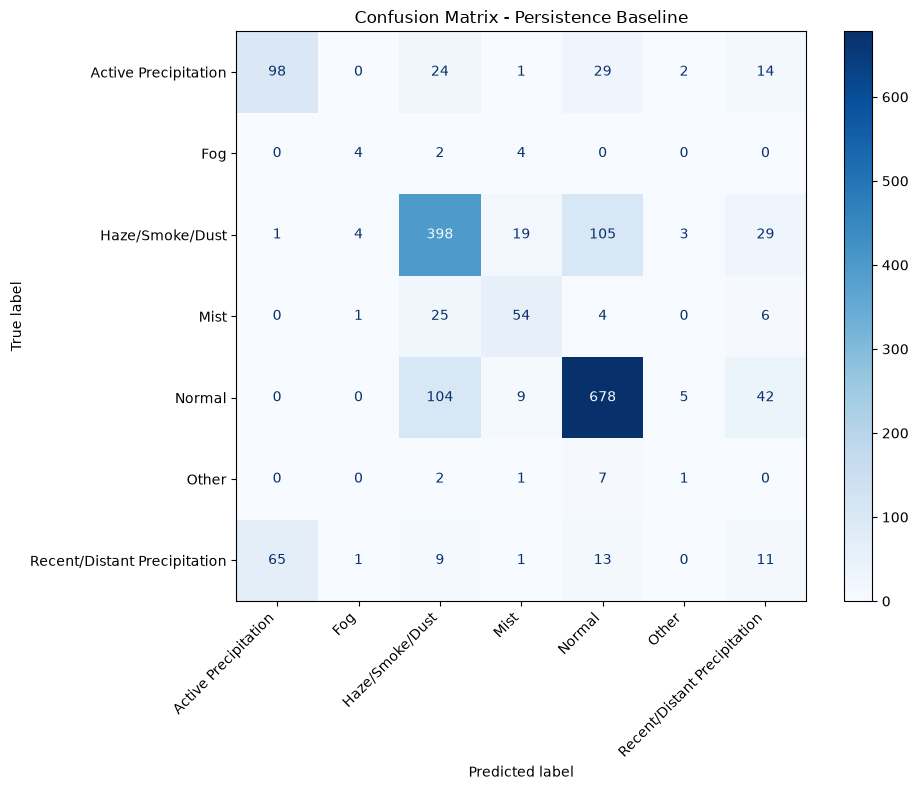

In [228]:
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Persistence Baseline')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [229]:
cm_pers_df = pd.DataFrame(cm_pers, index=target_names, columns=target_names)
cm_pers_df.index.name = 'Actual'
cm_pers_df.columns.name = 'Predicted'
display(cm_pers_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,98,0,24,1,29,2,14
Fog,0,4,2,4,0,0,0
Haze/Smoke/Dust,1,4,398,19,105,3,29
Mist,0,1,25,54,4,0,6
Normal,0,0,104,9,678,5,42
Other,0,0,2,1,7,1,0
Recent/Distant Precipitation,65,1,9,1,13,0,11


**DESICION TREE**

In [230]:
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=target_names
)

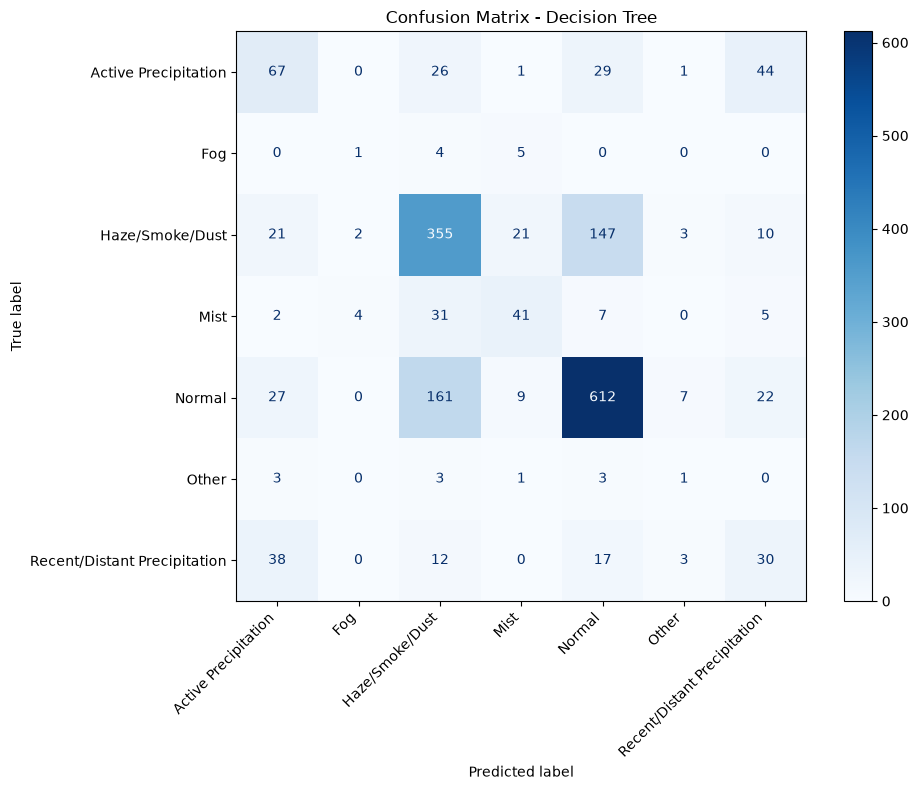

In [231]:
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Decision Tree')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [232]:
cm_dt_df = pd.DataFrame(cm_dt, index=target_names, columns=target_names)
cm_dt_df.index.name = 'Actual'
cm_dt_df.columns.name = 'Predicted'
display(cm_dt_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,67,0,26,1,29,1,44
Fog,0,1,4,5,0,0,0
Haze/Smoke/Dust,21,2,355,21,147,3,10
Mist,2,4,31,41,7,0,5
Normal,27,0,161,9,612,7,22
Other,3,0,3,1,3,1,0
Recent/Distant Precipitation,38,0,12,0,17,3,30


**RANDOM FOREST**

In [233]:
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=target_names
)

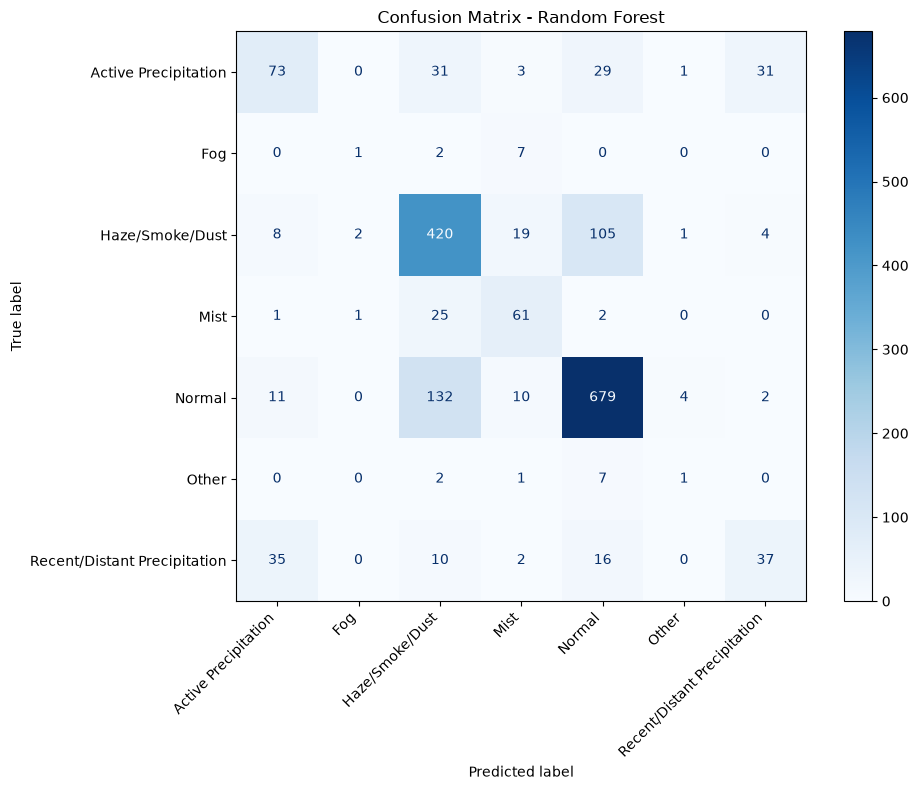

In [234]:
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Random Forest')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [235]:
cm_rf_df = pd.DataFrame(cm_rf, index=target_names, columns=target_names)
cm_rf_df.index.name = 'Actual'
cm_rf_df.columns.name = 'Predicted'
display(cm_rf_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,73,0,31,3,29,1,31
Fog,0,1,2,7,0,0,0
Haze/Smoke/Dust,8,2,420,19,105,1,4
Mist,1,1,25,61,2,0,0
Normal,11,0,132,10,679,4,2
Other,0,0,2,1,7,1,0
Recent/Distant Precipitation,35,0,10,2,16,0,37


**XGBOOST**

In [236]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=target_names
)

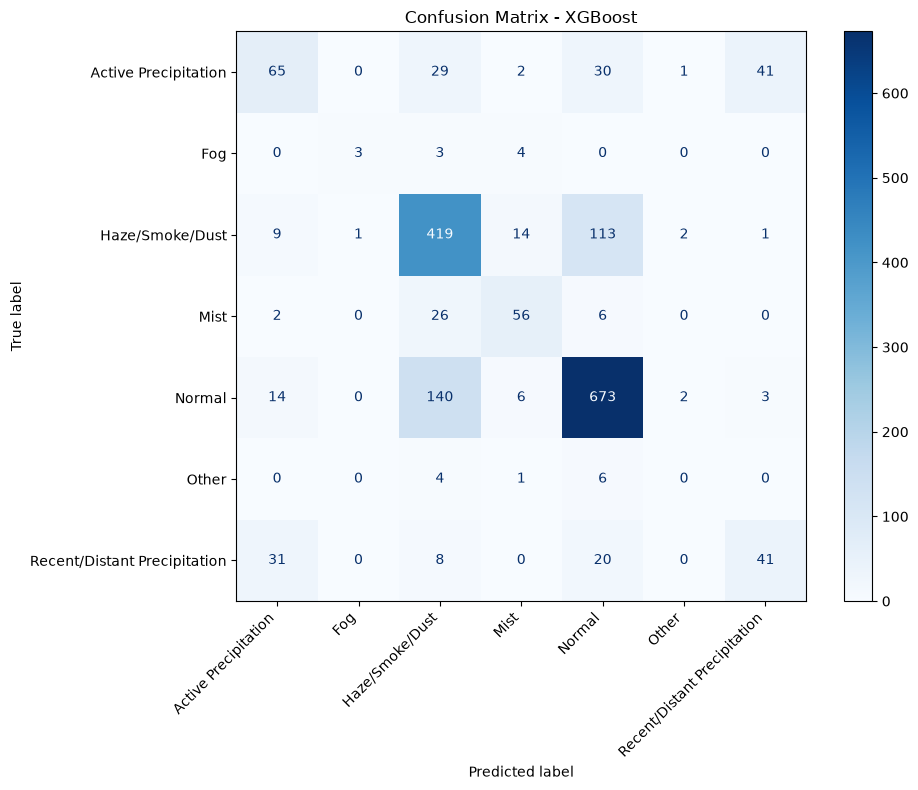

In [237]:
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - XGBoost')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [238]:
cm_xgb_df = pd.DataFrame(cm_xgb, index=target_names, columns=target_names)
cm_xgb_df.index.name = 'Actual'
cm_xgb_df.columns.name = 'Predicted'
display(cm_xgb_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,65,0,29,2,30,1,41
Fog,0,3,3,4,0,0,0
Haze/Smoke/Dust,9,1,419,14,113,2,1
Mist,2,0,26,56,6,0,0
Normal,14,0,140,6,673,2,3
Other,0,0,4,1,6,0,0
Recent/Distant Precipitation,31,0,8,0,20,0,41


**LIGHTGBM**

In [239]:
cm_lgbm = confusion_matrix(y_test, y_pred_lgbm, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lgbm,
    display_labels=target_names
)

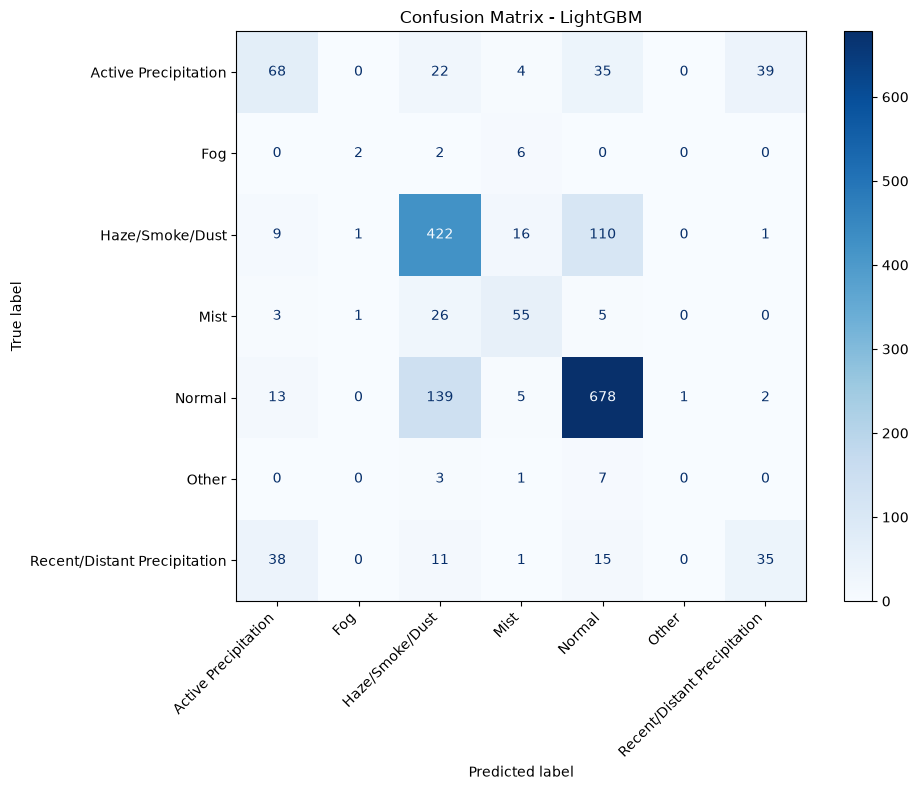

In [240]:
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - LightGBM')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [241]:
cm_lgbm_df = pd.DataFrame(cm_lgbm, index=target_names, columns=target_names)
cm_lgbm_df.index.name = 'Actual'
cm_lgbm_df.columns.name = 'Predicted'
display(cm_lgbm_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,68,0,22,4,35,0,39
Fog,0,2,2,6,0,0,0
Haze/Smoke/Dust,9,1,422,16,110,0,1
Mist,3,1,26,55,5,0,0
Normal,13,0,139,5,678,1,2
Other,0,0,3,1,7,0,0
Recent/Distant Precipitation,38,0,11,1,15,0,35


**Notes:**

- Berdasarkan jumlah prediksi benar pada diagonal utama (*confusion matrix*), ketiga model *ensemble* mengungguli *Persistence Baseline* (`1.244` benar dari `1.776` data uji / `70,05%`), dipimpin oleh **Random Forest** (`1.272` benar / `71,62%`), diikuti **LightGBM** (`1.260` benar / `70,95%`) dan **XGBoost** (`1.257` benar / `70,78%`), sementara **Decision Tree** tunggal memperoleh `1.107` benar (`62,33%`).
- **Matriks Transisi Cuaca pada *Persistence Baseline*:** Karena *Persistence* menyalin kondisi waktu $t$ ke $t+1$, *confusion matrix*-nya sekaligus memperlihatkan pola transisi alami cuaca antarkelas:
  - Kelas yang bersifat persisten seperti `Normal` (`678` dari `838` bertahan), `Haze/Smoke/Dust` (`398` dari `559` bertahan), dan `Active Precipitation` (`98` dari `168` bertahan) memiliki nilai diagonal yang tinggi.
  - Sebaliknya, pada kelas transisi `Recent/Distant Precipitation` (`100` sampel aktual pada $t+1$), hanya `11` sampel yang bertahan dari jam sebelumnya, sedangkan **`65` sampel berasal dari `Active Precipitation` pada waktu $t$** (hujan aktif yang mereda pada 1 jam berikutnya). Hal inilah yang menyebabkan *Persistence* keliru memprediksi `65` observasi tersebut sebagai `Active Precipitation`.
- **Pola Pertukaran Utama (`Normal` vs. `Haze/Smoke/Dust`):**
  - `Normal` (`838` sampel) dikenali tepat sebanyak `673–679` observasi pada model *ensemble* (tertinggi pada Random Forest sebanyak `679` benar, sedikit melampaui *Persistence* `678`), dengan kesalahan terbesar bergeser ke `Haze/Smoke/Dust` (`132–140` sampel) pada fase transisi sore menuju malam hari.
  - `Haze/Smoke/Dust` (`559` sampel) dikenali tepat sebanyak `419–422` observasi pada model *ensemble* (tertinggi pada LightGBM sebanyak `422` benar, unggul `+24` sampel dari *Persistence* `398`), dengan kesalahan utama bergeser ke `Normal` (`105–113` sampel) pada fase pemanasan pagi hari.
- **Pola Pemisahan `Mist` (`90` sampel) dan `Fog` (`10` sampel):**
  - Pada kelas `Mist`, seluruh model *ensemble* melampaui *Persistence* (`54` benar), dipimpin **Random Forest** (`61` benar / *recall* `67,8%`), diikuti **XGBoost** (`56` benar) dan **LightGBM** (`55` benar), dengan mayoritas kesalahan bergeser ke `Haze/Smoke/Dust` (`25–26` sampel) saat visibilitas mulai membaik.
  - Pada kelas minoritas `Fog`, *Persistence* mengenali `4` dari `10` observasi karena kabut tebal sering bertahan lebih dari 1 jam, diikuti **XGBoost** (`3` benar tanpa *false positive* dari kelas `Mist` maupun `Normal`), **LightGBM** (`2` benar), dan **Random Forest** (`1` benar). Sisa observasi `Fog` paling banyak terprediksi sebagai `Mist` (`4–7` sampel) karena kemiripan kondisi kelembapan jenuh.
- **Dinamika Transisi Kelompok Hujan (`Active Precipitation` & `Recent/Distant Precipitation`):**
  - Berkat fitur riwayat waktu ($t-1$ s.d. $t-3$) dan laju perubahan ($\Delta$), model *ensemble* mampu mengenali `35–41` observasi aktual `Recent/Distant Precipitation` secara tepat (tertinggi pada XGBoost sebanyak `41` benar, melonjak jauh dibandingkan *Persistence* yang hanya `11` benar) dan menekan kesalahan prediksi `Active Precipitation` menjadi `31–38` sampel (turun dari `65` sampel pada *Persistence*).
  - Sementara itu, dari `168` sampel aktual `Active Precipitation`, model *ensemble* mengenali `65–73` sampel secara tepat, dengan sisa kesalahan umumnya bergeser ke `Recent/Distant Precipitation` (`31–41` sampel) dan `Normal` (`29–35` sampel) saat intensitas konvektif mulai melemah.
- **Sebaran Kesalahan Kelas `Other` (`11` sampel):** Mayoritas observasi aktual `Other` (kilat kejauhan) terklasifikasi sebagai `Normal` (`6–7` sampel pada model *ensemble*) dan `Haze/Smoke/Dust` (`2–4` sampel), karena fenomena kilat di kejauhan sering terjadi pada malam hari ketika parameter permukaan di stasiun masih tampak cerah atau berkabut tipis.

### Model Comparison

Merangkum metrik evaluasi utama serta nilai *F1-Score* pada kelas-kelas menantang (kelas minoritas dan kelompok hujan) dari *Persistence Baseline* serta keempat model *baseline* ke dalam satu tabel perbandingan guna menentukan kandidat model terbaik sebelum memasuki tahap optimasi (*hyperparameter tuning*).

In [242]:
preds = {
    'Persistence' : y_pred_persistence,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'LightGBM': y_pred_lgbm
}

In [243]:
rows = {}

for name, y_pred in preds.items():
    report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        target_names=target_names,
        output_dict=True,
        zero_division=0
    )

    rows[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'Fog F1': report['Fog']['f1-score'],
        'Mist F1': report['Mist']['f1-score'],
        'Other F1': report['Other']['f1-score'],
        'Active Precip F1': report['Active Precipitation']['f1-score'],
        'Recent/Distant Precip F1': report['Recent/Distant Precipitation']['f1-score']
    }

In [244]:
comparison_df = pd.DataFrame(rows).T
display(comparison_df.round(4))

,Accuracy,Macro F1,Balanced Accuracy,Fog F1,Mist F1,Other F1,Active Precip F1,Recent/Distant Precip F1
Persistence,0.7005,0.4732,0.4722,0.4000,0.6034,0.0909,0.5904,0.1089
Decision Tree,0.6233,0.3908,0.3872,0.1176,0.4881,0.0769,0.4110,0.2844
Random Forest,0.7162,0.4752,0.4621,0.1429,0.6321,0.1111,0.4932,0.4253
XGBoost,0.7078,0.4958,0.4674,0.4286,0.6474,0.0000,0.4498,0.4409
LightGBM,0.7095,0.4672,0.4471,0.2857,0.6180,0.0000,0.4548,0.3955


**Notes:**

- Secara keseluruhan, ketiga algoritma *ensemble* (*Random Forest*, *XGBoost*, dan *LightGBM*) jauh mengungguli *Decision Tree* tunggal di seluruh metrik evaluasi, dengan peningkatan *Accuracy* sebesar `8,45%–9,29%` (`0,6233` menjadi `0,7078–0,7162`) dan peningkatan *Macro F1-Score* sebesar `0,0764–0,1050` (`0,3908` menjadi `0,4672–0,4958`).
- Jika dibandingkan terhadap acuan operasional **Persistence Baseline** (*Accuracy* = `0,7005`, *Macro F1* = `0,4732`, *Balanced Accuracy* = `0,4722`), masing-masing model *ensemble* menunjukkan karakteristik keunggulan yang berbeda:
  - **XGBoost** mencatatkan *Macro F1-Score* tertinggi (`0,4958`, unggul `+0,0226` di atas *Persistence*) dan *Balanced Accuracy* terbaik di antara model *machine learning* (`0,4674`), ditopang oleh performa unggul pada empat kelas menantang sekaligus: `Fog` (`0,4286`), `Mist` (`0,6474`), dan `Recent/Distant Precipitation` (`0,4409`).
  - **Random Forest** meraih *Accuracy* tertinggi (`0,7162`) dan *Macro F1-Score* kedua terbaik (`0,4752`, melampaui *Persistence*), sekaligus unggul pada kelas `Active Precipitation` (`0,4932`) dan satu-satunya model *ensemble* yang mampu mengenali kelas langka `Other` (`0,1111`).
  - **LightGBM** memperoleh *Accuracy* `0,7095` (melampaui *Persistence*), namun *Macro F1-Score* (`0,4672`) dan *Balanced Accuracy* (`0,4471`) masih tertahan tipis di bawah *Persistence* pada pengaturan *default* karena struktur daun pohon *leaf-wise* tanpa pembatasan kedalaman cenderung *overfit* pada data latih (`0,9935`).
- Berdasarkan hasil evaluasi awal pada data uji ini, ketiga algoritma *ensemble* (**Random Forest**, **XGBoost**, dan **LightGBM**) jauh mengungguli *Decision Tree* tunggal dan dilanjutkan ke tahap **Bab 10 (*Model Selection*)** untuk diuji kestabilan generalisasinya menggunakan `5-Fold StratifiedGroupKFold` pada data latih sebelum menentukan kandidat final yang masuk ke tahap optimasi (*hyperparameter tuning*).

# 10. Model Selection

Tahap ini memilih kandidat algoritma terbaik untuk memprediksi fenomena cuaca `1` jam ke depan ($t+1$) berdasarkan evaluasi *Stratified Group Cross-Validation* (`5-Fold`) dan evaluasi *Out-of-Fold* (OOF) pada data latih (`X_train`, `y_train` sebanyak `6.980` observasi dengan `59` fitur prediktor). Seluruh proses validasi dilakukan tanpa menyentuh data uji (`X_test`, `y_test`) agar keputusan pemilihan model bebas dari kebocoran informasi (*data leakage*).

## 10.1 Cross Validation Comparison

Membandingkan performa dan kestabilan keempat algoritma (*Decision Tree*, *Random Forest*, *XGBoost*, dan *LightGBM*) serta acuan *Persistence Baseline* menggunakan `5-Fold StratifiedGroupKFold` berdasarkan kolom `date` pada `train_df`. Pengelompokan berdasarkan tanggal memastikan seluruh observasi jam dalam hari yang sama selalu berada pada *fold* pelatihan atau validasi yang sama. Bobot kelas dihitung ulang di dalam setiap *fold* pelatihan agar evaluasi validasi tetap objektif.

In [245]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [246]:
cv_splits = list(
    cv.split(
        X_train,
        y_train,
        groups=train_df['date']
    )
)
print(f"Jumlah fold : {len(cv_splits)}")

Jumlah fold : 5


In [247]:
for fold, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
    print(f"Fold {fold} -> Train: {len(tr_idx)} baris | Val: {len(val_idx)} baris")

Fold 1 -> Train: 5574 baris | Val: 1406 baris
Fold 2 -> Train: 5606 baris | Val: 1374 baris
Fold 3 -> Train: 5588 baris | Val: 1392 baris
Fold 4 -> Train: 5540 baris | Val: 1440 baris
Fold 5 -> Train: 5612 baris | Val: 1368 baris


In [248]:
candidates = {
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model
}

In [249]:
n_classes = len(label_map)
class_labels = list(range(n_classes))

In [250]:
cv_results = []
oof_predictions = {}

for name, model in candidates.items():
    fold_scores = []
    oof_pred = np.full(len(y_train), -1, dtype=int)

    for fold, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        # Clone model agar setiap fold dilatih dari awal
        m = clone(model)

        # Hitung class weight khusus pada data latih fold ini
        fold_classes = np.unique(y_tr)
        weights = compute_class_weight(
            class_weight='balanced',
            classes=fold_classes,
            y=y_tr
        )
        fold_class_weights = dict(zip(fold_classes, weights))

        if name == 'XGBoost':
            sample_weights = y_tr.map(fold_class_weights)
            m.fit(X_tr, y_tr, sample_weight=sample_weights)
        else:
            m.set_params(class_weight=fold_class_weights)
            m.fit(X_tr, y_tr)

        y_val_pred = m.predict(X_val)
        oof_pred[val_idx] = y_val_pred

        score = f1_score(
            y_val,
            y_val_pred,
            labels=class_labels,
            average='macro',
            zero_division=0
        )
        fold_scores.append(score)
        print(f"{name:<15} | Fold {fold}: Macro F1 = {score:.4f}")

    assert np.all(oof_pred != -1), f"Masih ada indeks yang belum terprediksi pada {name}!"
    oof_predictions[name] = oof_pred

    cv_results.append({
        'Model': name,
        'Macro F1 Mean': np.mean(fold_scores),
        'Macro F1 Std': np.std(fold_scores, ddof=1)
    })
    print("-" * 45)

Decision Tree   | Fold 1: Macro F1 = 0.3812
Decision Tree   | Fold 2: Macro F1 = 0.3722
Decision Tree   | Fold 3: Macro F1 = 0.4248
Decision Tree   | Fold 4: Macro F1 = 0.4358
Decision Tree   | Fold 5: Macro F1 = 0.3939
---------------------------------------------
Random Forest   | Fold 1: Macro F1 = 0.5262
Random Forest   | Fold 2: Macro F1 = 0.4431
Random Forest   | Fold 3: Macro F1 = 0.5416
Random Forest   | Fold 4: Macro F1 = 0.5520
Random Forest   | Fold 5: Macro F1 = 0.4309
---------------------------------------------
XGBoost         | Fold 1: Macro F1 = 0.5742
XGBoost         | Fold 2: Macro F1 = 0.5618
XGBoost         | Fold 3: Macro F1 = 0.5520
XGBoost         | Fold 4: Macro F1 = 0.5527
XGBoost         | Fold 5: Macro F1 = 0.4995
---------------------------------------------
LightGBM        | Fold 1: Macro F1 = 0.5618
LightGBM        | Fold 2: Macro F1 = 0.5215
LightGBM        | Fold 3: Macro F1 = 0.4941
LightGBM        | Fold 4: Macro F1 = 0.5405
LightGBM        | Fold 5: 

**Evaluasi Persistence Baseline pada fold validasi yang sama (tanpa pelatihan)**

In [251]:
persistence_scores = []
for fold, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
    X_val = X_train.iloc[val_idx]
    y_val = y_train.iloc[val_idx]
    y_val_pred = X_val[now_features].values.argmax(axis=1)

    score = f1_score(
        y_val,
        y_val_pred,
        labels=class_labels,
        average='macro',
        zero_division=0
    )
    persistence_scores.append(score)
    print(f"{'Persistence':<15} | Fold {fold}: Macro F1 = {score:.4f}")

oof_predictions['Persistence'] = X_train[now_features].values.argmax(axis=1)
cv_results.append({
    'Model': 'Persistence',
    'Macro F1 Mean': np.mean(persistence_scores),
    'Macro F1 Std': np.std(persistence_scores, ddof=1)
})
print("-" * 45)

cv_comparison_df = (
    pd.DataFrame(cv_results)
    .set_index('Model')
    .sort_values('Macro F1 Mean', ascending=False)
)
display(cv_comparison_df.round(4))

Persistence     | Fold 1: Macro F1 = 0.5517
Persistence     | Fold 2: Macro F1 = 0.5264
Persistence     | Fold 3: Macro F1 = 0.5266
Persistence     | Fold 4: Macro F1 = 0.5100
Persistence     | Fold 5: Macro F1 = 0.5681
---------------------------------------------


,Macro F1 Mean,Macro F1 Std
Model,,
XGBoost,0.5481,0.0286
Persistence,0.5366,0.0231
LightGBM,0.5323,0.0257
Random Forest,0.4988,0.0573
Decision Tree,0.4016,0.0276


In [252]:
cv_comparison_df = (
    pd.DataFrame(cv_results)
    .set_index('Model')
    .sort_values('Macro F1 Mean', ascending=False)
)
display(cv_comparison_df.round(4))

,Macro F1 Mean,Macro F1 Std
Model,,
XGBoost,0.5481,0.0286
Persistence,0.5366,0.0231
LightGBM,0.5323,0.0257
Random Forest,0.4988,0.0573
Decision Tree,0.4016,0.0276


**Notes:**

- Berdasarkan hasil evaluasi `5-Fold StratifiedGroupKFold` pada data latih (`6.980` observasi dengan `59` fitur), **XGBoost** menempati peringkat pertama dengan rata-rata *Macro F1-Score* tertinggi sebesar `0,5481` (`± 0,0286`), sekaligus menjadi satu-satunya model *baseline* yang melampaui acuan operasional **Persistence Baseline** (`0,5366 ± 0,0231`) secara konsisten di hampir seluruh *fold* validasi.
- **LightGBM** menyusul di peringkat kedua di antara model pembelajaran mesin dengan rata-rata *Macro F1-Score* sebesar `0,5323` (`± 0,0257`), berada sangat tipis (`-0,0043` poin) di bawah *Persistence Baseline* dengan kestabilan antar-*fold* yang baik.
- **Random Forest** memperoleh rata-rata *Macro F1-Score* sebesar `0,4988` (`± 0,0573`) dengan variasi antar-*fold* paling besar (rentang `0,4309` pada *Fold* 5 hingga `0,5520` pada *Fold* 4). Pada ruang `59` fitur yang saling berkorelasi (fitur saat ini, *lag*, dan $\Delta$), pemilihan acak sebagian fitur pada setiap percabangan (*feature subsampling*) di pohon *Random Forest* *default* kurang optimal dibandingkan mekanisme *gradient boosting* yang secara sekuensial memfokuskan pemisahan pada galat prediksi dan laju perubahan ($\Delta$).
- **Decision Tree** tunggal mencatat performa terendah dengan rata-rata *Macro F1-Score* sebesar `0,4016` (`± 0,0276`), jauh tertinggal di bawah ketiga model *ensemble* maupun *Persistence Baseline*.

## 10.2 Out-of-Fold Per-Class Evaluation

Mengevaluasi kemampuan setiap model dalam memprediksi masing-masing dari `7` kelas fenomena meteorologi `1` jam ke depan ($t+1$) menggunakan prediksi *out-of-fold* (OOF) yang menggabungkan hasil validasi dari seluruh `5` *fold* pada data latih (`6.980` observasi). Pendekatan ini memberikan gambaran performa per kelas dengan cakupan sampel yang jauh lebih besar (terutama untuk kelas minoritas seperti `Fog` dengan `40` sampel dan `Other` dengan `43` sampel) tanpa menyentuh data uji.

In [253]:
oof_predictions = {}

for name, model in candidates.items():
    oof_pred = np.full(len(y_train), -1, dtype=int)

    for fold, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
        X_tr = X_train.iloc[tr_idx]
        X_val = X_train.iloc[val_idx]
        y_tr = y_train.iloc[tr_idx]

        # Clone model agar setiap fold dilatih secara independen
        m = clone(model)

        # Hitung class weight khusus pada fold pelatihan
        fold_classes = np.unique(y_tr)
        weights = compute_class_weight(
            class_weight='balanced',
            classes=fold_classes,
            y=y_tr
        )
        fold_class_weights = dict(zip(fold_classes, weights))

        if name == 'XGBoost':
            sample_weights = y_tr.map(fold_class_weights)
            m.fit(X_tr, y_tr, sample_weight=sample_weights)
        else:
            m.set_params(class_weight=fold_class_weights)
            m.fit(X_tr, y_tr)

        oof_pred[val_idx] = m.predict(X_val)

    # Pastikan seluruh baris latih telah menerima prediksi OOF
    assert np.all(oof_pred != -1), f"Masih ada indeks yang belum terprediksi pada {name}!"
    oof_predictions[name] = oof_pred
    print(f"{name:<15}: OOF prediction selesai ({len(oof_pred)} baris)")

Decision Tree  : OOF prediction selesai (6980 baris)
Random Forest  : OOF prediction selesai (6980 baris)
XGBoost        : OOF prediction selesai (6980 baris)
LightGBM       : OOF prediction selesai (6980 baris)


In [254]:
oof_predictions['Persistence'] = X_train[now_features].values.argmax(axis=1)

In [255]:
oof_results = []
class_names = [inv_label_map[i] for i in range(n_classes)]

for name, y_pred in oof_predictions.items():
    report = classification_report(
        y_train,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    for class_name in class_names:
        oof_results.append({
            'Model': name,
            'Class': class_name,
            'Precision': report[class_name]['precision'],
            'Recall': report[class_name]['recall'],
            'F1-Score': report[class_name]['f1-score'],
            'Support': int(report[class_name]['support'])
        })

oof_comparison_df = pd.DataFrame(oof_results)
display(
    oof_comparison_df
    .set_index(['Model', 'Class'])
    .round(4)
)

Precision  Recall  F1-Score  \
Model         Class                                                       
Decision Tree Active Precipitation             0.3949  0.4097    0.4021   
              Fog                              0.1860  0.2000    0.1928   
              Haze/Smoke/Dust                  0.6269  0.6222    0.6245   
              Mist                             0.4121  0.4385    0.4249   
              Normal                           0.7631  0.7457    0.7543   
              Other                            0.1064  0.1163    0.1111   
              Recent/Distant Precipitation     0.2925  0.3212    0.3062   
Random Forest Active Precipitation             0.5644  0.4984    0.5294   
              Fog                              0.6667  0.2500    0.3636   
              Haze/Smoke/Dust                  0.7055  0.7578    0.7307   
              Mist                             0.5469  0.6508    0.5944   
              Normal                           0.8311  0.8376    0.8343   
              Other                            0.2857  0.0930    0.1404   
              Recent/Distant Precipitation     0.4423  0.2979    0.3560   
XGBoost       Active Precipitation             0.5783  0.4315    0.4942   
              Fog                              0.5366  0.5500    0.5432   
              Haze/Smoke/Dust                  0.7143  0.7532    0.7333   
              Mist                             0.6246  0.5950    0.6094   
              Normal                           0.8117  0.8498    0.8303   
              Other                            0.3636  0.1860    0.2462   
              Recent/Distant Precipitation     0.4566  0.3679    0.4075   
LightGBM      Active Precipitation             0.5594  0.4548    0.5017   
              Fog                              0.6667  0.5500    0.6027   
              Haze/Smoke/Dust                  0.7158  0.7588    0.7367   
              Mist                             0.6478  0.6061    0.6263   
              Normal                           0.8160  0.8477    0.8316   
              Other                            0.2857  0.0465    0.0800   
              Recent/Distant Precipitation     0.4455  0.3601    0.3983   
Persistence   Active Precipitation             0.6062  0.6090    0.6076   
              Fog                              0.6000  0.6000    0.6000   
              Haze/Smoke/Dust                  0.7291  0.7274    0.7282   
              Mist                             0.5822  0.5838    0.5830   
              Normal                           0.8231  0.8238    0.8234   
              Other                            0.3256  0.3256    0.3256   
              Recent/Distant Precipitation     0.1224  0.1218    0.1221   

                                            Support  
Model         Class                                  
Decision Tree Active Precipitation              642  
              Fog                                40  
              Haze/Smoke/Dust                  2168  
              Mist                              358  
              Normal                           3343  
              Other                              43  
              Recent/Distant Precipitation      386  
Random Forest Active Precipitation              642  
              Fog                                40  
              Haze/Smoke/Dust                  2168  
              Mist                              358  
              Normal                           3343  
              Other                              43  
              Recent/Distant Precipitation      386  
XGBoost       Active Precipitation              642  
              Fog                                40  
              Haze/Smoke/Dust                  2168  
              Mist                              358  
              Normal                           3343  
              Other                              43  
              Recent/Distant Precipitation      386  
LightGBM      Active Preci

**Ringkasan OOF Macro F1 keseluruhan untuk setiap model**

In [256]:
oof_macro_f1 = [
    {
        'Model': name,
        'OOF Macro F1': f1_score(
            y_train,
            y_pred,
            labels=class_labels,
            average='macro',
            zero_division=0
        )
    }
    for name, y_pred in oof_predictions.items()
]

oof_macro_f1_df = (
    pd.DataFrame(oof_macro_f1)
    .set_index('Model')
    .sort_values('OOF Macro F1', ascending=False)
)

display(oof_macro_f1_df.round(4))

,OOF Macro F1
Model,
XGBoost,0.5520
Persistence,0.5414
LightGBM,0.5396
Random Forest,0.5070
Decision Tree,0.4023


**Notes:**

- Berdasarkan evaluasi *Out-of-Fold* (OOF) secara menyeluruh pada `6.980` observasi data latih (`59` fitur), **XGBoost** memperoleh *OOF Macro F1-Score* tertinggi sebesar `0,5520` dan unggul di atas **Persistence Baseline** (`0,5414`). **LightGBM** berada tipis di bawah *Persistence* pada angka `0,5396`, diikuti oleh **Random Forest** (`0,5070`), sedangkan **Decision Tree** tunggal tertinggal jauh di angka `0,4023`.
- **Keunggulan Spesifik Tiap Model *Ensemble* per Kelas:**
  - **XGBoost** mencatatkan performa paling seimbang di seluruh kelas—meraih *F1-Score* tertinggi di antara model *machine learning* pada kelas transisi `Recent/Distant Precipitation` (`0,4075`, jauh melampaui *Persistence* yang hanya `0,1221`) dan kelas langka `Other` (`0,2462` dengan *precision* `0,3636`), sekaligus mempertahankan kinerja solid pada `Fog` (`0,5432`), `Mist` (`0,6094`), dan `Normal` (`0,8303`).
  - **LightGBM** unggul di antara model pembelajaran mesin pada empat kelas, yakni `Haze/Smoke/Dust` (`0,7367`), `Mist` (`0,6263`, melampaui *Persistence* `0,5830`), `Fog` (`0,6027` dengan *precision* `0,6667`, menyamai *Persistence* `0,6000`), dan `Normal` (`0,8316`). Nilai *OOF Macro F1-Score*-nya tertahan tipis di bawah *Persistence* semata-mata karena rendahnya deteksi pada kelas langka `Other` (`0,0800`, *recall* `0,0465`).
  - **Random Forest** meraih skor tertinggi di antara model *machine learning* pada kelas mayoritas `Normal` (`0,8343`) dan hujan aktif `Active Precipitation` (`0,5294`), namun skor keseluruhannya tertahan oleh rendahnya *recall* pada kelas minoritas `Fog` (`0,2500`, *F1* = `0,3636`) dan `Other` (`0,0930`, *F1* = `0,1404`).
- **Tantangan Utama Menuju Tahap Optimasi:** Seluruh model *machine learning* masih mencatat *F1-Score* lebih rendah dibandingkan *Persistence* pada kelas `Active Precipitation` (`0,4942–0,5294` vs. `0,6076`) karena kecenderungan memprediksi hujan aktif akan segera mereda menjadi `Recent/Distant Precipitation` pada $t+1$. Selain itu, kelas `Other` (`43` sampel) tetap menjadi tantangan tersulit karena sifatnya yang merupakan kategori gabungan dari berbagai fenomena kilat kejauhan yang heterogen.

## 10.3 Model Selection Decision

Menetapkan kandidat model yang akan dilanjutkan ke tahap *hyperparameter tuning* berdasarkan rata-rata dan kestabilan *Macro F1-Score* pada `5-Fold StratifiedGroupKFold` serta kinerja per kelas pada evaluasi *Out-of-Fold* (OOF) di atas `6.980` observasi data latih.

**Notes:**

- Kedua algoritma *gradient boosting* (**XGBoost** dan **LightGBM**) menunjukkan performa dan kestabilan validasi silang yang jauh lebih unggul dibandingkan **Random Forest** maupun **Decision Tree** tunggal pada skema prediksi `1` jam ke depan ($t+1$).
- **XGBoost** menempati peringkat pertama pada rata-rata *CV Macro F1-Score* (`0,5481 ± 0,0286`) dan *OOF Macro F1-Score* (`0,5520`), menjadi satu-satunya model *default* yang melampaui *Persistence Baseline* (`0,5366` CV / `0,5414` OOF), serta unggul pada kelas transisi `Recent/Distant Precipitation` dan kelas minoritas `Other`.
- **LightGBM** menempati peringkat kedua di antara model *machine learning* (`CV Macro F1` = `0,5323 ± 0,0257`; `OOF Macro F1` = `0,5396`), hanya terpaut `0,0043` poin di bawah *Persistence Baseline* pada CV dengan standar deviasi antar-*fold* yang rendah, serta unggul pada kelas `Fog`, `Mist`, dan `Haze/Smoke/Dust`. Pembatasan kompleksitas daun pohon (*num_leaves*, *min_child_samples*) pada tahap *tuning* berpotensi mengangkat performanya melampaui *Persistence*.
- **Random Forest** (`CV Macro F1` = `0,4988 ± 0,0573`; `OOF Macro F1` = `0,5070`) tidak dilanjutkan ke tahap *hyperparameter tuning* karena rata-rata skor validasi silangnya terpaut cukup jauh (`-0,0378` poin) di bawah *Persistence Baseline* sekaligus memiliki fluktuasi antar-*fold* paling besar (`Std CV = 0,0573`).
- **Decision Tree** tunggal juga tidak dilanjutkan karena mencatat performa terendah (`CV Macro F1` = `0,4016`; `OOF Macro F1` = `0,4023`), sehingga dipertahankan sebatas acuan *single-tree baseline*.
- Dengan demikian, **XGBoost** dan **LightGBM** dipilih untuk masuk ke tahap **Bab 11 (*Hyperparameter Tuning*)**. Model terbaik hasil *tuning* akan ditetapkan berdasarkan rata-rata *Macro F1-Score* pada `5-Fold StratifiedGroupKFold`, kemudian dievaluasi satu kali secara final pada data uji (`X_test`, `y_test`).

| Model | CV Macro F1 (Mean ± Std) | OOF Macro F1 | Keputusan |
| :--- | :---: | :---: | :--- |
| **XGBoost** | `0,5481 ± 0,0286` | `0,5520` | Dilanjutkan ke *Hyperparameter Tuning* |
| *Persistence (Acuan)* | *0,5366 ± 0,0231* | *0,5414* | *Acuan operasional non-ML* |
| **LightGBM** | `0,5323 ± 0,0257` | `0,5396` | Dilanjutkan ke *Hyperparameter Tuning* |
| **Random Forest** | `0,4988 ± 0,0573` | `0,5070` | Tidak dilanjutkan (skor CV di bawah acuan & varians tinggi) |
| **Decision Tree** | `0,4016 ± 0,0276` | `0,4023` | Tidak dilanjutkan (dipertahankan sebagai *baseline*) |

# 11. Hyperparameter Tuning

Tahap ini melakukan optimasi *hyperparameter* pada dua kandidat algoritma *gradient boosting* terbaik hasil seleksi pada Bab 10 (**XGBoost** dan **LightGBM**) untuk meningkatkan kemampuan prediksi `7` kelas fenomena meteorologi `1` jam ke depan ($t+1$) sekaligus menekan indikasi *overfitting* yang teramati pada model *baseline*.

Proses pencarian dilakukan menggunakan *Randomized Search Cross-Validation* (`RandomizedSearchCV`) dengan skema `5-Fold StratifiedGroupKFold` (`cv_splits`) berdasarkan tanggal pengamatan dan *Macro F1-Score* sebagai metrik optimasi utama. Pembobotan kelas seimbang tetap diterapkan secara dinamis di dalam setiap *fold* pelatihan agar bebas dari kebocoran informasi (*data leakage*).

## 11.1 Define Search Space

Menentukan ruang distribusi *hyperparameter* untuk masing-masing algoritma *gradient boosting* dengan fokus pada pengendalian kompleksitas pohon, laju pembelajaran (*learning rate*), *subsampling*, dan regularisasi guna mengurangi selisih performa antara data latih dan data validasi:

- **XGBoost:** Mengatur jumlah pohon (`n_estimators`), laju pembelajaran (`learning_rate`), kedalaman maksimum (`max_depth`), bobot minimum anak simpul (`min_child_weight`), proporsi sampel dan fitur (`subsample`, `colsample_bytree`), serta penalti regularisasi (`reg_lambda`, `gamma`).
- **LightGBM:** Mengatur jumlah iterasi (`n_estimators`), laju pembelajaran (`learning_rate`), jumlah maksimum daun (`num_leaves`), jumlah minimum sampel per daun (`min_child_samples`), *subsampling* baris dan fitur (`subsample`, `colsample_bytree`, `subsample_freq`), serta regularisasi L2 (`reg_lambda`).

In [257]:
# rf_param_dist = {
#     'n_estimators': randint(200, 601),
#     'max_depth': [8, 10, 12, 15, 18, 20, None],
#     'min_samples_split': randint(2, 21),
#     'min_samples_leaf': randint(1, 9),
#     'max_features': [0.5, 0.7, 'sqrt', 1.0]
# }

### XGBoost

- `n_estimators`: jumlah pohon yang dibangun secara bertahap.
- `learning_rate`: mengatur kontribusi setiap pohon baru terhadap model secara keseluruhan.
- `max_depth`: membatasi kedalaman pohon untuk mengendalikan kompleksitas model.
- `min_child_weight`: menentukan batas minimum bobot sampel pada child node agar suatu pemisahan dapat dilakukan.
- `subsample`: proporsi sampel training yang digunakan untuk membangun setiap pohon.
- `colsample_bytree`: proporsi fitur yang digunakan untuk membangun setiap pohon.
- `reg_lambda`: parameter regularisasi L2 yang membantu mengendalikan kompleksitas model.

In [258]:
xgb_param_dist = {
    'n_estimators': randint(200, 801),
    'learning_rate': loguniform(0.02, 0.1),
    'max_depth': randint(2, 9),
    'min_child_weight': randint(1, 41),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_lambda': loguniform(1, 50),
    'gamma': uniform(0, 2)
}

### LightGBM

- `n_estimators`: jumlah boosting iteration atau pohon yang dibangun.
- `learning_rate`: mengatur kontribusi setiap pohon baru dalam proses boosting.
- `num_leaves`: jumlah maksimum leaf dalam satu pohon. Parameter ini berpengaruh terhadap kompleksitas model.
- `min_child_samples`: jumlah minimum sampel yang harus terdapat pada setiap leaf.
- `subsample`: proporsi sampel training yang digunakan dalam setiap iterasi.
- `colsample_bytree`: proporsi fitur yang digunakan dalam pembangunan setiap pohon.
- `reg_lambda`: parameter regularisasi L2 untuk membantu mengurangi kompleksitas model.
- `subsample_freq`: frekuensi penerapan subsampling. Nilai `1` berarti subsampling dilakukan pada setiap iterasi boosting.

In [259]:
lgbm_param_dist = {
    'n_estimators': randint(200, 601),
    'learning_rate': loguniform(0.03, 0.2),
    'num_leaves': randint(15, 64),
    'min_child_samples': randint(5, 51),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_lambda': uniform(0, 30),
    'subsample_freq': [1]
}

## 11.2 Randomized Search CV

Melakukan pencarian kombinasi *hyperparameter* terbaik menggunakan `RandomizedSearchCV` dengan `n_iter=50` kandidat acak pada setiap model (`250` total *fit* per algoritma pada `5` *fold*).

Untuk menjaga konsistensi penanganan ketidakseimbangan kelas pada kedua algoritma, **LightGBM** menggunakan `class_weight='balanced'` yang otomatis menghitung bobot berdasarkan proporsi label latih di tiap *fold*, sedangkan **XGBoost** dibungkus menggunakan `FoldBalancedXGBClassifier` agar perhitungan `sample_weight` juga dilakukan secara terisolasi di dalam masing-masing *fold* pelatihan.

In [260]:
class FoldBalancedXGBClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, estimator):
        self.estimator = estimator

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)
        fold_classes = np.unique(y)
        weights = compute_class_weight(
            class_weight='balanced',
            classes=fold_classes,
            y=y
        )
        weight_dict = dict(zip(fold_classes, weights))
        sample_weights = np.array([weight_dict[label] for label in y])

        self.estimator_.fit(X, y, sample_weight=sample_weights)
        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

In [261]:
search_configs = {
    'XGBoost': {
        'model': xgb_model,
        'params': xgb_param_dist
    },
    'LightGBM': {
        'model': lgbm_model,
        'params': lgbm_param_dist
    }
}

In [262]:
search_results = {}
best_estimators = {}

for name, config in search_configs.items():
    print(f"\n{'='*55}")
    print(f"Hyperparameter Tuning: {name}")
    print(f"{'='*55}")

    model = clone(config['model'])
    param_dist = config['params'].copy()

    if name == 'XGBoost':
        base_model = clone(model)
        base_model.set_params(n_jobs=1)
        model = FoldBalancedXGBClassifier(estimator=base_model)
        param_dist = {
            f'estimator__{param}': values
            for param, values in param_dist.items()
        }
    else:
        model.set_params(
            class_weight='balanced',
            n_jobs=1
        )

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_dist,
        n_iter=50,
        scoring='f1_macro',
        cv=cv_splits,
        random_state=42,
        n_jobs=-1,
        refit=True,
        verbose=1,
        return_train_score=True
    )

    search.fit(X_train, y_train)

    search_results[name] = search
    best_estimators[name] = search.best_estimator_

    print(f"\nBest CV Macro F1 ({name}): {search.best_score_:.4f}")
    print("Best Parameters:")
    print(search.best_params_)


Hyperparameter Tuning: XGBoost
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best CV Macro F1 (XGBoost): 0.5525
Best Parameters:
{'estimator__colsample_bytree': np.float64(0.6959149436629612), 'estimator__gamma': np.float64(0.1877465801625835), 'estimator__learning_rate': np.float64(0.026844037847316867), 'estimator__max_depth': 6, 'estimator__min_child_weight': 1, 'estimator__n_estimators': 471, 'estimator__reg_lambda': np.float64(7.54833980626809), 'estimator__subsample': np.float64(0.8628445314000668)}

Hyperparameter Tuning: LightGBM
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best CV Macro F1 (LightGBM): 0.5517
Best Parameters:
{'colsample_bytree': np.float64(0.88453678109946), 'learning_rate': np.float64(0.13432405362420607), 'min_child_samples': 9, 'n_estimators': 430, 'num_leaves': 55, 'reg_lambda': np.float64(27.448790266313424), 'subsample': np.float64(0.9400154311159197), 'subsample_freq': 1}


**Notes:**

- Setelah mengevaluasi `50` kombinasi *hyperparameter* (`250` total *fit* per model pada `5-Fold StratifiedGroupKFold` di ruang `59` fitur), kedua model *gradient boosting* berhasil melampaui skor CV *baseline*-nya (Sub-bab 10.1) maupun acuan operasional *Persistence Baseline* (`0,5366`):
  - **XGBoost** meraih rata-rata *CV Macro F1-Score* tertinggi sebesar `0,5525` (meningkat `+0,0045` dari skor *baseline* `0,5481`), menggunakan laju pembelajaran rendah (`learning_rate = 0,0268`), `n_estimators = 471`, kedalaman pohon moderat (`max_depth = 6`), `min_child_weight = 1`, `subsample = 0,8628`, `colsample_bytree = 0,6959`, serta regularisasi `reg_lambda = 7,55` dan `gamma = 0,1877`.
  - **LightGBM** mencatatkan lonjakan peningkatan terbesar dari *baseline*-nya sebesar `+0,0194`, naik dari `0,5323` menjadi `0,5517` (hanya terpaut `0,0008` poin di bawah XGBoost), menggunakan `learning_rate = 0,1343`, `n_estimators = 430`, `num_leaves = 55`, `min_child_samples = 9`, `subsample = 0,9400`, `colsample_bytree = 0,8845`, serta regularisasi L2 yang kuat (`reg_lambda = 27,45`).
- Perbandingan selisih skor latih-validasi (*train-validation gap*), kestabilan antar-*fold*, serta performa per kelas melalui evaluasi *Out-of-Fold* (OOF) dianalisis pada sub-bab berikutnya untuk menetapkan model utama sebelum menyentuh data uji.

### Perbandingan dengan baseline dan train-validation gap

Membandingkan performa ketiga model hasil *tuning* terhadap skor *Cross-Validation* tahap *baseline* (Bab 10.1), standar deviasi antar-*fold* (`Std CV`), serta selisih antara skor rata-rata data latih (`Train F1`) dan data validasi (`Valid F1`) untuk menilai efektivitas regularisasi dalam menekan *overfitting*.

In [263]:
comparison_data = []

for name, search in search_results.items():
    results = search.cv_results_
    idx = search.best_index_

    # Ambil skor CV baseline langsung dari tabel Bab 10.1
    baseline_score = cv_comparison_df.loc[name, 'Macro F1 Mean']
    valid_score = search.best_score_
    train_score = results['mean_train_score'][idx]

    comparison_data.append({
        'Model': name,
        'Baseline CV Macro F1': baseline_score,
        'Tuned CV Macro F1': valid_score,
        'Improvement': valid_score - baseline_score,
        'Std CV': results['std_test_score'][idx],
        'Train F1': train_score,
        'Valid F1': valid_score,
        'Train-Valid Gap': train_score - valid_score
    })

tuning_comparison = (
    pd.DataFrame(comparison_data)
    .sort_values(by='Tuned CV Macro F1', ascending=False)
    .reset_index(drop=True)
)

display(tuning_comparison.round(4))

,Model,Baseline CV Macro F1,Tuned CV Macro F1,Improvement,Std CV,Train F1,Valid F1,Train-Valid Gap
0,XGBoost,0.5481,0.5525,0.0045,0.0048,0.9444,0.5525,0.3919
1,LightGBM,0.5323,0.5517,0.0194,0.0185,0.9998,0.5517,0.4481


### Perbandingan F1-score per kelas menggunakan OOF

Mengevaluasi *F1-Score* hasil prediksi *out-of-fold* dari masing-masing model hasil *tuning* pada seluruh `7` kelas fenomena meteorologi `1` jam ke depan ($t+1$) di data latih (`6.980` observasi) untuk melihat perubahan kemampuan deteksi per kelas sebelum menentukan model utama untuk evaluasi akhir pada data uji.

In [264]:
oof_tuned_predictions = {
    name: cross_val_predict(
        search.best_estimator_,
        X_train,
        y_train,
        cv=cv_splits,
        n_jobs=-1
    )
    for name, search in search_results.items()
}

n_classes = len(label_map)
class_labels = list(range(n_classes))
class_names = [inv_label_map[i] for i in range(n_classes)]

oof_tuned_comparison = pd.DataFrame({
    name: f1_score(
        y_train,
        predictions,
        average=None,
        labels=class_labels,
        zero_division=0
    )
    for name, predictions in oof_tuned_predictions.items()
}, index=class_names)

# Tambahkan baris rata-rata OOF Macro F1 di bagian bawah tabel
oof_tuned_comparison.loc['OOF Macro F1'] = [
    f1_score(y_train, oof_tuned_predictions[name], labels=class_labels, average='macro', zero_division=0)
    for name in oof_tuned_predictions.keys()
]

display(oof_tuned_comparison.round(4))

,XGBoost,LightGBM
Active Precipitation,0.4938,0.5048
Fog,0.5783,0.6190
Haze/Smoke/Dust,0.7318,0.7423
Mist,0.5987,0.6165
Normal,0.8325,0.8381
Other,0.2432,0.1613
Recent/Distant Precipitation,0.4295,0.4352
OOF Macro F1,0.5583,0.5596


**Notes:**

- **Peningkatan Performa dan Pengendalian *Overfitting*:**
  - **XGBoost** meraih rata-rata *Tuned CV Macro F1-Score* tertinggi sebesar `0,5525` (meningkat `+0,0045` dari *baseline* `0,5481`) sekaligus mencatat kestabilan antar-*fold* yang jauh lebih rapat (`Std CV = 0,0048`, turun tajam dari `0,0286` pada tahap *baseline*). Selain itu, XGBoost menunjukkan generalisasi yang lebih terkendali dengan *Train-Validation Gap* sebesar `0,3919` (`Train F1 = 0,9444`, turun dari `0,9964` pada *baseline*).
  - **LightGBM** mengalami peningkatan paling besar dari tahap *baseline* sebesar `+0,0194` (`0,5323` menjadi `0,5517`) dan memperoleh *OOF Macro F1-Score* sedikit lebih tinggi (`0,5596` vs. `0,5583` pada XGBoost). Namun, variasi antar-*fold*-nya masih lebih lebar (`Std CV = 0,0185`) dengan *Train-Validation Gap* yang tinggi sebesar `0,4481` (`Train F1 = 0,9998`) akibat struktur pohon *leaf-wise* dengan `num_leaves = 55`.
- **Perbandingan *F1-Score* per Kelas (OOF pada `6.980` observasi):**
  - **LightGBM** unggul pada enam dari tujuh kelas, yaitu `Normal` (`0,8381`), `Haze/Smoke/Dust` (`0,7423`), kelas minoritas `Fog` (`0,6190`), `Mist` (`0,6165`), `Active Precipitation` (`0,5048`), dan `Recent/Distant Precipitation` (`0,4352`).
  - **XGBoost** bersaing ketat di seluruh kelas tersebut (`Normal = 0,8325`, `Haze/Smoke/Dust = 0,7318`, `Mist = 0,5987`, `Fog = 0,5783`, `Recent/Distant Precipitation = 0,4295`) sekaligus mempertahankan keunggulan signifikan pada kelas minoritas paling langka **`Other`** (`0,2432` vs. `0,1613` pada LightGBM).
- **Keputusan Pemilihan Model Utama:** Sesuai protokol pemilihan yang ditetapkan sebelum menyentuh data uji (Sub-bab 10.3), **XGBoost** ditetapkan sebagai **model utama (*primary model*)** karena meraih rata-rata *Tuned CV Macro F1-Score* tertinggi (`0,5525`), memiliki kestabilan antar-*fold* hampir empat kali lebih konsisten (`Std CV = 0,0048`), memiliki *train-validation gap* yang lebih rendah, serta unggul pada kelas langka `Other`. Sementara itu, **LightGBM** disertakan sebagai **model pembanding (*comparison model*)** pada evaluasi akhir data uji.

## 11.4 Final Evaluation on Test Set

Tahap ini melakukan evaluasi akhir satu kali terhadap kedua model hasil *hyperparameter tuning* menggunakan data uji (`X_test`, `y_test` sebanyak `1.776` observasi) yang sepenuhnya terpisah selama proses pelatihan dan optimasi. **XGBoost** dievaluasi sebagai model utama, sedangkan **LightGBM** disertakan sebagai model pembanding (bersama acuan *Persistence Baseline* pada Sub-bab 9.1). Pengukuran mencakup metrik keseluruhan (*Accuracy*, *Macro F1-Score*, *Balanced Accuracy*), laporan klasifikasi per kelas (*Classification Report*), serta matriks kebingungan (*Confusion Matrix*) untuk seluruh `7` kelas fenomena meteorologi pada $t+1$.

In [265]:
n_classes = len(label_map)
class_labels = list(range(n_classes))
class_names = [inv_label_map[i] for i in range(n_classes)]

test_predictions = {}
test_results = []

for name, search in search_results.items():
    model = search.best_estimator_
    y_pred = model.predict(X_test)
    test_predictions[name] = y_pred

    class_f1 = f1_score(
        y_test,
        y_pred,
        average=None,
        labels=class_labels,
        zero_division=0
    )

    test_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'Fog F1': class_f1[label_map['Fog']],
        'Mist F1': class_f1[label_map['Mist']],
        'Other F1': class_f1[label_map['Other']],
        'Active Precip F1': class_f1[label_map['Active Precipitation']],
        'Recent/Distant Precip F1': class_f1[label_map['Recent/Distant Precipitation']]
    })

test_comparison = (
    pd.DataFrame(test_results)
    .sort_values(by='Macro F1', ascending=False)
    .reset_index(drop=True)
)

display(test_comparison.round(4))

,Model,Accuracy,Macro F1,Balanced Accuracy,Fog F1,Mist F1,Other F1,Active Precip F1,Recent/Distant Precip F1
0,XGBoost,0.7044,0.5056,0.5027,0.4444,0.5930,0.0952,0.4527,0.4455
1,LightGBM,0.7095,0.4953,0.4680,0.4286,0.6328,0.0000,0.4648,0.4362


**Notes:**

- **Kesesuaian Pemilihan Model Utama pada Data Uji:** **XGBoost**—yang telah ditetapkan sebagai model utama (*primary model*) berdasarkan skor validasi silang terbaik sebelum menyentuh data uji (Sub-bab 11.3)—kembali membuktikan generalisasi terbaik pada data uji dengan meraih *Macro F1-Score* tertinggi sebesar `0,5056` (meningkat `+0,0098` dari *baseline* `0,4958` serta unggul `+0,0324` di atas *Persistence Baseline* `0,4732`), dan *Balanced Accuracy* tertinggi sebesar `0,5027` (naik `+0,0353` dari *baseline* `0,4674` serta unggul `+0,0305` di atas *Persistence* `0,4722`), dengan *Accuracy* `0,7044`.
- **Peningkatan Performa pada Model Pembanding (LightGBM):** **LightGBM** hasil *tuning* juga mencatat kenaikan signifikan dibandingkan tahap *baseline* (`Macro F1-Score` naik `+0,0281` dari `0,4672` menjadi `0,4953`, melampaui *Persistence Baseline* `0,4732`), dengan *Accuracy* `0,7095` dan *Balanced Accuracy* `0,4680` (naik `+0,0209`).
- **Perbandingan Keunggulan Antarmodel pada Data Uji:** **XGBoost** unggul pada metrik keseimbangan utama (*Macro F1* = `0,5056`, *Balanced Accuracy* = `0,5027`) serta empat kelas sekaligus—yakni `Fog` (`0,4444`), `Recent/Distant Precipitation` (`0,4455`), `Haze/Smoke/Dust` (`0,7032`), dan kelas langka `Other` (`0,0952`). Sementara itu, **LightGBM** unggul tipis pada *Accuracy* keseluruhan (`0,7095`), `Mist` (`0,6328`), dan `Active Precipitation` (`0,4648`), namun belum mengenali kelas `Other` (`0,0000`).

### Classification Report

Menampilkan nilai *precision*, *recall*, dan *F1-Score* untuk masing-masing dari `7` kelas fenomena pada $t+1$ di data uji (`1.776` observasi) guna membandingkan kinerja rinci kedua model hasil *tuning*.

In [266]:
for name, y_pred in test_predictions.items():
    print(f"\n{'='*65}")
    print(f"Classification Report (Tuned): {name}")
    print(f"{'='*65}")

    print(classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        zero_division=0,
        digits=4
    ))


Classification Report (Tuned): XGBoost
                              precision    recall  f1-score   support

        Active Precipitation     0.5234    0.3988    0.4527       168
                         Fog     0.5000    0.4000    0.4444        10
             Haze/Smoke/Dust     0.6847    0.7227    0.7032       559
                        Mist     0.5413    0.6556    0.5930        90
                      Normal     0.8094    0.8007    0.8050       838
                       Other     0.1000    0.0909    0.0952        11
Recent/Distant Precipitation     0.4412    0.4500    0.4455       100

                    accuracy                         0.7044      1776
                   macro avg     0.5143    0.5027    0.5056      1776
                weighted avg     0.7027    0.7044    0.7022      1776


Classification Report (Tuned): LightGBM
                              precision    recall  f1-score   support

        Active Precipitation     0.5690    0.3929    0.4648       168
     

**Notes:**

- **Kestabilan pada Kelas Mayoritas (`Normal` & `Haze/Smoke/Dust`):** Kedua model hasil *tuning* mempertahankan kinerja yang sangat konsisten pada dua kelas dominan tanpa mengorbankan sensitivitas kelas minoritas—yaitu `Normal` (`838` sampel) dengan *F1-Score* `0,8050` pada XGBoost (*precision* `0,8094`, *recall* `0,8007`) dan `0,8052` pada LightGBM, serta `Haze/Smoke/Dust` (`559` sampel) dengan *F1-Score* `0,7032` pada XGBoost dan `0,6995` pada LightGBM.
- **Peningkatan Deteksi Kelas Transisi Hujan (`Recent/Distant Precipitation`, `100` sampel):** Optimasi parameter meningkatkan *F1-Score* **XGBoost** menjadi `0,4455` (*recall* naik dari `0,4100` menjadi `0,4500`, melampaui *Persistence* yang hanya `0,1100` lebih dari empat kali lipat), sementara **LightGBM** naik dari `0,3955` menjadi `0,4362` (*precision* `0,4659`, *recall* `0,4100`).
- **Performa pada `Mist` (`90` sampel) dan `Active Precipitation` (`168` sampel):** Pada kelas `Mist`, **XGBoost** meningkatkan *recall* dari `0,6222` menjadi `0,6556` (*F1-Score* `0,5930`), sedangkan **LightGBM** meraih *F1-Score* tertinggi sebesar `0,6328` (*precision* `0,6437`, *recall* `0,6222`). Pada `Active Precipitation`, kedua model mencatat peningkatan tipis dibandingkan *baseline* (`0,4527` pada XGBoost dan `0,4648` pada LightGBM), meski masih berada di bawah *Persistence* (`0,5904`) karena sifat hujan konvektif yang cepat berubah dalam rentang `1` jam.
- **Keunggulan XGBoost pada Kelas Minoritas Langka (`Fog` & `Other`):**
  - **`Fog` (`10` sampel):** **XGBoost** meningkatkan *recall* dari `0,3000` menjadi `0,4000` (*F1-Score* `0,4444`, melampaui *Persistence* `0,4000`), sedangkan **LightGBM** meningkat dari `0,2857` menjadi `0,4286` (*precision* `0,7500`, *recall* `0,3000`).
  - **`Other` (`11` sampel):** **XGBoost** berhasil meningkatkan deteksi dari `0,0000` pada tahap *baseline* menjadi `0,0952` (*precision* `0,1000`, *recall* `0,0909`, menyamai *Persistence* `0,0909`), sementara **LightGBM** masih berada di angka `0,0000`.

### Confusion Matrix

Memvisualisasikan perbandingan label aktual pada $t+1$ dan hasil prediksi pada data uji (`1.776` observasi) untuk kedua model hasil *tuning* guna mengamati perubahan pola kesalahan klasifikasi setelah optimasi parameter.

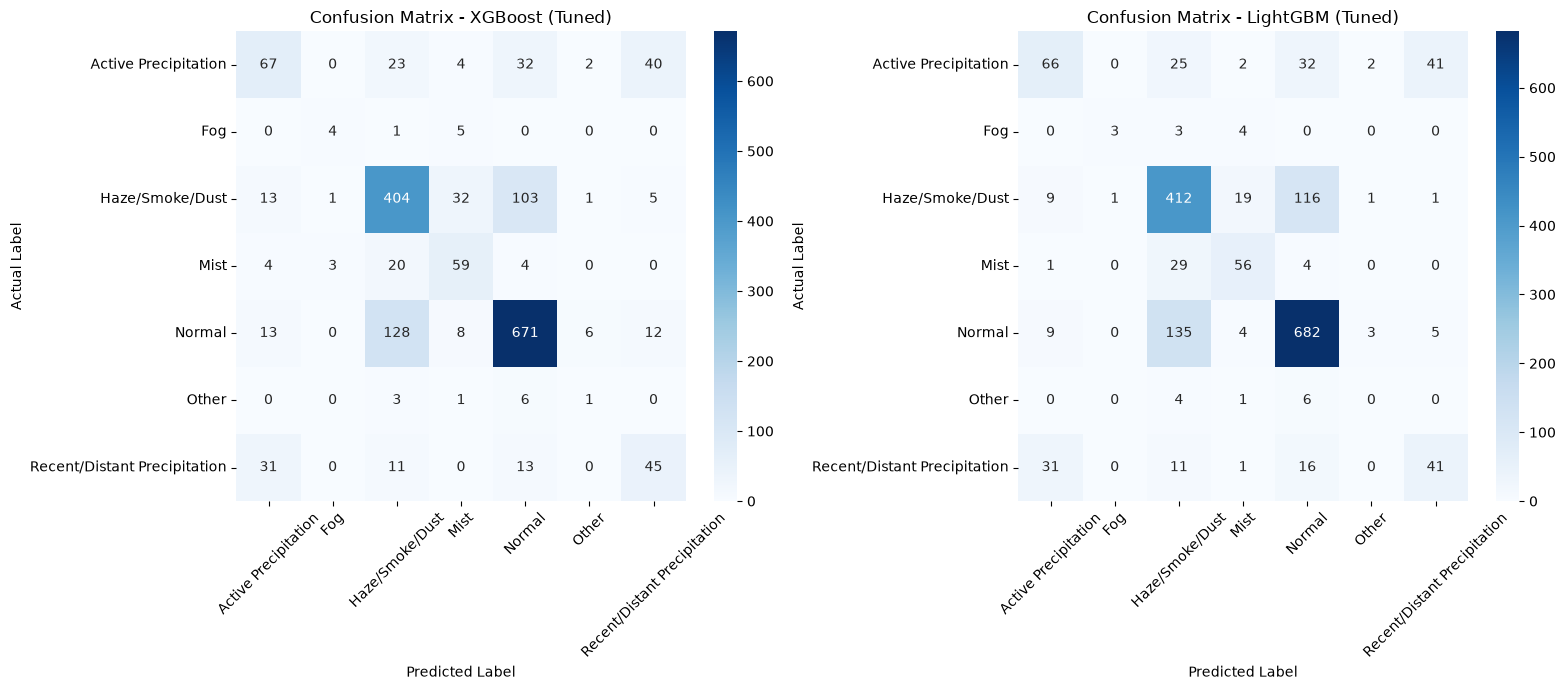

In [276]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (name, y_pred) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(f'Confusion Matrix - {name} (Tuned)')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

In [268]:
for name, y_pred in test_predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    cm_df = pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )
    cm_df.index.name = 'Actual'
    cm_df.columns.name = 'Predicted'

    print(f"\nConfusion Matrix (Tuned): {name}")
    display(cm_df)


Confusion Matrix (Tuned): XGBoost


Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,67,0,23,4,32,2,40
Fog,0,4,1,5,0,0,0
Haze/Smoke/Dust,13,1,404,32,103,1,5
Mist,4,3,20,59,4,0,0
Normal,13,0,128,8,671,6,12
Other,0,0,3,1,6,1,0
Recent/Distant Precipitation,31,0,11,0,13,0,45



Confusion Matrix (Tuned): LightGBM


Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,66,0,25,2,32,2,41
Fog,0,3,3,4,0,0,0
Haze/Smoke/Dust,9,1,412,19,116,1,1
Mist,1,0,29,56,4,0,0
Normal,9,0,135,4,682,3,5
Other,0,0,4,1,6,0,0
Recent/Distant Precipitation,31,0,11,1,16,0,41


**Notes:**

- **Total Prediksi Tepat pada Diagonal Utama:** **LightGBM** menghasilkan `1.260` prediksi benar dari `1.776` observasi uji (`70,95%`), sedangkan **XGBoost** (model utama) menghasilkan `1.251` prediksi benar (`70,44%`)—keduanya melampaui *Persistence Baseline* (`1.244` benar / `70,05%`).
- **Keseimbangan Prediksi Kelas Dominan vs. Sensitivitas Kelas Minoritas:**
  - **XGBoost** menunjukkan distribusi prediksi yang lebih seimbang lintas kelas minoritas dan transisi: berhasil menangkap `45` dari `100` observasi `Recent/Distant Precipitation` (naik dari `41` pada *baseline* dan jauh melampaui *Persistence* `11`), `59` dari `90` observasi `Mist` (naik dari `56`), `4` dari `10` observasi `Fog` (naik dari `3`), serta `1` dari `11` observasi `Other` (naik dari `0`), dengan konsekuensi sedikit penurunan prediksi benar pada kelas mayoritas (`671` pada `Normal` dan `404` pada `Haze/Smoke/Dust`).
  - **LightGBM** mempertahankan konsentrasi prediksi lebih tinggi pada kelas mayoritas (`682` benar pada `Normal` dan `412` benar pada `Haze/Smoke/Dust`), mengenali `41` observasi `Recent/Distant Precipitation` (naik dari `35`), `56` observasi `Mist`, dan `3` observasi `Fog` (naik dari `2`), namun tidak menghasilkan satu pun prediksi tepat pada kelas `Other` (`0` benar).
- **Konsistensi Pemisahan `Fog` (`10` sampel) dan Batas dengan `Mist` (`90` sampel):** Pada kedua model hasil *tuning*, kesalahan klasifikasi pada `Fog` seluruhnya bergeser ke `Mist` (`4–5` sampel) dan `Haze/Smoke/Dust` (`1–3` sampel) tanpa satu pun tertukar ke `Normal` maupun hujan. Secara meteorologis, hal ini sangat wajar karena `Fog` dan `Mist` sama-sama terbentuk pada kondisi kelembapan tinggi dan hanya dibedakan oleh ambang jarak pandang permukaan (`< 1.000 m` untuk *fog* vs. `≥ 1.000 m` untuk *mist*).
- **Pola Kebingungan yang Persisten pada Kelompok Hujan dan `Other`:** Pada `Recent/Distant Precipitation` (`100` sampel), meski jumlah prediksi benar meningkat (`41–45` sampel), sisa observasi masih dominan bergeser ke `Active Precipitation` (`31` sampel pada kedua model) dan `Normal` (`13–16` sampel) karena hujan yang baru berlalu atau berada di kejauhan sering kali tidak lagi meninggalkan jejak curah hujan langsung di stasiun saat jam pengamatan. Sementara pada kelas langka `Other` (`11` sampel), mayoritas observasi tetap masuk ke `Normal` (`6` sampel) dan `Haze/Smoke/Dust` (`3–4` sampel) akibat heterogenitas fenomena kilat kejauhan.

# 12. Feature Importance

Tahap ini dilakukan untuk mengidentifikasi kontribusi masing-masing dari `59` fitur masukan (`7` fitur kondisi cuaca saat ini `now_*`, `13` fitur dasar pada waktu $t$, `30` fitur riwayat waktu `lag1–lag3`, dan `9` fitur laju perubahan $\Delta$) dalam memprediksi `7` fenomena meteorologi `1` jam ke depan ($t+1$) pada model utama terpilih (**XGBoost** hasil *hyperparameter tuning*). Analisis dilakukan menggunakan dua pendekatan yang saling melengkapi, yaitu *Model-Based Feature Importance (Gain)* bawaan XGBoost dan *Permutation Feature Importance* pada data uji (`X_test`, `y_test`).

## 12.1 Model-Based Feature Importance (Gain)

Analisis ini mengukur kontribusi setiap fitur berdasarkan nilai *gain* dari model utama **XGBoost** (`importance_type='gain'`), yang merepresentasikan rata-rata peningkatan akurasi pemisahan (*gain*) yang dihasilkan suatu fitur setiap kali digunakan untuk membagi cabang (*split*) pada seluruh pohon keputusan, kemudian dinormalisasi menjadi proporsi terhadap total keseluruhan *gain*. Semakin tinggi nilainya, semakin besar peran fitur tersebut dalam membentuk aturan pemisahan kelas selama pelatihan.

In [269]:
final_xgb = search_results['XGBoost'].best_estimator_

In [270]:
final_xgb.estimator_.set_params(importance_type='gain')

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,np.float64(0.6959149436629612)
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_

In [271]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Gain Importance': final_xgb.estimator_.feature_importances_
})
assert len(feature_importance) == X_train.shape[1], "Jumlah fitur tidak sinkron!"

In [272]:
feature_importance = (
    feature_importance
    .sort_values('Gain Importance', ascending=False)
    .reset_index(drop=True)
)
display(feature_importance.head(15).round(4))

,Feature,Gain Importance
0,now_Normal,0.1425
1,now_Mist,0.1014
2,now_Haze_Smoke_Dust,0.0895
3,now_Active_Precipitation,0.0624
4,now_Other,0.0524
5,now_Fog,0.0454
6,visibility_vv,0.0412
7,visibility_vv_lag1,0.0305
8,relative_humidity_pc,0.0232
9,now_Recent_Distant_Precipitation,0.0226


In [273]:
def classify_feature_group(name):
    if name.startswith('now_'):
        return 'Current Phenomenon (t)'
    if '_lag' in name:
        return 'Lag Features (t-1 to t-3)'
    if '_diff_' in name:
        return 'Rate of Change (Delta)'
    return 'Base Features (t)'

feature_importance['Group'] = feature_importance['Feature'].apply(classify_feature_group)
print(feature_importance['Group'].value_counts())

Group
Lag Features (t-1 to t-3)    30
Base Features (t)            13
Rate of Change (Delta)        9
Current Phenomenon (t)        7
Name: count, dtype: int64


In [274]:
group_gain_summary = (
    feature_importance
    .groupby('Group', as_index=False)
    .agg(
        Feature_Count=('Feature', 'count'),
        Total_Gain=('Gain Importance', 'sum'),
        Mean_Gain=('Gain Importance', 'mean')
    )
    .sort_values(by='Total_Gain', ascending=False)
    .reset_index(drop=True)
)
print("Kontribusi Gain Importance per Kelompok Fitur")
display(group_gain_summary.round(4))

Kontribusi Gain Importance per Kelompok Fitur


,Group,Feature_Count,Total_Gain,Mean_Gain
0,Current Phenomenon (t),7,0.5161,0.0737
1,Lag Features (t-1 to t-3),30,0.2616,0.0087
2,Base Features (t),13,0.1523,0.0117
3,Rate of Change (Delta),9,0.0699,0.0078


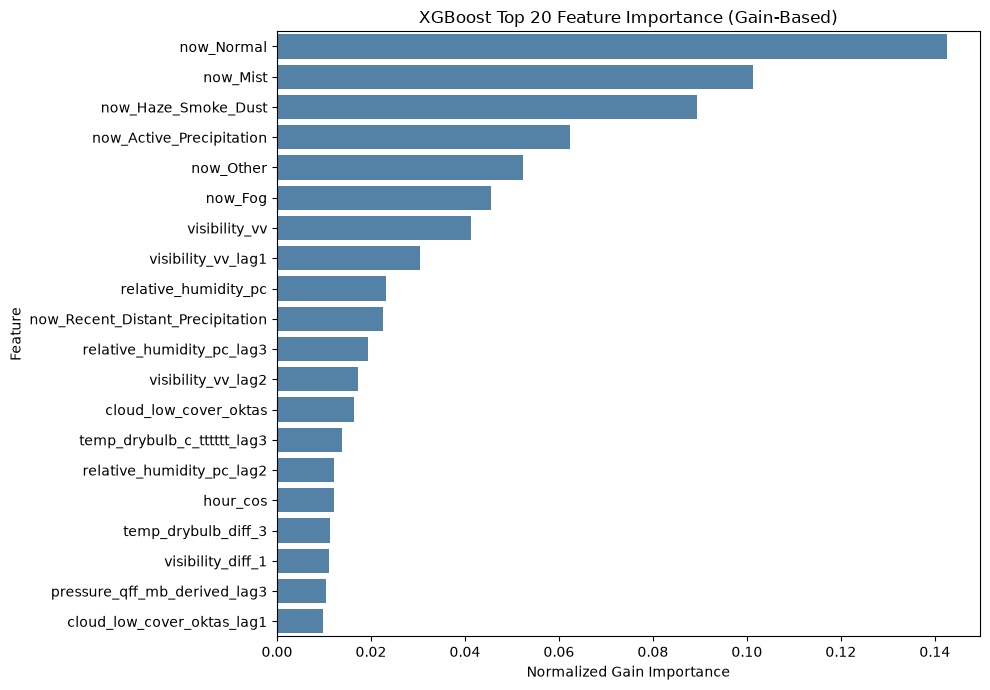

In [275]:
plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_importance.head(20),
    x='Gain Importance',
    y='Feature',
    color='steelblue'
)
plt.title('XGBoost Top 20 Feature Importance (Gain-Based)')
plt.xlabel('Normalized Gain Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

**Notes:**

- **Dominasi Kondisi Cuaca Saat Ini (`now_*`) pada Peringkat Teratas:** Enam posisi teratas seluruhnya ditempati oleh fitur biner status fenomena aktual pada waktu $t$ (`Current Phenomenon (t)`), yaitu `now_Normal` (`0,1425`), `now_Mist` (`0,1014`), `now_Haze_Smoke_Dust` (`0,0895`), `now_Active_Precipitation` (`0,0624`), `now_Other` (`0,0524`), dan `now_Fog` (`0,0454`). Keenam fitur ini menyumbang `49,36%` (`0,4936`) dari total *gain* model—menegaskan bahwa keadaan atmosfer awal pada waktu $t$ menjadi jangkar utama bagi pohon keputusan sebelum mengevaluasi transisi menuju $t+1$.
- **Peran Variabel Fisik dan Riwayat Waktu (`Lag` & `Delta`):** Tepat di bawah kelompok status saat ini, parameter fisik permukaan dan riwayat waktu langsung menyusul di `15` besar, dipimpin oleh jarak pandang saat ini `visibility_vv` (`0,0412`), jarak pandang `1` jam lalu `visibility_vv_lag1` (`0,0305`), kelembapan relatif `relative_humidity_pc` (`0,0232`), `now_Recent_Distant_Precipitation` (`0,0226`), kelembapan relatif `3` jam lalu `relative_humidity_pc_lag3` (`0,0194`), `visibility_vv_lag2` (`0,0173`), tutupan awan rendah `cloud_low_cover_oktas` (`0,0164`), dan suhu bola kering `3` jam lalu `temp_drybulb_c_tttttt_lag3` (`0,0138`).
- **Kontribusi Gabungan per Kelompok Fitur:** Secara agregat, kelompok `Current Phenomenon (t)` (`7` fitur) menyumbang `51,61%` (`0,5161`) dari total *gain* dengan rata-rata per fitur tertinggi (`0,0737`), sedangkan gabungan parameter meteorologi fisik (`52` fitur)—yang terdiri dari `Lag Features (t-1 to t-3)` (`30` fitur = `0,2616` / `26,16%`), `Base Features (t)` (`13` fitur = `0,1523` / `15,23%`), dan `Rate of Change (Delta)` (`9` fitur = `0,0699` / `6,99%`)—menyumbang `48,38%` (`0,4838`) untuk menentukan kapan cuaca bertahan atau bertransisi ke fenomena lain pada $t+1$.

## 12.2 Permutation Feature Importance

*Permutation Feature Importance* mengevaluasi ketergantungan model utama (**XGBoost**) terhadap masing-masing dari `59` fitur berdasarkan besarnya penurunan kinerja *Macro F1-Score* pada data uji (`X_test`, `y_test` sebanyak `1.776` observasi) ketika nilai suatu fitur diacak secara acak sebanyak `10` kali pengulangan (`n_repeats=10`).

Interpretasi nilai rata-rata perubahan skor (*Permutation Mean*):
- **Bernilai positif:** Pengacakan fitur menurunkan kinerja model, menandakan fitur tersebut memberikan informasi penting bagi generalisasi pada data uji.
- **Mendekati nol:** Pengacakan fitur hampir tidak mengubah kinerja model.
- **Bernilai negatif:** Skor *Macro F1* sedikit meningkat saat fitur diacak, yang umumnya terjadi pada fitur dengan kontribusi sangat kecil atau fitur yang informasinya sudah terwakili oleh variabel lain yang berkorelasi.

In [415]:
perm_result = permutation_importance(
    final_xgb,
    X_test,
    y_test,
    scoring='f1_macro',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

In [416]:
permutation_importance_df = (
    pd.DataFrame({
        'Feature': X_test.columns,
        'Group': [classify_feature_group(f) for f in X_test.columns],
        'Permutation Mean': perm_result.importances_mean,
        'Permutation Std': perm_result.importances_std
    })
    .sort_values(by='Permutation Mean', ascending=False)
    .reset_index(drop=True)
)
print("Top 20 Fitur Berdasarkan Permutation Importance (Test Set - Macro F1)")
display(permutation_importance_df.head(20).round(4))

Top 20 Fitur Berdasarkan Permutation Importance (Test Set - Macro F1)


,Feature,Group,Permutation Mean,Permutation Std
0,now_Active_Precipitation,Current Phenomenon (t),0.0740,0.0063
1,visibility_vv,Base Features (t),0.0690,0.0103
2,cloud_low_cover_oktas,Base Features (t),0.0419,0.0089
3,now_Haze_Smoke_Dust,Current Phenomenon (t),0.0379,0.0125
4,visibility_vv_lag1,Lag Features (t-1 to t-3),0.0351,0.0089
5,hour_cos,Base Features (t),0.0277,0.0122
6,now_Normal,Current Phenomenon (t),0.0275,0.0109
7,wind_dir_sin_lag3,Lag Features (t-1 to t-3),0.0205,0.0126
8,visibility_vv_lag2,Lag Features (t-1 to t-3),0.0181,0.0075
9,temp_drybulb_diff_3,Rate of Change (Delta),0.0163,0.0124


In [417]:
group_perm_summary = (
    permutation_importance_df
    .groupby('Group', as_index=False)
    .agg(
        Feature_Count=('Feature', 'count'),
        Total_Perm_Importance=('Permutation Mean', 'sum'),
        Mean_Perm_Importance=('Permutation Mean', 'mean'),
        Positive_Features=('Permutation Mean', lambda s: int((s > 0).sum()))
    )
    .sort_values(by='Total_Perm_Importance', ascending=False)
    .reset_index(drop=True)
)
print("Kontribusi Permutation Importance per Kelompok Fitur")
display(group_perm_summary.round(4))

Kontribusi Permutation Importance per Kelompok Fitur


,Group,Feature_Count,Total_Perm_Importance,Mean_Perm_Importance,Positive_Features
0,Current Phenomenon (t),7,0.1769,0.0253,7
1,Base Features (t),13,0.1532,0.0118,10
2,Lag Features (t-1 to t-3),30,0.1027,0.0034,18
3,Rate of Change (Delta),9,0.0417,0.0046,7


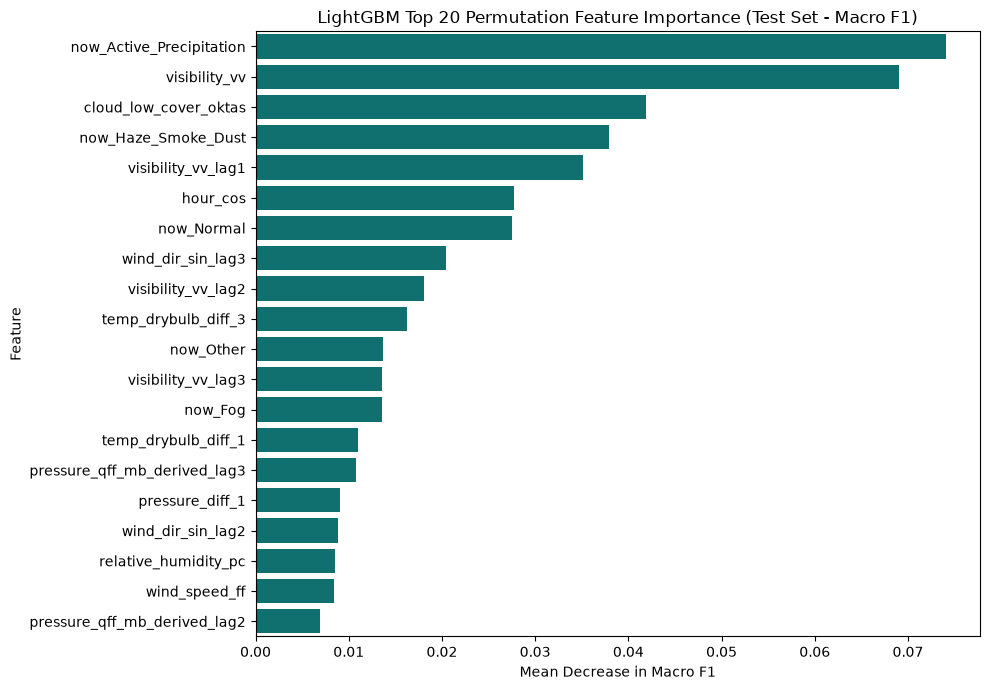

In [418]:
plt.figure(figsize=(10, 7))
sns.barplot(
    data=permutation_importance_df.head(20),
    x='Permutation Mean',
    y='Feature',
    color='teal'
)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('XGBoost Top 20 Permutation Feature Importance (Test Set - Macro F1)')
plt.xlabel('Mean Decrease in Macro F1')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

**Notes:**

- **Sinergi Status Cuaca Saat Ini dan Parameter Fisik Utama pada Data Uji:** Pengacakan `now_Active_Precipitation` menyebabkan penurunan *Macro F1-Score* terbesar sebesar `0,0740 ± 0,0063`, diikuti sangat ketat oleh jarak pandang `visibility_vv` (`0,0690 ± 0,0103`), tutupan awan rendah `cloud_low_cover_oktas` (`0,0419 ± 0,0089`), `now_Haze_Smoke_Dust` (`0,0379 ± 0,0125`), serta jarak pandang `1` jam lalu `visibility_vv_lag1` (`0,0351 ± 0,0089`). Hal ini menunjukkan bahwa generalisasi model pada data baru bertumpu pada kombinasi keadaan cuaca awal, visibilitas terkini/riwayat `1` jam lalu, dan liputan awan konvektif rendah.
- **Kontribusi Konsisten Fitur Siklikal, Riwayat Waktu (`Lag`), dan Laju Perubahan (`Delta`):** Sebanyak `42` dari `59` fitur memiliki *Permutation Mean* bernilai positif (`7/7` fitur `Current Phenomenon (t)`, `10/13` fitur `Base (t)`, `18/30` fitur `Lag`, dan `7/9` fitur `Delta`). Di jajaran `20` besar, selain kelompok `now_*` dan fitur dasar (`hour_cos = 0,0277`, `relative_humidity_pc = 0,0085`, `wind_speed_ff = 0,0084`), terdapat `6` fitur *Lag* (`visibility_vv_lag1`, `wind_dir_sin_lag3`, `visibility_vv_lag2`, `visibility_vv_lag3`, `pressure_qff_mb_derived_lag3`, `wind_dir_sin_lag2`, `pressure_qff_mb_derived_lag2`) dan `3` fitur *Delta* (`temp_drybulb_diff_3 = 0,0163`, `temp_drybulb_diff_1 = 0,0110`, dan `pressure_diff_1 = 0,0090`).
- **Bukti Empiris Peran Dinamika Termal dan Barometrik:** Kemunculan laju perubahan suhu `3` jam (`temp_drybulb_diff_3`) dan `1` jam (`temp_drybulb_diff_1`) serta kecenderungan tekanan udara (`pressure_diff_1`, `pressure_qff_mb_derived_lag3`) di jajaran `20` besar membuktikan bahwa gradien pendinginan suhu dan pergeseran tekanan barometrik memberikan sinyal nyata bagi XGBoost untuk memprediksi transisi cuaca `1` jam ke depan ($t+1$) pada data uji.

## 12.3 Perbandingan dan Interpretasi Feature Importance

Menggabungkan hasil *Gain-Based Feature Importance* dan *Permutation Feature Importance* pada model utama (**XGBoost**) dalam satu tabel perbandingan untuk melihat konsistensi peringkat fitur dominan serta mengidentifikasi variabel yang berperan besar dalam pemisahan aturan pohon namun memiliki dampak berbeda terhadap generalisasi pada data uji.

In [419]:
importance_comparison = (
    feature_importance
    .merge(permutation_importance_df, on=['Feature', 'Group'])
    .sort_values(by='Gain Importance', ascending=False)
    .reset_index(drop=True)
)

In [420]:
importance_comparison['Gain Rank'] = importance_comparison.index + 1
importance_comparison['Perm Rank'] = (
    importance_comparison['Permutation Mean']
    .rank(ascending=False, method='min')
    .astype(int)
)

In [421]:
cols_order = [
    'Feature',
    'Group',
    'Gain Rank',
    'Gain Importance',
    'Perm Rank',
    'Permutation Mean',
    'Permutation Std'
]

In [422]:
print("Perbandingan Top 20 Fitur (Gain vs Permutation Importance - XGBoost)")
display(importance_comparison[cols_order].head(20).round(4))

Perbandingan Top 20 Fitur (Gain vs Permutation Importance - XGBoost)


,Feature,Group,Gain Rank,Gain Importance,Perm Rank,Permutation Mean,Permutation Std
0,now_Normal,Current Phenomenon (t),1,0.1425,7,0.0275,0.0109
1,now_Mist,Current Phenomenon (t),2,0.1014,26,0.0049,0.0017
2,now_Haze_Smoke_Dust,Current Phenomenon (t),3,0.0895,4,0.0379,0.0125
3,now_Active_Precipitation,Current Phenomenon (t),4,0.0624,1,0.0740,0.0063
4,now_Other,Current Phenomenon (t),5,0.0524,11,0.0136,0.0002
5,now_Fog,Current Phenomenon (t),6,0.0454,13,0.0136,0.0006
6,visibility_vv,Base Features (t),7,0.0412,2,0.0690,0.0103
7,visibility_vv_lag1,Lag Features (t-1 to t-3),8,0.0305,5,0.0351,0.0089
8,relative_humidity_pc,Base Features (t),9,0.0232,18,0.0085,0.0059
9,now_Recent_Distant_Precipitation,Current Phenomenon (t),10,0.0226,24,0.0053,0.0088


**Notes:**

- **Kesepakatan Tinggi pada Jangkar Utama Prediksi $t+1$:** Kedua metode menempatkan kelompok kondisi cuaca saat ini (`now_*`), jarak pandang terkini/terdekat (`visibility_vv`, `visibility_vv_lag1`), tutupan awan rendah (`cloud_low_cover_oktas`), siklus diurnal (`hour_cos`), dan laju pendinginan suhu `3` jam (`temp_drybulb_diff_3`) secara konsisten di papan atas:
  - `now_Active_Precipitation` (`Gain Rank 4 = 0,0624` | `Perm Rank 1 = 0,0740`), `now_Haze_Smoke_Dust` (`Gain Rank 3 = 0,0895` | `Perm Rank 4 = 0,0379`), dan `now_Normal` (`Gain Rank 1 = 0,1425` | `Perm Rank 7 = 0,0275`) menjadi penentu utama transisi maupun persistensi kondisi cuaca.
  - `visibility_vv` (`Gain Rank 7 = 0,0412` | `Perm Rank 2 = 0,0690`) dan `visibility_vv_lag1` (`Gain Rank 8 = 0,0305` | `Perm Rank 5 = 0,0351`) memperlihatkan keselarasan sangat rapat antara aturan pemisahan pohon dan kontribusi generalisasi pada data uji.
  - Parameter fisik dan temporal seperti `cloud_low_cover_oktas` (`Gain Rank 13` | `Perm Rank 3 = 0,0419`), `hour_cos` (`Gain Rank 16` | `Perm Rank 6 = 0,0277`), `temp_drybulb_diff_3` (`Gain Rank 17` | `Perm Rank 10 = 0,0163`), dan `pressure_qff_mb_derived_lag3` (`Gain Rank 19` | `Perm Rank 15 = 0,0108`) justru memiliki peringkat generalisasi (*Permutation Rank*) yang lebih tinggi dibandingkan peringkat *Gain*-nya.
- **Divergensi Peringkat Akibat Redundansi Informasi Fisik:**
  - Fitur `now_Mist` menempati peringkat ke-2 pada *Gain Importance* (`0,1014`) karena XGBoost sering memakainya sebagai titik percabangan awal untuk memisahkan kelas `Mist` saat pelatihan, namun turun ke peringkat ke-26 pada *Permutation Importance* (`0,0049`). Hal ini terjadi karena saat `now_Mist` diacak pada data uji, informasi kondisi kabut tipis tetap dapat dipulihkan oleh kombinasi jarak pandang (`visibility_vv`, `visibility_vv_lag1`) dan kelembapan relatif (`relative_humidity_pc`).
  - Pola serupa terlihat pada `relative_humidity_pc_lag3` (`Gain Rank 11 = 0,0194` $\rightarrow$ `Perm Rank 56 = -0,0087`) dan `visibility_diff_1` (`Gain Rank 18 = 0,0112` $\rightarrow$ `Perm Rank 54 = -0,0044`), di mana sinyal meteorologisnya telah terwakili dengan kuat oleh variabel kelembapan dan jarak pandang pada titik waktu utama maupun *lag* terdekat.

# 13. External Validation

*External validation* dilakukan untuk menguji kemampuan generalisasi model utama terpilih (**XGBoost** hasil *hyperparameter tuning*) dalam memprediksi fenomena cuaca `1` jam ke depan ($t+1$) pada dataset observasi periode baru di luar rentang data pelatihan dan pengujian internal (`Januari–Juni 2026`). Data eksternal diproses menggunakan tahapan pembersihan, pemetaan kategori `7` kelas fenomena cuaca, *feature engineering* (`7` fitur kondisi cuaca saat ini `now_*`, `13` fitur dasar pada waktu $t$, `30` fitur riwayat waktu `lag1–lag3`, dan `9` fitur laju perubahan $\Delta$), seleksi `59` fitur, serta pergeseran target $t+1$ yang identik dengan *pipeline* pelatihan, kemudian diprediksi secara langsung tanpa pelatihan ulang (*zero retraining*).

## 13.1 Inspeksi Data Eksternal

Tahap ini memeriksa dimensi dataset (`shape`), struktur kolom, contoh baris awal, serta kelengkapan nilai (*missing value*) pada file data eksternal (`bmkg-jambi-26-new.csv`) sebelum dilakukan pembersihan dan transformasi fitur.

In [277]:
external_df = pd.read_csv('../bmkg-dataset/bmkg-jambi-26-new.csv', sep=None, engine='python')

In [278]:
print(f"Dimensi external_df: {external_df.shape[0]} baris x {external_df.shape[1]} kolom")

Dimensi external_df: 30408 baris x 93 kolom


In [279]:
with pd.option_context('display.max_columns', None, 'display.max_colwidth', None):
    display(external_df.head())

,station_name,data_timestamp,wind_indicator_iw,wind_dir_deg_dd,wind_speed_ff,visibility_vv,weather_indicator_ix,present_weather_ww,past_weather_w1,past_weather_w2,pressure_temp_c,pressure_reading_mb,pressure_qfe_mb_derived,pressure_qff_mb_derived,pressure_3h_diff_mb_ppp,pressure_24h_diff_mb_p24,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,temp_max_c_txtxtx,temp_min_c_tntntn,relative_humidity_pc,rainfall_last_mm,rainfall_24h_rrrr,rainfall_6h_rrr,rainfall_indicator_ir,cloud_low_type_cl,cloud_low_cover_oktas,cloud_low_type_1,cloud_low_type_2,cloud_low_type_3,cloud_low_cover_1,cloud_low_cover_2,cloud_low_cover_3,cloud_low_base_1,cloud_low_base_2,cloud_low_base_3,cloud_low_peak_1,cloud_low_peak_2,cloud_low_dir_1,cloud_low_dir_2,cloud_low_dir_3,cloud_elevation_angle_ec_1,cloud_elevation_angle_ec_2,cloud_low_dir_true_da_1,cloud_low_dir_true_da_2,cloud_layer_1_type_c,cloud_layer_2_type_c,cloud_layer_1_height_m_hshs,cloud_layer_2_height_m_hshs,cloud_layer_1_amt_oktas_ns,cloud_layer_2_amt_oktas_ns,cloud_layer_3_type_c,cloud_layer_3_height_m_hshs,cloud_layer_3_amt_oktas_ns,cloud_layer_4_type_c,cloud_layer_4_height_m_hshs,cloud_layer_4_amt_oktas_ns,cloud_med_type_cm,cloud_med_cover_oktas,cloud_med_type_1,cloud_med_type_2,cloud_med_cover_1,cloud_med_cover_2,cloud_med_base_1,cloud_med_base_2,cloud_med_dir_1,cloud_med_dir_2,cloud_high_type_ch,cloud_high_cover_oktas,cloud_high_type_1,cloud_high_type_2,cloud_high_cover_1,cloud_high_cover_2,cloud_high_base_1,cloud_high_base_2,cloud_high_dir_1,cloud_high_dir_2,cloud_cover_oktas_m,cloud_vertical_vis,evaporation_24hours_mm_eee,evaporation_eq_indicator_ie,solar_rad_24h_jcm2_f24,sunshine_h_sss,land_cond,land_note,encoded_synop,edited_encoded_synop,created_at,updated_at,qc_flag,qc_histories,observer_name
0,Stasiun Meteorologi Sultan Thaha,01/01/2026 00:00,4,130.0,2,3,1.0,10.0,6.0,2.0,NaN,NaN,1006.0,1009.1,2.1,-0.2,23.6,23.2,23.3,NaN,23.0,98.0,1.4,12.0,1.8,0.0,5,4,6,NaN,NaN,4,NaN,NaN,450.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,6.0,4.0,450.0,3000.0,4.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,2,8,4,NaN,8,NaN,3000.0,NaN,0.0,NaN,/,/,/,NaN,/,NaN,NaN,NaN,9.0,NaN,8.0,NaN,3.8,0.0,NaN,0.9,2.0,NaN,SMID52 WIJJ 010000,NaN,NaN,NaN,NaN,NaN,NaN
1,AAXX 01004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,96195 01430 81302 10236 20232 30060 40091 53021 60124 71062 8452/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"333 20230 50380 55009 56009 59002 60017 84615 88460=""",SMID52 WIJJ 010000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AAXX 01004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [280]:
core_raw_cols = [
    'station_name', 'data_timestamp', 'weather_indicator_ix', 'present_weather_ww',
    'wind_dir_deg_dd', 'wind_speed_ff', 'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'relative_humidity_pc',
    'cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'visibility_vv'
]

In [281]:
available_core = [c for c in core_raw_cols if c in external_df.columns]
missing_core = [c for c in core_raw_cols if c not in external_df.columns]

In [282]:
print("Kolom inti tidak ditemukan:", missing_core)

Kolom inti tidak ditemukan: []


In [283]:
core_missing_df = pd.DataFrame({
    'Missing Count': external_df[available_core].isna().sum(),
    'Missing (%)': (external_df[available_core].isna().mean() * 100).round(2),
    'Dtype': external_df[available_core].dtypes
})
display(core_missing_df)

,Missing Count,Missing (%),Dtype
station_name,0,0.00,str
data_timestamp,17376,57.14,str
weather_indicator_ix,26064,85.71,float64
present_weather_ww,26064,85.71,float64
wind_dir_deg_dd,21720,71.43,float64
wind_speed_ff,26050,85.67,str
pressure_qff_mb_derived,26064,85.71,float64
temp_drybulb_c_tttttt,26064,85.71,float64
temp_dewpoint_c_tdtdtd,26064,85.71,float64
relative_humidity_pc,26064,85.71,float64


**Notes:**

- Dataset eksternal (`bmkg-jambi-26-new.csv`) terdiri atas `30.408` baris dan `93` kolom, dengan seluruh `13` kolom mentah inti yang dibutuhkan *pipeline* tersedia secara lengkap (`0` kolom hilang).
- Terdapat tingkat *missing value* yang besar pada kolom-kolom utama (`57,14%` pada `data_timestamp` dan `85,71%` pada sebagian besar parameter meteorologi), yang berasal dari baris sandi mentah SYNOP (`AAXX`, kelompok angka `96195...`, `333...`) yang tersisip di antara baris observasi utama.
- Kolom `wind_speed_ff`, `cloud_low_cover_oktas`, `cloud_med_cover_oktas`, dan `visibility_vv` masih terbaca sebagai tipe teks (`str`), sehingga memerlukan konversi numerik dan penanganan karakter non-numerik pada tahap pembersihan.
- Sampel baris pertama memperlihatkan catatan waktu awal tahun `2026` (`01/01/2026 00:00`), sehingga pemeriksaan rentang waktu pada sub-bab berikutnya dilakukan untuk menyaring dan memvalidasi seluruh observasi periode `2026`.

## 13.2 Pemeriksaan Timestamp dan Pemisahan Periode Eksternal

Melakukan penguraian (*parsing*) kolom `data_timestamp` dengan format tanggal Indonesia (`dayfirst=True`), memeriksa jumlah baris valid maupun duplikat, melihat sebaran observasi per bulan/tahun, serta memisahkan data periode **tahun 2026** sebagai himpunan validasi eksternal yang sepenuhnya terpisah dari periode data pelatihan (tahun 2025).

**Parse timestamp dengan dayfirst=True sesuai format DD/MM/YYYY HH:MM**

In [284]:
external_df['data_timestamp_parsed'] = pd.to_datetime(
    external_df['data_timestamp'],
    dayfirst=True,
    errors='coerce'
)

In [285]:
print("Total baris mentah          :", len(external_df))
print("Timestamp valid (non-NaT)   :", external_df['data_timestamp_parsed'].notna().sum())
print("Timestamp tidak valid (NaT) :", external_df['data_timestamp_parsed'].isna().sum())

Total baris mentah          : 30408
Timestamp valid (non-NaT)   : 8688
Timestamp tidak valid (NaT) : 21720


**Cek distribusi observasi berdasarkan Tahun-Bulan pada baris yang memiliki timestamp valid**

In [286]:
valid_ts_df = external_df.dropna(subset=['data_timestamp_parsed']).copy()

In [287]:
monthly_dist = (
    valid_ts_df['data_timestamp_parsed']
    .dt.to_period('M')
    .value_counts()
    .sort_index()
)

In [288]:
display(monthly_dist.to_frame('Jumlah Baris'))

,Jumlah Baris
data_timestamp_parsed,
2026-01,744
2026-02,1416
2026-03,1416
2026-04,2160
2026-05,1512
2026-06,1440


In [289]:
ext_2026_raw = valid_ts_df[valid_ts_df['data_timestamp_parsed'].dt.year == 2026].copy()
ext_2026_raw['data_timestamp'] = ext_2026_raw['data_timestamp_parsed']
ext_2026_raw.drop(columns=['data_timestamp_parsed'], inplace=True)

In [290]:
print("Jumlah baris tahun 2026     :", len(ext_2026_raw))
print("Rentang waktu               :", ext_2026_raw['data_timestamp'].min(), "s.d.", ext_2026_raw['data_timestamp'].max())
print("Jumlah timestamp duplikat   :", ext_2026_raw['data_timestamp'].duplicated().sum())

Jumlah baris tahun 2026     : 8688
Rentang waktu               : 2026-01-01 00:00:00 s.d. 2026-06-30 23:03:00
Jumlah timestamp duplikat   : 3390


**Notes:**

- Dari total **`30.408` baris mentah**, sebanyak **`8.688` baris** memiliki `data_timestamp` valid yang seluruhnya berada pada periode **1 Januari 2026 pukul 00:00 UTC hingga 30 Juni 2026 pukul 23:03 UTC** (Januari–Juni 2026), sedangkan **`21.720` baris** bernilai `NaT` (*missing*).
- Pada `8.688` baris tahun 2026 tersebut masih ditemukan **`3.390` *timestamp* duplikat** serta catatan waktu di luar jam bulat (seperti `23:03:00`), yang menandakan adanya baris duplikat atau catatan tambahan per jam pengamatan di dalam file ekspor mentah.
- Oleh karena itu, pada tahap berikutnya dilakukan penyaringan baris yang memiliki data meteorologi lengkap serta penanganan duplikasi *timestamp* agar diperoleh rangkaian observasi per jam yang bersih.

## 13.3 Pembersihan Baris Observasi dan Standarisasi Waktu (WIB)

Menyaring `ext_2026_raw` agar hanya mempertahankan baris observasi sinoptik yang memiliki parameter cuaca utama (`present_weather_ww`, `temp_drybulb_c_tttttt`, `relative_humidity_pc`, `visibility_vv`), menangani duplikasi `data_timestamp`, memeriksa keteraturan interval pengamatan per jam, serta mengonversi waktu pengamatan dari **UTC ke WIB (`+7 jam`)** agar konsisten dengan data pelatihan.

In [291]:
required_obs_cols = [
    'present_weather_ww',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'pressure_qff_mb_derived'
]

In [292]:
ext_clean = ext_2026_raw.dropna(subset=required_obs_cols).copy()

In [293]:
print("Jumlah baris setelah menghapus baris kosong parameter utama :", len(ext_clean))
print("Jumlah timestamp duplikat tersisa                         :", ext_clean['data_timestamp'].duplicated().sum())

Jumlah baris setelah menghapus baris kosong parameter utama : 4344
Jumlah timestamp duplikat tersisa                         : 0


In [294]:
if ext_clean['data_timestamp'].duplicated().sum() > 0:
    ext_clean = (
        ext_clean
        .sort_values('data_timestamp')
        .drop_duplicates(subset=['data_timestamp'], keep='first')
        .reset_index(drop=True)
    )
    print("Jumlah baris setelah deduplikasi timestamp                :", len(ext_clean))
else:
    ext_clean = ext_clean.sort_values('data_timestamp').reset_index(drop=True)

In [295]:
date_pos = ext_clean.columns.get_loc('data_timestamp') + 1
ext_clean.insert(date_pos, 'datetime_wib', ext_clean['data_timestamp'] + pd.Timedelta(hours=7))

In [296]:
print("Rentang UTC :", ext_clean['data_timestamp'].min(), "s.d.", ext_clean['data_timestamp'].max())
print("Rentang WIB :", ext_clean['datetime_wib'].min(), "s.d.", ext_clean['datetime_wib'].max())

Rentang UTC : 2026-01-01 00:00:00 s.d. 2026-06-30 23:00:00
Rentang WIB : 2026-01-01 07:00:00 s.d. 2026-07-01 06:00:00


In [297]:
intervals_ext = ext_clean['datetime_wib'].diff().dropna()
print("\nDistribusi interval antarobservasi (Top 5):")
display(intervals_ext.value_counts().head(5).to_frame('Jumlah'))


Distribusi interval antarobservasi (Top 5):


,Jumlah
datetime_wib,
0 days 01:00:00,4343


In [298]:
monthly_clean = ext_clean['datetime_wib'].dt.to_period('M').value_counts().sort_index()
print("\nJumlah observasi bersih per bulan (WIB):")
display(monthly_clean.to_frame('Jumlah Observasi'))


Jumlah observasi bersih per bulan (WIB):


,Jumlah Observasi
datetime_wib,
2026-01,737
2026-02,672
2026-03,744
2026-04,720
2026-05,744
2026-06,720
2026-07,7


**Notes:**

- Setelah menyaring baris yang memiliki kelengkapan parameter meteorologi utama, diperoleh **`4.344` observasi sinoptik valid** dengan **`0` *timestamp* duplikat** (seluruh `3.390` duplikasi pada tahap sebelumnya terbukti berasal dari baris kosong/tidak lengkap).
- Rangkaian data eksternal mencakup periode **1 Januari 2026 pukul 00:00 UTC hingga 30 Juni 2026 pukul 23:00 UTC**, atau setara dengan **1 Januari 2026 pukul 07:00 WIB hingga 1 Juli 2026 pukul 06:00 WIB** (total **181 hari penuh**).
- Seluruh `4.343` selisih waktu antarobservasi beruntun tercatat tepat **`1 jam` (`0 days 01:00:00`)** tanpa satu pun jam pengamatan yang terlewat, dengan distribusi merata pada setiap bulan (`737` observasi pada Januari, `672` Februari, `744` Maret, `720` April, `744` Mei, `720` Juni, dan `7` jam awal pada 1 Juli WIB).

## 13.4 Pembersihan Fitur Inti dan Pemetaan Target 7 Kelas

Melakukan pembersihan serta konversi tipe data numerik pada kolom fitur utama (`wind_dir_deg_dd`, `wind_speed_ff`, `pressure_qff_mb_derived`, `temp_drybulb_c_tttttt`, `temp_dewpoint_c_tdtdtd`, `relative_humidity_pc`, `cloud_low_cover_oktas`, `cloud_med_cover_oktas`, dan `visibility_vv`), menangani nilai hilang jika terdapat karakter non-numerik (seperti sandi `/` pada tutupan awan), serta memetakan kode cuaca `present_weather_ww` ke dalam **7 kategori fenomena** yang identik dengan data pelatihan (`label_map`).

In [299]:
numeric_core_cols = [
    'wind_dir_deg_dd',
    'wind_speed_ff',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'visibility_vv'
]

In [300]:
for col in numeric_core_cols:
    ext_clean[col] = pd.to_numeric(ext_clean[col], errors='coerce')

display(ext_clean[numeric_core_cols].isna().sum().to_frame('Missing Count'))

,Missing Count
wind_dir_deg_dd,0
wind_speed_ff,0
pressure_qff_mb_derived,0
temp_drybulb_c_tttttt,0
temp_dewpoint_c_tdtdtd,0
relative_humidity_pc,0
cloud_low_cover_oktas,3
cloud_med_cover_oktas,38
visibility_vv,0


In [301]:
def map_ww_to_phenomenon(ww):
    if pd.isna(ww):
        return np.nan
    ww = int(ww)
    if ww in [0, 1, 2, 3]:
        return 'Normal'
    elif ww in [4, 5, 6, 7, 8, 9, 30, 31, 32, 33, 34, 35]:
        return 'Haze/Smoke/Dust'
    elif ww == 10:
        return 'Mist'
    elif ww in [11, 12] or (40 <= ww <= 49):
        return 'Fog'
    elif ww in [14, 15, 16] or (20 <= ww <= 29):
        return 'Recent/Distant Precipitation'
    elif 50 <= ww <= 99:
        return 'Active Precipitation'
    else:
        return 'Other'

In [302]:
ext_clean['phenomenon'] = ext_clean['present_weather_ww'].apply(map_ww_to_phenomenon)
ext_clean['phenomenon_encoded'] = ext_clean['phenomenon'].map(label_map)

In [303]:
dist_compare = pd.DataFrame({
    'External 2026 (Count)': ext_clean['phenomenon'].value_counts(),
    'External 2026 (%)': (ext_clean['phenomenon'].value_counts(normalize=True) * 100).round(2),
    'Train 2025 (Count)': train_df['phenomenon'].value_counts(),
    'Train 2025 (%)': (train_df['phenomenon'].value_counts(normalize=True) * 100).round(2)
}).reindex(list(label_map.keys())).fillna(0)

In [304]:
dist_compare['External 2026 (Count)'] = dist_compare['External 2026 (Count)'].astype(int)
dist_compare['Train 2025 (Count)'] = dist_compare['Train 2025 (Count)'].astype(int)

In [305]:
display(dist_compare)

,External 2026 (Count),External 2026 (%),Train 2025 (Count),Train 2025 (%)
phenomenon,,,,
Active Precipitation,322,7.41,645,9.24
Fog,25,0.58,40,0.57
Haze/Smoke/Dust,763,17.56,2163,30.99
Mist,172,3.96,359,5.14
Normal,2806,64.59,3346,47.94
Other,68,1.57,43,0.62
Recent/Distant Precipitation,188,4.33,384,5.50


In [306]:
print("Missing label setelah encoding:", ext_clean['phenomenon_encoded'].isna().sum())

Missing label setelah encoding: 0


**Notes:**

- Setelah konversi ke tipe numerik, tujuh dari sembilan kolom parameter meteorologi inti bebas dari nilai hilang (`0 missing`), sedangkan dua kolom tutupan awan menyisakan sedikit nilai hilang akibat karakter sandi non-numerik (`/`), yakni `3` observasi pada `cloud_low_cover_oktas` (`0,07%`) dan `38` observasi pada `cloud_med_cover_oktas` (`0,87%`).
- Pemetaan kode cuaca `present_weather_ww` berhasil mengonversi seluruh `4.344` observasi ke dalam `7` kategori fenomena pada waktu $t$ (`0` label hilang) yang sepenuhnya selaras dengan `label_map` pada data pelatihan.
- Perbandingan proporsi antarperiode memperlihatkan adanya pergeseran distribusi kelas (*distribution shift*): pada data eksternal (`Januari–Juni 2026`), proporsi kelas `Normal` meningkat menjadi `64,59%` (dibandingkan `47,94%` pada data latih `2025`), sementara proporsi `Haze/Smoke/Dust` turun menjadi `17,56%` (dibandingkan `30,99%`). Perbedaan ini wajar secara klimatologis karena periode Januari–Juni didominasi musim hujan dan peralihan, sedangkan periode puncak kemarau serta kabut asap umumnya terjadi pada paruh kedua tahun (Juli–Oktober).

## 13.5 Penanganan Missing Value Awan, Feature Engineering, dan Pembentukan Target ($t+1$)

Tahap ini menyelesaikan sisa *missing value* pada kolom tutupan awan (`cloud_low_cover_oktas` dan `cloud_med_cover_oktas`) menggunakan metode *forward-fill* dan *backward-fill* (`ffill().bfill()`) sesuai sifat deret waktu pengamatan per jam yang kontinu. Selanjutnya, dibentuk seluruh `59` fitur prediktor yang identik dengan *pipeline* pelatihan—mencakup `7` fitur biner kondisi cuaca saat ini (`now_*`), `5` fitur dasar turunan pada waktu $t$ (`hour_sin`, `hour_cos`, `wind_dir_sin`, `wind_dir_cos`, `is_calm`), `30` fitur riwayat waktu (`lag1–lag3`), serta `9` fitur laju perubahan ($\Delta$) dengan penjagaan kontinuitas interval `1` jam.

Setelah fitur terbentuk, dibentuk variabel target prediksi `1` jam ke depan ($t+1$) dengan menggeser `phenomenon` satu langkah ke atas (`HORIZON = 1`). Baris batas awal yang belum memiliki riwayat `3` jam penuh (`3` observasi pertama) serta baris paling akhir yang tidak memiliki target $t+1$ (`1` observasi terakhir) dihapus, lalu urutan kolom dan tipe data seluruh `59` fitur diselaraskan tepat sama dengan `X_train`.

**Imputasi sisa missing value pada tutupan awan mengikuti kontinuitas deret waktu per jam**

In [307]:
cloud_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas']
for col in cloud_cols:
    ext_clean[col] = ext_clean[col].ffill().bfill().astype('int8')

**Pembentukan fitur dasar turunan pada waktu t**

In [308]:
ext_clean['hour'] = ext_clean['datetime_wib'].dt.hour
ext_clean['hour_sin'] = np.sin(2 * np.pi * ext_clean['hour'] / 24)
ext_clean['hour_cos'] = np.cos(2 * np.pi * ext_clean['hour'] / 24)

In [309]:
ext_clean['wind_dir_sin'] = np.sin(np.deg2rad(ext_clean['wind_dir_deg_dd']))
ext_clean['wind_dir_cos'] = np.cos(np.deg2rad(ext_clean['wind_dir_deg_dd']))

In [310]:
ext_clean['is_calm'] = (ext_clean['wind_speed_ff'] == 0).astype(int)

**Pembentukan 30 fitur riwayat waktu (lag1, lag2, lag3) dengan verifikasi selisih waktu tepat 1-3 jam**

In [311]:
lag_bases = [
    'wind_dir_sin',
    'wind_dir_cos',
    'wind_speed_ff',
    'visibility_vv',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas'
]

for lag in [1, 2, 3]:
    valid_interval = (ext_clean['datetime_wib'].diff(lag) == pd.Timedelta(hours=lag))
    for col in lag_bases:
        ext_clean[f'{col}_lag{lag}'] = ext_clean[col].shift(lag).where(valid_interval)

**Pembentukan 9 fitur laju perubahan (Delta 1 jam dan 3 jam)**

In [312]:
delta_specs = [
    ('visibility_diff_1', 'visibility_vv', 1),
    ('visibility_diff_3', 'visibility_vv', 3),
    ('temp_drybulb_diff_1', 'temp_drybulb_c_tttttt', 1),
    ('temp_drybulb_diff_3', 'temp_drybulb_c_tttttt', 3),
    ('rh_diff_1', 'relative_humidity_pc', 1),
    ('rh_diff_3', 'relative_humidity_pc', 3),
    ('pressure_diff_1', 'pressure_qff_mb_derived', 1),
    ('pressure_diff_3', 'pressure_qff_mb_derived', 3),
    ('wind_speed_diff_1', 'wind_speed_ff', 1)
]

for new_col, base_col, step in delta_specs:
    valid_interval = (ext_clean['datetime_wib'].diff(step) == pd.Timedelta(hours=step))
    ext_clean[new_col] = ext_clean[base_col].diff(step).where(valid_interval)

**Pembentukan 7 fitur one-hot kondisi cuaca saat ini (t)**

In [313]:
for phenom_name in label_map.keys():
    col_name = 'now_' + phenom_name.replace('/', '_').replace(' ', '_')
    ext_clean[col_name] = (ext_clean['phenomenon'] == phenom_name).astype('int8')

**Pembentukan variabel target 1 jam ke depan (t+1)**

In [314]:
HORIZON = 1
ext_clean = ext_clean.sort_values('datetime_wib').reset_index(drop=True)
ext_clean['target_phenomenon'] = ext_clean['phenomenon'].shift(-HORIZON)
ext_clean['target_encoded'] = ext_clean['target_phenomenon'].map(label_map)

valid_target_interval = (
    (ext_clean['datetime_wib'].shift(-HORIZON) - ext_clean['datetime_wib']) == pd.Timedelta(hours=HORIZON)
) & ext_clean['target_encoded'].notna()

**Hapus baris batas awal (3 baris lag) & baris batas akhir (1 baris target t+1), lalu selaraskan 59 fitur dengan X_train**

In [315]:
train_feature_cols = list(X_train.columns)
valid_rows = ext_clean[train_feature_cols].notna().all(axis=1) & valid_target_interval

In [316]:
ext_eval = ext_clean.loc[valid_rows].reset_index(drop=True)

In [317]:
X_external = ext_eval[train_feature_cols].copy()
y_external = ext_eval['target_encoded'].astype('int8').copy()

In [318]:
for col in train_feature_cols:
    X_external[col] = X_external[col].astype(X_train[col].dtype)

In [319]:
assert list(X_external.columns) == train_feature_cols, "Urutan kolom tidak sesuai dengan X_train!"
assert X_external.isna().sum().sum() == 0, "Masih terdapat missing value pada X_external!"
assert y_external.isna().sum() == 0, "Masih terdapat missing value pada y_external!"

In [320]:
print("Jumlah baris awal ext_clean :", len(ext_clean))
print("Jumlah baris valid ext_eval :", len(ext_eval))
print("Rentang waktu prediktor (t) :", ext_eval['datetime_wib'].min(), "s.d.", ext_eval['datetime_wib'].max())
print("Dimensi X_external          :", X_external.shape)
print("Dimensi y_external          :", y_external.shape)
print("Total missing value         :", X_external.isna().sum().sum())

Jumlah baris awal ext_clean : 4344
Jumlah baris valid ext_eval : 4340
Rentang waktu prediktor (t) : 2026-01-01 10:00:00 s.d. 2026-07-01 05:00:00
Dimensi X_external          : (4340, 59)
Dimensi y_external          : (4340,)
Total missing value         : 0


In [321]:
display(X_external.head())

,wind_speed_ff,wind_dir_sin,wind_dir_cos,is_calm,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,relative_humidity_pc,cloud_low_cover_oktas,cloud_med_cover_oktas,...,pressure_diff_1,pressure_diff_3,wind_speed_diff_1,now_Active_Precipitation,now_Fog,now_Haze_Smoke_Dust,now_Mist,now_Normal,now_Other,now_Recent_Distant_Precipitation
0,5,-0.866025,0.500000,0,1010.9,26.0,23.5,86,4,8,...,0.3,1.8,0.0,0,0,0,0,1,0,0
1,5,-0.984808,-0.173648,0,1010.4,27.2,23.3,79,2,8,...,-0.5,0.3,0.0,0,0,0,0,1,0,0
2,4,-0.342020,-0.939693,0,1009.8,28.2,23.7,77,4,8,...,-0.6,-0.8,-1.0,0,0,0,0,1,0,0
3,8,-0.866025,0.500000,0,1008.9,29.1,23.9,74,5,7,...,-0.9,-2.0,4.0,0,0,0,0,1,0,0
4,7,-0.939693,0.342020,0,1007.7,29.8,24.1,72,5,5,...,-1.2,-2.7,-1.0,0,0,0,0,1,0,0


**Notes:**

- Seluruh sisa nilai hilang pada `cloud_low_cover_oktas` dan `cloud_med_cover_oktas` berhasil ditangani melalui imputasi deret waktu (`ffill().bfill()`), sedangkan `51` fitur rekayasa (`7` fitur kondisi cuaca saat ini `now_*`, `5` fitur dasar turunan pada waktu $t$, `30` fitur riwayat waktu `lag1–lag3`, dan `9` fitur laju perubahan $\Delta$) terbentuk dengan verifikasi kontinuitas interval tepat `1` jam.
- Penghapusan `3` observasi batas awal (`2026-01-01 07:00–09:00 WIB`) yang belum memiliki riwayat `3` jam penuh serta `1` observasi batas akhir (`2026-07-01 06:00 WIB`) yang tidak memiliki pasangan target $t+1$ menyisakan `4.340` observasi valid (`ext_eval`) dari total `4.344` baris awal, dengan rentang waktu prediktor $t$ mulai `1 Januari 2026 pukul 10:00 WIB` hingga `1 Juli 2026 pukul 05:00 WIB`.
- Matriks masukan `X_external` berukuran `(4.340, 59)` dengan vektor target `y_external` berukuran `(4.340,)` dan `0` nilai hilang (*missing value*). Urutan kolom serta tipe data seluruh `59` fitur telah terverifikasi identik dengan `X_train`, sehingga data siap digunakan pada tahap prediksi $t+1$.

## 13.6 Prediksi pada Data Eksternal

Melakukan prediksi fenomena cuaca `1` jam ke depan ($t+1$) terhadap `4.340` observasi eksternal valid (waktu prediktor $t$ mulai `1 Januari 2026 pukul 10:00 WIB` hingga `1 Juli 2026 pukul 05:00 WIB`) menggunakan model utama terpilih (`final_xgb` — **XGBoost** hasil *hyperparameter tuning*) tanpa pelatihan ulang. Hasil prediksi kemudian dibandingkan proporsinya terhadap distribusi kelas aktual pada $t+1$ (`target_phenomenon`).

In [322]:
final_xgb = search_results['XGBoost'].best_estimator_
ext_pred = final_xgb.predict(X_external)

In [323]:
ext_eval['predicted_code'] = ext_pred
ext_eval['predicted_phenomenon'] = ext_eval['predicted_code'].map(inv_label_map)

In [324]:
pred_dist_df = pd.DataFrame({
    'Predicted Count': ext_eval['predicted_phenomenon'].value_counts(),
    'Predicted (%)': (ext_eval['predicted_phenomenon'].value_counts(normalize=True) * 100).round(2),
    'Actual t+1 Count': ext_eval['target_phenomenon'].value_counts(),
    'Actual t+1 (%)': (ext_eval['target_phenomenon'].value_counts(normalize=True) * 100).round(2)
}).reindex(list(label_map.keys())).fillna(0)

In [325]:
pred_dist_df['Predicted Count'] = pred_dist_df['Predicted Count'].astype(int)
pred_dist_df['Actual t+1 Count'] = pred_dist_df['Actual t+1 Count'].astype(int)
display(pred_dist_df)

,Predicted Count,Predicted (%),Actual t+1 Count,Actual t+1 (%)
Active Precipitation,295,6.80,322,7.42
Fog,26,0.60,25,0.58
Haze/Smoke/Dust,1094,25.21,763,17.58
Mist,222,5.12,170,3.92
Normal,2481,57.17,2804,64.61
Other,27,0.62,68,1.57
Recent/Distant Precipitation,195,4.49,188,4.33


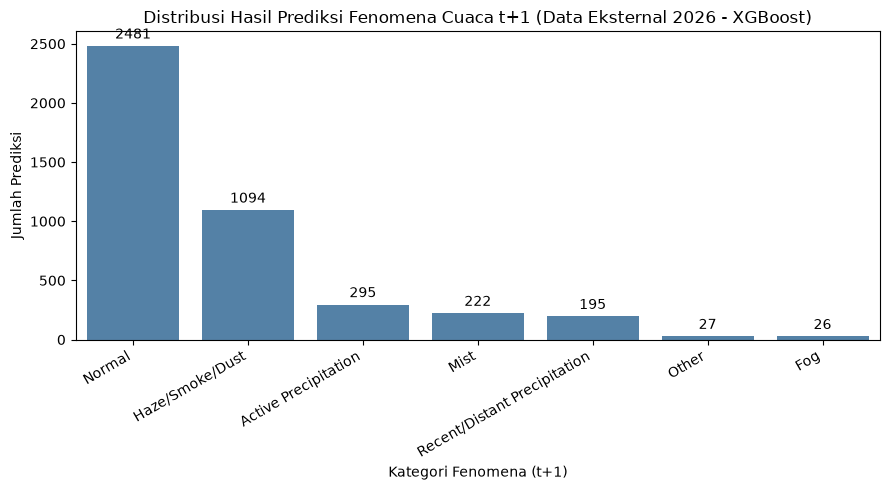

In [326]:
plt.figure(figsize=(9, 5))
order_labels = ext_eval['predicted_phenomenon'].value_counts().index
ax = sns.countplot(
    data=ext_eval,
    x='predicted_phenomenon',
    order=order_labels,
    color='steelblue'
)
plt.title('Distribusi Hasil Prediksi Fenomena Cuaca t+1 (Data Eksternal 2026 - XGBoost)')
plt.xlabel('Kategori Fenomena (t+1)')
plt.ylabel('Jumlah Prediksi')
plt.xticks(rotation=30, ha='right')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

**Notes:**

- Dari total `4.340` observasi eksternal, model utama **XGBoost** memprediksi kelas mayoritas `Normal` sebanyak `2.481` kali (`57,17%`), lebih rendah dibandingkan frekuensi aktualnya pada $t+1$ sebesar `2.804` observasi (`64,61%`).
- Sebaliknya, model cenderung memprediksi lebih banyak pada kelas `Haze/Smoke/Dust` (`1.094` prediksi / `25,21%` vs aktual `763` / `17,58%`) dan `Mist` (`222` prediksi / `5,12%` vs aktual `170` / `3,92%`). Pola ini dipengaruhi oleh dua faktor utama:
  1. Penerapan pembobotan kelas seimbang (`sample_weight` berbasis proporsi kelas latih) selama pelatihan yang meningkatkan sensitivitas model terhadap kelas non-`Normal`.
  2. Pergeseran distribusi musiman (*distribution shift*), karena model dilatih pada data tahun `2025` dengan proporsi `Haze/Smoke/Dust` yang jauh lebih tinggi (`30,99%`), sedangkan periode eksternal `Januari–Juni 2026` didominasi cuaca cerah/berawan (`Normal`).
- Pada kelompok hujan dan kelas minoritas, total prediksi berada sangat dekat dengan frekuensi aktualnya pada $t+1$, yakni `Active Precipitation` (`295` prediksi / `6,80%` vs `322` aktual / `7,42%`), `Recent/Distant Precipitation` (`195` prediksi / `4,49%` vs `188` aktual / `4,33%`), dan `Fog` (`26` prediksi / `0,60%` vs `25` aktual / `0,58%`), sedangkan `Other` diprediksi sebanyak `27` kali (`0,62%` vs `68` aktual / `1,57%`). Ketepatan kecocokan per observasi dievaluasi secara rinci pada sub-bab berikutnya.

## 13.7 Evaluasi Performa pada Data Eksternal

Mengevaluasi ketepatan prediksi model utama **XGBoost** pada `4.340` observasi eksternal (`Januari–Juni 2026`) terhadap label aktual `1` jam ke depan (`y_external`). Evaluasi mencakup perbandingan metrik keseluruhan (*Accuracy*, *Macro F1-Score*, dan *Balanced Accuracy*) terhadap performa pada data uji internal (`Internal Test Set 2025`) maupun acuan operasional *Persistence Baseline* pada periode eksternal, laporan klasifikasi per kelas (*Classification Report*), serta matriks kebingungan (*Confusion Matrix*) untuk seluruh `7` kelas fenomena.

In [327]:
n_classes = len(label_map)
class_labels = list(range(n_classes))
class_names = [inv_label_map[i] for i in range(n_classes)]

**Evaluasi XGBoost pada External Validation 2026**

In [328]:
ext_acc = accuracy_score(y_external, ext_pred)
ext_macro_f1 = f1_score(y_external, ext_pred, labels=class_labels, average='macro', zero_division=0)
ext_bal_acc = balanced_accuracy_score(y_external, ext_pred)

**Evaluasi Persistence Baseline pada External Validation 2026**

In [329]:
now_cols = ['now_' + inv_label_map[i].replace('/', '_').replace(' ', '_') for i in range(n_classes)]
ext_pers_pred = X_external[now_cols].values.argmax(axis=1)
ext_pers_acc = accuracy_score(y_external, ext_pers_pred)
ext_pers_macro_f1 = f1_score(y_external, ext_pers_pred, labels=class_labels, average='macro', zero_division=0)
ext_pers_bal_acc = balanced_accuracy_score(y_external, ext_pers_pred)

**Evaluasi XGBoost pada Internal Test Set 2025**

In [330]:
y_pred_xgb_test = test_predictions['XGBoost']
int_acc = accuracy_score(y_test, y_pred_xgb_test)
int_macro_f1 = f1_score(y_test, y_pred_xgb_test, labels=class_labels, average='macro', zero_division=0)
int_bal_acc = balanced_accuracy_score(y_test, y_pred_xgb_test)

In [331]:
ext_summary_df = pd.DataFrame([
    {
        'Dataset / Model': f'Internal Test Set - XGBoost (2025, n={len(y_test)})',
        'Accuracy': int_acc,
        'Macro F1': int_macro_f1,
        'Balanced Accuracy': int_bal_acc
    },
    {
        'Dataset / Model': f'External Validation - XGBoost (Jan–Jun 2026, n={len(y_external)})',
        'Accuracy': ext_acc,
        'Macro F1': ext_macro_f1,
        'Balanced Accuracy': ext_bal_acc
    },
    {
        'Dataset / Model': f'External Validation - Persistence (Jan–Jun 2026, n={len(y_external)})',
        'Accuracy': ext_pers_acc,
        'Macro F1': ext_pers_macro_f1,
        'Balanced Accuracy': ext_pers_bal_acc
    }
]).set_index('Dataset / Model')

display(ext_summary_df.round(4))

,Accuracy,Macro F1,Balanced Accuracy
Dataset / Model,,,
"Internal Test Set - XGBoost (2025, n=1776)",0.7044,0.5056,0.5027
"External Validation - XGBoost (Jan–Jun 2026, n=4340)",0.7364,0.4785,0.4958
"External Validation - Persistence (Jan–Jun 2026, n=4340)",0.7535,0.4732,0.4730


**Classification Report**

In [332]:
print("Classification Report - External Validation 2026 (XGBoost)")
print(classification_report(
    y_external,
    ext_pred,
    labels=class_labels,
    target_names=class_names,
    zero_division=0,
    digits=4
))

Classification Report - External Validation 2026 (XGBoost)
                              precision    recall  f1-score   support

        Active Precipitation     0.5254    0.4814    0.5024       322
                         Fog     0.3077    0.3200    0.3137        25
             Haze/Smoke/Dust     0.5320    0.7628    0.6268       763
                        Mist     0.4640    0.6059    0.5255       170
                      Normal     0.9133    0.8081    0.8575      2804
                       Other     0.2222    0.0882    0.1263        68
Recent/Distant Precipitation     0.3897    0.4043    0.3969       188

                    accuracy                         0.7364      4340
                   macro avg     0.4792    0.4958    0.4785      4340
                weighted avg     0.7629    0.7364    0.7431      4340



**Confusion Matrix**

In [333]:
cm_ext = confusion_matrix(
    y_external,
    ext_pred,
    labels=class_labels
)

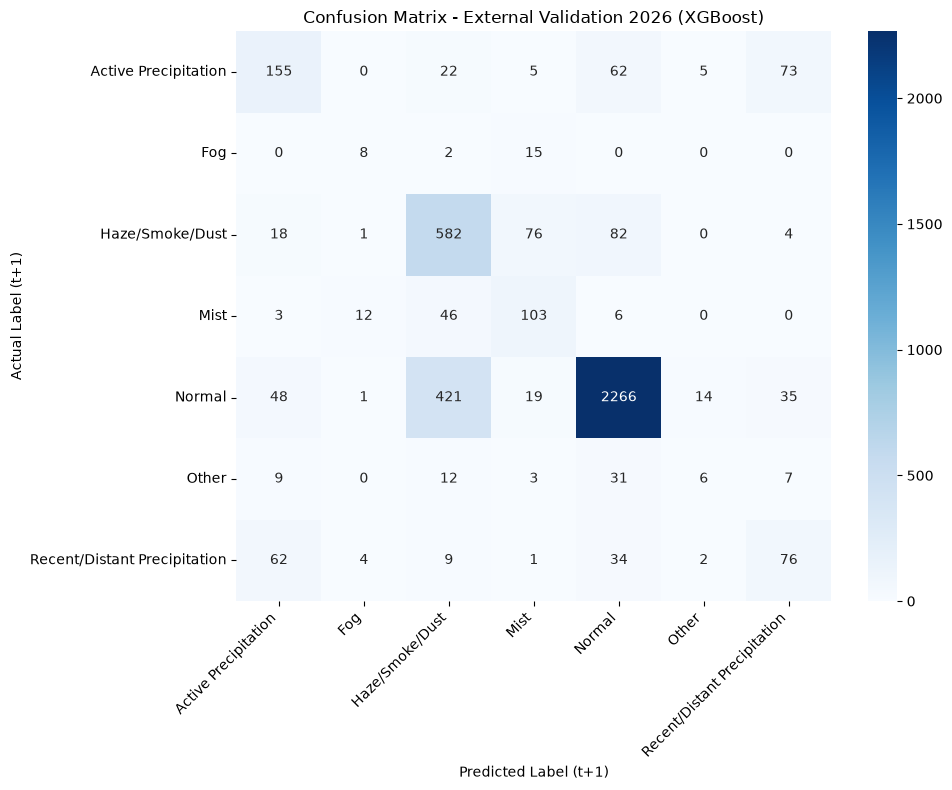

In [334]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_ext,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - External Validation 2026 (XGBoost)')
plt.xlabel('Predicted Label (t+1)')
plt.ylabel('Actual Label (t+1)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [335]:
cm_ext_df = pd.DataFrame(
    cm_ext,
    index=class_names,
    columns=class_names
)
cm_ext_df.index.name = 'Actual (t+1)'
cm_ext_df.columns.name = 'Predicted (t+1)'
display(cm_ext_df)

Predicted (t+1),Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual (t+1),,,,,,,
Active Precipitation,155,0,22,5,62,5,73
Fog,0,8,2,15,0,0,0
Haze/Smoke/Dust,18,1,582,76,82,0,4
Mist,3,12,46,103,6,0,0
Normal,48,1,421,19,2266,14,35
Other,9,0,12,3,31,6,7
Recent/Distant Precipitation,62,4,9,1,34,2,76


**Notes:**

- **Ketahanan Generalisasi Lintas Tahun (`2025` ke `2026`) dan Keunggulan atas *Persistence*:** Tanpa pelatihan ulang (*zero retraining*), model utama **XGBoost** (`59` fitur) mempertahankan kinerja yang konsisten pada data eksternal `Januari–Juni 2026` (`4.340` observasi), dengan *Balanced Accuracy* sebesar `0,4958` (hanya terpaut `-0,0069` dari uji internal tahun `2025` sebesar `0,5027`), *Macro F1-Score* sebesar `0,4785`, dan *Accuracy* meningkat menjadi `0,7364` (`3.196` prediksi tepat dari `4.340` observasi, naik dari `0,7044` pada uji internal). Dibandingkan *Persistence Baseline* pada periode eksternal yang sama, **XGBoost** tetap unggul pada kedua metrik keseimbangan multikelas (*Macro F1* `0,4785` vs `0,4732` dan *Balanced Accuracy* `0,4958` vs `0,4730`), sementara *Accuracy* *Persistence* lebih tinggi (`0,7535`) semata karena tingginya proporsi kelas dominan `Normal` (`64,61%`) pada semester pertama `2026`.
- **Peningkatan Kinerja pada Kelas Utama dan Kelas Langka (`Normal`, `Active Precipitation`, & `Other`):**
  - **`Normal` (`2.804` sampel):** Meraih *precision* sangat tinggi sebesar `0,9133` (*recall* `0,8081`, *F1-Score* meningkat dari `0,8050` menjadi `0,8575`), menunjukkan tingkat kepercayaan yang sangat tinggi ketika model memprediksi kondisi cuaca normal pada $t+1$.
  - **`Active Precipitation` (`322` sampel):** *F1-Score* meningkat dibandingkan uji internal `2025` dari `0,4527` menjadi `0,5024` (*precision* `0,5254`, *recall* `0,4814`), membuktikan efektivitas fitur riwayat waktu (`lag1–lag3`) dan laju perubahan ($\Delta$) dalam menangkap pembentukan hujan aktif.
  - **`Other` (`68` sampel):** *F1-Score* meningkat dari `0,0952` menjadi `0,1263` (*precision* `0,2222`, *recall* `0,0882`), dengan `6` observasi berhasil dikenali secara tepat.
- **Pola Kesalahan Klasifikasi Utama pada *Confusion Matrix*:**
  - **Pergeseran `Normal` ke `Haze/Smoke/Dust` (`421` observasi):** Merupakan sumber kesalahan terbesar pada data eksternal, yang dipicu oleh kombinasi pembobotan kelas seimbang selama pelatihan serta pergeseran distribusi musiman (*distribution shift*) antara data latih `2025` (proporsi `Haze/Smoke/Dust` `30,99%`) dan data eksternal `Januari–Juni 2026` (`17,58%`).
  - **Transisi Kelompok Hujan (`Active Precipitation` $\leftrightarrow$ `Recent/Distant Precipitation`):** Sebanyak `73` dari `322` observasi `Active Precipitation` terprediksi sebagai `Recent/Distant Precipitation` dan `62` sebagai `Normal`, sedangkan `62` dari `188` observasi `Recent/Distant Precipitation` terprediksi sebagai `Active Precipitation` (`76` tepat / *recall* `0,4043`), mencerminkan kemiripan kondisi atmosfer permukaan sesaat sebelum dan sesudah hujan berlangsung.
  - **Batas Visibilitas `Fog` (`25` sampel) dan `Mist` (`170` sampel):** Model mengenali `8` dari `25` kejadian `Fog` (*F1-Score* `0,3137`) dan `103` dari `170` kejadian `Mist` (*F1-Score* `0,5255`). Seluruh kesalahan pada `Fog` bergeser ke `Mist` (`15` sampel) dan `Haze/Smoke/Dust` (`2` sampel) tanpa satu pun tertukar ke `Normal` maupun hujan, karena perbedaan `Fog` dan `Mist` hanya terletak pada ambang jarak pandang `< 1.000 m` vs `≥ 1.000 m`.

## 13.8 Misclassification Analysis

Menganalisis kasus kesalahan prediksi (*misclassification*) model utama **XGBoost** pada `4.340` observasi eksternal (`Januari–Juni 2026`) untuk mengidentifikasi pasangan kelas aktual ($t+1$) dan prediksi yang paling sering tertukar, serta membandingkan karakteristik parameter meteorologi antara observasi yang terprediksi tepat dan yang mengalami kesalahan klasifikasi.

**Filter seluruh observasi eksternal yang salah diprediksi**

In [336]:
misclassified = ext_eval[
    ext_eval['target_encoded'] != ext_eval['predicted_code']
].copy()

In [337]:
total_obs = len(ext_eval)
total_err = len(misclassified)
print(f"Total observasi eksternal : {total_obs}")
print(f"Jumlah prediksi tepat     : {total_obs - total_err} ({(total_obs - total_err) / total_obs * 100:.2f}%)")
print(f"Jumlah prediksi salah     : {total_err} ({total_err / total_obs * 100:.2f}%)")

Total observasi eksternal : 4340
Jumlah prediksi tepat     : 3196 (73.64%)
Jumlah prediksi salah     : 1144 (26.36%)


In [338]:
display(
    misclassified[[
        'datetime_wib', 'phenomenon', 'target_phenomenon', 'predicted_phenomenon',
        'visibility_vv', 'relative_humidity_pc', 'cloud_low_cover_oktas'
    ]].head(15)
)

,datetime_wib,phenomenon,target_phenomenon,predicted_phenomenon,visibility_vv,relative_humidity_pc,cloud_low_cover_oktas
9,2026-01-01 19:00:00,Normal,Haze/Smoke/Dust,Normal,9.0,81.0,3
10,2026-01-01 20:00:00,Haze/Smoke/Dust,Normal,Haze/Smoke/Dust,8.0,84.0,4
11,2026-01-01 21:00:00,Normal,Haze/Smoke/Dust,Normal,10.0,86.0,2
15,2026-01-02 01:00:00,Haze/Smoke/Dust,Active Precipitation,Haze/Smoke/Dust,5.0,91.0,4
31,2026-01-02 17:00:00,Normal,Haze/Smoke/Dust,Normal,10.0,81.0,5
32,2026-01-02 18:00:00,Haze/Smoke/Dust,Active Precipitation,Haze/Smoke/Dust,5.0,84.0,5
40,2026-01-03 02:00:00,Active Precipitation,Recent/Distant Precipitation,Active Precipitation,10.0,96.0,5
42,2026-01-03 04:00:00,Normal,Active Precipitation,Normal,10.0,96.0,5
46,2026-01-03 08:00:00,Normal,Active Precipitation,Normal,10.0,94.0,5
47,2026-01-03 09:00:00,Active Precipitation,Recent/Distant Precipitation,Active Precipitation,10.0,92.0,5


**Rekap pasangan kesalahan klasifikasi terbanyak**

In [339]:
error_distribution = (
    misclassified
    .groupby(['target_phenomenon', 'predicted_phenomenon'])
    .size()
    .reset_index(name='Count')
    .sort_values('Count', ascending=False)
    .reset_index(drop=True)
)
error_distribution['Share of Errors (%)'] = (error_distribution['Count'] / total_err * 100).round(2)

display(error_distribution.head(15))

,target_phenomenon,predicted_phenomenon,Count,Share of Errors (%)
0,Normal,Haze/Smoke/Dust,421,36.80
1,Haze/Smoke/Dust,Normal,82,7.17
2,Haze/Smoke/Dust,Mist,76,6.64
3,Active Precipitation,Recent/Distant Precipitation,73,6.38
4,Recent/Distant Precipitation,Active Precipitation,62,5.42
5,Active Precipitation,Normal,62,5.42
6,Normal,Active Precipitation,48,4.20
7,Mist,Haze/Smoke/Dust,46,4.02
8,Normal,Recent/Distant Precipitation,35,3.06
9,Recent/Distant Precipitation,Normal,34,2.97


**Visualisasi 10 pasangan kesalahan terbanyak**

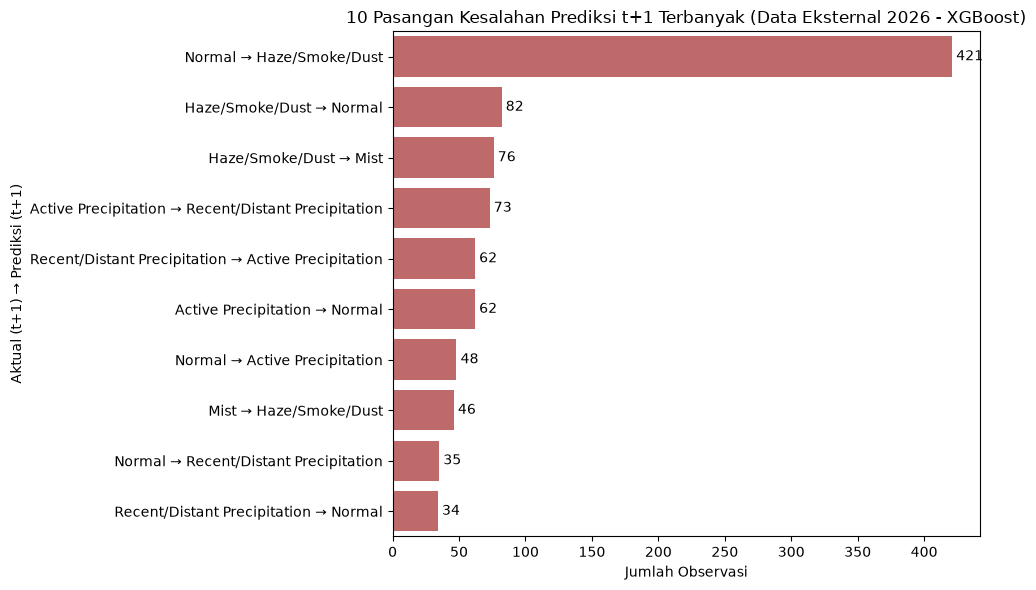

In [340]:
plt.figure(figsize=(10, 6))
top_errors = error_distribution.head(10).copy()
top_errors['Error Pair'] = top_errors['target_phenomenon'] + ' → ' + top_errors['predicted_phenomenon']

ax = sns.barplot(
    data=top_errors,
    x='Count',
    y='Error Pair',
    color='indianred'
)
plt.title('10 Pasangan Kesalahan Prediksi t+1 Terbanyak (Data Eksternal 2026 - XGBoost)')
plt.xlabel('Jumlah Observasi')
plt.ylabel('Aktual (t+1) → Prediksi (t+1)')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

**Karakteristik Meteorologi Kesalahan & Perbandingan Normal vs Haze/Smoke/Dust**

In [341]:
analysis_features = [
    'wind_dir_deg_dd',
    'wind_speed_ff',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'visibility_vv'
]

In [342]:
top_pairs_idx = error_distribution.head(10)[['target_phenomenon', 'predicted_phenomenon']]
error_characteristics = (
    misclassified
    .merge(top_pairs_idx, on=['target_phenomenon', 'predicted_phenomenon'])
    .groupby(['target_phenomenon', 'predicted_phenomenon'])[analysis_features]
    .mean()
    .round(2)
)
error_characteristics.index.names = ['Actual (t+1)', 'Predicted (t+1)']
print("Rata-rata Parameter Meteorologi (Waktu t) pada 10 Pasangan Kesalahan Terbanyak")
display(error_characteristics)

Rata-rata Parameter Meteorologi (Waktu t) pada 10 Pasangan Kesalahan Terbanyak


wind_dir_deg_dd  \
Actual (t+1)                 Predicted (t+1)                                 
Active Precipitation         Normal                                 195.23   
                             Recent/Distant Precipitation           190.25   
Haze/Smoke/Dust              Mist                                   138.01   
                             Normal                                 139.85   
Mist                         Haze/Smoke/Dust                        150.54   
Normal                       Active Precipitation                   234.62   
                             Haze/Smoke/Dust                        168.06   
                             Recent/Distant Precipitation           138.80   
Recent/Distant Precipitation Active Precipitation                   229.13   
                             Normal                                 183.38   

                                                           wind_speed_ff  \
Actual (t+1)                 Predicted (t+1)                               
Active Precipitation         Normal                                 4.26   
                             Recent/Distant Precipitation           3.99   
Haze/Smoke/Dust              Mist                                   1.41   
                             Normal                                 2.44   
Mist                         Haze/Smoke/Dust                        1.57   
Normal                       Active Precipitation                   3.96   
                             Haze/Smoke/Dust                        2.17   
                             Recent/Distant Precipitation           4.51   
Recent/Distant Precipitation Active Precipitation                   4.05   
                             Normal                                 4.29   

                                                           pressure_qff_mb_derived  \
Actual (t+1)                 Predicted (t+1)                                         
Active Precipitation         Normal                                        1009.66   
                             Recent/Distant Precipitation                  1009.08   
Haze/Smoke/Dust              Mist                                          1009.94   
                             Normal                                        1010.42   
Mist                         Haze/Smoke/Dust                               1009.81   
Normal                       Active Precipitation                          1009.53   
                             Haze/Smoke/Dust                               1010.08   
                             Recent/Distant Precipitation                  1008.11   
Recent/Distant Precipitation Active Precipitation                          1010.16   
                             Normal                                        1009.61   

                                                           temp_drybulb_c_tttttt  \
Actual (t+1)                 Predicted (t+1)                                       
Active Precipitation         Normal                                        29.01   
                             Recent/Distant Precipitation                  26.68   
Haze/Smoke/Dust              Mist                                          25.20   
                             Normal                                        26.90   
Mist                         Haze/Smoke/Dust                               25.37   
Normal                       Active Precipitation                          26.44   
                             Haze/Smoke/Dust                               26.21   
                             Recent/Distant Precipitation                  28.92   
Recent/Distant Precipitation Active Precipitation                          25.51   
                             Normal                                        29.59   

                                                           temp_dewpoint_c_tdtdtd  \
Actual (t+1)                 Predicted (t+1)                                      

**Perbandingan mendalam kesalahan terbesar: Normal (Benar) vs Normal (Salah diprediksi Haze/Smoke/Dust)**

In [343]:
normal_correct = ext_eval[
    (ext_eval['target_phenomenon'] == 'Normal') &
    (ext_eval['predicted_phenomenon'] == 'Normal')
]

In [344]:
normal_as_haze = ext_eval[
    (ext_eval['target_phenomenon'] == 'Normal') &
    (ext_eval['predicted_phenomenon'] == 'Haze/Smoke/Dust')
]

In [345]:
comparison_normal_df = pd.DataFrame({
    f'Normal - Correct (n={len(normal_correct)})': normal_correct[analysis_features].mean(),
    f'Normal - Predicted as Haze (n={len(normal_as_haze)})': normal_as_haze[analysis_features].mean()
}).round(2)
print("Perbandingan Karakteristik (Waktu t): Normal (Benar) vs Normal (Terprediksi Haze/Smoke/Dust)")
display(comparison_normal_df)

Perbandingan Karakteristik (Waktu t): Normal (Benar) vs Normal (Terprediksi Haze/Smoke/Dust)


,Normal - Correct (n=2266),Normal - Predicted as Haze (n=421)
wind_dir_deg_dd,178.40,168.06
wind_speed_ff,4.20,2.17
pressure_qff_mb_derived,1009.94,1010.08
temp_drybulb_c_tttttt,28.74,26.21
temp_dewpoint_c_tdtdtd,23.85,24.28
relative_humidity_pc,75.81,89.39
cloud_low_cover_oktas,3.18,2.74
cloud_med_cover_oktas,4.41,4.88
visibility_vv,9.73,6.40


**Boxplot 4 parameter utama pembeda**

In [346]:
normal_subset = ext_eval[
    (ext_eval['target_phenomenon'] == 'Normal') &
    (ext_eval['predicted_phenomenon'].isin(['Normal', 'Haze/Smoke/Dust']))
].copy()

In [347]:
normal_subset['Status Prediksi'] = normal_subset['predicted_phenomenon'].map({
    'Normal': 'Correct (Normal)',
    'Haze/Smoke/Dust': 'Misclassified as Haze/Smoke/Dust'
})

In [348]:
plot_features = [
    'visibility_vv',
    'relative_humidity_pc',
    'temp_drybulb_c_tttttt',
    'wind_speed_ff'
]

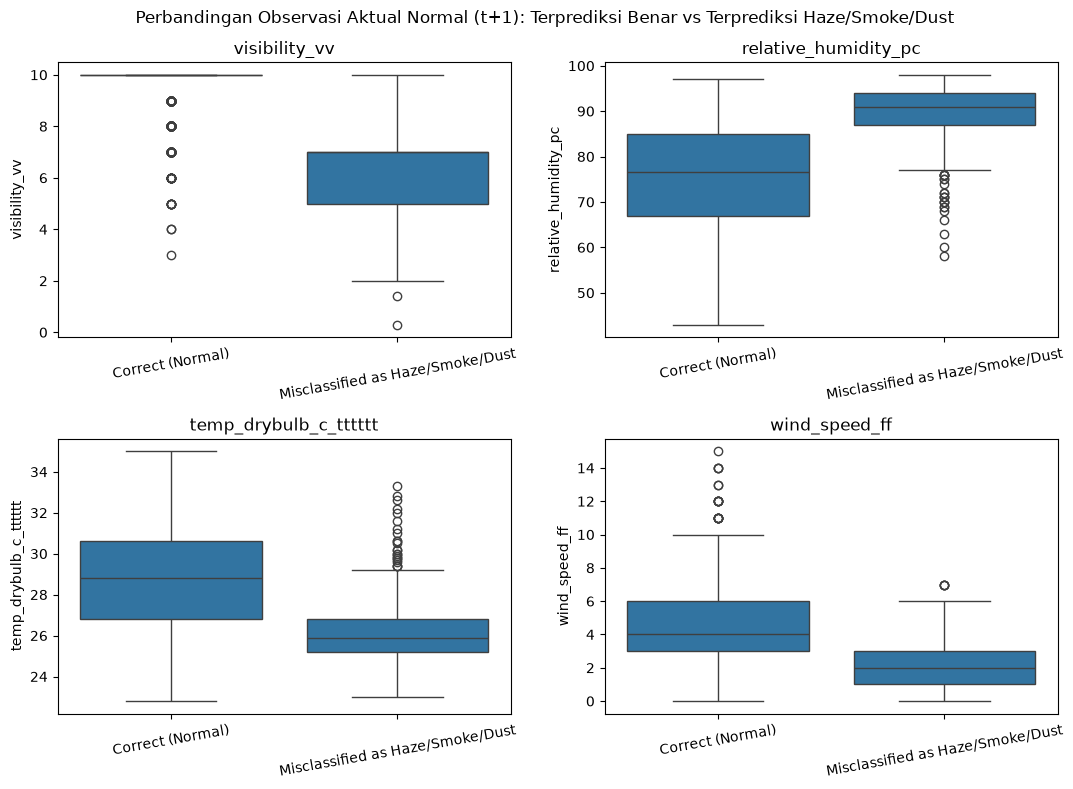

In [349]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.flat, plot_features):
    sns.boxplot(
        data=normal_subset,
        x='Status Prediksi',
        y=feat,
        ax=ax
    )
    ax.set_title(feat)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=10)

plt.suptitle('Perbandingan Observasi Aktual Normal (t+1): Terprediksi Benar vs Terprediksi Haze/Smoke/Dust', fontsize=12)
plt.tight_layout()
plt.show()

**Perbandingan 3 Profil untuk 4 pasangan kesalahan terbanyak dari error_distribution**

In [350]:
top_4_pairs = list(
    error_distribution.head(4)[['target_phenomenon', 'predicted_phenomenon']].itertuples(index=False, name=None)
)

In [351]:
for rank, (actual_cls, pred_cls) in enumerate(top_4_pairs, start=1):
    df_actual_correct = ext_eval[
        (ext_eval['target_phenomenon'] == actual_cls) &
        (ext_eval['predicted_phenomenon'] == actual_cls)
    ]
    df_misclassified = ext_eval[
        (ext_eval['target_phenomenon'] == actual_cls) &
        (ext_eval['predicted_phenomenon'] == pred_cls)
    ]
    df_pred_correct = ext_eval[
        (ext_eval['target_phenomenon'] == pred_cls) &
        (ext_eval['predicted_phenomenon'] == pred_cls)
    ]

    print("=" * 80)
    print(f"#{rank} Pasangan Kesalahan: {actual_cls} → {pred_cls} (n = {len(df_misclassified)})")
    print("=" * 80)

    comp_3way = pd.DataFrame({
        f'{actual_cls} - Correct (n={len(df_actual_correct)})': df_actual_correct[analysis_features].mean(),
        f'{actual_cls} → {pred_cls} (n={len(df_misclassified)})': df_misclassified[analysis_features].mean(),
        f'{pred_cls} - Correct (n={len(df_pred_correct)})': df_pred_correct[analysis_features].mean()
    }).round(2)

    display(comp_3way)

#1 Pasangan Kesalahan: Normal → Haze/Smoke/Dust (n = 421)


,Normal - Correct (n=2266),Normal → Haze/Smoke/Dust (n=421),Haze/Smoke/Dust - Correct (n=582)
wind_dir_deg_dd,178.40,168.06,154.07
wind_speed_ff,4.20,2.17,1.86
pressure_qff_mb_derived,1009.94,1010.08,1010.10
temp_drybulb_c_tttttt,28.74,26.21,26.08
temp_dewpoint_c_tdtdtd,23.85,24.28,24.28
relative_humidity_pc,75.81,89.39,90.10
cloud_low_cover_oktas,3.18,2.74,2.72
cloud_med_cover_oktas,4.41,4.88,4.94
visibility_vv,9.73,6.40,5.05


#2 Pasangan Kesalahan: Haze/Smoke/Dust → Normal (n = 82)


,Haze/Smoke/Dust - Correct (n=582),Haze/Smoke/Dust → Normal (n=82),Normal - Correct (n=2266)
wind_dir_deg_dd,154.07,139.85,178.40
wind_speed_ff,1.86,2.44,4.20
pressure_qff_mb_derived,1010.10,1010.42,1009.94
temp_drybulb_c_tttttt,26.08,26.90,28.74
temp_dewpoint_c_tdtdtd,24.28,24.09,23.85
relative_humidity_pc,90.10,84.98,75.81
cloud_low_cover_oktas,2.72,2.52,3.18
cloud_med_cover_oktas,4.94,4.37,4.41
visibility_vv,5.05,9.46,9.73


#3 Pasangan Kesalahan: Haze/Smoke/Dust → Mist (n = 76)


,Haze/Smoke/Dust - Correct (n=582),Haze/Smoke/Dust → Mist (n=76),Mist - Correct (n=103)
wind_dir_deg_dd,154.07,138.01,189.15
wind_speed_ff,1.86,1.41,2.00
pressure_qff_mb_derived,1010.10,1009.94,1009.55
temp_drybulb_c_tttttt,26.08,25.20,24.93
temp_dewpoint_c_tdtdtd,24.28,24.33,24.22
relative_humidity_pc,90.10,94.99,95.83
cloud_low_cover_oktas,2.72,2.95,2.76
cloud_med_cover_oktas,4.94,4.53,5.79
visibility_vv,5.05,3.68,3.02


#4 Pasangan Kesalahan: Active Precipitation → Recent/Distant Precipitation (n = 73)


,Active Precipitation - Correct (n=155),Active Precipitation → Recent/Distant Precipitation (n=73),Recent/Distant Precipitation - Correct (n=76)
wind_dir_deg_dd,199.72,190.25,189.76
wind_speed_ff,4.48,3.99,3.71
pressure_qff_mb_derived,1010.73,1009.08,1009.23
temp_drybulb_c_tttttt,25.03,26.68,27.22
temp_dewpoint_c_tdtdtd,23.61,24.29,24.40
relative_humidity_pc,92.26,87.44,85.30
cloud_low_cover_oktas,5.50,4.73,4.47
cloud_med_cover_oktas,6.89,6.53,6.17
visibility_vv,5.25,7.35,7.92


**Notes:**

- Dari total `4.340` observasi eksternal (`Januari–Juni 2026`), model utama **XGBoost** (`59` fitur) memprediksi fenomena cuaca `1` jam ke depan ($t+1$) secara tepat pada `3.196` observasi (`73,64%`) dan menghasilkan `1.144` kesalahan prediksi (`26,36%`). Sebanyak `56,99%` (`652` kasus) dari seluruh kesalahan terpusat pada empat pasangan fenomena berikut:
  1. **`Normal` ($t+1$) terprediksi sebagai `Haze/Smoke/Dust` (`421` observasi / `36,80%`):** Pada waktu pengamatan $t$, profil atmosfer observasi yang salah terprediksi ini sudah bergeser sangat mendekati profil `Haze/Smoke/Dust - Correct` dibandingkan `Normal - Correct`—yakni jarak pandang menurun dari `9,73 km` menjadi `6,40 km` (mendekati `5,05 km`), kelembapan relatif meningkat dari `75,81%` menjadi `89,39%` (mendekati `90,10%`), suhu bola kering turun dari `28,74 °C` menjadi `26,21 °C` (mendekati `26,08 °C`), dan kecepatan angin melemah dari `4,20 knot` menjadi `2,17 knot` (mendekati `1,86 knot`). Kondisi udara tenang dan lembap dengan visibilitas menurun pada waktu $t$ membuat model memprediksi `Haze/Smoke/Dust` untuk $t+1$, meskipun pada jam berikutnya ($t+1$) jarak pandang kembali pulih ke kategori `Normal` (diperkuat oleh pembobotan kelas seimbang serta *distribution shift* dari tahun `2025` ke `2026`).
  2. **`Haze/Smoke/Dust` ($t+1$) terprediksi sebagai `Normal` (`82` observasi / `7,17%`):** Merupakan kebalikan dari pola pertama, yakni ketika kejadian `Haze/Smoke/Dust` muncul secara mendadak pada $t+1$ setelah kondisi atmosfer pada waktu $t$ masih menyerupai `Normal - Correct`—dengan jarak pandang tinggi di angka `9,46 km` (vs `9,73 km`), suhu udara hangat `26,90 °C`, kelembapan relatif lebih rendah (`84,98%` vs `90,10%` pada `Haze/Smoke/Dust - Correct`), serta kecepatan angin `2,44 knot`.
  3. **`Haze/Smoke/Dust` ($t+1$) terprediksi sebagai `Mist` (`76` observasi / `6,64%`):** Terjadi ketika fenomena `Haze/Smoke/Dust` berlangsung pada kondisi udara yang hampir jenuh uap air pada waktu $t$, dengan rata-rata kelembapan relatif mencapai `94,99%` (hampir identik dengan `Mist - Correct` sebesar `95,83%`), suhu udara sejuk `25,20 °C` (vs `24,93 °C`), angin tenang `1,41 knot`, serta jarak pandang menyusut ke `3,68 km` (mendekati rata-rata `Mist` sebesar `3,02 km`), sehingga sinyal fisik permukaan sulit dibedakan antara kabut tipis (*mist*) dan kabut/asap (*haze/smoke*).
  4. **`Active Precipitation` ($t+1$) terprediksi sebagai `Recent/Distant Precipitation` (`73` observasi / `6,38%`):** Terjadi pada fase awal pembentukan hujan konvektif, di mana pada waktu $t$ hujan belum turun langsung di lokasi stasiun sehingga profil parameternya menyerupai `Recent/Distant Precipitation - Correct`—yakni jarak pandang masih cukup baik di angka `7,35 km` (vs `7,92 km`, jauh di atas `Active Precipitation - Correct` sebesar `5,25 km`), suhu udara masih hangat `26,68 °C` (vs `27,22 °C`), kelembapan relatif `87,44%` (vs `85,30%`), dan tutupan awan rendah `4,73 oktas` (vs `4,47 oktas`), sebelum berkembang menjadi hujan aktif dalam selang `1` jam berikutnya ($t+1$).
- Secara keseluruhan, analisis ini menegaskan bahwa mayoritas kesalahan prediksi $t+1$ bukan merupakan kesalahan acak, melainkan bersumber dari pergeseran distribusi musiman antarperiode (`2025` ke `2026`) serta tumpang tindih karakteristik parameter meteorologi permukaan (*feature overlap*) pada fase transisi sebelum dan sesudah perubahan cuaca dalam rentang `1` jam.

# 14. Model Saving and Deployment Preparation

Tahap ini mempersiapkan model klasifikasi terpilih (**XGBoost** hasil *hyperparameter tuning*) agar siap diintegrasikan ke dalam aplikasi web untuk memprediksi fenomena meteorologi `1` jam ke depan ($t+1$). Proses meliputi penyiapan objek model dan komponen pendukung, pembuatan fungsi transformasi `59` fitur untuk data hasil *decoding* SYNOP beserta riwayat `3` jam terakhir, pengujian konsistensi fitur terhadap data uji, penyimpanan artefak model ke dalam file `weather_phenomena_xgb_1h.joblib`, serta pengujian pemuatan ulang dan inferensi model.

## 14.1 Preparing Model Components

Menyiapkan komponen inti yang dibutuhkan pada tahap inferensi, yaitu model utama **XGBoost** hasil *hyperparameter tuning* (`deploy_model`), daftar `59` fitur masukan sesuai urutan pelatihan (`selected_features`), serta kamus pemetaan `7` kelas fenomena (`label_map` dan `inv_label_map`).

In [385]:
final_xgb = search_results['XGBoost'].best_estimator_

**Ambil estimator XGBClassifier yang sudah terlatih (_Booster tidak None) dari dalam wrapper**

In [386]:
fitted_inner = [
    v for v in vars(final_xgb).values()
    if hasattr(v, 'predict') and getattr(v, '_Booster', None) is not None
]
deploy_model = fitted_inner[0] if fitted_inner else final_xgb

In [387]:
_ = deploy_model.predict(X_train.iloc[:1])

In [388]:
selected_features = list(X_train.columns)

In [389]:
print("Model            :", type(deploy_model).__name__)
print("Jumlah fitur     :", len(selected_features))
print("Contoh 15 fitur  :", selected_features[:15])
print("7 fitur terakhir :", selected_features[-7:])
print("Label mapping    :", label_map)

Model            : XGBClassifier
Jumlah fitur     : 59
Contoh 15 fitur  : ['wind_speed_ff', 'wind_dir_sin', 'wind_dir_cos', 'is_calm', 'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'relative_humidity_pc', 'cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'visibility_vv', 'hour_sin', 'hour_cos', 'wind_dir_sin_lag1', 'wind_dir_sin_lag2']
7 fitur terakhir : ['now_Active_Precipitation', 'now_Fog', 'now_Haze_Smoke_Dust', 'now_Mist', 'now_Normal', 'now_Other', 'now_Recent_Distant_Precipitation']
Label mapping    : {'Active Precipitation': 0, 'Fog': 1, 'Haze/Smoke/Dust': 2, 'Mist': 3, 'Normal': 4, 'Other': 5, 'Recent/Distant Precipitation': 6}


## 14.2 Building Feature Engineering Function

Membuat fungsi `build_features()` untuk mengolah satu baris data observasi hasil *decoding* sandi SYNOP pada waktu $t$ (beserta riwayat observasi `3` jam sebelumnya jika tersedia) menjadi `59` fitur numerik yang dibutuhkan oleh model **XGBoost**. Fungsi ini memvalidasi kelengkapan parameter masukan, mengonversi waktu observasi dari UTC ke WIB (`Asia/Jakarta`), membentuk fitur siklikal waktu dan arah angin, indikator angin tenang (`is_calm`), `30` fitur riwayat waktu (`lag1–lag3`), `9` fitur laju perubahan ($\Delta$), serta `7` fitur biner kondisi cuaca saat ini (`now_*`), lalu menyusun urutan kolom tepat sama dengan `selected_features`.

In [390]:
def _parse_to_wib(ts_val, input_timezone='UTC'):
    ts = pd.Timestamp(ts_val)
    if ts.tzinfo is None:
        ts = ts.tz_localize(input_timezone)
    return ts.tz_convert('Asia/Jakarta')


def _map_ww_to_phenomenon(ww):
    ww = int(float(ww))
    if ww in [0, 1, 2, 3]:
        return 'Normal'
    elif ww in [4, 5, 6, 7, 8, 9, 30, 31, 32, 33, 34, 35]:
        return 'Haze/Smoke/Dust'
    elif ww == 10:
        return 'Mist'
    elif ww in [11, 12] or (40 <= ww <= 49):
        return 'Fog'
    elif ww in [14, 15, 16] or (20 <= ww <= 29):
        return 'Recent/Distant Precipitation'
    elif 50 <= ww <= 99:
        return 'Active Precipitation'
    else:
        return 'Other'


def _compute_base_row(row_series, input_timezone='UTC'):
    dt_wib = _parse_to_wib(row_series['data_timestamp'], input_timezone=input_timezone)
    hour = dt_wib.hour
    wind_speed = float(row_series['wind_speed_ff'])
    wind_dir = float(row_series['wind_dir_deg_dd'])

    return {
        'datetime_wib': dt_wib,
        'wind_speed_ff': wind_speed,
        'wind_dir_sin': float(np.sin(np.deg2rad(wind_dir))),
        'wind_dir_cos': float(np.cos(np.deg2rad(wind_dir))),
        'is_calm': int(wind_speed == 0),
        'pressure_qff_mb_derived': float(row_series['pressure_qff_mb_derived']),
        'temp_drybulb_c_tttttt': float(row_series['temp_drybulb_c_tttttt']),
        'temp_dewpoint_c_tdtdtd': float(row_series['temp_dewpoint_c_tdtdtd']),
        'relative_humidity_pc': float(row_series['relative_humidity_pc']),
        'cloud_low_cover_oktas': int(row_series['cloud_low_cover_oktas']),
        'cloud_med_cover_oktas': int(row_series['cloud_med_cover_oktas']),
        'visibility_vv': float(row_series['visibility_vv']),
        'hour_sin': float(np.sin(2 * np.pi * hour / 24)),
        'hour_cos': float(np.cos(2 * np.pi * hour / 24))
    }


def build_features(data, history_df=None, input_timezone='UTC'):
    """
    Mengolah satu baris data observasi hasil decoding SYNOP (dan riwayat 3 jam
    sebelumnya jika tersedia) menjadi 59 fitur terurut sesuai kebutuhan model XGBoost.

    Parameters
    ----------
    data : pandas.Series atau dict
        Satu baris observasi meteorologi pada waktu t (memuat 'present_weather_ww'
        atau 'phenomenon' beserta parameter meteorologi inti).
    history_df : pandas.DataFrame, optional
        DataFrame berisi observasi jam-jam sebelumnya (t-3, t-2, t-1).
        Jika None, fitur lag dan delta diisi np.nan (didukung bawaan XGBoost).
    input_timezone : str, default='UTC'
        Zona waktu timestamp input.

    Returns
    -------
    pandas.DataFrame
        DataFrame 1 baris dengan 59 fitur terurut sesuai selected_features.
    """
    data = pd.Series(data)

    required_columns = [
        'data_timestamp',
        'wind_speed_ff',
        'wind_dir_deg_dd',
        'pressure_qff_mb_derived',
        'temp_drybulb_c_tttttt',
        'temp_dewpoint_c_tdtdtd',
        'relative_humidity_pc',
        'cloud_low_cover_oktas',
        'cloud_med_cover_oktas',
        'visibility_vv'
    ]

    missing_columns = [col for col in required_columns if col not in data.index]
    if missing_columns:
        raise ValueError(f"Kolom belum tersedia: {missing_columns}")

    if data[required_columns].isna().any():
        raise ValueError("Data observasi belum lengkap. Periksa kembali parameter yang kosong.")

    # Tentukan kategori fenomena saat ini (t) dari 'phenomenon' atau kode 'present_weather_ww'
    if 'phenomenon' in data.index and pd.notna(data['phenomenon']):
        curr_phenom = str(data['phenomenon'])
        if curr_phenom not in label_map:
            raise ValueError(f"Kategori fenomena tidak dikenal: {curr_phenom}")
    elif 'present_weather_ww' in data.index and pd.notna(data['present_weather_ww']):
        curr_phenom = _map_ww_to_phenomenon(data['present_weather_ww'])
    else:
        raise ValueError("Kolom 'present_weather_ww' atau 'phenomenon' belum tersedia atau kosong.")

    # 1. Hitung 13 fitur dasar pada waktu t
    curr = _compute_base_row(data, input_timezone=input_timezone)
    curr_time = curr['datetime_wib']
    features = {k: v for k, v in curr.items() if k != 'datetime_wib'}

    # 2. Petakan observasi riwayat berdasarkan timestamp WIB
    hist_by_time = {}
    if history_df is not None and len(history_df) > 0:
        for _, h_row in history_df.iterrows():
            if not h_row[required_columns].isna().any():
                h_base = _compute_base_row(h_row, input_timezone=input_timezone)
                hist_by_time[h_base['datetime_wib']] = h_base

    # 3. Bentuk 30 fitur riwayat waktu (lag1, lag2, lag3)
    lag_bases = [
        'wind_dir_sin',
        'wind_dir_cos',
        'wind_speed_ff',
        'visibility_vv',
        'pressure_qff_mb_derived',
        'temp_drybulb_c_tttttt',
        'temp_dewpoint_c_tdtdtd',
        'relative_humidity_pc',
        'cloud_low_cover_oktas',
        'cloud_med_cover_oktas'
    ]

    for lag in [1, 2, 3]:
        target_ts = curr_time - pd.Timedelta(hours=lag)
        hist_row = hist_by_time.get(target_ts)
        for col in lag_bases:
            features[f'{col}_lag{lag}'] = hist_row[col] if hist_row is not None else np.nan

    # 4. Bentuk 9 fitur laju perubahan (Delta 1 jam dan 3 jam)
    delta_specs = [
        ('visibility_diff_1', 'visibility_vv', 1),
        ('visibility_diff_3', 'visibility_vv', 3),
        ('temp_drybulb_diff_1', 'temp_drybulb_c_tttttt', 1),
        ('temp_drybulb_diff_3', 'temp_drybulb_c_tttttt', 3),
        ('rh_diff_1', 'relative_humidity_pc', 1),
        ('rh_diff_3', 'relative_humidity_pc', 3),
        ('pressure_diff_1', 'pressure_qff_mb_derived', 1),
        ('pressure_diff_3', 'pressure_qff_mb_derived', 3),
        ('wind_speed_diff_1', 'wind_speed_ff', 1)
    ]

    for new_col, base_col, step in delta_specs:
        target_ts = curr_time - pd.Timedelta(hours=step)
        hist_row = hist_by_time.get(target_ts)
        features[new_col] = (curr[base_col] - hist_row[base_col]) if hist_row is not None else np.nan

    # 5. Bentuk 7 fitur one-hot kondisi cuaca saat ini (t)
    for phenom_name in label_map.keys():
        col_name = 'now_' + phenom_name.replace('/', '_').replace(' ', '_')
        features[col_name] = int(curr_phenom == phenom_name)

    return pd.DataFrame([features])[selected_features]

## 14.3 Feature Consistency Testing

Menguji fungsi `build_features()` menggunakan satu sampel observasi dari data uji beserta riwayat `3` jam sebelumnya, lalu membandingkannya secara langsung dengan baris yang bersesuaian pada `X_test` untuk memastikan nama kolom, urutan ke-`59` fitur, serta presisi nilai numeriknya identik.

In [391]:
source_all_df = clean_df.sort_values('data_timestamp').reset_index(drop=True)

**Ambil satu sampel observasi dari data uji beserta 3 observasi jam sebelumnya**

In [392]:
valid_test_indices = [
    idx for idx in X_test.index
    if idx >= 3 and (
        source_all_df.loc[idx, 'data_timestamp'] - source_all_df.loc[idx - 3, 'data_timestamp']
        == pd.Timedelta(hours=3)
    )
]
sample_idx = valid_test_indices[0]
sample = source_all_df.loc[sample_idx]

In [393]:
history_3h = source_all_df[
    (source_all_df['data_timestamp'] < sample['data_timestamp']) &
    (source_all_df['data_timestamp'] >= sample['data_timestamp'] - pd.Timedelta(hours=3))
]

In [394]:
print("Timestamp sample        :", sample['data_timestamp'])
print("Jumlah baris history_3h :", len(history_3h))

Timestamp sample        : 2025-01-03 17:00:00
Jumlah baris history_3h : 3


**Bentuk 59 fitur menggunakan fungsi deployment**

In [395]:
sample_features = build_features(sample, history_df=history_3h, input_timezone='UTC')

**Ambil baris fitur asli dari X_test sebagai pembanding**

In [396]:
original_features = X_test.loc[[sample_idx]]

In [397]:
print("Jumlah fitur dihasilkan :", sample_features.shape[1])
print("Urutan fitur sesuai     :", list(sample_features.columns) == list(original_features.columns))
print(
    "Nilai fitur sesuai      :",
    np.allclose(
        sample_features.to_numpy(dtype=float),
        original_features.to_numpy(dtype=float),
        rtol=1e-9,
        atol=1e-9
    )
)

Jumlah fitur dihasilkan : 59
Urutan fitur sesuai     : True
Nilai fitur sesuai      : True


In [398]:
comparison_features_df = pd.DataFrame({
    'Original (X_test)': original_features.iloc[0],
    'Generated (build_features)': sample_features.iloc[0]
})
display(comparison_features_df.head(20))

,Original (X_test),Generated (build_features)
wind_speed_ff,0.0,0.0
wind_dir_sin,0.0,0.0
wind_dir_cos,1.0,1.0
is_calm,1.0,1.0
pressure_qff_mb_derived,1010.0,1010.0
temp_drybulb_c_tttttt,25.2,25.2
temp_dewpoint_c_tdtdtd,24.4,24.4
relative_humidity_pc,95.0,95.0
cloud_low_cover_oktas,2.0,2.0
cloud_med_cover_oktas,5.0,5.0


## 14.4 Saving Model and Supporting Components

Menyimpan model utama **XGBoost** (`deploy_model`) beserta metadata tugas prediksi `1` jam ke depan, daftar `59` fitur (`selected_features`), dan kamus pemetaan label (`label_map`, `inv_label_map`) ke dalam satu file artefak `../model/weather_phenomena_xgb_1h.joblib` menggunakan `joblib`.

In [399]:
model_path = '../model/weather_phenomena_xgb_1h.joblib'
os.makedirs(os.path.dirname(model_path), exist_ok=True)

In [400]:
model_components = {
    'model': deploy_model,
    'model_name': 'XGBoost',
    'task': 'weather_phenomena_forecast',
    'horizon_hours': 1,
    'selected_features': selected_features,
    'label_map': label_map,
    'inv_label_map': inv_label_map
}

In [401]:
joblib.dump(model_components, model_path)
print(f"Model dan komponen pendukung berhasil disimpan ke: {model_path}")

Model dan komponen pendukung berhasil disimpan ke: ../model/weather_phenomena_xgb_1h.joblib


## 14.5 Testing Model Loading

Memuat kembali file `../model/weather_phenomena_xgb_1h.joblib` menggunakan `joblib.load()` untuk memverifikasi bahwa objek model **XGBoost**, daftar `59` fitur, kamus pemetaan `7` label fenomena, serta proses inferensi `1` jam ke depan berjalan utuh dan konsisten sebelum diintegrasikan ke dalam aplikasi web.

In [402]:
loaded_components = joblib.load('../model/weather_phenomena_xgb_1h.joblib')

In [403]:
loaded_model = loaded_components['model']
loaded_features = loaded_components['selected_features']
loaded_label_map = loaded_components['label_map']
loaded_inv_label_map = loaded_components['inv_label_map']

**Uji inferensi sampel 1 baris**

In [404]:
sample_pred_code = int(loaded_model.predict(sample_features[loaded_features])[0])
sample_pred_label = loaded_inv_label_map[sample_pred_code]
sample_actual_label = loaded_inv_label_map[int(y_test.loc[sample_idx])]

In [405]:
print("Model               :", type(loaded_model).__name__)
print("Tugas / Horizon     :", f"{loaded_components['task']} (+{loaded_components['horizon_hours']} jam)")
print("Jumlah fitur        :", len(loaded_features))
print("Urutan fitur sesuai :", loaded_features == selected_features)
print("Label mapping sesuai:", loaded_label_map == label_map)
print("Prediksi sampel t+1 :", sample_pred_label, f"(Aktual t+1: {sample_actual_label})")

Model               : XGBClassifier
Tugas / Horizon     : weather_phenomena_forecast (+1 jam)
Jumlah fitur        : 59
Urutan fitur sesuai : True
Label mapping sesuai: True
Prediksi sampel t+1 : Mist (Aktual t+1: Mist)


**Notes:**

- Model utama **XGBoost** (`XGBClassifier` hasil *hyperparameter tuning*) berhasil diekstrak dari pembungkus pelatihan (`FoldBalancedXGBClassifier`) dan disimpan bersama daftar `59` fitur terurut (`selected_features`), metadata horizon prediksi (`+1` jam), serta kamus pemetaan `7` label fenomena ke dalam artefak `../model/weather_phenomena_xgb_1h.joblib`.
- Pengujian konsistensi fungsi `build_features()` pada sampel data uji (`2025-01-03 17:00:00 UTC` beserta riwayat `3` jam sebelumnya) membuktikan bahwa seluruh `59` fitur yang dihasilkan memiliki nama, urutan, dan nilai numerik yang identik dengan matriks pelatihan (`np.allclose = True`).
- Pengujian pemuatan ulang artefak menggunakan `joblib.load()` serta simulasi inferensi `1` baris berjalan tanpa kendala dan menghasilkan prediksi `1` jam ke depan yang sesuai dengan label aktual (`Mist`), sehingga model siap diintegrasikan ke dalam aplikasi web.

# 15. Model Prediction Simulation

Tahap ini melakukan simulasi *end-to-end* penggunaan model utama **XGBoost** (`weather_phenomena_xgb_1h.joblib`) yang telah disimpan dan dimuat kembali untuk memprediksi fenomena cuaca `1` jam ke depan ($t+1$) dari satu observasi meteorologi. Simulasi mencakup pembentukan `59` fitur menggunakan `build_features()`, prediksi kelas fenomena pada $t+1$, pemeriksaan distribusi probabilitas pada seluruh `7` kelas, serta verifikasi kesesuaiannya terhadap kelas aktual $t+1$.

## 15.1 Simulating Model Prediction

Mengambil satu sampel observasi dari data uji beserta riwayat `3` jam sebelumnya yang utuh, memprosesnya menggunakan fungsi `build_features()` untuk menghasilkan `59` fitur sesuai urutan pelatihan, lalu menjalankan prediksi kelas fenomena `1` jam ke depan ($t+1$) menggunakan `loaded_model`.

In [422]:
source_all_df = clean_df.sort_values('data_timestamp').reset_index(drop=True)

**Pilih sampel dari X_test yang memiliki riwayat 3 jam penuh secara kontinu**

In [423]:
transition_indices = [
    idx for idx in valid_sim_indices
    if label_map[source_all_df.loc[idx, 'phenomenon']] != int(y_test.loc[idx])
]
sample_idx = transition_indices[280]  # bisa diganti [1], [2], dst.
sample = source_all_df.loc[sample_idx]
history_3h = source_all_df[
    (source_all_df['data_timestamp'] < sample['data_timestamp']) &
    (source_all_df['data_timestamp'] >= sample['data_timestamp'] - pd.Timedelta(hours=3))
]

**Bentuk 59 fitur menggunakan fungsi deployment**

In [424]:
sample_features = build_features(sample, history_df=history_3h, input_timezone='UTC')

**Prediksi kelas t+1 menggunakan model XGBoost yang telah dimuat ulang**

In [425]:
predicted_label = int(loaded_model.predict(sample_features[loaded_features])[0])
predicted_phenomenon = loaded_inv_label_map[predicted_label]

In [426]:
observation_time = (
    pd.Timestamp(sample['data_timestamp'])
    .tz_localize('UTC')
    .tz_convert('Asia/Jakarta')
)
forecast_time = observation_time + pd.Timedelta(hours=1)

In [427]:
print("Hasil Simulasi Prediksi (t+1)")
print("=" * 42)
print("Waktu Observasi (t)   :", observation_time.strftime('%d-%m-%Y %H:%M WIB'))
print("Fenomena Saat Ini (t) :", sample['phenomenon'])
print("Target Waktu (t+1)    :", forecast_time.strftime('%d-%m-%Y %H:%M WIB'))
print("Predicted Label       :", predicted_label)
print("Predicted Phenomenon  :", predicted_phenomenon)

Hasil Simulasi Prediksi (t+1)
Waktu Observasi (t)   : 06-07-2025 10:00 WIB
Fenomena Saat Ini (t) : Haze/Smoke/Dust
Target Waktu (t+1)    : 06-07-2025 11:00 WIB
Predicted Label       : 4
Predicted Phenomenon  : Normal


## 15.2 Analyzing Prediction Probabilities

Menghitung probabilitas prediksi model **XGBoost** menggunakan metode `predict_proba()` untuk melihat tingkat keyakinan model terhadap masing-masing dari `7` kategori fenomena pada target waktu $t+1$.

In [428]:
prediction_probabilities = loaded_model.predict_proba(sample_features[loaded_features])[0]

In [429]:
probability_df = pd.DataFrame({
    'Phenomenon': [
        loaded_inv_label_map[int(cls_idx)]
        for cls_idx in loaded_model.classes_
    ],
    'Probability': prediction_probabilities
})

probability_df = (
    probability_df
    .sort_values(by='Probability', ascending=False)
    .reset_index(drop=True)
)
probability_df['Probability (%)'] = (probability_df['Probability'] * 100).round(2)

display(probability_df[['Phenomenon', 'Probability (%)']])

,Phenomenon,Probability (%)
0,Normal,79.449997
1,Haze/Smoke/Dust,19.150000
2,Recent/Distant Precipitation,0.770000
3,Active Precipitation,0.450000
4,Other,0.070000
5,Mist,0.070000
6,Fog,0.040000


## 15.3 Comparing Prediction with Actual Class

Membandingkan hasil prediksi model **XGBoost** dengan label fenomena aktual pada $t+1$ (`y_test`) untuk memverifikasi ketepatan keluaran alur inferensi.

In [430]:
actual_label = int(y_test.loc[sample_idx])
actual_phenomenon = loaded_inv_label_map[actual_label]
prediction_correct = (predicted_label == actual_label)

In [431]:
print("Perbandingan Hasil Prediksi (t+1)")
print("=" * 42)
print("Waktu Observasi (t) :", observation_time.strftime('%d-%m-%Y %H:%M WIB'))
print("Target Waktu (t+1)  :", forecast_time.strftime('%d-%m-%Y %H:%M WIB'))
print("Kelas Aktual (t+1)  :", actual_phenomenon)
print("Kelas Prediksi (t+1):", predicted_phenomenon)
print("Hasil Prediksi      :", "Benar" if prediction_correct else "Tidak Sesuai")

Perbandingan Hasil Prediksi (t+1)
Waktu Observasi (t) : 06-07-2025 10:00 WIB
Target Waktu (t+1)  : 06-07-2025 11:00 WIB
Kelas Aktual (t+1)  : Normal
Kelas Prediksi (t+1): Normal
Hasil Prediksi      : Benar


## 15.4 Summary of Prediction Simulation

Berdasarkan simulasi *end-to-end* yang telah dilakukan, artefak model utama **XGBoost** (`../model/weather_phenomena_xgb_1h.joblib`) yang dimuat kembali melalui `joblib.load()` berhasil menerima satu baris data observasi beserta riwayat `3` jam sebelumnya melalui fungsi `build_features()` (`59` fitur terurut) dan menghasilkan prediksi fenomena cuaca `1` jam ke depan ($t+1$) beserta distribusi probabilitas untuk seluruh `7` kategori fenomena.

Pada sampel observasi tanggal `06-07-2025` pukul `10:00 WIB` dengan kondisi cuaca saat ini berupa **`Haze/Smoke/Dust`**, model mampu menangkap dinamika pemanasan pagi menjelang siang dan memprediksi perubahan cuaca `1` jam berikutnya (`11:00 WIB`) menjadi **`Normal`** dengan probabilitas sebesar **`79,45%`**, diikuti oleh kemungkinan bertahan pada `Haze/Smoke/Dust` sebesar `19,15%`, sementara lima kategori lainnya memperoleh probabilitas di bawah `0,80%` (`Recent/Distant Precipitation` `0,77%`, `Active Precipitation` `0,45%`, `Other` `0,07%`, `Mist` `0,07%`, dan `Fog` `0,04%`). Hasil prediksi tersebut terbukti sesuai dengan kondisi cuaca aktual pada `11:00 WIB` (`Normal`).

Hasil pengujian ini memverifikasi bahwa seluruh alur inferensi—mulai dari konversi zona waktu ke WIB, pembentukan `59` fitur masukan (fitur dasar, riwayat `3` jam, laju perubahan $\Delta$, serta indikator fenomena saat ini), hingga pemanggilan model tersimpan dan ekstraksi probabilitas—berjalan konsisten tanpa kendala teknis dan siap diintegrasikan ke dalam aplikasi web. Pengujian satu sampel ini berfungsi sebagai verifikasi kesiapan *pipeline* inferensi dan melengkapi evaluasi menyeluruh pada data uji internal (`n = 1.776`, akurasi `70,44%`, *Macro F1* `0,5056`) maupun validasi eksternal periode `Januari–Juni 2026` (`n = 4.340`, akurasi `73,64%`, *Macro F1* `0,4785`).